In [1]:
from pathlib import Path
import pandas as pd

# Run directories from the previous notebook.
paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
s1_dir = paper_run_dir / "s1_comparison"

comparison_path = s1_dir / "comparison_metric_means.csv"

assert comparison_path.exists(), (
    f"Missing {comparison_path}. "
    "Run this notebook from the euphoria-axis repo root."
)

comparison_curves = pd.read_csv(comparison_path)

required_columns = {
    "direction",
    "coeff",
    "positive_relief",
    "excited",
    "repeat4",
    "repeated_options",
}
missing = required_columns - set(comparison_curves.columns)
assert not missing, f"Missing columns: {sorted(missing)}"

expected_directions = {
    "S1_matched",
    "S2",
    "random_1103",
    "random_2207",
    "random_3301",
}
present_directions = set(comparison_curves["direction"])
assert expected_directions <= present_directions, (
    f"Missing directions: {sorted(expected_directions - present_directions)}"
)

comparison_curves = comparison_curves.sort_values(
    ["direction", "coeff"]
).reset_index(drop=True)

print("Loaded:", comparison_path)
print("Rows:", len(comparison_curves))
print("Directions:", sorted(comparison_curves["direction"].unique()))
print("Coefficients:", sorted(comparison_curves["coeff"].unique()))

display(
    comparison_curves[
        comparison_curves["direction"].isin(["S1_matched", "S2"])
    ].pivot(
        index="direction",
        columns="coeff",
        values=["positive_relief", "excited"],
    )
)

Loaded: runs/qwen35-4b-posttrained-s2/paper_protocol/s1_comparison/comparison_metric_means.csv
Rows: 55
Directions: ['S1_matched', 'S2', 'random_1103', 'random_2207', 'random_3301']
Coefficients: [np.float64(-3.0), np.float64(-2.0), np.float64(-1.5), np.float64(-1.0), np.float64(-0.5), np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(3.0)]


positive_relief                                                     \
coeff                 -3.0  -2.0  -1.5  -1.0  -0.5   0.0   0.5  1.0  1.5  2.0   
direction                                                                       
S1_matched            0.08  0.58  0.92  0.96  0.84  0.66  0.24  0.0  0.0  0.0   
S2                    0.22  0.68  0.96  0.92  0.88  0.66  0.20  0.0  0.0  0.0   

            ... excited                                                    
coeff       ...    -2.0  -1.5  -1.0  -0.5   0.0   0.5  1.0  1.5  2.0  3.0  
direction   ...                                                            
S1_matched  ...    0.04  0.22  0.58  0.48  0.12  0.02  0.0  0.0  0.0  0.0  
S2          ...    0.44  0.86  0.78  0.70  0.12  0.02  0.0  0.0  0.0  0.0  

[2 rows x 22 columns]

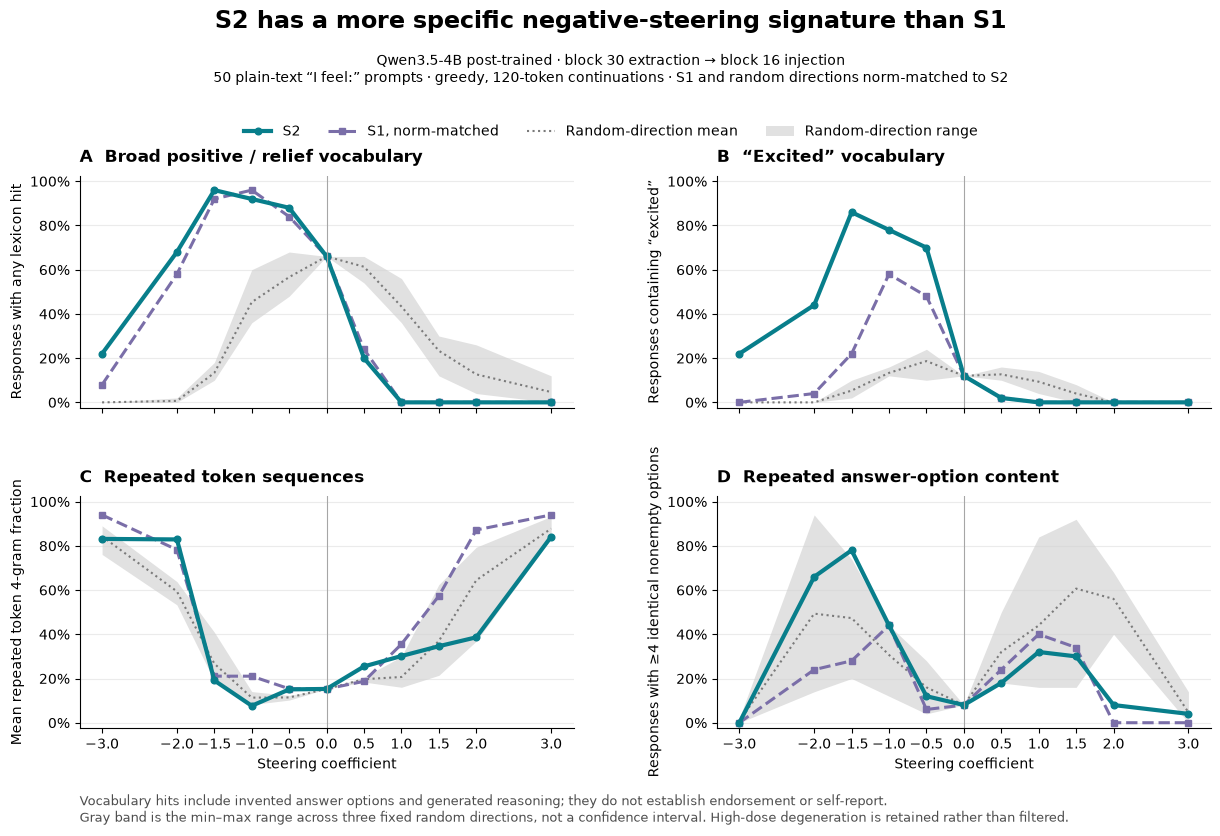


coefficient -1.5
  positive_relief    S2= 96.0%  S1= 92.0%  random= 13.3% [10.0, 18.0]
  excited            S2= 86.0%  S1= 22.0%  random=  5.3% [ 2.0, 10.0]
  repeat4            S2= 19.1%  S1= 21.1%  random= 26.7% [18.9, 40.9]
  repeated_options   S2= 78.0%  S1= 28.0%  random= 47.3% [20.0, 74.0]

coefficient -1.0
  positive_relief    S2= 92.0%  S1= 96.0%  random= 45.3% [36.0, 60.0]
  excited            S2= 78.0%  S1= 58.0%  random= 13.3% [12.0, 16.0]
  repeat4            S2=  7.7%  S1= 21.0%  random= 11.4% [ 8.2, 14.1]
  repeated_options   S2= 44.0%  S1= 44.0%  random= 30.7% [12.0, 44.0]

coefficient -0.5
  positive_relief    S2= 88.0%  S1= 84.0%  random= 56.7% [48.0, 68.0]
  excited            S2= 70.0%  S1= 48.0%  random= 18.7% [10.0, 24.0]
  repeat4            S2= 15.1%  S1= 15.4%  random= 11.4% [10.2, 12.4]
  repeated_options   S2= 12.0%  S1=  6.0%  random= 16.0% [ 4.0, 28.0]


In [2]:
# S1 / S2 specificity figure with equal-norm random-direction controls.
#
# The random band is the min–max range across the three fixed random
# directions, not a confidence interval.

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd

random_names = sorted(
    name for name in comparison_curves["direction"].unique()
    if name.startswith("random_")
)
assert random_names == ["random_1103", "random_2207", "random_3301"]

compare_names = ["S1_matched", "S2"]
metrics = [
    ("positive_relief",
     "A  Broad positive / relief vocabulary",
     "Responses with any lexicon hit"),
    ("excited",
     'B  “Excited” vocabulary',
     'Responses containing “excited”'),
    ("repeat4",
     "C  Repeated token sequences",
     "Mean repeated token 4-gram fraction"),
    ("repeated_options",
     "D  Repeated answer-option content",
     "Responses with ≥4 identical nonempty options"),
]

# One row per direction × coefficient.
plot_frame = comparison_curves.loc[
    comparison_curves["direction"].isin(random_names + compare_names)
].copy()

# Summarize the fixed random-direction bank without pretending n=3 is
# an uncertainty estimate.
random_frame = plot_frame.loc[
    plot_frame["direction"].isin(random_names)
]

random_summary = (
    random_frame.groupby("coeff")[
        [metric for metric, _, _ in metrics]
    ]
    .agg(["min", "mean", "max"])
)

# Save the exact plotted values.
plot_frame.to_csv(
    s1_dir / "s1_s2_random_comparison_plot_data.csv",
    index=False,
)
random_summary.to_csv(
    s1_dir / "s1_s2_random_comparison_random_range.csv"
)

styles = {
    "S1_matched": {
        "color": "#7A6EA8",
        "linestyle": "--",
        "marker": "s",
        "linewidth": 2.2,
        "label": "S1, norm-matched",
    },
    "S2": {
        "color": "#087E8B",
        "linestyle": "-",
        "marker": "o",
        "linewidth": 3.0,
        "label": "S2",
    },
}

coeffs = sorted(plot_frame["coeff"].unique())

with plt.rc_context({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.fonttype": "none",
}):
    fig, axes = plt.subplots(
        2, 2, figsize=(12.5, 8.5), sharex=True
    )

    for ax, (metric, title, ylabel) in zip(axes.flat, metrics):
        rand = random_summary[metric].reset_index()

        # Range across the three fixed equal-norm random directions.
        ax.fill_between(
            rand["coeff"],
            rand["min"],
            rand["max"],
            color="0.82",
            alpha=0.65,
            linewidth=0,
            label="Random-direction range",
        )
        ax.plot(
            rand["coeff"],
            rand["mean"],
            color="0.48",
            linestyle=":",
            linewidth=1.5,
            label="Random-direction mean",
        )

        for name in compare_names:
            sub = (
                plot_frame.loc[plot_frame["direction"].eq(name)]
                .sort_values("coeff")
            )
            ax.plot(
                sub["coeff"],
                sub[metric],
                markersize=4.8,
                **styles[name],
            )

        ax.axvline(0, color="0.65", linewidth=0.8)
        ax.set_xticks(coeffs)
        ax.set_ylim(-0.025, 1.025)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.set_title(title, loc="left", fontweight="bold", pad=10)
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)

    for ax in axes[-1]:
        ax.set_xlabel("Steering coefficient")

    fig.suptitle(
        "S2 has a more specific negative-steering signature than S1",
        fontsize=17,
        fontweight="bold",
        y=0.985,
    )
    fig.text(
        0.5, 0.935,
        "Qwen3.5-4B post-trained · block 30 extraction → block 16 injection\n"
        "50 plain-text “I feel:” prompts · greedy, 120-token continuations · "
        "S1 and random directions norm-matched to S2",
        ha="center",
        va="top",
        fontsize=10,
    )

    # Stable legend order independent of panel draw order.
    handles, legend_labels = axes[0, 0].get_legend_handles_labels()
    wanted = [
        "S2",
        "S1, norm-matched",
        "Random-direction mean",
        "Random-direction range",
    ]
    by_label = dict(zip(legend_labels, handles))
    fig.legend(
        [by_label[label] for label in wanted],
        wanted,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.865),
        ncol=4,
        frameon=False,
    )

    fig.text(
        0.075, 0.025,
        "Vocabulary hits include invented answer options and generated reasoning; "
        "they do not establish endorsement or self-report.\n"
        "Gray band is the min–max range across three fixed random directions, "
        "not a confidence interval. High-dose degeneration is retained rather "
        "than filtered.",
        ha="left",
        va="bottom",
        fontsize=9,
        color="0.3",
    )

    fig.subplots_adjust(
        left=0.075,
        right=0.98,
        bottom=0.14,
        top=0.79,
        hspace=0.38,
        wspace=0.29,
    )

    figure_dir = paper_run_dir / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)

    for ext in ["png", "svg"]:
        fig.savefig(
            figure_dir / f"s1_s2_equal_norm_comparison.{ext}",
            dpi=180,
            bbox_inches="tight",
        )

    plt.show()


# Print the central comparison we're visually relying on.
for coeff in [-1.5, -1.0, -0.5]:
    print(f"\ncoefficient {coeff:+.1f}")

    for metric in ["positive_relief", "excited", "repeat4",
                   "repeated_options"]:
        vals = {}

        for name in compare_names:
            row = plot_frame.loc[
                plot_frame["direction"].eq(name)
                & plot_frame["coeff"].eq(coeff),
                metric,
            ]
            assert len(row) == 1
            vals[name] = float(row.iloc[0])

        rand = random_summary.loc[coeff, metric]

        print(
            f"  {metric:18s} "
            f"S2={vals['S2'] * 100:5.1f}%  "
            f"S1={vals['S1_matched'] * 100:5.1f}%  "
            f"random={rand['mean'] * 100:5.1f}% "
            f"[{rand['min'] * 100:4.1f}, {rand['max'] * 100:4.1f}]"
        )

In [3]:
# Partition vocabulary hits into generated answer-option lines vs everything else.
#
# No new generations. This re-scores the frozen S2/random/S1 ladders.
# It deliberately uses the same option-line syntax as the existing
# repetition diagnostic.

import json
import re
import pandas as pd

main_ladder_path = paper_run_dir / "ladder.jsonl"
negative_path = paper_run_dir / "negative_extension.jsonl"
s1_ladder_path = s1_dir / "ladder.jsonl"

for path in [main_ladder_path, negative_path, s1_ladder_path]:
    assert path.exists(), f"Missing: {path}"


def read_jsonl(path):
    return pd.DataFrame(
        json.loads(line)
        for line in path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    )


# S2 + three random directions.
main = pd.concat(
    [
        read_jsonl(main_ladder_path),
        read_jsonl(negative_path),
    ],
    ignore_index=True,
)

assert not main.duplicated(
    ["prompt_idx", "direction", "coeff"]
).any()

# Equal-norm S1.
s1 = read_jsonl(s1_ladder_path)
assert not s1.duplicated(
    ["prompt_idx", "direction", "coeff"]
).any()

all_generations = pd.concat([main, s1], ignore_index=True)

expected_directions = {
    "S2",
    "S1_matched",
    "random_1103",
    "random_2207",
    "random_3301",
}
assert set(all_generations["direction"]) == expected_directions

# Same option-line definition as the previous repetition audit.
option_line_re = re.compile(
    r"^\s*(?:[-*]\s*)?[A-Z][.)]\s*(.*?)\s*$"
)

positive_relief_re = re.compile(
    r"\b(?:happy|excited|relieved|relief|calm|relaxed|safe|"
    r"secure|content|joy|joyful)\b",
    re.IGNORECASE,
)

excited_re = re.compile(r"\bexcited\b", re.IGNORECASE)


def partition_generated_text(text):
    """
    Split a completion into:
      option_text: content of A./B./C./... answer-option lines
      non_option_text: all remaining generated text

    <think> tags themselves are dropped, but their contents remain in
    non_option_text. This is intentionally conservative: explanatory
    prose discussing an option can still count.
    """
    option_parts = []
    non_option_lines = []

    for line in text.splitlines():
        match = option_line_re.match(line)

        if match:
            option_parts.append(match.group(1))
        elif line.strip() not in {"<think>", "</think>"}:
            non_option_lines.append(line)

    return {
        "option_text": "\n".join(option_parts),
        "non_option_text": "\n".join(non_option_lines),
    }


parts = pd.DataFrame(
    all_generations["text"].map(partition_generated_text).tolist(),
    index=all_generations.index,
)

controlled = pd.concat([all_generations, parts], axis=1)

for scope, column in [
    ("full", "text"),
    ("option", "option_text"),
    ("non_option", "non_option_text"),
]:
    controlled[f"excited_{scope}"] = controlled[column].str.contains(
        excited_re, na=False
    )
    controlled[f"positive_relief_{scope}"] = controlled[column].str.contains(
        positive_relief_re, na=False
    )

# Useful provenance categories.
controlled["excited_option_only"] = (
    controlled["excited_option"]
    & ~controlled["excited_non_option"]
)
controlled["excited_non_option_only"] = (
    controlled["excited_non_option"]
    & ~controlled["excited_option"]
)
controlled["excited_both"] = (
    controlled["excited_option"]
    & controlled["excited_non_option"]
)

metrics = [
    "excited_full",
    "excited_option",
    "excited_non_option",
    "excited_option_only",
    "excited_non_option_only",
    "excited_both",
    "positive_relief_full",
    "positive_relief_option",
    "positive_relief_non_option",
]

partition_curves = (
    controlled
    .groupby(["direction", "coeff"])[metrics]
    .mean()
    .reset_index()
)

controlled.drop(columns=["token_ids"], errors="ignore").to_csv(
    s1_dir / "option_partition_scored_ladder.csv",
    index=False,
)
partition_curves.to_csv(
    s1_dir / "option_partition_metric_means.csv",
    index=False,
)

# The moderate negative region is the important one.
focus_coeffs = [-1.5, -1.0, -0.5]

for metric in [
    "excited_full",
    "excited_option",
    "excited_non_option",
    "positive_relief_full",
    "positive_relief_non_option",
]:
    print(f"\n{metric} (%)")

    table = (
        partition_curves[
            partition_curves["direction"].isin(["S2", "S1_matched"])
            & partition_curves["coeff"].isin(focus_coeffs)
        ]
        .pivot(index="direction", columns="coeff", values=metric)
        .mul(100)
        .round(1)
    )

    print(table.to_string())


# Explicitly show where "excited" hits came from at -1.5.
print("\n'excited' provenance at coefficient -1.5 (%)")

provenance = (
    partition_curves[
        partition_curves["direction"].isin(["S2", "S1_matched"])
        & partition_curves["coeff"].eq(-1.5)
    ]
    .set_index("direction")[
        [
            "excited_full",
            "excited_option_only",
            "excited_non_option_only",
            "excited_both",
        ]
    ]
    .mul(100)
    .round(1)
)

display(provenance)

# Sanity check: show a few S2 -1.5 cases where "excited" occurs outside
# option lines, if such cases exist.
examples = controlled[
    controlled["direction"].eq("S2")
    & controlled["coeff"].eq(-1.5)
    & controlled["excited_non_option"]
][
    ["prompt_idx", "prompt", "option_text", "non_option_text"]
].head(5)

print(
    "\nS2 -1.5 examples with 'excited' outside option lines:",
    len(
        controlled[
            controlled["direction"].eq("S2")
            & controlled["coeff"].eq(-1.5)
            & controlled["excited_non_option"]
        ]
    ),
    "/ 50",
)

display(examples)


excited_full (%)
coeff       -1.5  -1.0  -0.5
direction                   
S1_matched  22.0  58.0  48.0
S2          86.0  78.0  70.0

excited_option (%)
coeff       -1.5  -1.0  -0.5
direction                   
S1_matched  22.0  58.0  48.0
S2          86.0  78.0  70.0

excited_non_option (%)
coeff       -1.5  -1.0  -0.5
direction                   
S1_matched  10.0  14.0  16.0
S2          10.0  26.0  44.0

positive_relief_full (%)
coeff       -1.5  -1.0  -0.5
direction                   
S1_matched  92.0  96.0  84.0
S2          96.0  92.0  88.0

positive_relief_non_option (%)
coeff       -1.5  -1.0  -0.5
direction                   
S1_matched  44.0  28.0  40.0
S2          20.0  26.0  46.0

'excited' provenance at coefficient -1.5 (%)


,excited_full,excited_option_only,excited_non_option_only,excited_both
direction,,,,
S1_matched,22.0,12.0,0.0,10.0
S2,86.0,76.0,0.0,10.0



S2 -1.5 examples with 'excited' outside option lines: 5 / 50


,prompt_idx,prompt,option_text,non_option_text
1733,11,I hang the jacket on the hook. I feel:,excited\nhappy\nexcitedly\nhappily,\n\n\n\nThe sentence describes a feeling relat...
1817,18,The curtain moves in the draft. I feel:,happy\nexcited\nsurprised\nexcited\nhappy,\n\nThe user wants to know the reaction to the...
2021,35,I tie my shoelaces before going out. I feel:,happy\nexcited\nsafe\nhappy and excited\nhappy...,"\n\n\n\nAs the traffic gets heavier, I feel:\n..."
2129,44,The window cleaner works across the street. I ...,happy\nexcited\nworried\nexcited\nhappy\nexcit...,\n\n\n\nThe window cleaner works across the st...
2189,49,The ticket is valid for ninety minutes. I feel:,excited\nhappy\nexcitedly\nhappily,"\n\n\n\nThe sentence uses the structure ""feel ..."


In [4]:
# Paired bootstrap for the option-controlled S2 vs S1 "excited" effect.
#
# Resample prompt IDs, preserving the S1/S2 pairing.
# Primary quantity:
#   mean(excited_non_option_S2 - excited_non_option_S1)

import numpy as np
import pandas as pd

rng = np.random.default_rng(20260925)
n_boot = 20_000

paired_rows = []

for coeff in [-1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5]:
    sub = controlled[
        controlled["direction"].isin(["S2", "S1_matched"])
        & controlled["coeff"].eq(coeff)
    ][
        ["prompt_idx", "direction", "excited_non_option"]
    ]

    wide = sub.pivot(
        index="prompt_idx",
        columns="direction",
        values="excited_non_option",
    ).sort_index()

    wide = wide.dropna()

    assert len(wide) == 50
    assert set(wide.columns) == {"S1_matched", "S2"}

    diffs = (
        wide["S2"].astype(float).to_numpy()
        - wide["S1_matched"].astype(float).to_numpy()
    )

    observed = diffs.mean()

    boot_idx = rng.integers(
        0,
        len(diffs),
        size=(n_boot, len(diffs)),
    )
    boot = diffs[boot_idx].mean(axis=1)

    lo, hi = np.quantile(boot, [0.025, 0.975])

    # Pair-level discordances are useful to see directly:
    # S2 hit / S1 miss versus S1 hit / S2 miss.
    s2_only = int(
        (
            wide["S2"].astype(bool)
            & ~wide["S1_matched"].astype(bool)
        ).sum()
    )
    s1_only = int(
        (
            wide["S1_matched"].astype(bool)
            & ~wide["S2"].astype(bool)
        ).sum()
    )

    paired_rows.append({
        "coeff": coeff,
        "s2_rate": wide["S2"].mean(),
        "s1_rate": wide["S1_matched"].mean(),
        "paired_gap": observed,
        "ci95_lo": lo,
        "ci95_hi": hi,
        "s2_only_prompts": s2_only,
        "s1_only_prompts": s1_only,
    })

paired_excited = pd.DataFrame(paired_rows)

paired_excited.to_csv(
    s1_dir / "excited_non_option_paired_bootstrap.csv",
    index=False,
)

display(
    paired_excited.style.format({
        "s2_rate": "{:.1%}",
        "s1_rate": "{:.1%}",
        "paired_gap": "{:+.1%}",
        "ci95_lo": "{:+.1%}",
        "ci95_hi": "{:+.1%}",
    })
)

,coeff,s2_rate,s1_rate,paired_gap,ci95_lo,ci95_hi,s2_only_prompts,s1_only_prompts
0,-1.500000,10.0%,10.0%,+0.0%,-12.0%,+12.0%,5,5
1,-1.000000,26.0%,14.0%,+12.0%,-2.0%,+26.0%,10,4
2,-0.500000,44.0%,16.0%,+28.0%,+12.0%,+44.0%,17,3
3,0.000000,10.0%,10.0%,+0.0%,+0.0%,+0.0%,0,0
4,0.500000,2.0%,2.0%,+0.0%,+0.0%,+0.0%,0,0
5,1.000000,0.0%,0.0%,+0.0%,+0.0%,+0.0%,0,0
6,1.500000,0.0%,0.0%,+0.0%,+0.0%,+0.0%,0,0


In [5]:
# Frozen psych-informed vocabulary panel.
#
# Exploratory / hypothesis-generating only.
# Define once, save the exact specification, then score without editing
# in response to the results.
#
# Families are intentionally small and mostly non-overlapping.
# We score response-level presence, not frequency.

import json
import re
from pathlib import Path

import numpy as np
import pandas as pd


# ---------------------------------------------------------------------
# 1. Freeze the conceptual vocabulary
# ---------------------------------------------------------------------

PSYCH_VOCAB = {
    # Generic pleasant affect: useful as a boring positive control.
    "generic_positive": [
        "happy",
        "glad",
        "joy",
        "joyful",
        "delighted",
        "pleased",
    ],

    # PANAS-ish activated positive affect / subjective-vitality neighborhood.
    "activated_vitality": [
        "excited",
        "eager",
        "enthusiastic",
        "energized",
        "energetic",
        "lively",
        "animated",
        "spirited",
        "invigorated",
        "exhilarated",
    ],

    # BAS / approach-ish pursuit and readiness.
    "approach_drive": [
        "motivated",
        "driven",
        "determined",
        "ambitious",
        "purposeful",
        "committed",
        "ready",
    ],

    # Interpersonal-agency / self-assurance neighborhood.
    "agency_assurance": [
        "confident",
        "assured",
        "self-assured",
        "assertive",
        "bold",
        "empowered",
        "powerful",
        "in control",
    ],

    # Deliberately separate competence from agency.
    "competence_success": [
        "competent",
        "capable",
        "successful",
        "accomplished",
        "effective",
        "skilled",
        "proficient",
        "mastered",
    ],

    # Pleasant but relatively low activation.
    "calm_positive": [
        "calm",
        "relaxed",
        "content",
        "peaceful",
        "serene",
        "safe",
        "secure",
        "at ease",
    ],

    # Ending / release of an aversive state.
    "relief_release": [
        "relieved",
        "relief",
        "reassured",
        "freed",
        "eased",
        "unburdened",
    ],

    # Reduced agency / approach.
    "inhibition_defeat": [
        "defeated",
        "helpless",
        "powerless",
        "discouraged",
        "hesitant",
        "withdrawn",
        "demoralized",
        "resigned",
        "self-doubting",
    ],

    # The self-evaluative / distress neighborhood we have already noticed.
    "distress_self_devaluation": [
        "ashamed",
        "worthless",
        "rejected",
        "humiliated",
        "miserable",
        "failure",
        "despair",
        "hopeless",
        "guilty",
        "useless",
        "inadequate",
        "not good enough",
    ],
}

vocab_spec = {
    "name": "psych_informed_vocab_v1",
    "status": "exploratory_frozen_before_scoring",
    "families": PSYCH_VOCAB,
    "scopes": ["full", "option", "non_option"],
    "primary_view": "non_option",
    "notes": [
        "Response-level lexical presence only.",
        "Generated answer-option lines are scored separately.",
        "Families are conceptual probes, not labels for the S2 direction.",
        "No family will be edited in response to this run's results.",
    ],
}

spec_path = s1_dir / "psych_vocab_v1.json"

if spec_path.exists():
    old_spec = json.loads(spec_path.read_text())
    assert old_spec == vocab_spec, (
        "psych_vocab_v1.json already exists with a different definition. "
        "Bump the version rather than silently editing the frozen panel."
    )
else:
    spec_path.write_text(
        json.dumps(vocab_spec, indent=2, ensure_ascii=False) + "\n",
        encoding="utf-8",
    )

print("Frozen vocabulary spec:", spec_path)


# ---------------------------------------------------------------------
# 2. Compile conservative whole-word / whole-phrase matchers
# ---------------------------------------------------------------------

def phrase_pattern(phrase):
    """
    Whole-word-ish matching for words and short phrases.
    Hyphens/spaces in the lexicon tolerate either whitespace or hyphens.
    """
    pieces = re.split(r"[\s-]+", phrase.strip())
    body = r"[\s-]+".join(re.escape(piece) for piece in pieces)

    return re.compile(
        rf"(?<!\w){body}(?!\w)",
        re.IGNORECASE,
    )


FAMILY_PATTERNS = {
    family: [phrase_pattern(term) for term in terms]
    for family, terms in PSYCH_VOCAB.items()
}


def family_hit(text, family):
    text = "" if pd.isna(text) else str(text)
    return any(
        pattern.search(text)
        for pattern in FAMILY_PATTERNS[family]
    )


def matched_terms(text, family):
    """
    Diagnostic only: return the frozen lexicon terms that occurred.
    """
    text = "" if pd.isna(text) else str(text)

    hits = []
    for term, pattern in zip(
        PSYCH_VOCAB[family],
        FAMILY_PATTERNS[family],
    ):
        if pattern.search(text):
            hits.append(term)

    return hits


# ---------------------------------------------------------------------
# 3. Score full / option / non-option text
# ---------------------------------------------------------------------

psych_scored = controlled.copy()

scope_columns = {
    "full": "text",
    "option": "option_text",
    "non_option": "non_option_text",
}

for scope, text_col in scope_columns.items():
    for family in PSYCH_VOCAB:
        psych_scored[f"{family}__{scope}"] = psych_scored[text_col].map(
            lambda text, f=family: family_hit(text, f)
        )

# Save row-level scores.
psych_scored.drop(
    columns=["token_ids"],
    errors="ignore",
).to_csv(
    s1_dir / "psych_vocab_v1_scored_responses.csv",
    index=False,
)


# ---------------------------------------------------------------------
# 4. Aggregate response-level hit rates
# ---------------------------------------------------------------------

score_columns = [
    f"{family}__{scope}"
    for family in PSYCH_VOCAB
    for scope in scope_columns
]

psych_curves = (
    psych_scored
    .groupby(["direction", "coeff"])[score_columns]
    .mean()
    .reset_index()
)

psych_curves.to_csv(
    s1_dir / "psych_vocab_v1_metric_means.csv",
    index=False,
)


# ---------------------------------------------------------------------
# 5. Paired S2 - S1 bootstrap for the PRIMARY non-option view
# ---------------------------------------------------------------------

rng = np.random.default_rng(20260925)
n_boot = 20_000

paired_rows = []

for family in PSYCH_VOCAB:
    metric = f"{family}__non_option"

    for coeff in sorted(psych_scored["coeff"].unique()):
        sub = psych_scored[
            psych_scored["direction"].isin(["S2", "S1_matched"])
            & psych_scored["coeff"].eq(coeff)
        ][
            ["prompt_idx", "direction", metric]
        ]

        wide = (
            sub.pivot(
                index="prompt_idx",
                columns="direction",
                values=metric,
            )
            .dropna()
            .sort_index()
        )

        assert len(wide) == 50

        s2 = wide["S2"].astype(float).to_numpy()
        s1 = wide["S1_matched"].astype(float).to_numpy()
        diffs = s2 - s1

        boot_idx = rng.integers(
            0,
            len(diffs),
            size=(n_boot, len(diffs)),
        )
        boot = diffs[boot_idx].mean(axis=1)

        lo, hi = np.quantile(boot, [0.025, 0.975])

        paired_rows.append({
            "family": family,
            "coeff": coeff,
            "s2_rate": s2.mean(),
            "s1_rate": s1.mean(),
            "paired_gap": diffs.mean(),
            "ci95_lo": lo,
            "ci95_hi": hi,
            "s2_only_prompts": int(((s2 == 1) & (s1 == 0)).sum()),
            "s1_only_prompts": int(((s2 == 0) & (s1 == 1)).sum()),
        })

psych_paired = pd.DataFrame(paired_rows)

psych_paired.to_csv(
    s1_dir / "psych_vocab_v1_paired_bootstrap.csv",
    index=False,
)


# ---------------------------------------------------------------------
# 6. First view: non-option family rates at moderate negative steering
# ---------------------------------------------------------------------

focus_coeffs = [-1.5, -1.0, -0.5]

focus = psych_paired[
    psych_paired["coeff"].isin(focus_coeffs)
].copy()

for coeff in focus_coeffs:
    print(f"\n{'=' * 72}")
    print(f"NON-OPTION VOCABULARY — coefficient {coeff:+.1f}")
    print(f"{'=' * 72}")

    table = (
        focus[focus["coeff"].eq(coeff)]
        .set_index("family")[
            [
                "s2_rate",
                "s1_rate",
                "paired_gap",
                "ci95_lo",
                "ci95_hi",
                "s2_only_prompts",
                "s1_only_prompts",
            ]
        ]
        .sort_values("paired_gap", ascending=False)
    )

    display(
        table.style.format({
            "s2_rate": "{:.0%}",
            "s1_rate": "{:.0%}",
            "paired_gap": "{:+.0%}",
            "ci95_lo": "{:+.0%}",
            "ci95_hi": "{:+.0%}",
        })
    )


# ---------------------------------------------------------------------
# 7. Also show the random-direction neighborhood at -0.5
# ---------------------------------------------------------------------

random_names = [
    "random_1103",
    "random_2207",
    "random_3301",
]

rows = []

for family in PSYCH_VOCAB:
    metric = f"{family}__non_option"

    for direction in ["S2", "S1_matched"] + random_names:
        row = psych_curves[
            psych_curves["direction"].eq(direction)
            & psych_curves["coeff"].eq(-0.5)
        ]

        assert len(row) == 1

        rows.append({
            "family": family,
            "direction": direction,
            "rate": float(row.iloc[0][metric]),
        })

random_view = pd.DataFrame(rows)

random_table = (
    random_view
    .pivot(index="family", columns="direction", values="rate")
)

random_table["random_mean"] = random_table[random_names].mean(axis=1)
random_table["random_min"] = random_table[random_names].min(axis=1)
random_table["random_max"] = random_table[random_names].max(axis=1)

print("\n" + "=" * 72)
print("NON-OPTION VOCABULARY — coefficient -0.5, including random controls")
print("=" * 72)

display(
    random_table[
        [
            "S2",
            "S1_matched",
            "random_mean",
            "random_min",
            "random_max",
        ]
    ]
    .sort_values("S2", ascending=False)
    .style.format("{:.0%}")
)


# ---------------------------------------------------------------------
# 8. Diagnostic: what actual words generated each family's S2 -0.5 hits?
# ---------------------------------------------------------------------

diagnostic_rows = []

s2_focus = psych_scored[
    psych_scored["direction"].eq("S2")
    & psych_scored["coeff"].eq(-0.5)
]

for family in PSYCH_VOCAB:
    term_counts = {}

    for text in s2_focus["non_option_text"]:
        for term in matched_terms(text, family):
            term_counts[term] = term_counts.get(term, 0) + 1

    diagnostic_rows.extend(
        {
            "family": family,
            "term": term,
            "responses_with_term": count,
        }
        for term, count in sorted(
            term_counts.items(),
            key=lambda kv: (-kv[1], kv[0]),
        )
    )

term_diagnostics = pd.DataFrame(diagnostic_rows)

term_diagnostics.to_csv(
    s1_dir / "psych_vocab_v1_s2_minus05_term_counts.csv",
    index=False,
)

print("\nS2 -0.5 actual non-option lexical hits:")
display(term_diagnostics)

Frozen vocabulary spec: runs/qwen35-4b-posttrained-s2/paper_protocol/s1_comparison/psych_vocab_v1.json

NON-OPTION VOCABULARY — coefficient -1.5


,s2_rate,s1_rate,paired_gap,ci95_lo,ci95_hi,s2_only_prompts,s1_only_prompts
family,,,,,,,
relief_release,10%,2%,+8%,+2%,+16%,4,0
approach_drive,2%,0%,+2%,+0%,+6%,1,0
competence_success,0%,0%,+0%,+0%,+0%,0,0
agency_assurance,0%,0%,+0%,+0%,+0%,0,0
activated_vitality,10%,10%,+0%,-12%,+12%,5,5
distress_self_devaluation,0%,0%,+0%,+0%,+0%,0,0
inhibition_defeat,0%,0%,+0%,+0%,+0%,0,0
calm_positive,4%,8%,-4%,-12%,+4%,1,3
generic_positive,6%,50%,-44%,-58%,-30%,1,23



NON-OPTION VOCABULARY — coefficient -1.0


,s2_rate,s1_rate,paired_gap,ci95_lo,ci95_hi,s2_only_prompts,s1_only_prompts
family,,,,,,,
activated_vitality,26%,14%,+12%,-2%,+26%,10,4
relief_release,12%,4%,+8%,+0%,+18%,5,1
calm_positive,6%,2%,+4%,-4%,+12%,3,1
approach_drive,2%,0%,+2%,+0%,+6%,1,0
competence_success,0%,0%,+0%,+0%,+0%,0,0
inhibition_defeat,0%,0%,+0%,+0%,+0%,0,0
agency_assurance,0%,0%,+0%,+0%,+0%,0,0
distress_self_devaluation,0%,0%,+0%,+0%,+0%,0,0
generic_positive,20%,30%,-10%,-24%,+4%,4,9



NON-OPTION VOCABULARY — coefficient -0.5


,s2_rate,s1_rate,paired_gap,ci95_lo,ci95_hi,s2_only_prompts,s1_only_prompts
family,,,,,,,
activated_vitality,44%,16%,+28%,+12%,+44%,17,3
relief_release,6%,2%,+4%,-4%,+12%,3,1
calm_positive,14%,12%,+2%,-8%,+12%,4,3
generic_positive,36%,36%,+0%,-18%,+18%,10,10
approach_drive,2%,2%,+0%,+0%,+0%,0,0
inhibition_defeat,0%,0%,+0%,+0%,+0%,0,0
competence_success,0%,0%,+0%,+0%,+0%,0,0
distress_self_devaluation,0%,0%,+0%,+0%,+0%,0,0
agency_assurance,0%,2%,-2%,-6%,+0%,0,1



NON-OPTION VOCABULARY — coefficient -0.5, including random controls


direction,S2,S1_matched,random_mean,random_min,random_max
family,,,,,
activated_vitality,44%,16%,13%,6%,20%
generic_positive,36%,36%,25%,16%,34%
calm_positive,14%,12%,13%,10%,14%
relief_release,6%,2%,6%,4%,8%
approach_drive,2%,2%,3%,2%,4%
competence_success,0%,0%,0%,0%,0%
agency_assurance,0%,2%,1%,0%,2%
distress_self_devaluation,0%,0%,3%,2%,4%
inhibition_defeat,0%,0%,0%,0%,0%



S2 -0.5 actual non-option lexical hits:


,family,term,responses_with_term
0,generic_positive,happy,18
1,activated_vitality,excited,22
2,approach_drive,ready,1
3,calm_positive,calm,4
4,calm_positive,safe,3
5,relief_release,relieved,3


## Psych-informed vocabulary probe — frozen exploratory result

Before moving to R/J-Lens readouts, we froze a small psychology-informed vocabulary panel to test whether the apparent `excited` effect belonged to a broader semantic family.

The panel separated:

- generic positive affect;
- activated vitality;
- approach / drive;
- agency / self-assurance;
- competence / success;
- calm positive affect;
- relief / release;
- inhibition / defeat;
- distress / self-devaluation.

The vocabulary definition was frozen as:

```text
runs/qwen35-4b-posttrained-s2/paper_protocol/s1_comparison/psych_vocab_v1.json
```

and scored separately on:

```text
full generated text
generated answer-option lines
non-option generated text
```

### Main observation

At moderate negative steering (`alpha = -0.5`), S2 produced substantially more **non-option `excited` vocabulary** than norm-matched S1:

```text
S2          44%
S1          16%
paired gap  +28 pp
bootstrap   [+12, +44] pp
discordant  17 S2-only vs 3 S1-only prompts
```

The three fixed random directions were lower:

```text
random mean   13%
random range   6–20%
```

However, the apparent broader `activated_vitality` family did **not** generalize beyond `excited`.

At `alpha = -0.5`, actual S2 non-option lexical hits were:

```text
excited   22 / 50
happy     18 / 50
calm       4 / 50
safe       3 / 50
relieved   3 / 50
ready      1 / 50
```

No other frozen vitality terms (`eager`, `enthusiastic`, `energized`, `spirited`, etc.) appeared.

Likewise, S2 showed no corresponding increase in:

```text
generic positive       S2 36%  vs S1 36%
calm positive          S2 14%  vs S1 12%
approach / drive       S2  2%  vs S1  2%
competence / success   S2  0%  vs S1  0%
agency / assurance     S2  0%  vs S1  2%
```

### Strong-steering confound

The much larger full-text `excited` effect at `alpha = -1.5` was largely explained by a generated multiple-choice / answer-option attractor.

After removing option lines:

```text
alpha = -1.5

S2 excited   10%
S1 excited   10%
```

So the high-dose result should not be interpreted as a clean semantic effect.

### Current interpretation

The narrow exploratory observation is therefore:

> Moderate negative S2 steering preferentially produces `excited` language relative to norm-matched S1 and the fixed random-direction bank, while broader positive, competence, agency, approach, and vitality vocabularies do not show the same separation.

This does **not** justify renaming the S2 direction or interpreting it as a general vitality, agency, eagerness, or approach representation.

The result is exploratory, on one small model and one 50-prompt assay.

### Next question

Freeze `psych_vocab_v1` here.

The next experiment is layerwise R/J-Lens inspection, using the frozen vocabulary panel to ask:

> Is `excited` internally accompanied by a broader semantic neighborhood that fails to reach generation, or is `excited` itself an unusually privileged lexical attractor?

No vocabulary terms should be added or removed in response to the lens results; any later vocabulary revision should become a separately versioned panel.

frozen commit:  fdfaf2c..42202af  

In [1]:
# Local-only R/J lens setup.
#
# Expected sibling layout:
#
#   euphoria-axis/
#   jacobian-lens/
#   workspace-lenses/
#
# No network access required for lens code or lens weights.

from pathlib import Path
import subprocess
import sys
import json

import torch
import transformers


# ---------------------------------------------------------------------
# Locate local repos
# ---------------------------------------------------------------------

HERE = Path.cwd().resolve()

def find_sibling(name):
    candidates = [
        HERE / name,
        HERE.parent / name,
        HERE.parent.parent / name,
    ]
    for p in candidates:
        if p.exists():
            return p.resolve()
    raise FileNotFoundError(
        f"Could not find {name!r}. Tried:\n"
        + "\n".join(f"  {p}" for p in candidates)
    )

JLENS_REPO = find_sibling("jacobian-lens")
WORKSPACE_LENSES_REPO = find_sibling("workspace-lenses")

print("jacobian-lens:   ", JLENS_REPO)
print("workspace-lenses:", WORKSPACE_LENSES_REPO)


# Import the local jlens checkout directly.
sys.path.insert(0, str(JLENS_REPO))

import jlens


def git_head(path):
    return subprocess.check_output(
        ["git", "-C", str(path), "rev-parse", "HEAD"],
        text=True,
    ).strip()


jlens_commit = git_head(JLENS_REPO)
workspace_lenses_commit = git_head(WORKSPACE_LENSES_REPO)

print("jlens commit:           ", jlens_commit)
print("workspace-lenses commit:", workspace_lenses_commit)


# ---------------------------------------------------------------------
# Frozen euphoria-axis experiment state
# ---------------------------------------------------------------------

MODEL_NAME = "Qwen/Qwen3.5-4B"

paper_run_dir = Path(
    "runs/qwen35-4b-posttrained-s2/paper_protocol"
)
s1_dir = paper_run_dir / "s1_comparison"
lens_dir = paper_run_dir / "lens_readout"
lens_dir.mkdir(parents=True, exist_ok=True)

paper_spec = json.loads(
    (paper_run_dir / "spec.json").read_text()
)

assert paper_spec["model"] == MODEL_NAME
assert paper_spec["injection_block"] == 16
assert paper_spec["prompt_format"] == "plain text; no chat template"


# ---------------------------------------------------------------------
# Local lens files
# ---------------------------------------------------------------------

J_PATH = (
    WORKSPACE_LENSES_REPO
    / "qwen3.5-4b"
    / "j-lens"
    / "lens.pt"
)

R_PATH = (
    WORKSPACE_LENSES_REPO
    / "qwen3.5-4b"
    / "r-lens"
    / "lens.pt"
)

assert J_PATH.exists(), J_PATH
assert R_PATH.exists(), R_PATH

print("J lens:", J_PATH)
print("R lens:", R_PATH)


# ---------------------------------------------------------------------
# Load model from the existing HF cache
# ---------------------------------------------------------------------

hf = transformers.AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.bfloat16,
    local_files_only=True,
).cuda().eval()

tok = transformers.AutoTokenizer.from_pretrained(
    MODEL_NAME,
    local_files_only=True,
)

# Preserve our existing plain-text protocol.
# jlens otherwise defaults to force_bos=True.
lens_model = jlens.from_hf(
    hf,
    tok,
    force_bos=False,
)


# ---------------------------------------------------------------------
# Load local J/R lenses
# ---------------------------------------------------------------------

j_lens = jlens.JacobianLens.load(str(J_PATH))
r_lens = jlens.JacobianLens.load(str(R_PATH))

assert j_lens.source_layers == r_lens.source_layers
assert j_lens.source_layers == list(range(31))
assert j_lens.d_model == r_lens.d_model
assert j_lens.d_model == hf.config.hidden_size

print(j_lens)
print(r_lens)


# ---------------------------------------------------------------------
# Frozen steering vectors
# ---------------------------------------------------------------------

paper_vectors = torch.load(
    paper_run_dir / "steering_vectors.pt",
    map_location="cpu",
    weights_only=True,
)

s1_blob = torch.load(
    s1_dir / "s1_direction_block30.pt",
    map_location="cpu",
    weights_only=True,
)

s2_vector = paper_vectors["S2"].float()
s1_vector = s1_blob["matched_vector"].float()

assert torch.isfinite(s1_vector).all()
assert torch.isfinite(s2_vector).all()

print("S2 norm:", s2_vector.norm().item())
print("S1 norm:", s1_vector.norm().item())

assert torch.allclose(
    s1_vector.norm(),
    s2_vector.norm(),
    atol=1e-4,
)

decoder_layers = list(lens_model.layers)
assert len(decoder_layers) == 32


# ---------------------------------------------------------------------
# Freeze lens-readout provenance
# ---------------------------------------------------------------------

setup_spec = {
    "model": MODEL_NAME,
    "jacobian_lens_repo": str(JLENS_REPO),
    "jacobian_lens_commit": jlens_commit,
    "workspace_lenses_repo": str(WORKSPACE_LENSES_REPO),
    "workspace_lenses_commit": workspace_lenses_commit,
    "lens_files": {
        "J": str(J_PATH),
        "R": str(R_PATH),
    },
    "lens_source_layers": j_lens.source_layers,
    "lens_target_layer": 30,
    "prompt_format": "plain text; no chat template",
    "force_bos": False,
    "measurement_position": "final prefix token",
    "injection_block": paper_spec["injection_block"],
    "initial_conditions": [
        {
            "name": "baseline",
            "direction": None,
            "coeff": 0.0,
        },
        {
            "name": "S1_-0.5",
            "direction": "S1_matched",
            "coeff": -0.5,
        },
        {
            "name": "S2_-0.5",
            "direction": "S2",
            "coeff": -0.5,
        },
    ],
}

setup_path = lens_dir / "setup_spec.json"
setup_text = json.dumps(setup_spec, indent=2) + "\n"

if setup_path.exists():
    old = json.loads(setup_path.read_text())

    # Don't silently mutate an already-frozen setup.
    assert old == setup_spec, (
        f"{setup_path} already exists with different provenance."
    )
else:
    setup_path.write_text(setup_text)

print("\nReady.")
print("Saved provenance:", setup_path)

/mnt/c/Users/bfabe/workspace/bookspace/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


jacobian-lens:    /mnt/c/Users/bfabe/workspace/jacobian-lens
workspace-lenses: /mnt/c/Users/bfabe/workspace/workspace-lenses
jlens commit:            581d398613e5602a5af361e1c34d3a92ea82ba8e
workspace-lenses commit: d740106d1e0f95456dc8718fba2895e9c8ffd6ef
J lens: /mnt/c/Users/bfabe/workspace/workspace-lenses/qwen3.5-4b/j-lens/lens.pt
R lens: /mnt/c/Users/bfabe/workspace/workspace-lenses/qwen3.5-4b/r-lens/lens.pt


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|█████████████████████████████████████████████████████████████| 426/426 [00:00<00:00, 1912.59it/s]


JacobianLens(d_model=2560, n_prompts=25, source_layers=[0..30] (31 layers))
JacobianLens(d_model=2560, n_prompts=25, source_layers=[0..30] (31 layers))
S2 norm: 6.24392032623291
S1 norm: 6.243920803070068

Ready.
Saved provenance: runs/qwen35-4b-posttrained-s2/paper_protocol/lens_readout/setup_spec.json


In [2]:
# One-prompt pre-generation R/J smoke.
#
# Conditions:
#   baseline
#   norm-matched S1 @ -0.5
#   S2 @ -0.5
#
# Readout:
#   final token of "I put the receipts in the drawer. I feel:"
#
# Uses the already-frozen psych_vocab_v1.

from contextlib import contextmanager

import pandas as pd
import torch

from jlens.hooks import ActivationRecorder


# ---------------------------------------------------------------------
# Frozen vocabulary -> single-token continuation probes
# ---------------------------------------------------------------------

psych_spec = json.loads(
    (s1_dir / "psych_vocab_v1.json").read_text()
)
psych_vocab = psych_spec["families"]

probe_terms = []

for family, terms in psych_vocab.items():
    for term in terms:
        # At "I feel:" the natural continuation form normally begins
        # with a space. Keep only probes represented by one token.
        ids = tok.encode(" " + term, add_special_tokens=False)

        if len(ids) == 1:
            probe_terms.append({
                "family": family,
                "term": term,
                "token_id": ids[0],
                "decoded": tok.decode([ids[0]]),
            })

probe_terms = pd.DataFrame(probe_terms)

print(
    f"{len(probe_terms)} / "
    f"{sum(len(v) for v in psych_vocab.values())} "
    "frozen terms are single-token continuation probes."
)

display(probe_terms)


# ---------------------------------------------------------------------
# Steering hook
# ---------------------------------------------------------------------

@contextmanager
def prefix_steering(coeff, vector):
    if vector is None or coeff == 0:
        yield
        return

    model_device = next(hf.parameters()).device
    delta = vector.to(
        device=model_device,
        dtype=torch.bfloat16,
    )

    def hook(module, inputs, output):
        if isinstance(output, tuple):
            return (
                output[0] + coeff * delta,
                *output[1:],
            )
        return output + coeff * delta

    handle = decoder_layers[
        paper_spec["injection_block"]
    ].register_forward_hook(hook)

    try:
        yield
    finally:
        handle.remove()


# ---------------------------------------------------------------------
# Capture frozen prefix residuals
# ---------------------------------------------------------------------

prompt = paper_spec["prompts"][0]

probe_layers = [
    0, 4, 8, 12,
    16, 20, 24, 28, 30,
]

conditions = {
    "baseline": (0.0, None),
    "S1_-0.5": (-0.5, s1_vector),
    "S2_-0.5": (-0.5, s2_vector),
}


@torch.no_grad()
def capture_prefix(text, coeff=0.0, vector=None):
    input_ids = lens_model.encode(text)

    # Steering hook registered before recorder:
    # layer-16 recorder therefore sees post-intervention state.
    with prefix_steering(coeff, vector):
        with ActivationRecorder(
            lens_model.layers,
            at=probe_layers,
        ) as recorder:
            lens_model.forward(input_ids)

    states = {
        layer: (
            recorder.activations[layer][0, -1, :]
            .detach()
            .float()
        )
        for layer in probe_layers
    }

    return input_ids.cpu(), states


def readout(lens, state, layer):
    transported = lens.transport(state, layer)
    return (
        lens_model
        .unembed(transported)
        .float()
        .cpu()
    )


def token_rank(logits, token_id):
    """
    1-indexed rank without sorting the full vocabulary.
    """
    target = logits[token_id]
    return int((logits > target).sum()) + 1


def token_topk(logits, k=15):
    values, ids = logits.topk(k)

    return [
        {
            "rank": rank,
            "token_id": int(token_id),
            "token": tok.decode([int(token_id)]),
            "logit": float(value),
        }
        for rank, (token_id, value) in enumerate(
            zip(ids, values),
            start=1,
        )
    ]


# ---------------------------------------------------------------------
# Run
# ---------------------------------------------------------------------

rank_rows = []
topk_rows = []

for condition, (coeff, vector) in conditions.items():
    input_ids, states = capture_prefix(
        prompt,
        coeff,
        vector,
    )

    print("\n" + "=" * 88)
    print(condition)
    print(repr(prompt))
    print(
        "final input token:",
        repr(tok.decode([input_ids[0, -1].item()])),
    )
    print("=" * 88)

    for layer in probe_layers:
        for lens_name, lens in [
            ("J", j_lens),
            ("R", r_lens),
        ]:
            logits = readout(
                lens,
                states[layer],
                layer,
            )

            # Frozen psych-vocabulary ranks.
            for row in probe_terms.itertuples():
                rank_rows.append({
                    "condition": condition,
                    "coeff": coeff,
                    "layer": layer,
                    "lens": lens_name,
                    "family": row.family,
                    "term": row.term,
                    "token_id": row.token_id,
                    "rank": token_rank(
                        logits,
                        row.token_id,
                    ),
                    "logit": float(
                        logits[row.token_id]
                    ),
                })

            # Unfiltered top-k: fun now, clouds later.
            for item in token_topk(logits, k=15):
                topk_rows.append({
                    "condition": condition,
                    "coeff": coeff,
                    "layer": layer,
                    "lens": lens_name,
                    **item,
                })

        # Human-readable little peek.
        j_logits = readout(
            j_lens,
            states[layer],
            layer,
        )
        r_logits = readout(
            r_lens,
            states[layer],
            layer,
        )

        print(f"\nL{layer:02d}")
        print(
            " J:",
            [repr(x["token"])
             for x in token_topk(j_logits, 10)]
        )
        print(
            " R:",
            [repr(x["token"])
             for x in token_topk(r_logits, 10)]
        )


lens_smoke_ranks = pd.DataFrame(rank_rows)
lens_smoke_topk = pd.DataFrame(topk_rows)

lens_smoke_ranks.to_csv(
    lens_dir / "smoke_psych_vocab_ranks.csv",
    index=False,
)

lens_smoke_topk.to_csv(
    lens_dir / "smoke_topk.csv",
    index=False,
)


# ---------------------------------------------------------------------
# Compact view of our suspicious little friend, "excited"
# ---------------------------------------------------------------------

excited_view = (
    lens_smoke_ranks[
        lens_smoke_ranks["term"].eq("excited")
    ]
    .pivot_table(
        index=["layer", "lens"],
        columns="condition",
        values="rank",
    )
)

print("\n'excited' rank at final prefix position:")
display(excited_view)


# And inspect the full frozen family around it.
vitality_view = (
    lens_smoke_ranks[
        lens_smoke_ranks["family"].eq(
            "activated_vitality"
        )
    ]
    .query("condition == 'S2_-0.5'")
    .pivot(
        index="term",
        columns=["lens", "layer"],
        values="rank",
    )
)

print("\nS2 -0.5 activated-vitality ranks:")
display(vitality_view)

60 / 74 frozen terms are single-token continuation probes.


,family,term,token_id,decoded
0,generic_positive,happy,6051,happy
1,generic_positive,glad,15252,glad
2,generic_positive,joy,15420,joy
3,generic_positive,joyful,79278,joyful
4,generic_positive,delighted,32847,delighted
5,generic_positive,pleased,17892,pleased
6,activated_vitality,excited,11692,excited
7,activated_vitality,eager,22806,eager
8,activated_vitality,enthusiastic,40227,enthusiastic
9,activated_vitality,energetic,43361,energetic



baseline
'I put the receipts in the drawer. I feel:'
final input token: ':'

L00
 J: ['\' "\'', '\' "...\'', "'ation'", "'amiento'", '\' ("\'', '\'—"\'', "'通则'", '\':"\'', "'десят'", "'empa'"]
 R: ["'–and'", "' somew'", "' […'", "' spok'", "' amator'", "' \\xad'", "'にあた'", "' _______,'", "' (…)'", "' handl'"]

L04
 J: ["' flavours'", "'avour'", "'́'", "' flavour'", "'Organisation'", "' Organisation'", "' organised'", "' всё'", "' bỏ'", "' harbour'"]
 R: ["'!:'", "' flavours'", "' -:'", "' ;-)'", "'?:'", "' EITHER'", "' (...)'", "'非常丰富'", "' flavour'", "'__:'"]

L08
 J: ["'zsche'", "'?:'", "'怎样的'", "':'", "'avour'", "'ting'", "'\\n'", "' :'", "'翔'", "'!:'"]
 R: ["'?:'", "'!:'", "' NOT'", "'/do'", "'怎样的'", "' :-'", "' Mondays'", "' embar'", "' very'", "':'"]

L12
 J: ["' feelings'", "'zsche'", "'?:'", "' emotional'", "' feeling'", "'?'", "' emotions'", "' emotion'", "'怎样的'", "':'"]
 R: ["' feelings'", "'?:'", "'的情绪'", "' emotional'", "':'", "' feeling'", "' suddenly'", "'情绪'", "'____'",

condition    S1_-0.5   S2_-0.5  baseline
layer lens                              
0     J     153086.0  153086.0  153086.0
      R      48969.0   48969.0   48969.0
4     J      62281.0   62281.0   62281.0
      R      20720.0   20720.0   20720.0
8     J      47058.0   47058.0   47058.0
      R      21234.0   21234.0   21234.0
12    J      16113.0   16113.0   16113.0
      R       5761.0    5761.0    5761.0
16    J       9101.0    1809.0   17309.0
      R       2285.0     423.0    5557.0
20    J       2746.0    1206.0    3807.0
      R       3519.0    1362.0    5677.0
24    J        319.0     117.0     544.0
      R        537.0     167.0    1111.0
28    J         58.0      36.0     266.0
      R         94.0      44.0     614.0
30    J         77.0      32.0     686.0
      R         77.0      32.0     686.0


S2 -0.5 activated-vitality ranks:


lens,J,R,J,R,J,R,J,R,J,R,J,R,J,R,J,R,J,R
layer,0,0,4,4,8,8,12,12,16,16,20,20,24,24,28,28,30,30
term,,,,,,,,,,,,,,,,,,
animated,126189,199652,3855,85757,6808,44510,5127,5625,7569,2988,13913,11092,22635,32734,36835,44747,17728,17728
eager,204291,128769,87612,52751,134142,99292,211614,174870,194581,147375,72955,62153,46766,50459,11641,14705,4589,4589
energetic,26503,209493,16599,133315,18347,98134,6193,31839,2476,21325,7106,30767,13019,56977,13052,33643,865,865
enthusiastic,215480,190043,182527,166721,160289,135375,139002,129096,54989,81458,58858,116396,4698,19225,4310,14535,1212,1212
excited,153086,48969,62281,20720,47058,21234,16113,5761,1809,423,1206,1362,117,167,36,44,32,32
lively,113061,233169,34490,168772,134992,194123,109265,166704,90145,146863,94604,153248,73026,133624,70440,99491,20402,20402
spirited,229386,211233,163674,165257,143868,171359,161525,151618,186168,197535,228245,232982,236925,239209,217033,217730,185875,185875


In [3]:
# Full 50-prompt R/J sweep.
#
# Reuses from previous cells:
#   hf, tok, lens_model
#   j_lens, r_lens
#   paper_spec
#   s1_vector, s2_vector
#   decoder_layers
#   prefix_steering(...)
#   probe_terms
#   lens_dir
#
# Measurement = final token of each frozen "I feel:" prefix.

import time
import pandas as pd
import torch

from jlens.hooks import ActivationRecorder


all_layers = list(j_lens.source_layers)
assert all_layers == list(range(31))

conditions = {
    "baseline": (0.0, None),
    "S1_-0.5": (-0.5, s1_vector),
    "S2_-0.5": (-0.5, s2_vector),
}

TOP_K = 50


@torch.no_grad()
def capture_all_layers(text, coeff=0.0, vector=None):
    ids = lens_model.encode(text)

    with prefix_steering(coeff, vector):
        with ActivationRecorder(
            lens_model.layers,
            at=all_layers,
        ) as recorder:
            lens_model.forward(ids)

    states = {
        layer: (
            recorder.activations[layer][0, -1, :]
            .detach()
            .float()
        )
        for layer in all_layers
    }

    return ids.cpu(), states


def lens_readout(lens, state, layer):
    transported = lens.transport(state, layer)

    return (
        lens_model
        .unembed(transported)
        .float()
        .cpu()
    )


def ranks_for_tokens(logits, token_ids):
    """
    Compute 1-indexed ranks for a small token set without sorting
    the entire vocabulary once per token.
    """
    targets = logits[token_ids]

    # [n_probe, vocab]
    return (
        (logits.unsqueeze(0) > targets.unsqueeze(1))
        .sum(dim=1)
        .add(1)
        .tolist()
    )


rank_rows = []
topk_rows = []

probe_ids = probe_terms["token_id"].tolist()

started = time.time()

for prompt_idx, prompt in enumerate(paper_spec["prompts"]):
    for condition, (coeff, vector) in conditions.items():

        input_ids, states = capture_all_layers(
            prompt,
            coeff,
            vector,
        )

        final_token = tok.decode(
            [input_ids[0, -1].item()]
        )

        for layer in all_layers:
            for lens_name, lens in [
                ("J", j_lens),
                ("R", r_lens),
            ]:
                logits = lens_readout(
                    lens,
                    states[layer],
                    layer,
                )

                # Frozen vocabulary.
                probe_ranks = ranks_for_tokens(
                    logits,
                    probe_ids,
                )

                for probe, rank in zip(
                    probe_terms.itertuples(),
                    probe_ranks,
                ):
                    rank_rows.append({
                        "prompt_idx": prompt_idx,
                        "prompt": prompt,
                        "condition": condition,
                        "coeff": coeff,
                        "layer": layer,
                        "lens": lens_name,
                        "family": probe.family,
                        "term": probe.term,
                        "token_id": probe.token_id,
                        "rank": rank,
                        "logit": float(
                            logits[probe.token_id]
                        ),
                    })

                # Raw top-k.
                vals, ids = logits.topk(TOP_K)

                for rank, (token_id, logit) in enumerate(
                    zip(ids.tolist(), vals.tolist()),
                    start=1,
                ):
                    token = tok.decode([token_id])

                    topk_rows.append({
                        "prompt_idx": prompt_idx,
                        "prompt": prompt,
                        "condition": condition,
                        "coeff": coeff,
                        "layer": layer,
                        "lens": lens_name,
                        "rank": rank,
                        "token_id": token_id,
                        "token": token,
                        "logit": logit,
                    })

    if (
        prompt_idx == 0
        or (prompt_idx + 1) % 5 == 0
        or prompt_idx == 49
    ):
        elapsed = time.time() - started
        print(
            f"{prompt_idx + 1:2d}/50 prompts "
            f"| {elapsed:.1f}s elapsed"
        )


lens_vocab_ranks = pd.DataFrame(rank_rows)
lens_topk = pd.DataFrame(topk_rows)

lens_vocab_ranks.to_csv(
    lens_dir / "all50_psych_vocab_ranks.csv",
    index=False,
)

lens_topk.to_csv(
    lens_dir / "all50_top50.csv",
    index=False,
)

print()
print("rank rows:", len(lens_vocab_ranks))
print("top-k rows:", len(lens_topk))
print("saved to:", lens_dir)

 1/50 prompts | 5.4s elapsed
 5/50 prompts | 25.4s elapsed
10/50 prompts | 52.7s elapsed
15/50 prompts | 82.1s elapsed
20/50 prompts | 111.2s elapsed
25/50 prompts | 140.5s elapsed
30/50 prompts | 170.0s elapsed
35/50 prompts | 199.8s elapsed
40/50 prompts | 230.6s elapsed
45/50 prompts | 261.3s elapsed
50/50 prompts | 291.9s elapsed

rank rows: 558000
top-k rows: 465000
saved to: runs/qwen35-4b-posttrained-s2/paper_protocol/lens_readout


In [4]:
import numpy as np

excited = lens_vocab_ranks[
    lens_vocab_ranks["term"].eq("excited")
].copy()

excited["log_rank"] = np.log(excited["rank"])

excited_summary = (
    excited
    .groupby(
        ["condition", "lens", "layer"],
        as_index=False,
    )
    .agg(
        median_rank=("rank", "median"),
        geometric_mean_rank=(
            "log_rank",
            lambda x: float(np.exp(x.mean())),
        ),
        top100=("rank", lambda x: (x <= 100).mean()),
        top1000=("rank", lambda x: (x <= 1000).mean()),
        top10000=("rank", lambda x: (x <= 10000).mean()),
    )
)

excited_summary.to_csv(
    lens_dir / "all50_excited_summary.csv",
    index=False,
)

display(
    excited_summary[
        excited_summary["layer"].isin(
            [8, 12, 16, 20, 24, 28, 30]
        )
    ].pivot_table(
        index=["layer", "lens"],
        columns="condition",
        values="geometric_mean_rank",
    ).round(0)
)

condition   S1_-0.5  S2_-0.5  baseline
layer lens                            
8     J     49240.0  49240.0   49240.0
      R     23430.0  23430.0   23430.0
12    J     20465.0  20465.0   20465.0
      R      7895.0   7895.0    7895.0
16    J      6725.0   1471.0   12740.0
      R      1861.0    385.0    4416.0
20    J      1013.0    505.0    1499.0
      R      1080.0    518.0    1755.0
24    J        99.0     52.0     187.0
      R       122.0     60.0     266.0
28    J        40.0     25.0     131.0
      R        55.0     31.0     215.0
30    J        54.0     24.0     282.0
      R        54.0     24.0     282.0

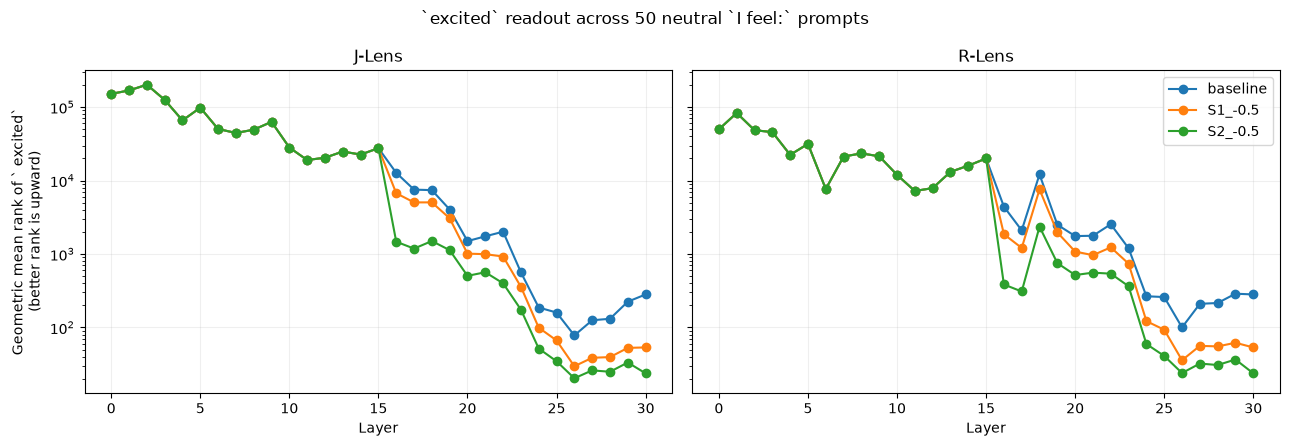

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
    sharey=True,
)

for ax, lens_name in zip(axes, ["J", "R"]):
    for condition in [
        "baseline",
        "S1_-0.5",
        "S2_-0.5",
    ]:
        sub = excited_summary[
            excited_summary["lens"].eq(lens_name)
            & excited_summary["condition"].eq(condition)
        ]

        ax.plot(
            sub["layer"],
            sub["geometric_mean_rank"],
            marker="o",
            label=condition,
        )

    ax.set_yscale("log")
    ax.invert_yaxis()
    ax.set_title(f"{lens_name}-Lens")
    ax.set_xlabel("Layer")
    ax.grid(alpha=0.2)

axes[0].set_ylabel(
    "Geometric mean rank of ` excited`\n"
    "(better rank is upward)"
)

axes[1].legend()

fig.suptitle(
    "`excited` readout across 50 neutral `I feel:` prompts"
)

fig.tight_layout()

fig.savefig(
    lens_dir / "excited_rank_trajectory.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

In [6]:
import unicodedata


def token_kind(token):
    s = token.strip()

    if not s:
        return "whitespace"

    if "_" in s and all(
        ch == "_"
        or ch.isspace()
        or unicodedata.category(ch).startswith("P")
        for ch in token
    ):
        return "blank_like"

    if any(ch.isalpha() for ch in s):
        return "word_like"

    if all(
        unicodedata.category(ch).startswith(("P", "S"))
        or ch.isspace()
        for ch in token
    ):
        return "punct_symbol"

    return "other"


lens_topk["token_kind"] = (
    lens_topk["token"].map(token_kind)
)

topk_composition = (
    lens_topk
    .groupby(
        [
            "condition",
            "lens",
            "layer",
            "token_kind",
        ]
    )
    .size()
    .rename("n")
    .reset_index()
)

totals = (
    topk_composition
    .groupby(
        ["condition", "lens", "layer"]
    )["n"]
    .transform("sum")
)

topk_composition["fraction"] = (
    topk_composition["n"] / totals
)

topk_composition.to_csv(
    lens_dir / "all50_topk_composition.csv",
    index=False,
)

display(
    topk_composition[
        topk_composition["condition"].eq("S2_-0.5")
        & topk_composition["layer"].isin(
            [8, 12, 16, 20, 24, 28, 30]
        )
    ].pivot_table(
        index=["layer", "lens"],
        columns="token_kind",
        values="fraction",
        fill_value=0,
    ).round(3)
)

token_kind  blank_like  other  punct_symbol  whitespace  word_like
layer lens                                                        
8     J          0.000  0.019         0.243       0.030      0.709
      R          0.023  0.000         0.250       0.000      0.727
12    J          0.013  0.005         0.148       0.017      0.817
      R          0.066  0.000         0.113       0.002      0.818
16    J          0.117  0.000         0.258       0.004      0.622
      R          0.198  0.000         0.140       0.001      0.662
20    J          0.468  0.000         0.307       0.123      0.102
      R          0.477  0.000         0.275       0.068      0.180
24    J          0.378  0.000         0.362       0.115      0.145
      R          0.384  0.000         0.315       0.097      0.204
28    J          0.661  0.000         0.060       0.006      0.273
      R          0.684  0.000         0.094       0.005      0.216
30    J          0.549  0.000         0.080       0.029      0.341
      R          0.549  0.000         0.080       0.029      0.341

In [7]:
cloud_scores = lens_topk.copy()

cloud_scores["rr"] = 1.0 / cloud_scores["rank"]

cloud_scores = (
    cloud_scores
    .groupby(
        [
            "condition",
            "lens",
            "layer",
            "token_id",
            "token",
            "token_kind",
        ],
        as_index=False,
    )
    .agg(
        cloud_weight=("rr", "sum"),
        prompt_count=("prompt_idx", "nunique"),
        mean_rank=("rank", "mean"),
    )
)

cloud_scores.to_csv(
    lens_dir / "all50_topk_cloud_scores.csv",
    index=False,
)


def show_cloud_table(
    condition,
    lens,
    layer,
    *,
    semantic_only=True,
    n=40,
):
    x = cloud_scores[
        cloud_scores["condition"].eq(condition)
        & cloud_scores["lens"].eq(lens)
        & cloud_scores["layer"].eq(layer)
    ]

    if semantic_only:
        x = x[x["token_kind"].eq("word_like")]

    return (
        x.sort_values(
            "cloud_weight",
            ascending=False,
        )
        .head(n)[
            [
                "token",
                "cloud_weight",
                "prompt_count",
                "mean_rank",
            ]
        ]
    )


print("S2 -0.5 / R-Lens / L12")
display(
    show_cloud_table(
        "S2_-0.5",
        "R",
        12,
    )
)

print("S2 -0.5 / R-Lens / L16")
display(
    show_cloud_table(
        "S2_-0.5",
        "R",
        16,
    )
)

print("S2 -0.5 / R-Lens / L20")
display(
    show_cloud_table(
        "S2_-0.5",
        "R",
        20,
    )
)

S2 -0.5 / R-Lens / L12


,token,cloud_weight,prompt_count,mean_rank
20701,feelings,35.194444,50,2.420000
20679,feeling,11.710629,49,7.530612
20697,emotional,8.282517,50,10.220000
20837,的情绪,8.227957,49,8.734694
20706,somehow,5.910446,49,12.469388
20821,怎样的,5.392452,48,13.770833
20818,情绪,5.353310,43,11.953488
20699,suddenly,4.929344,48,15.000000
20719,emotions,3.967776,45,15.600000
20790,sensations,3.933287,31,18.064516


S2 -0.5 / R-Lens / L16


,token,cloud_weight,prompt_count,mean_rank
21698,immediately,9.729136,49,8.163265
21724,feelings,9.506245,49,10.183673
21723,suddenly,4.318531,44,13.954545
21778,sensations,3.980239,34,17.970588
21811,这句话,3.757537,47,18.680851
21732,calm,2.925884,45,21.800000
21686,moment,2.306174,38,23.605263
21691,natural,2.228230,33,20.515152
21705,feeling,2.085241,38,22.710526
21797,瞬间,2.070370,35,21.371429


S2 -0.5 / R-Lens / L20


,token,cloud_weight,prompt_count,mean_rank
22493,feeling,2.098820,28,27.857143
22554,通则,1.088075,36,35.083333
22517,ế,1.002097,33,34.484848
22459,_A,0.922783,33,36.848485
22521,innen,0.533974,20,39.150000
22506,feelings,0.530840,18,36.333333
22440,os,0.488957,10,29.200000
22548,我的心,0.454552,20,44.700000
22509,calm,0.452967,10,33.600000
22557,松了一口气,0.440000,3,14.333333


In [8]:
# Compare top-k token-type composition across conditions.
#
# This tells us whether the late "blank / OPTIONS" transition is:
#   - generic to the neutral I-feel prompt,
#   - enhanced by either steering direction,
#   - or especially S2-specific.

kind_compare = (
    topk_composition[
        topk_composition["token_kind"].isin(
            ["word_like", "blank_like", "punct_symbol"]
        )
    ]
    .pivot_table(
        index=["layer", "lens", "condition"],
        columns="token_kind",
        values="fraction",
        fill_value=0,
    )
    .reset_index()
)

display(
    kind_compare[
        kind_compare["layer"].isin(
            [8, 12, 16, 18, 20, 24, 28, 30]
        )
    ].round(3)
)

token_kind,layer,lens,condition,blank_like,punct_symbol,word_like
48,8,J,S1_-0.5,0.000,0.243,0.709
49,8,J,S2_-0.5,0.000,0.243,0.709
50,8,J,baseline,0.000,0.243,0.709
51,8,R,S1_-0.5,0.023,0.250,0.727
52,8,R,S2_-0.5,0.023,0.250,0.727
53,8,R,baseline,0.023,0.250,0.727
72,12,J,S1_-0.5,0.013,0.148,0.817
73,12,J,S2_-0.5,0.013,0.148,0.817
74,12,J,baseline,0.013,0.148,0.817
75,12,R,S1_-0.5,0.066,0.113,0.818


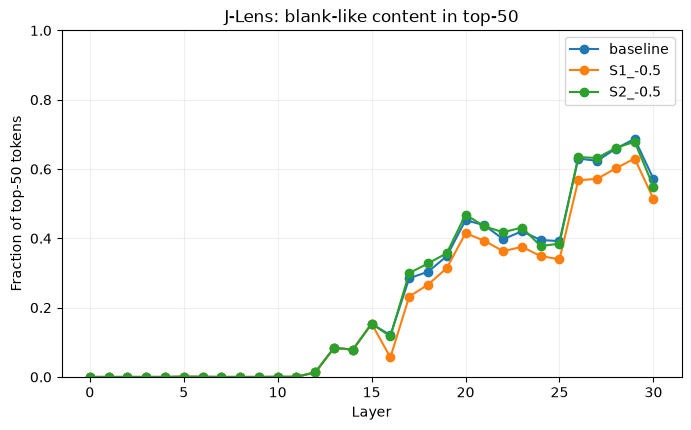

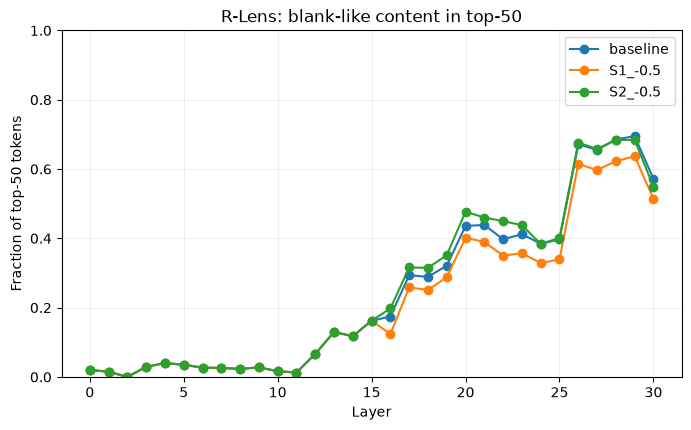

In [9]:
import matplotlib.pyplot as plt

for lens_name in ["J", "R"]:
    fig, ax = plt.subplots(figsize=(8, 4.5))

    for condition in [
        "baseline",
        "S1_-0.5",
        "S2_-0.5",
    ]:
        sub = kind_compare[
            kind_compare["lens"].eq(lens_name)
            & kind_compare["condition"].eq(condition)
        ]

        ax.plot(
            sub["layer"],
            sub["blank_like"],
            marker="o",
            label=condition,
        )

    ax.set_title(
        f"{lens_name}-Lens: blank-like content in top-50"
    )
    ax.set_xlabel("Layer")
    ax.set_ylabel("Fraction of top-50 tokens")
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(alpha=0.2)

    plt.show()

In [10]:
# Difference from baseline in top-k composition.

baseline_kind = (
    kind_compare[
        kind_compare["condition"].eq("baseline")
    ]
    .set_index(["layer", "lens"])
)

delta_rows = []

for condition in ["S1_-0.5", "S2_-0.5"]:
    sub = (
        kind_compare[
            kind_compare["condition"].eq(condition)
        ]
        .set_index(["layer", "lens"])
    )

    for idx, row in sub.iterrows():
        base = baseline_kind.loc[idx]

        delta_rows.append({
            "layer": idx[0],
            "lens": idx[1],
            "condition": condition,
            "delta_blank": row["blank_like"] - base["blank_like"],
            "delta_word": row["word_like"] - base["word_like"],
            "delta_punct": row["punct_symbol"] - base["punct_symbol"],
        })

kind_delta = pd.DataFrame(delta_rows)

display(
    kind_delta[
        kind_delta["layer"].isin([16, 18, 20, 22, 24, 26, 28, 30])
    ].round(3)
)

,layer,lens,condition,delta_blank,delta_word,delta_punct
32,16,J,S1_-0.5,-0.064,0.091,-0.019
33,16,R,S1_-0.5,-0.051,0.054,0.001
36,18,J,S1_-0.5,-0.037,0.038,0.008
37,18,R,S1_-0.5,-0.038,0.050,-0.002
40,20,J,S1_-0.5,-0.038,0.001,-0.034
41,20,R,S1_-0.5,-0.034,0.010,-0.019
44,22,J,S1_-0.5,-0.035,-0.008,-0.031
45,22,R,S1_-0.5,-0.047,0.022,-0.010
48,24,J,S1_-0.5,-0.046,-0.035,-0.010
49,24,R,S1_-0.5,-0.056,-0.045,0.015


In [11]:
kind_delta_full = []

for condition in ["S1_-0.5", "S2_-0.5"]:
    sub = (
        kind_compare[
            kind_compare["condition"].eq(condition)
        ]
        .set_index(["layer", "lens"])
    )

    for idx, row in sub.iterrows():
        base = baseline_kind.loc[idx]

        out = {
            "layer": idx[0],
            "lens": idx[1],
            "condition": condition,
        }

        for kind in [
            "blank_like",
            "word_like",
            "punct_symbol",
            "whitespace",
            "other",
        ]:
            out[f"delta_{kind}"] = (
                row.get(kind, 0.0) - base.get(kind, 0.0)
            )

        kind_delta_full.append(out)

kind_delta_full = pd.DataFrame(kind_delta_full)

display(
    kind_delta_full[
        kind_delta_full["layer"].isin(
            [16, 18, 20, 22, 24, 26, 28, 30]
        )
    ].round(3)
)

,layer,lens,condition,delta_blank_like,delta_word_like,delta_punct_symbol,delta_whitespace,delta_other
32,16,J,S1_-0.5,-0.064,0.091,-0.019,0.0,0.0
33,16,R,S1_-0.5,-0.051,0.054,0.001,0.0,0.0
36,18,J,S1_-0.5,-0.037,0.038,0.008,0.0,0.0
37,18,R,S1_-0.5,-0.038,0.050,-0.002,0.0,0.0
40,20,J,S1_-0.5,-0.038,0.001,-0.034,0.0,0.0
41,20,R,S1_-0.5,-0.034,0.010,-0.019,0.0,0.0
44,22,J,S1_-0.5,-0.035,-0.008,-0.031,0.0,0.0
45,22,R,S1_-0.5,-0.047,0.022,-0.010,0.0,0.0
48,24,J,S1_-0.5,-0.046,-0.035,-0.010,0.0,0.0
49,24,R,S1_-0.5,-0.056,-0.045,0.015,0.0,0.0


In [12]:
# Correct full token-kind comparison.
#
# Rebuild from topk_composition WITHOUT filtering categories first.

kind_compare_full = (
    topk_composition
    .pivot_table(
        index=["layer", "lens", "condition"],
        columns="token_kind",
        values="fraction",
        fill_value=0,
    )
    .reset_index()
)

expected_kinds = [
    "blank_like",
    "word_like",
    "punct_symbol",
    "whitespace",
    "other",
]

for kind in expected_kinds:
    if kind not in kind_compare_full.columns:
        kind_compare_full[kind] = 0.0


baseline_full = (
    kind_compare_full[
        kind_compare_full["condition"].eq("baseline")
    ]
    .set_index(["layer", "lens"])
)

delta_rows = []

for condition in ["S1_-0.5", "S2_-0.5"]:
    sub = (
        kind_compare_full[
            kind_compare_full["condition"].eq(condition)
        ]
        .set_index(["layer", "lens"])
    )

    for idx, row in sub.iterrows():
        base = baseline_full.loc[idx]

        out = {
            "layer": idx[0],
            "lens": idx[1],
            "condition": condition,
        }

        for kind in expected_kinds:
            out[f"delta_{kind}"] = (
                row[kind] - base[kind]
            )

        # Sanity: composition differences should sum to ~0.
        out["delta_sum"] = sum(
            out[f"delta_{kind}"]
            for kind in expected_kinds
        )

        delta_rows.append(out)

kind_delta_full = pd.DataFrame(delta_rows)

display(
    kind_delta_full[
        kind_delta_full["layer"].isin(
            [16, 18, 20, 22, 24, 26, 28, 30]
        )
    ].round(3)
)

print(
    "max |delta sum|:",
    kind_delta_full["delta_sum"].abs().max(),
)

,layer,lens,condition,delta_blank_like,delta_word_like,delta_punct_symbol,delta_whitespace,delta_other,delta_sum
32,16,J,S1_-0.5,-0.064,0.091,-0.019,-0.008,0.000,0.0
33,16,R,S1_-0.5,-0.051,0.054,0.001,-0.004,-0.000,-0.0
36,18,J,S1_-0.5,-0.037,0.038,0.008,-0.009,0.000,0.0
37,18,R,S1_-0.5,-0.038,0.050,-0.002,-0.010,-0.000,-0.0
40,20,J,S1_-0.5,-0.038,0.001,-0.034,0.072,-0.001,0.0
41,20,R,S1_-0.5,-0.034,0.010,-0.019,0.045,-0.003,0.0
44,22,J,S1_-0.5,-0.035,-0.008,-0.031,0.073,0.000,-0.0
45,22,R,S1_-0.5,-0.047,0.022,-0.010,0.034,0.000,0.0
48,24,J,S1_-0.5,-0.046,-0.035,-0.010,0.092,0.000,0.0
49,24,R,S1_-0.5,-0.056,-0.045,0.015,0.085,0.000,-0.0


max |delta sum|: 9.540979117872439e-17


In [13]:
# Coarser format-vs-word diagnostic.

format_compare = kind_compare_full.copy()

format_compare["slot_like"] = (
    format_compare["blank_like"]
    + format_compare["whitespace"]
)

format_compare["format_like"] = (
    format_compare["blank_like"]
    + format_compare["whitespace"]
    + format_compare["punct_symbol"]
)

baseline_format = (
    format_compare[
        format_compare["condition"].eq("baseline")
    ]
    .set_index(["layer", "lens"])
)

rows = []

for condition in ["S1_-0.5", "S2_-0.5"]:
    sub = (
        format_compare[
            format_compare["condition"].eq(condition)
        ]
        .set_index(["layer", "lens"])
    )

    for idx, row in sub.iterrows():
        base = baseline_format.loc[idx]

        rows.append({
            "layer": idx[0],
            "lens": idx[1],
            "condition": condition,
            "delta_slot_like":
                row["slot_like"] - base["slot_like"],
            "delta_format_like":
                row["format_like"] - base["format_like"],
            "delta_word_like":
                row["word_like"] - base["word_like"],
        })

format_delta = pd.DataFrame(rows)

display(
    format_delta[
        format_delta["layer"].isin(
            [16, 18, 20, 22, 24, 26, 28, 30]
        )
    ].round(3)
)

,layer,lens,condition,delta_slot_like,delta_format_like,delta_word_like
32,16,J,S1_-0.5,-0.072,-0.091,0.091
33,16,R,S1_-0.5,-0.055,-0.054,0.054
36,18,J,S1_-0.5,-0.046,-0.038,0.038
37,18,R,S1_-0.5,-0.048,-0.050,0.050
40,20,J,S1_-0.5,0.034,0.000,0.001
41,20,R,S1_-0.5,0.012,-0.008,0.010
44,22,J,S1_-0.5,0.038,0.007,-0.008
45,22,R,S1_-0.5,-0.012,-0.022,0.022
48,24,J,S1_-0.5,0.045,0.035,-0.035
49,24,R,S1_-0.5,0.029,0.044,-0.045


In [14]:
# Which top-50 tokens are enriched/depleted by steering relative to baseline?
#
# Score = mean reciprocal rank across all 50 prompts, with absence from
# top-50 contributing zero. This is deliberately a top-k descriptive measure,
# not a full-vocabulary logit comparison.

import pandas as pd

x = lens_topk.copy()
x["rr"] = 1.0 / x["rank"]

# Every token's reciprocal-rank contribution, summed over prompts.
rr = (
    x.groupby(
        ["condition", "lens", "layer", "token_id", "token"],
        as_index=False,
    )
    .agg(
        rr_sum=("rr", "sum"),
        prompt_count=("prompt_idx", "nunique"),
    )
)

# Normalize by 50 prompts so absence = zero contribution.
rr["mrr50"] = rr["rr_sum"] / 50.0

base = (
    rr[rr["condition"].eq("baseline")]
    [["lens", "layer", "token_id", "token", "mrr50", "prompt_count"]]
    .rename(columns={
        "mrr50": "baseline_mrr50",
        "prompt_count": "baseline_prompt_count",
    })
)

rows = []

for condition in ["S1_-0.5", "S2_-0.5"]:
    steered = (
        rr[rr["condition"].eq(condition)]
        [["lens", "layer", "token_id", "token", "mrr50", "prompt_count"]]
        .rename(columns={
            "mrr50": "steered_mrr50",
            "prompt_count": "steered_prompt_count",
        })
    )

    merged = base.merge(
        steered,
        on=["lens", "layer", "token_id", "token"],
        how="outer",
    ).fillna(0)

    merged["condition"] = condition
    merged["delta_mrr50"] = (
        merged["steered_mrr50"]
        - merged["baseline_mrr50"]
    )

    rows.append(merged)

token_enrichment = pd.concat(rows, ignore_index=True)

token_enrichment.to_csv(
    lens_dir / "all50_top50_token_enrichment.csv",
    index=False,
)


def enriched(condition, lens, layer, n=30):
    return (
        token_enrichment[
            token_enrichment["condition"].eq(condition)
            & token_enrichment["lens"].eq(lens)
            & token_enrichment["layer"].eq(layer)
        ]
        .sort_values("delta_mrr50", ascending=False)
        .head(n)[
            [
                "token",
                "delta_mrr50",
                "steered_prompt_count",
                "baseline_prompt_count",
            ]
        ]
    )


def depleted(condition, lens, layer, n=30):
    return (
        token_enrichment[
            token_enrichment["condition"].eq(condition)
            & token_enrichment["lens"].eq(lens)
            & token_enrichment["layer"].eq(layer)
        ]
        .sort_values("delta_mrr50")
        .head(n)[
            [
                "token",
                "delta_mrr50",
                "steered_prompt_count",
                "baseline_prompt_count",
            ]
        ]
    )


for layer in [16, 20, 22, 24, 28]:
    print("\n" + "=" * 72)
    print(f"S2 -0.5 / R / L{layer}: ENRICHED")
    display(enriched("S2_-0.5", "R", layer, 20))

    print(f"S2 -0.5 / R / L{layer}: DEPLETED")
    display(depleted("S2_-0.5", "R", layer, 20))


S2 -0.5 / R / L16: ENRICHED


,token,delta_mrr50,steered_prompt_count,baseline_prompt_count
24662,____,0.081800,50.0,50.0
24631,?,0.077462,50.0,50.0
24750,calm,0.053448,45.0,7.0
24693,___,0.051255,50.0,49.0
24702,immediately,0.039122,49.0,48.0
24692,natural,0.031324,33.0,17.0
24816,sensations,0.030560,34.0,29.0
24841,瞬间,0.024462,35.0,23.0
24822,_____,0.024397,41.0,29.0
24740,suddenly,0.023768,44.0,43.0


S2 -0.5 / R / L16: DEPLETED


,token,delta_mrr50,steered_prompt_count,baseline_prompt_count
24742,feelings,-0.196190,49.0,49.0
24628,:,-0.084811,50.0,50.0
24738,emotional,-0.053757,18.0,43.0
24848,怎样的,-0.037680,27.0,48.0
24666,something,-0.037526,18.0,42.0
24867,的情绪,-0.028391,22.0,34.0
24655,what,-0.027192,6.0,29.0
24831,psych,-0.024732,1.0,25.0
24858,这句话,-0.021503,47.0,48.0
24687,?:,-0.020416,49.0,50.0



S2 -0.5 / R / L20: ENRICHED


...

,token,delta_mrr50,steered_prompt_count,baseline_prompt_count
26550,__,-0.082000,49.0,49.0
26578,____,-0.046667,49.0,49.0
26633,feeling,-0.032197,6.0,32.0
26532,\n,-0.031512,21.0,43.0
26641,feels,-0.027526,2.0,20.0
26623,___,-0.027379,49.0,49.0
26717,_\,-0.026857,48.0,48.0
26784,副处长,-0.025642,15.0,44.0
26554,\n,-0.024751,22.0,33.0
26718,OPTIONS,-0.021776,9.0,33.0



S2 -0.5 / R / L28: ENRICHED


,token,delta_mrr50,steered_prompt_count,baseline_prompt_count
27842,__,0.150509,49.0,49.0
27913,excited,0.049872,42.0,3.0
27986,exc,0.032878,33.0,8.0
28051,_____,0.024382,49.0,48.0
27936,__.,0.020498,49.0,49.0
28099,松了一口气,0.019771,13.0,6.0
27836,?,0.015542,30.0,3.0
28010,__/,0.014501,42.0,24.0
28015,relieved,0.014089,36.0,23.0
27895,warm,0.012431,27.0,11.0


S2 -0.5 / R / L28: DEPLETED


,token,delta_mrr50,steered_prompt_count,baseline_prompt_count
27848,____,-0.082222,49.0,49.0
27890,___,-0.029462,49.0,49.0
27823,I,-0.020301,1.0,17.0
27972,____,-0.017643,49.0,48.0
27888,DATE,-0.017143,1.0,1.0
28020,__;,-0.016972,48.0,47.0
27872,train,-0.016667,1.0,1.0
27989,warmth,-0.015715,4.0,3.0
27905,blank,-0.014619,13.0,34.0
27896,feeling,-0.014487,2.0,27.0


In [15]:
# Paired full-vocabulary logit/rank deltas for every frozen psych probe.
#
# Uses lens_vocab_ranks:
# prompt_idx, condition, lens, layer, family, term, rank, logit

import numpy as np
import pandas as pd


def paired_probe_delta(a, b, label):
    """
    a - b, paired by prompt.
    Rank improvement is reported as log(rank_b / rank_a):
      positive => term ranks better under a.
    """
    keys = [
        "prompt_idx",
        "lens",
        "layer",
        "family",
        "term",
        "token_id",
    ]

    aa = (
        lens_vocab_ranks[
            lens_vocab_ranks["condition"].eq(a)
        ][keys + ["rank", "logit"]]
        .rename(columns={
            "rank": "rank_a",
            "logit": "logit_a",
        })
    )

    bb = (
        lens_vocab_ranks[
            lens_vocab_ranks["condition"].eq(b)
        ][keys + ["rank", "logit"]]
        .rename(columns={
            "rank": "rank_b",
            "logit": "logit_b",
        })
    )

    x = aa.merge(bb, on=keys, validate="one_to_one")

    x["logit_delta"] = x["logit_a"] - x["logit_b"]

    # Positive = improved rank under condition a.
    x["log_rank_gain"] = np.log(
        x["rank_b"] / x["rank_a"]
    )

    summary = (
        x.groupby(
            ["lens", "layer", "family", "term"],
            as_index=False,
        )
        .agg(
            mean_logit_delta=("logit_delta", "mean"),
            median_logit_delta=("logit_delta", "median"),
            mean_log_rank_gain=("log_rank_gain", "mean"),
            median_log_rank_gain=("log_rank_gain", "median"),
            improved_prompts=(
                "log_rank_gain",
                lambda z: int((z > 0).sum()),
            ),
        )
    )

    summary["comparison"] = label
    return summary


probe_deltas = pd.concat(
    [
        paired_probe_delta(
            "S2_-0.5",
            "baseline",
            "S2 - baseline",
        ),
        paired_probe_delta(
            "S1_-0.5",
            "baseline",
            "S1 - baseline",
        ),
        paired_probe_delta(
            "S2_-0.5",
            "S1_-0.5",
            "S2 - S1",
        ),
    ],
    ignore_index=True,
)

probe_deltas.to_csv(
    lens_dir / "all50_psych_probe_deltas.csv",
    index=False,
)

# First look: S2 vs S1, R-Lens, selected layers.
display(
    probe_deltas[
        probe_deltas["comparison"].eq("S2 - S1")
        & probe_deltas["lens"].eq("R")
        & probe_deltas["layer"].isin(
            [12, 16, 20, 22, 24, 28, 30]
        )
    ]
    .sort_values(
        ["layer", "mean_log_rank_gain"],
        ascending=[True, False],
    )
    [
        [
            "layer",
            "family",
            "term",
            "mean_log_rank_gain",
            "mean_logit_delta",
            "improved_prompts",
        ]
    ]
)

,layer,family,term,mean_log_rank_gain,mean_logit_delta,improved_prompts
10020,12,activated_vitality,animated,0.000000,0.000000,0
10021,12,activated_vitality,eager,0.000000,0.000000,0
10022,12,activated_vitality,energetic,0.000000,0.000000,0
10023,12,activated_vitality,enthusiastic,0.000000,0.000000,0
10024,12,activated_vitality,excited,0.000000,0.000000,0
...,...,...,...,...,...,...
11155,30,inhibition_defeat,withdrawn,-0.991239,-0.906777,0
11119,30,calm_positive,content,-1.012804,-0.833750,0
11140,30,distress_self_devaluation,rejected,-1.306461,-1.411039,0
11110,30,agency_assurance,empowered,-1.587428,-1.188359,0


In [16]:
# Compact "who actually moves?" view.

def show_probe_extremes(
    comparison="S2 - S1",
    lens="R",
    layers=(16, 20, 22, 24, 28, 30),
    n=12,
):
    x = probe_deltas[
        probe_deltas["comparison"].eq(comparison)
        & probe_deltas["lens"].eq(lens)
    ]

    for layer in layers:
        z = x[x["layer"].eq(layer)]

        print("\n" + "=" * 72)
        print(f"{comparison} / {lens} / L{layer}: strongest gains")

        display(
            z.nlargest(n, "mean_log_rank_gain")[
                [
                    "family",
                    "term",
                    "mean_log_rank_gain",
                    "mean_logit_delta",
                    "improved_prompts",
                ]
            ]
        )

        print(f"{comparison} / {lens} / L{layer}: strongest losses")

        display(
            z.nsmallest(n, "mean_log_rank_gain")[
                [
                    "family",
                    "term",
                    "mean_log_rank_gain",
                    "mean_logit_delta",
                    "improved_prompts",
                ]
            ]
        )


show_probe_extremes()


S2 - S1 / R / L16: strongest gains


,family,term,mean_log_rank_gain,mean_logit_delta,improved_prompts
10264,activated_vitality,excited,1.575300,0.981406,50
10282,calm_positive,safe,1.513951,1.048828,50
10319,relief_release,relieved,1.300150,0.914098,50
10318,relief_release,relief,1.007838,0.765864,50
10283,calm_positive,secure,0.586449,0.786327,50
10277,approach_drive,ready,0.564243,0.416758,50
10267,agency_assurance,assured,0.551480,0.795098,50
10294,distress_self_devaluation,despair,0.540866,0.769668,50
10311,inhibition_defeat,helpless,0.362080,0.417733,50
10316,relief_release,eased,0.323172,0.968066,50


S2 - S1 / R / L16: strongest losses


,family,term,mean_log_rank_gain,mean_logit_delta,improved_prompts
10279,calm_positive,content,-1.294497,-0.742188,0
10300,distress_self_devaluation,rejected,-1.058239,-0.984684,0
10284,calm_positive,serene,-0.781317,-0.501055,0
10293,distress_self_devaluation,ashamed,-0.730596,-1.002400,0
10280,calm_positive,peaceful,-0.653999,-0.494653,0
10260,activated_vitality,animated,-0.608725,-0.363438,0
10308,generic_positive,pleased,-0.509090,-0.395566,0
10296,distress_self_devaluation,guilty,-0.500602,-0.376836,0
10304,generic_positive,glad,-0.500277,-0.288750,0
10315,inhibition_defeat,withdrawn,-0.402466,-0.735211,0



S2 - S1 / R / L20: strongest gains


...

,family,term,mean_log_rank_gain,mean_logit_delta,improved_prompts
10990,agency_assurance,empowered,-1.239277,-0.939336,0
11020,distress_self_devaluation,rejected,-0.979868,-1.115309,0
10999,calm_positive,content,-0.976119,-0.548906,1
11013,distress_self_devaluation,ashamed,-0.852963,-0.652285,0
11016,distress_self_devaluation,guilty,-0.802420,-0.452969,1
11035,inhibition_defeat,withdrawn,-0.800836,-0.630967,0
10994,approach_drive,determined,-0.644346,-0.423906,2
10991,agency_assurance,powerful,-0.587747,-0.630681,0
11033,inhibition_defeat,powerless,-0.428129,-0.382012,0
11019,distress_self_devaluation,miserable,-0.349842,-0.378736,0



S2 - S1 / R / L30: strongest gains


,family,term,mean_log_rank_gain,mean_logit_delta,improved_prompts
11122,calm_positive,safe,1.395211,1.047344,48
11101,activated_vitality,eager,1.081245,0.813281,50
11123,calm_positive,secure,0.854138,0.653906,48
11104,activated_vitality,excited,0.811530,1.301562,49
11102,activated_vitality,energetic,0.789079,0.510938,49
11156,relief_release,eased,0.741246,0.525781,50
11103,activated_vitality,enthusiastic,0.539329,0.329375,49
11130,competence_success,proficient,0.539060,0.597031,49
11105,activated_vitality,lively,0.530947,0.439141,49
11158,relief_release,relief,0.516456,0.435000,43


S2 - S1 / R / L30: strongest losses


,family,term,mean_log_rank_gain,mean_logit_delta,improved_prompts
11133,distress_self_devaluation,ashamed,-1.593355,-1.188125,0
11110,agency_assurance,empowered,-1.587428,-1.188359,0
11140,distress_self_devaluation,rejected,-1.306461,-1.411039,0
11119,calm_positive,content,-1.012804,-0.833750,0
11155,inhibition_defeat,withdrawn,-0.991239,-0.906777,0
11136,distress_self_devaluation,guilty,-0.898809,-0.783750,0
11153,inhibition_defeat,powerless,-0.801669,-0.683359,0
11114,approach_drive,determined,-0.770251,-0.616953,1
11111,agency_assurance,powerful,-0.749209,-0.695195,0
11149,inhibition_defeat,defeated,-0.550269,-0.516172,1


In [17]:
display(
    probe_deltas[
        probe_deltas["comparison"].eq("S2 - S1")
        & probe_deltas["term"].eq("excited")
    ][
        [
            "lens",
            "layer",
            "mean_log_rank_gain",
            "mean_logit_delta",
            "improved_prompts",
        ]
    ]
)

,lens,layer,mean_log_rank_gain,mean_logit_delta,improved_prompts
7444,J,0,0.000000,0.000000,0
7504,J,1,0.000000,0.000000,0
7564,J,2,0.000000,0.000000,0
7624,J,3,0.000000,0.000000,0
7684,J,4,0.000000,0.000000,0
...,...,...,...,...,...
10864,R,26,0.401268,1.240000,47
10924,R,27,0.555145,1.138437,50
10984,R,28,0.583400,1.258125,48
11044,R,29,0.524722,1.248125,49


In [19]:
# Family-level trajectories from the frozen psych vocabulary.
#
# Unit of observation:
#   prompt -> mean across frozen terms in family
#
# Then aggregate across the 50 prompts.
#
# Positive log-rank gain means the first condition ranks the family better.

import numpy as np
import pandas as pd


def paired_raw(a, b, label):
    keys = [
        "prompt_idx",
        "lens",
        "layer",
        "family",
        "term",
        "token_id",
    ]

    aa = (
        lens_vocab_ranks[
            lens_vocab_ranks["condition"].eq(a)
        ][keys + ["rank", "logit"]]
        .rename(columns={
            "rank": "rank_a",
            "logit": "logit_a",
        })
    )

    bb = (
        lens_vocab_ranks[
            lens_vocab_ranks["condition"].eq(b)
        ][keys + ["rank", "logit"]]
        .rename(columns={
            "rank": "rank_b",
            "logit": "logit_b",
        })
    )

    x = aa.merge(bb, on=keys, validate="one_to_one")

    x["log_rank_gain"] = np.log(
        x["rank_b"] / x["rank_a"]
    )

    x["logit_delta"] = (
        x["logit_a"] - x["logit_b"]
    )

    x["comparison"] = label

    return x


raw_pairwise = pd.concat(
    [
        paired_raw(
            "S2_-0.5",
            "baseline",
            "S2 - baseline",
        ),
        paired_raw(
            "S1_-0.5",
            "baseline",
            "S1 - baseline",
        ),
        paired_raw(
            "S2_-0.5",
            "S1_-0.5",
            "S2 - S1",
        ),
    ],
    ignore_index=True,
)


# First average terms within each family, separately for every prompt.
family_by_prompt = (
    raw_pairwise
    .groupby(
        [
            "comparison",
            "prompt_idx",
            "lens",
            "layer",
            "family",
        ],
        as_index=False,
    )
    .agg(
        mean_log_rank_gain=("log_rank_gain", "mean"),
        mean_logit_delta=("logit_delta", "mean"),
    )
)


# Then average across prompts.
family_summary = (
    family_by_prompt
    .groupby(
        [
            "comparison",
            "lens",
            "layer",
            "family",
        ],
        as_index=False,
    )
    .agg(
        mean_log_rank_gain=("mean_log_rank_gain", "mean"),
        median_log_rank_gain=("mean_log_rank_gain", "median"),
        mean_logit_delta=("mean_logit_delta", "mean"),
        median_logit_delta=("mean_logit_delta", "median"),
        positive_prompts=(
            "mean_log_rank_gain",
            lambda x: int((x > 0).sum()),
        ),
    )
)

family_by_prompt.to_csv(
    lens_dir / "all50_psych_family_by_prompt.csv",
    index=False,
)

family_summary.to_csv(
    lens_dir / "all50_psych_family_summary.csv",
    index=False,
)

In [20]:
display(
    family_summary[
        family_summary["comparison"].eq("S2 - S1")
        & family_summary["lens"].eq("R")
        & family_summary["layer"].isin(
            [16, 20, 22, 24, 28, 30]
        )
    ]
    .pivot_table(
        index="family",
        columns="layer",
        values="mean_log_rank_gain",
    )
    .round(2)
)

layer,16,20,22,24,28,30
family,,,,,,
activated_vitality,0.24,0.12,0.13,0.14,0.39,0.55
agency_assurance,0.00,-0.24,-0.15,-0.29,-0.25,-0.52
approach_drive,0.07,0.02,-0.06,-0.16,-0.18,-0.29
calm_positive,-0.07,-0.05,0.08,0.23,0.40,0.24
competence_success,0.09,0.06,0.02,0.02,0.02,0.09
distress_self_devaluation,-0.13,-0.26,-0.25,-0.25,-0.33,-0.57
generic_positive,-0.22,-0.44,-0.38,-0.26,-0.01,-0.10
inhibition_defeat,0.07,-0.14,-0.03,-0.12,-0.15,-0.39
relief_release,0.68,0.18,0.30,0.29,0.16,0.19


In [21]:
# Decompose the S2-vs-S1 family contrast:
# is S2 moving, S1 moving, or both?

layers_show = [16, 20, 22, 24, 28, 30]

family_threeway = (
    family_summary[
        family_summary["lens"].eq("R")
        & family_summary["layer"].isin(layers_show)
    ]
    .pivot_table(
        index=["family", "layer"],
        columns="comparison",
        values="mean_log_rank_gain",
    )
    .reset_index()
)

display(
    family_threeway.round(2)
)

comparison,family,layer,S1 - baseline,S2 - S1,S2 - baseline
0,activated_vitality,16,0.32,0.24,0.56
1,activated_vitality,20,0.07,0.12,0.19
2,activated_vitality,22,0.15,0.13,0.27
3,activated_vitality,24,0.12,0.14,0.26
4,activated_vitality,28,0.22,0.39,0.61
5,activated_vitality,30,0.36,0.55,0.91
6,agency_assurance,16,-0.13,0.00,-0.13
7,agency_assurance,20,-0.11,-0.24,-0.35
8,agency_assurance,22,0.00,-0.15,-0.15
9,agency_assurance,24,-0.01,-0.29,-0.30


In [22]:
for layer in [16, 24, 30]:
    print("\n", "=" * 68)
    print("LAYER", layer)

    display(
        family_threeway[
            family_threeway["layer"].eq(layer)
        ][
            [
                "family",
                "S2 - baseline",
                "S1 - baseline",
                "S2 - S1",
            ]
        ]
        .sort_values("S2 - S1", ascending=False)
        .round(2)
    )


LAYER 16


comparison,family,S2 - baseline,S1 - baseline,S2 - S1
48,relief_release,0.67,-0.01,0.68
0,activated_vitality,0.56,0.32,0.24
24,competence_success,-0.14,-0.23,0.09
12,approach_drive,-0.09,-0.16,0.07
42,inhibition_defeat,-0.57,-0.64,0.07
6,agency_assurance,-0.13,-0.13,0.00
18,calm_positive,1.08,1.15,-0.07
30,distress_self_devaluation,-1.23,-1.09,-0.13
36,generic_positive,0.61,0.83,-0.22



LAYER 24


comparison,family,S2 - baseline,S1 - baseline,S2 - S1
51,relief_release,0.72,0.43,0.29
21,calm_positive,0.43,0.20,0.23
3,activated_vitality,0.26,0.12,0.14
27,competence_success,-0.10,-0.12,0.02
45,inhibition_defeat,-0.61,-0.49,-0.12
15,approach_drive,-0.23,-0.07,-0.16
33,distress_self_devaluation,-0.66,-0.41,-0.25
39,generic_positive,0.70,0.95,-0.26
9,agency_assurance,-0.30,-0.01,-0.29



LAYER 30


comparison,family,S2 - baseline,S1 - baseline,S2 - S1
5,activated_vitality,0.91,0.36,0.55
23,calm_positive,0.48,0.24,0.24
53,relief_release,1.06,0.87,0.19
29,competence_success,-0.12,-0.22,0.09
41,generic_positive,1.19,1.29,-0.10
17,approach_drive,-0.15,0.14,-0.29
47,inhibition_defeat,-0.90,-0.51,-0.39
11,agency_assurance,-0.54,-0.03,-0.52
35,distress_self_devaluation,-1.23,-0.66,-0.57


In [23]:
# Leave-one-term-out family robustness for S2 - S1.
#
# For each family, remove each constituent term in turn and recompute
# the prompt-level family mean, then aggregate over prompts.

pair = raw_pairwise[
    raw_pairwise["comparison"].eq("S2 - S1")
].copy()

loto_rows = []

for family, fam_df in pair.groupby("family"):
    terms = sorted(fam_df["term"].unique())

    for omitted in terms:
        x = fam_df[
            ~fam_df["term"].eq(omitted)
        ]

        by_prompt = (
            x.groupby(
                ["prompt_idx", "lens", "layer"],
                as_index=False,
            )
            .agg(
                family_gain=("log_rank_gain", "mean"),
                family_logit=("logit_delta", "mean"),
            )
        )

        agg = (
            by_prompt.groupby(
                ["lens", "layer"],
                as_index=False,
            )
            .agg(
                mean_gain=("family_gain", "mean"),
                mean_logit=("family_logit", "mean"),
                positive_prompts=(
                    "family_gain",
                    lambda z: int((z > 0).sum()),
                ),
            )
        )

        agg["family"] = family
        agg["omitted_term"] = omitted
        loto_rows.append(agg)

family_loto = pd.concat(
    loto_rows,
    ignore_index=True,
)

family_loto.to_csv(
    lens_dir / "all50_family_leave_one_term_out.csv",
    index=False,
)

# Show worst-case leave-one-out result at selected layers.
loto_worst = (
    family_loto[
        family_loto["layer"].isin([16, 24, 28, 30])
    ]
    .groupby(
        ["family", "lens", "layer"],
        as_index=False,
    )
    .agg(
        worst_mean_gain=("mean_gain", "min"),
        best_mean_gain=("mean_gain", "max"),
    )
)

display(
    loto_worst[
        loto_worst["lens"].eq("R")
    ].pivot_table(
        index="family",
        columns="layer",
        values="worst_mean_gain",
    ).round(2)
)

layer,16,24,28,30
family,,,,
activated_vitality,0.01,0.04,0.28,0.46
agency_assurance,-0.13,-0.43,-0.40,-0.64
approach_drive,-0.03,-0.21,-0.25,-0.35
calm_positive,-0.33,0.02,0.10,0.05
competence_success,0.06,0.01,-0.05,0.03
distress_self_devaluation,-0.21,-0.30,-0.37,-0.62
generic_positive,-0.28,-0.29,-0.08,-0.20
inhibition_defeat,0.02,-0.17,-0.25,-0.50
relief_release,0.47,0.22,-0.03,0.01


In [24]:
display(
    loto_worst[
        loto_worst["lens"].eq("R")
        & loto_worst["layer"].isin([16, 24, 28, 30])
    ]
    .sort_values(["layer", "family"])
    .round(2)
)

,family,lens,layer,worst_mean_gain,best_mean_gain
4,activated_vitality,R,16,0.01,0.38
12,agency_assurance,R,16,-0.13,0.07
20,approach_drive,R,16,-0.03,0.12
28,calm_positive,R,16,-0.33,0.13
36,competence_success,R,16,0.06,0.11
44,distress_self_devaluation,R,16,-0.21,-0.03
52,generic_positive,R,16,-0.28,-0.17
60,inhibition_defeat,R,16,0.02,0.15
68,relief_release,R,16,0.47,0.88
5,activated_vitality,R,24,0.04,0.20


In [25]:
robust = loto_worst[
    loto_worst["lens"].eq("R")
].copy()

robust["robust_sign"] = np.select(
    [
        robust["worst_mean_gain"] > 0,
        robust["best_mean_gain"] < 0,
    ],
    [
        "positive",
        "negative",
    ],
    default="mixed",
)

display(
    robust[
        robust["layer"].isin([16, 24, 28, 30])
    ][
        [
            "family",
            "layer",
            "worst_mean_gain",
            "best_mean_gain",
            "robust_sign",
        ]
    ]
    .sort_values(["layer", "family"])
    .round(2)
)

,family,layer,worst_mean_gain,best_mean_gain,robust_sign
4,activated_vitality,16,0.01,0.38,positive
12,agency_assurance,16,-0.13,0.07,mixed
20,approach_drive,16,-0.03,0.12,mixed
28,calm_positive,16,-0.33,0.13,mixed
36,competence_success,16,0.06,0.11,positive
44,distress_self_devaluation,16,-0.21,-0.03,negative
52,generic_positive,16,-0.28,-0.17,negative
60,inhibition_defeat,16,0.02,0.15,positive
68,relief_release,16,0.47,0.88,positive
5,activated_vitality,24,0.04,0.20,positive


On Qwen3.5-4B, norm-matched S1 and S2 steering both produce broadly positive/anti-distress late readouts. Their internal profiles differ: S2 shows an early, leave-one-term-out-robust relief signal and a late, leave-one-term-out-robust activated-vitality advantage over S1. Generation is considerably narrower, with excited dominating the observed lexical difference.

In [27]:
import hashlib, json
from pathlib import Path

names = ["hf", "tok", "lens_model", "j_lens", "r_lens", "decoder_layers",
         "paper_generate", "paper_hook", "prefix_steering", "capture_all_layers",
         "lens_readout", "ranks_for_tokens", "probe_terms", "partition_generated_text",
         "option_diagnostics", "repeated_4gram_fraction", "token_kind",
         "PSYCH_VOCAB", "FAMILY_PATTERNS", "paper_spec", "s1_vector", "s2_vector"]
print("in session:", {n: n in globals() for n in names})

pp = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
for p in [pp / "s1_comparison" / "psych_vocab_v1.json"] + sorted((pp / "lens_readout").glob("*")):
    print(f"{p.relative_to(pp)}  {p.stat().st_size:,} B")

vj = pp / "s1_comparison" / "psych_vocab_v1.json"
if vj.exists() and "PSYCH_VOCAB" in globals():
    print("vocab json == PSYCH_VOCAB:", json.loads(vj.read_text())["families"] == PSYCH_VOCAB)
    print("vocab sha256:", hashlib.sha256(vj.read_bytes()).hexdigest())

import pandas as pd
f = pp / "lens_readout" / "all50_psych_family_by_prompt.csv"
if f.exists():
    print(pd.read_csv(f).head(3).to_string())

in session: {'hf': True, 'tok': True, 'lens_model': True, 'j_lens': True, 'r_lens': True, 'decoder_layers': True, 'paper_generate': False, 'paper_hook': False, 'prefix_steering': True, 'capture_all_layers': True, 'lens_readout': True, 'ranks_for_tokens': True, 'probe_terms': True, 'partition_generated_text': False, 'option_diagnostics': False, 'repeated_4gram_fraction': False, 'token_kind': True, 'PSYCH_VOCAB': False, 'FAMILY_PATTERNS': False, 'paper_spec': True, 's1_vector': True, 's2_vector': True}
s1_comparison/psych_vocab_v1.json  2,097 B
lens_readout/all50_excited_summary.csv  9,621 B
lens_readout/all50_family_leave_one_term_out.csv  213,318 B
lens_readout/all50_psych_family_by_prompt.csv  4,957,782 B
lens_readout/all50_psych_family_summary.csv  138,201 B
lens_readout/all50_psych_probe_deltas.csv  962,506 B
lens_readout/all50_psych_vocab_ranks.csv  62,738,376 B
lens_readout/all50_top50.csv  40,345,487 B
lens_readout/all50_top50_token_enrichment.csv  2,484,934 B
lens_readout/all50_

In [32]:
# =====================================================================
# S1/S2 plane sweep -- chunk 1: build + validate the plane basis and the
# 8 angular steering vectors.   NO model, NO generation, GPU not needed.
# =====================================================================
import hashlib
import json
import math
from pathlib import Path

import pandas as pd
import torch

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
s1_dir = paper_run_dir / "s1_comparison"
plane_dir = paper_run_dir / "plane_sweep"      # sibling of s1_comparison/ and lens_readout/

SAVE_ARTIFACTS = True    # first pass = diagnostics only; flip once they look right
N_ANGLES = 8
PLANE_COEFF = -0.5        # same coefficient as the existing S1_-0.5 / S2_-0.5 conditions

paper_spec_bytes = (paper_run_dir / "spec.json").read_bytes()
paper_spec = json.loads(paper_spec_bytes)
paper_spec_hash = hashlib.sha256(paper_spec_bytes).hexdigest()
STEER_NORM = float(paper_spec["vector_norm"])  # norm of the injected S2 / S1_matched vectors
assert paper_spec["injection_block"] == 16


# ---------------------------------------------------------------------
# 1. The exact injected vectors (same files / keys as the R/J notebook)
# ---------------------------------------------------------------------
def sha(t):
    return hashlib.sha256(t.contiguous().numpy().tobytes()).hexdigest()

s2_vector = torch.load(
    paper_run_dir / "steering_vectors.pt", map_location="cpu", weights_only=True
)["S2"].float()
s1_blob = torch.load(
    s1_dir / "s1_direction_block30.pt", map_location="cpu", weights_only=True
)
s1_vector = s1_blob["matched_vector"].float()

# Provenance: identical to what the frozen ladders / lens runs injected.
ladder_spec = json.loads((s1_dir / "ladder_spec.json").read_text())
assert sha(s1_vector) == ladder_spec["vector_sha256"], "S1_matched != frozen S1 ladder vector"
assert ladder_spec["parent_spec_sha256"] == paper_spec_hash
unnorm = torch.load(
    paper_run_dir / "denoised_vector_unnormalized.pt", map_location="cpu", weights_only=True
)["vector"].float()
assert torch.equal(unnorm, s2_vector), "S2 != denoised_vector_unnormalized"


# ---------------------------------------------------------------------
# 2. Orthonormal basis, built in float64 (no assumed orthogonality)
# ---------------------------------------------------------------------
s1d, s2d = s1_vector.double(), s2_vector.double()
n1, n2 = s1d.norm().item(), s2d.norm().item()
cos_s1_s2 = (torch.dot(s1d, s2d) / (n1 * n2)).item()

raw_common = s1d + s2d
raw_contrast = s2d - s1d
raw_dot = torch.dot(raw_common, raw_contrast).item()   # = |S2|^2 - |S1|^2, nonzero iff norms differ

u = raw_common / raw_common.norm()                     # common mode (unit)
leak = torch.dot(raw_contrast, u).item()               # contrast component along common
v = raw_contrast - leak * u                            # Gram-Schmidt
v = v / v.norm()                                       # contrast mode (unit), S2-ward


def cos(a, b):
    return (torch.dot(a, b) / (a.norm() * b.norm())).item()


def plane_angle_deg(x):
    return math.degrees(math.atan2(torch.dot(x, v).item(), torch.dot(x, u).item()))


def off_plane(x):
    return (x - torch.dot(x, u) * u - torch.dot(x, v) * v).norm().item()


phi_s1, phi_s2 = plane_angle_deg(s1d), plane_angle_deg(s2d)

print("== inputs ==")
print(f"|S1_matched| = {n1:.7f}   |S2| = {n2:.7f}   spec vector_norm = {STEER_NORM:.7f}")
print(f"cos(S1, S2)  = {cos_s1_s2:.6f}   (stored: {s1_blob['cosine_with_s2']:.6f})")
print("\n== construction ==")
print(f"raw |S1+S2| = {raw_common.norm().item():.5f}   raw |S2-S1| = {raw_contrast.norm().item():.5f}")
print(f"raw (S1+S2).(S2-S1) = {raw_dot:.3e}   -> contrast leak along common = {leak:.3e}"
      f" ({abs(leak) / raw_contrast.norm().item():.1e} of |S2-S1|), removed by Gram-Schmidt")
print(f"final: |u| = {u.norm().item():.12f}  |v| = {v.norm().item():.12f}  u.v = {torch.dot(u, v).item():.2e}")
print(f"S1, S2 off-plane residual: {off_plane(s1d):.1e}, {off_plane(s2d):.1e}")
print(f"S1 sits at {phi_s1:+.3f} deg, S2 at {phi_s2:+.3f} deg in (common, contrast) coordinates")


# ---------------------------------------------------------------------
# 3. Angular vectors: STEER_NORM * (cos t * u + sin t * v)
#    Fed to the EXISTING hook with coeff = PLANE_COEFF, exactly like S1/S2.
# ---------------------------------------------------------------------
angles_deg = [k * 360.0 / N_ANGLES for k in range(N_ANGLES)]
plane_names = [f"plane_{round(a):03d}" for a in angles_deg]
assert len(set(plane_names)) == N_ANGLES

plane_vectors = {}
for name, a in zip(plane_names, angles_deg):
    d = math.cos(math.radians(a)) * u + math.sin(math.radians(a)) * v   # unit, float64
    plane_vectors[name] = (STEER_NORM * d).float()

entries = [("S1_matched (anchor)", phi_s1, s1_vector), ("S2 (anchor)", phi_s2, s2_vector)]
entries += [(n, a, plane_vectors[n]) for n, a in zip(plane_names, angles_deg)]

rows = []
for name, a, vec in entries:
    x = vec.double()
    xb = vec.to(torch.bfloat16).float().double()        # what the hook actually adds
    rows.append({
        "condition": name,
        "angle_deg": a,
        "norm": x.norm().item(),
        "bf16_norm_relerr": xb.norm().item() / x.norm().item() - 1,
        "bf16_cos": cos(x, xb),
        "cos_S1": cos(x, s1d),
        "cos_S2": cos(x, s2d),
        "cos_common": cos(x, u),
        "cos_contrast": cos(x, v),
        "delta_norm": abs(PLANE_COEFF) * x.norm().item(),
    })
geom = pd.DataFrame(rows)

print("\n== angle -> cosine table (vectors as stored, fp32) ==")
print(geom.to_string(index=False, float_format=lambda x: f"{x:.6g}"))
print(f"\ninjected perturbation norm at coeff {PLANE_COEFF:+g}: {abs(PLANE_COEFF) * STEER_NORM:.5f}")
print("theta =   0 : +common   (same sign as the existing -0.5 conditions)")
print("theta =  90 : +contrast (S2-ward, S1-away)")
print("theta = 180 : -common   (= +0.5 on the shared axis; the 'positive dose' side of the old ladder)")
print("theta = 270 : -contrast (S1-ward, S2-away)")


# ---------------------------------------------------------------------
# 4. Assertions
# ---------------------------------------------------------------------
tol = 1e-4
assert abs(n1 - STEER_NORM) < tol and abs(n2 - STEER_NORM) < tol
assert abs(cos_s1_s2 - s1_blob["cosine_with_s2"]) < 1e-5
assert abs(u.norm().item() - 1) < 1e-12 and abs(v.norm().item() - 1) < 1e-12
assert abs(torch.dot(u, v).item()) < 1e-12
assert abs(leak) / raw_contrast.norm().item() < 1e-5          # norms really are matched
assert torch.dot(v, s2d).item() > 0 > torch.dot(v, s1d).item()  # contrast is S2-ward
assert off_plane(s1d) < 1e-9 and off_plane(s2d) < 1e-9

for name, a, vec in entries[2:]:
    x = vec.double()
    assert abs(x.norm().item() - STEER_NORM) < tol
    # analytic: cos(d(t), S2) = cos(t - phi_S2), likewise S1
    assert abs(cos(x, s2d) - math.cos(math.radians(a - phi_s2))) < 1e-6
    assert abs(cos(x, s1d) - math.cos(math.radians(a - phi_s1))) < 1e-6
assert (geom.bf16_cos > 0.99999).all() and (geom.bf16_norm_relerr.abs() < 5e-4).all()

# swapping S1 <-> S2 is the reflection t -> -t, so (t, -t) pairs share the common
# component exactly and differ only through the contrast component
for k in range(1, N_ANGLES):
    a, b = plane_names[k], plane_names[N_ANGLES - k]
    assert abs(cos(plane_vectors[a].double(), s2d) - cos(plane_vectors[b].double(), s1d)) < 1e-6

print("\nAll geometry assertions passed.")


# ---------------------------------------------------------------------
# 5. Save (small artifacts only), behind the flag
# ---------------------------------------------------------------------
if SAVE_ARTIFACTS:
    plane_dir.mkdir(parents=True, exist_ok=True)

    geometry_spec = {
        "purpose": "S1/S2 plane sweep: basis + angular steering vectors (geometry only)",
        "parent_spec_sha256": paper_spec_hash,
        "injection_block": paper_spec["injection_block"],
        "steer_norm": STEER_NORM,
        "coeff": PLANE_COEFF,
        "construction": "u=(S1+S2)/|.|; v=Gram-Schmidt(S2-S1 against u)/|.|; d(t)=cos t*u+sin t*v; "
                        "vector=steer_norm*d(t); hook coeff applied as in the existing assay",
        "n_angles": N_ANGLES,
        "angles_deg": angles_deg,
        "s1_matched_sha256": sha(s1_vector),
        "s2_sha256": sha(s2_vector),
        "plane_angle_deg": {"S1_matched": round(phi_s1, 9), "S2": round(phi_s2, 9)},
        "vector_sha256": {n: sha(vec) for n, vec in plane_vectors.items()},
    }
    spec_path = plane_dir / "plane_geometry_spec.json"
    spec_text = json.dumps(geometry_spec, indent=2) + "\n"
    if spec_path.exists():
        assert spec_path.read_text() == spec_text, "plane_geometry_spec.json changed"
    else:
        spec_path.write_text(spec_text)

    vec_path = plane_dir / "plane_vectors.pt"
    if vec_path.exists():
        saved = torch.load(vec_path, map_location="cpu", weights_only=True)
        assert all(torch.equal(saved["vectors"][n], plane_vectors[n]) for n in plane_names)
    else:
        torch.save({
            "common_unit": u, "contrast_unit": v,          # float64
            "steer_norm": STEER_NORM, "angles_deg": angles_deg,
            "vectors": plane_vectors,                      # float32, ready for the hook
        }, vec_path)

    geom.to_csv(plane_dir / "plane_geometry_table.csv", index=False)
    print("Saved to:", plane_dir)
else:
    print("SAVE_ARTIFACTS=False: nothing written.")

== inputs ==
|S1_matched| = 6.2439206   |S2| = 6.2439200   spec vector_norm = 6.2439203
cos(S1, S2)  = 0.585219   (stored: 0.585219)

== construction ==
raw |S1+S2| = 11.11775   raw |S2-S1| = 5.68698
raw (S1+S2).(S2-S1) = -7.744e-06   -> contrast leak along common = -6.965e-07 (1.2e-07 of |S2-S1|), removed by Gram-Schmidt
final: |u| = 1.000000000000  |v| = 1.000000000000  u.v = -1.73e-18
S1, S2 off-plane residual: 3.0e-15, 4.2e-15
S1 sits at -27.091 deg, S2 at +27.091 deg in (common, contrast) coordinates

== angle -> cosine table (vectors as stored, fp32) ==
          condition  angle_deg    norm  bf16_norm_relerr  bf16_cos    cos_S1    cos_S2   cos_common  cos_contrast  delta_norm
S1_matched (anchor)   -27.0908 6.24392       7.55181e-05  0.999999         1  0.585219     0.890286     -0.455402     3.12196
        S2 (anchor)    27.0908 6.24392       6.52627e-05  0.999999  0.585219         1     0.890286      0.455402     3.12196
          plane_000          0 6.24392       3.24194e-05

In [31]:
# =====================================================================
# S1/S2 plane sweep -- chunk 2: harness + reproduction gates.
# Run in the LENS session (needs hf, tok, lens_model, j_lens, r_lens,
# prefix_steering, capture_all_layers, lens_readout, ranks_for_tokens,
# probe_terms, paper_spec, s1_vector, s2_vector).
# Defines the missing helpers as verbatim ports, then checks that the
# live machinery reproduces already-frozen results.  NO new conditions.
# =====================================================================
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
s1_dir = paper_run_dir / "s1_comparison"
lens_dir = paper_run_dir / "lens_readout"
plane_dir = paper_run_dir / "plane_sweep"
GATE_PROMPTS = [0, 1, 2, 3, 4]          # fixed by index, not by outcome
LENS_GATE_PROMPTS = [0, 1]


# ---------------------------------------------------------------------
# A. Frozen vocab: the JSON on disk is the instrument.  Its sha256 is pinned
#    to the bytes the freezing cell (decursed cell 4) writes, reconstructed
#    from the committed notebook (2,097 bytes).
# ---------------------------------------------------------------------
EXPECTED_VOCAB_SHA256 = "fa4feb2d06d4154b6538702b57a4f37238d8f1e665f12d39f3b4d0254c281475"

vocab_path = s1_dir / "psych_vocab_v1.json"
vocab_bytes = vocab_path.read_bytes()
vocab_sha256 = hashlib.sha256(vocab_bytes).hexdigest()
assert vocab_sha256 == EXPECTED_VOCAB_SHA256, (
    f"psych_vocab_v1.json differs from the frozen definition "
    f"({len(vocab_bytes):,} bytes, sha256 {vocab_sha256}); expected 2,097 bytes"
)
PSYCH_VOCAB = json.loads(vocab_bytes)["families"]
assert set(probe_terms.family) <= set(PSYCH_VOCAB)
assert all(t in PSYCH_VOCAB[f] for f, t in zip(probe_terms.family, probe_terms.term))
print(f"vocab: {len(PSYCH_VOCAB)} families, {sum(map(len, PSYCH_VOCAB.values()))} terms, "
      f"{len(probe_terms)} single-token probes | sha256 {vocab_sha256[:16]} (matches frozen)")


# ---------------------------------------------------------------------
# B. Verbatim ports (decursed cells 2/4, followup cells 39/41)
# ---------------------------------------------------------------------
def phrase_pattern(phrase):
    pieces = re.split(r"[\s-]+", phrase.strip())
    body = r"[\s-]+".join(re.escape(p) for p in pieces)
    return re.compile(rf"(?<!\w){body}(?!\w)", re.IGNORECASE)

FAMILY_PATTERNS = {f: [phrase_pattern(t) for t in terms] for f, terms in PSYCH_VOCAB.items()}

def family_hit(text, family):
    text = "" if pd.isna(text) else str(text)
    return any(p.search(text) for p in FAMILY_PATTERNS[family])

option_line_re = re.compile(r"^\s*(?:[-*]\s*)?[A-Z][.)]\s*(.*?)\s*$")
excited_re = re.compile(r"\bexcited\b", re.IGNORECASE)
positive_relief_re = re.compile(
    r"\b(?:happy|excited|relieved|relief|calm|relaxed|safe|secure|content|joy|joyful)\b",
    re.IGNORECASE)

def repeated_4gram_fraction(ids):
    grams = [tuple(ids[i:i + 4]) for i in range(len(ids) - 3)]
    return 1 - len(set(grams)) / len(grams) if grams else 0.0

def option_diagnostics(text):
    prefix = text.split("<think>", 1)[0]
    options = []
    for line in prefix.splitlines():
        m = re.match(r"^\s*(?:[-*]\s*)?[A-Z][.)]\s*(.*?)\s*$", line)
        if m:
            options.append(re.sub(r"\W+", " ", m.group(1).lower()).strip())
    nonempty = [o for o in options if o]
    counts = Counter(nonempty)
    return {
        "option_count": len(options),
        "nonempty_option_count": len(nonempty),
        "duplicate_option_fraction": 1 - len(counts) / len(nonempty) if nonempty else float("nan"),
        "max_identical_option_count": max(counts.values(), default=0),
        "empty_option_count": len(options) - len(nonempty),
    }

def partition_generated_text(text):
    option_parts, non_option_lines = [], []
    for line in text.splitlines():
        m = option_line_re.match(line)
        if m:
            option_parts.append(m.group(1))
        elif line.strip() not in {"<think>", "</think>"}:
            non_option_lines.append(line)
    return {"option_text": "\n".join(option_parts),
            "non_option_text": "\n".join(non_option_lines)}


# ---------------------------------------------------------------------
# C. Gate 0 (CPU): ports reproduce the committed S1 scored_ladder.csv
# ---------------------------------------------------------------------
def read_jsonl(path):
    return pd.DataFrame(json.loads(l) for l in Path(path).read_text().splitlines() if l.strip())

s1_rows = read_jsonl(s1_dir / "ladder.jsonl")
s1_ref = pd.read_csv(s1_dir / "scored_ladder.csv")
chk = s1_rows.assign(
    repeat4=s1_rows.token_ids.map(repeated_4gram_fraction),
    repeated_options=s1_rows.text.map(lambda t: option_diagnostics(t)["max_identical_option_count"] >= 4),
    excited=s1_rows.text.str.contains(excited_re),
    positive_relief=s1_rows.text.str.contains(positive_relief_re),
).merge(s1_ref, on=["prompt_idx", "coeff"], suffixes=("", "_ref"), validate="one_to_one")
for col in ["repeat4", "repeated_options", "excited", "positive_relief"]:
    d = (chk[col].astype(float) - chk[col + "_ref"].astype(float)).abs().max()
    assert d < 1e-9, f"port mismatch in {col}: {d}"
print(f"Gate 0 OK: helper ports match {len(chk)} committed S1 rows")


# ---------------------------------------------------------------------
# D. Generation: same call as paper_generate, hooked with prefix_steering
#    (same add-coeff*bf16-delta-at-block-16 semantics; shared with the lens path)
# ---------------------------------------------------------------------
def paper_generate(text, coeff=0.0, vector=None):
    inputs = tok(text, return_tensors="pt").to(hf.device)
    n_prefix = inputs["input_ids"].shape[1]
    with prefix_steering(coeff, vector):
        with torch.inference_mode():
            out = hf.generate(**inputs, **paper_spec["generation"], pad_token_id=tok.pad_token_id)
    ids = out[0, n_prefix:].cpu()
    return {"text": tok.decode(ids, skip_special_tokens=True),
            "token_ids": ids.tolist(), "token_count": len(ids),
            "hit_limit": len(ids) == paper_spec["generation"]["max_new_tokens"]}

def first_divergence(a, b):
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None if len(a) == len(b) else min(len(a), len(b))

prompts = paper_spec["prompts"]

# Gate 1: generation and lens paths tokenise identically
for p in prompts:
    assert tok(p, return_tensors="pt")["input_ids"][0].tolist() == lens_model.encode(p)[0].cpu().tolist(), p
print("Gate 1 OK: tok() and lens_model.encode() agree on all 50 prompts")

# Gate 2: regenerate existing baseline / S1 -0.5 / S2 -0.5 rows, compare token ids exactly
stored = {
    "baseline": read_jsonl(paper_run_dir / "ladder.jsonl").query("direction == 'S2' and coeff == 0"),
    "S1_-0.5": s1_rows.query("direction == 'S1_matched' and coeff == -0.5"),
    "S2_-0.5": read_jsonl(paper_run_dir / "negative_extension.jsonl").query("direction == 'S2' and coeff == -0.5"),
}
gen_conditions = {"baseline": (0.0, None), "S1_-0.5": (-0.5, s1_vector), "S2_-0.5": (-0.5, s2_vector)}
gate2 = []
for i in GATE_PROMPTS:
    for name, (coeff, vec) in gen_conditions.items():
        old = stored[name].query("prompt_idx == @i")
        assert len(old) == 1
        old_ids = old.iloc[0]["token_ids"]
        new = paper_generate(prompts[i], coeff, vec)
        gate2.append({"prompt_idx": i, "condition": name,
                      "identical": new["token_ids"] == old_ids,
                      "first_divergence": first_divergence(new["token_ids"], old_ids)})
gate2 = pd.DataFrame(gate2)
print("\nGate 2 (generation reproduction):")
print(gate2.to_string(index=False))
# hook sanity: steered generations must actually differ from baseline
for i in GATE_PROMPTS:
    b = stored["baseline"].query("prompt_idx == @i").iloc[0]["token_ids"]
    s = stored["S2_-0.5"].query("prompt_idx == @i").iloc[0]["token_ids"]
    assert b != s
early = gate2.first_divergence.dropna()
assert (early >= 10).all(), "generation diverges within the first 10 tokens -- hook/path mismatch"
print(f"identical: {int(gate2.identical.sum())}/{len(gate2)}")


# ---------------------------------------------------------------------
# E. Gate 3: live lens readouts reproduce stored all50_psych_vocab_ranks.csv
# ---------------------------------------------------------------------
all_layers = list(j_lens.source_layers)
probe_ids = probe_terms["token_id"].tolist()
live = []
for i in LENS_GATE_PROMPTS:
    for name, (coeff, vec) in gen_conditions.items():
        _, states = capture_all_layers(prompts[i], coeff, vec)
        for layer in all_layers:
            for lens_name, lens in [("J", j_lens), ("R", r_lens)]:
                logits = lens_readout(lens, states[layer], layer)
                ranks = ranks_for_tokens(logits, probe_ids)
                for probe, rank in zip(probe_terms.itertuples(), ranks):
                    live.append({"prompt_idx": i, "condition": name, "layer": layer,
                                 "lens": lens_name, "family": probe.family, "term": probe.term,
                                 "rank": rank, "logit": float(logits[probe.token_id])})
live = pd.DataFrame(live)

cols = ["prompt_idx", "condition", "layer", "lens", "family", "term", "rank", "logit"]
old = pd.concat(
    c[c.prompt_idx.isin(LENS_GATE_PROMPTS)]
    for c in pd.read_csv(lens_dir / "all50_psych_vocab_ranks.csv", usecols=cols, chunksize=500_000)
)
m = live.merge(old, on=cols[:6], suffixes=("_live", "_old"), validate="one_to_one")
assert len(m) == len(live) == len(old)
dlogit = (m.logit_live - m.logit_old).abs()
print(f"\nGate 3 (lens reproduction): {len(m):,} probe readouts")
print(f"  rank identical: {(m.rank_live == m.rank_old).mean():.4%} | max |rank diff| {(m.rank_live - m.rank_old).abs().max()}")
print(f"  max |logit diff| {dlogit.max():.3g} | median {dlogit.median():.3g}")
assert dlogit.max() < 1e-3, "live lens readouts differ from the frozen run"


# ---------------------------------------------------------------------
# F. Record the gate result (small file)
# ---------------------------------------------------------------------
plane_dir.mkdir(parents=True, exist_ok=True)
(plane_dir / "harness_gate_report.json").write_text(json.dumps({
    "vocab_sha256": vocab_sha256,
    "gen_gate_prompts": GATE_PROMPTS,
    "gen_identical": f"{int(gate2.identical.sum())}/{len(gate2)}",
    "gen_first_divergences": gate2.first_divergence.dropna().astype(int).tolist(),
    "lens_gate_prompts": LENS_GATE_PROMPTS,
    "lens_rank_identical_frac": float((m.rank_live == m.rank_old).mean()),
    "lens_max_abs_logit_diff": float(dlogit.max()),
}, indent=2) + "\n")
print("\nAll gates passed; wrote", plane_dir / "harness_gate_report.json")

vocab: 9 families, 74 terms, 60 single-token probes | sha256 fa4feb2d06d4154b (matches frozen)
Gate 0 OK: helper ports match 550 committed S1 rows
Gate 1 OK: tok() and lens_model.encode() agree on all 50 prompts

Gate 2 (generation reproduction):
 prompt_idx condition  identical first_divergence
          0  baseline       True             None
          0   S1_-0.5       True             None
          0   S2_-0.5       True             None
          1  baseline       True             None
          1   S1_-0.5       True             None
          1   S2_-0.5       True             None
          2  baseline       True             None
          2   S1_-0.5       True             None
          2   S2_-0.5       True             None
          3  baseline       True             None
          3   S1_-0.5       True             None
          3   S2_-0.5       True             None
          4  baseline       True             None
          4   S1_-0.5       True             None
   

In [33]:
# =====================================================================
# S1/S2 plane sweep -- chunk 3: freeze the sweep spec, run the LENS arm
# (11 conditions x 50 prompts), and check the anchors against the frozen
# 50-prompt lens run.  Generation is the next chunk.
# Run in the lens session, after chunks 1 (SAVE_ARTIFACTS=True) and 2.
# =====================================================================
import hashlib
import json
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
lens_dir = paper_run_dir / "lens_readout"       # the frozen earlier lens run
plane_dir = paper_run_dir / "plane_sweep"
lens_out = plane_dir / "lens"                   # this sweep's lens arm
lens_out.mkdir(exist_ok=True)

prompts = paper_spec["prompts"]
all_layers = list(j_lens.source_layers)
LENS_ORDER = ["J", "R"]
lens_objs = {"J": j_lens, "R": r_lens}
TOP_K = 50


def sha_bytes(b):
    return hashlib.sha256(b).hexdigest()

def sha_tensor(t):
    return sha_bytes(t.contiguous().numpy().tobytes())


# ---------------------------------------------------------------------
# 1. Conditions: baseline, the two existing anchors, the 8 plane angles
# ---------------------------------------------------------------------
geom_bytes = (plane_dir / "plane_geometry_spec.json").read_bytes()
geom = json.loads(geom_bytes)
saved = torch.load(plane_dir / "plane_vectors.pt", map_location="cpu", weights_only=True)

assert sha_tensor(s1_vector) == geom["s1_matched_sha256"]
assert sha_tensor(s2_vector) == geom["s2_sha256"]
assert sorted(saved["vectors"]) == sorted(geom["vector_sha256"])
for n, vec in saved["vectors"].items():
    assert sha_tensor(vec) == geom["vector_sha256"][n], n

COEFF = float(geom["coeff"])
conditions = {
    "baseline": dict(kind="baseline", angle_deg=None, coeff=0.0, vector=None),
    "S1_-0.5": dict(kind="anchor", angle_deg=geom["plane_angle_deg"]["S1_matched"],
                    coeff=COEFF, vector=s1_vector),
    "S2_-0.5": dict(kind="anchor", angle_deg=geom["plane_angle_deg"]["S2"],
                    coeff=COEFF, vector=s2_vector),
}
for name in sorted(saved["vectors"]):
    conditions[name] = dict(kind="plane", angle_deg=float(int(name.split("_")[1])),
                            coeff=COEFF, vector=saved["vectors"][name])
assert len(conditions) == 11


# ---------------------------------------------------------------------
# 2. Freeze the sweep spec (covers the lens arm AND the generation arm)
# ---------------------------------------------------------------------
probe_csv = probe_terms[["family", "term", "token_id"]].to_csv(index=False)
sweep_spec = {
    "purpose": "S1/S2 plane sweep: descriptive geometry at one moderate radius",
    "parent_geometry_spec_sha256": sha_bytes(geom_bytes),
    "parent_spec_sha256": paper_spec_hash,
    "vocab_sha256": vocab_sha256,
    "prompts_sha256": sha_bytes(json.dumps(prompts).encode()),
    "n_prompts": len(prompts),
    "injection_block": paper_spec["injection_block"],
    "conditions": {
        n: {"kind": c["kind"], "angle_deg": c["angle_deg"], "coeff": c["coeff"],
            "vector_sha256": None if c["vector"] is None else sha_tensor(c["vector"])}
        for n, c in conditions.items()
    },
    "generation": paper_spec["generation"],
    "lens": {
        "setup_spec_sha256": sha_bytes((lens_dir / "setup_spec.json").read_bytes()),
        "layers": all_layers,
        "lens_order": LENS_ORDER,
        "measurement": "final prefix token of each plain-text prompt",
        "top_k_ids_saved": TOP_K,
        "probe_terms_sha256": sha_bytes(probe_csv.encode()),
        "n_probes": len(probe_terms),
    },
}
spec_path = plane_dir / "sweep_spec.json"
spec_text = json.dumps(sweep_spec, indent=2) + "\n"
if spec_path.exists():
    assert spec_path.read_text() == spec_text, "sweep_spec.json changed since it was frozen"
else:
    spec_path.write_text(spec_text)
sweep_spec_hash = sha_bytes(spec_text.encode())
print("sweep spec frozen:", sweep_spec_hash[:16], "| conditions:", list(conditions))

fam = pd.DataFrame({"n_terms": {f: len(t) for f, t in PSYCH_VOCAB.items()}})
fam["n_single_token_probes"] = probe_terms.groupby("family").size()
fam = fam.fillna(0).astype(int)
print("\nsingle-token probe coverage per family:")
print(fam.to_string())
probe_set = set(probe_terms.term)
print("not probeable (lexical scoring only):",
      [t for ts in PSYCH_VOCAB.values() for t in ts if t not in probe_set])


# ---------------------------------------------------------------------
# 3. Lens arm: one resumable npz per condition
#    rank/logit: [prompt, layer, lens(J,R), probe]   topk_id: [prompt, layer, lens, TOP_K]
# ---------------------------------------------------------------------
probe_ids = probe_terms["token_id"].tolist()
P, L, K = len(prompts), len(all_layers), len(probe_ids)

def run_condition(name, c):
    path = lens_out / f"{name}.npz"
    if path.exists():
        with np.load(path) as z:
            assert str(z["spec_sha256"]) == sweep_spec_hash, f"{path} was made under a different spec"
        return "cached"
    rank = np.zeros((P, L, 2, K), np.int32)
    logit = np.zeros((P, L, 2, K), np.float32)
    topk = np.zeros((P, L, 2, TOP_K), np.int32)
    for i, text in enumerate(prompts):
        _, states = capture_all_layers(text, c["coeff"], c["vector"])
        for li, layer in enumerate(all_layers):
            for ki, lens_name in enumerate(LENS_ORDER):
                logits = lens_readout(lens_objs[lens_name], states[layer], layer)
                rank[i, li, ki] = ranks_for_tokens(logits, probe_ids)
                logit[i, li, ki] = logits[probe_ids].numpy()
                topk[i, li, ki] = logits.topk(TOP_K).indices.numpy()
    tmp = lens_out / f"{name}.partial.npz"
    np.savez_compressed(
        tmp, spec_sha256=sweep_spec_hash, condition=name, layers=np.array(all_layers),
        lens_order=np.array(LENS_ORDER), probe_token_id=np.array(probe_ids),
        rank=rank, logit=logit, topk_id=topk,
    )
    os.replace(tmp, path)
    return "ran"

t0 = time.time()
for name, c in conditions.items():
    t1 = time.time()
    status = run_condition(name, c)
    print(f"{name:10s} {status:6s} {time.time() - t1:6.1f}s  (total {time.time() - t0:6.1f}s)")

lens_arrays = {}
for name in conditions:
    with np.load(lens_out / f"{name}.npz") as z:
        lens_arrays[name] = {k: z[k] for k in ["rank", "logit", "topk_id"]}


# ---------------------------------------------------------------------
# 4. Full-scale anchor gate: sweep's baseline / S1 / S2 == frozen 50-prompt lens run
# ---------------------------------------------------------------------
def long_frame(name):
    a = lens_arrays[name]
    ii, ll, kk, pp = np.meshgrid(np.arange(P), np.arange(L), np.arange(2), np.arange(K), indexing="ij")
    return pd.DataFrame({
        "prompt_idx": ii.ravel(), "condition": name,
        "layer": np.array(all_layers)[ll.ravel()],
        "lens": np.array(LENS_ORDER)[kk.ravel()],
        "family": probe_terms.family.to_numpy()[pp.ravel()],
        "term": probe_terms.term.to_numpy()[pp.ravel()],
        "rank": a["rank"].ravel(), "logit": a["logit"].ravel(),
    })

anchor_names = ["baseline", "S1_-0.5", "S2_-0.5"]
cols = ["prompt_idx", "condition", "layer", "lens", "family", "term", "rank", "logit"]
old = pd.concat(
    c[c.condition.isin(anchor_names)]
    for c in pd.read_csv(lens_dir / "all50_psych_vocab_ranks.csv", usecols=cols, chunksize=500_000)
)
new = pd.concat(long_frame(n) for n in anchor_names)
m = new.merge(old, on=cols[:6], suffixes=("_new", "_old"), validate="one_to_one")
assert len(m) == len(new) == len(old)
dlogit = (m.logit_new - m.logit_old).abs()
print(f"\nanchor gate: {len(m):,} readouts vs frozen run")
print(f"  rank identical {(m.rank_new == m.rank_old).mean():.4%} | max |logit diff| {dlogit.max():.3g}")
assert dlogit.max() < 1e-3

# ---------------------------------------------------------------------
# 5. Sanity glance (not analysis): geometric-mean rank of ` excited` at the last layer
# ---------------------------------------------------------------------
ex = int(np.flatnonzero(probe_terms.term.eq("excited").to_numpy())[0])
li30 = all_layers.index(30)
glance = pd.DataFrame({
    name: {f"{ln}_L30": float(np.exp(np.log(a["rank"][:, li30, ki, ex]).mean()))
           for ki, ln in enumerate(LENS_ORDER)}
    for name, a in lens_arrays.items()
}).T
glance.insert(0, "angle_deg", [conditions[n]["angle_deg"] for n in glance.index])
print("\n`excited` geometric-mean rank at layer 30 (lower = more available):")
print(glance.round(1).to_string())

sweep spec frozen: f01276aa0f817d4b | conditions: ['baseline', 'S1_-0.5', 'S2_-0.5', 'plane_000', 'plane_045', 'plane_090', 'plane_135', 'plane_180', 'plane_225', 'plane_270', 'plane_315']

single-token probe coverage per family:
                           n_terms  n_single_token_probes
generic_positive                 6                      6
activated_vitality              10                      7
approach_drive                   7                      6
agency_assurance                 8                      5
competence_success               8                      8
calm_positive                    8                      7
relief_release                   6                      4
inhibition_defeat                9                      7
distress_self_devaluation       12                     10
not probeable (lexical scoring only): ['energized', 'invigorated', 'exhilarated', 'purposeful', 'self-assured', 'assertive', 'in control', 'at ease', 'reassured', 'unburdened', 'demoralized'

In [34]:
# =====================================================================
# S1/S2 plane sweep -- chunk 4: GENERATION arm (11 conditions x 50 prompts,
# greedy, 120 new tokens).  Resumable; raw rows only.  Scoring is chunk 5.
# Run in the lens session AFTER chunks 2 and 3 (needs paper_generate,
# conditions, prompts, paper_spec, vocab_sha256, read_jsonl from them).
# Expect ~550 generations; watch the tqdm rate for the first minute.
# =====================================================================
import hashlib
import json
import re
from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
plane_dir = paper_run_dir / "plane_sweep"
gen_path = plane_dir / "generations.jsonl"


def sha_bytes(b):
    return hashlib.sha256(b).hexdigest()

def sha_tensor(t):
    return sha_bytes(t.contiguous().numpy().tobytes())


# ---------------------------------------------------------------------
# 1. The live session must be exactly what the frozen spec describes
# ---------------------------------------------------------------------
spec_text = (plane_dir / "sweep_spec.json").read_text()
sweep_spec = json.loads(spec_text)
sweep_spec_hash = sha_bytes(spec_text.encode())

prompts = paper_spec["prompts"]
assert sweep_spec["prompts_sha256"] == sha_bytes(json.dumps(prompts).encode())
assert sweep_spec["generation"] == paper_spec["generation"]
assert sweep_spec["vocab_sha256"] == vocab_sha256
assert list(conditions) == list(sweep_spec["conditions"])
for name, c in conditions.items():
    want = sweep_spec["conditions"][name]["vector_sha256"]
    assert (None if c["vector"] is None else sha_tensor(c["vector"])) == want, name
    assert c["coeff"] == sweep_spec["conditions"][name]["coeff"], name
print("live session matches frozen spec", sweep_spec_hash[:16])


# ---------------------------------------------------------------------
# 2. Load prior rows (tolerate one torn final line from an interrupted run)
# ---------------------------------------------------------------------
done = {}
if gen_path.exists():
    lines = gen_path.read_text(encoding="utf-8").splitlines()
    good = []
    for k, line in enumerate(lines):
        try:
            good.append(json.loads(line))
        except json.JSONDecodeError:
            assert k == len(lines) - 1, f"corrupt line {k} is not the last one"
            print("dropping torn final line from interrupted run")
    if len(good) != len(lines):
        gen_path.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in good),
                            encoding="utf-8")
    for row in good:
        assert row["spec_sha256"] == sweep_spec_hash, "rows from a different spec"
        key = (row["prompt_idx"], row["condition"])
        assert key not in done
        done[key] = row

expected = {(i, n) for i in range(len(prompts)) for n in conditions}
assert set(done) <= expected
print(f"resuming with {len(done)}/{len(expected)} rows done")


# ---------------------------------------------------------------------
# 3. Generate.  Prompt-major order: an interrupt leaves every condition
#    with the same prompt coverage.
# ---------------------------------------------------------------------
with gen_path.open("a", encoding="utf-8") as out, \
        tqdm(total=len(expected), initial=len(done), desc="plane generations") as bar:
    for i, text in enumerate(prompts):
        for name, c in conditions.items():
            if (i, name) in done:
                continue
            res = paper_generate(text, c["coeff"], c["vector"])
            row = {"spec_sha256": sweep_spec_hash, "prompt_idx": i, "prompt": text,
                   "condition": name, "kind": c["kind"], "angle_deg": c["angle_deg"],
                   "coeff": c["coeff"], **res}
            out.write(json.dumps(row, ensure_ascii=False) + "\n")
            out.flush()
            done[(i, name)] = row
            bar.update(1)
assert set(done) == expected
gens = pd.DataFrame(done.values()).sort_values(["condition", "prompt_idx"]).reset_index(drop=True)
print("generations:", len(gens), "->", gen_path)


# ---------------------------------------------------------------------
# 4. Anchor reproduction: baseline / S1 -0.5 / S2 -0.5 vs the stored ladders (all 50 prompts)
# ---------------------------------------------------------------------
stored = {
    "baseline": read_jsonl(paper_run_dir / "ladder.jsonl").query("direction == 'S2' and coeff == 0"),
    "S1_-0.5": read_jsonl(paper_run_dir / "s1_comparison" / "ladder.jsonl")
               .query("direction == 'S1_matched' and coeff == -0.5"),
    "S2_-0.5": read_jsonl(paper_run_dir / "negative_extension.jsonl")
               .query("direction == 'S2' and coeff == -0.5"),
}
repro = []
for name, old in stored.items():
    old = old.set_index("prompt_idx")
    assert len(old) == len(prompts)
    for i in range(len(prompts)):
        a, b = done[(i, name)]["token_ids"], old.loc[i, "token_ids"]
        div = next((k for k, (x, y) in enumerate(zip(a, b)) if x != y), None)
        if div is None and len(a) != len(b):
            div = min(len(a), len(b))
        repro.append({"condition": name, "prompt_idx": i, "identical": div is None, "first_divergence": div})
repro = pd.DataFrame(repro)
repro["first_divergence"] = repro["first_divergence"].astype("Int64")
print("\nanchor reproduction vs stored ladders:")
print(repro.groupby("condition").identical.agg(["sum", "count"]).to_string())
print(repro[~repro.identical].to_string(index=False) if (~repro.identical).any() else "all anchor generations token-identical")
repro.to_csv(plane_dir / "generations_anchor_reproduction.csv", index=False)


# ---------------------------------------------------------------------
# 5. Sanity glance (not the scoring pipeline): legacy response-level `excited`
#    rate, generation length, horizon hits.  Old checkpoint: baseline 12%, S1 48%, S2 70%.
# ---------------------------------------------------------------------
excited_re = re.compile(r"\bexcited\b", re.IGNORECASE)
gens["excited"] = gens.text.map(lambda t: bool(excited_re.search(t)))
glance = gens.groupby("condition").agg(
    angle_deg=("angle_deg", "first"), excited=("excited", "mean"),
    mean_tokens=("token_count", "mean"), hit_limit=("hit_limit", "sum"))
print("\ngeneration glance (legacy `excited` = any whole-word hit in full text):")
print(glance.sort_values("angle_deg", na_position="first").round(2).to_string())

live session matches frozen spec f01276aa0f817d4b
resuming with 0/550 rows done


plane generations: 100%|███████████████████████████████████████████████████████████| 550/550 [1:24:39<00:00,  9.24s/it]

generations: 550 -> runs/qwen35-4b-posttrained-s2/paper_protocol/plane_sweep/generations.jsonl

anchor reproduction vs stored ladders:
           sum  count
condition            
S1_-0.5     50     50
S2_-0.5     50     50
baseline    50     50
all anchor generations token-identical

generation glance (legacy `excited` = any whole-word hit in full text):
           angle_deg  excited  mean_tokens  hit_limit
condition                                            
baseline         NaN     0.12       120.00         50
S1_-0.5       -27.09     0.48       119.90         49
plane_000       0.00     0.68       120.00         50
S2_-0.5        27.09     0.70       120.00         50
plane_045      45.00     0.52       120.00         50
plane_090      90.00     0.22       120.00         50
plane_135     135.00     0.04       120.00         50
plane_180     180.00     0.02       120.00         50
plane_225     225.00     0.00       119.28         49
plane_270     270.00     0.02       119.96       

In [35]:
# =====================================================================
# S1/S2 plane sweep -- chunk 5b: SCORE the generations (CPU only).
#   - per-row lexical + format/degeneration metrics  (raw, machine-readable)
#   - per-condition rates with Wilson intervals
#   - mirror-pair paired comparisons (theta vs -theta): S2-ward minus S1-ward
# Uses frozen definitions only: psych_vocab_v1 (PSYCH_VOCAB), the frozen
# legacy analysis_spec.json patterns, and the option/repetition helpers.
# Run in the session where chunk 2's helper block was run
# (needs PSYCH_VOCAB, family_hit, excited_re, repeated_4gram_fraction,
#  option_diagnostics, partition_generated_text).
# =====================================================================
import hashlib
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
plane_dir = paper_run_dir / "plane_sweep"
SCOPES = ["full", "option", "non_option"]       # non_option is the primary view
N_BOOT, BOOT_SEED = 20_000, 20260925            # same as the S1/S2 paired bootstrap

# ---------------------------------------------------------------------
# 1. Load raw generations; check they belong to the frozen sweep spec
# ---------------------------------------------------------------------
spec_text = (plane_dir / "sweep_spec.json").read_text()
spec_hash = hashlib.sha256(spec_text.encode()).hexdigest()
raw = pd.DataFrame(json.loads(l) for l in (plane_dir / "generations.jsonl").read_text(encoding="utf-8").splitlines())
assert (raw.spec_sha256 == spec_hash).all() and len(raw) == 550
assert not raw.duplicated(["prompt_idx", "condition"]).any()

legacy = json.loads((paper_run_dir / "analysis_spec.json").read_text())["patterns"]
happy_re = re.compile(r"\bhappy\b", re.IGNORECASE)


# ---------------------------------------------------------------------
# 2. Per-row scoring
# ---------------------------------------------------------------------
def score_row(r):
    text = r["text"]
    part = partition_generated_text(text)
    scoped = {"full": text, "option": part["option_text"], "non_option": part["non_option_text"]}
    out = {k: r[k] for k in ["prompt_idx", "condition", "kind", "angle_deg", "coeff"]}
    # legacy frozen full-text counts
    for name, pat in legacy.items():
        out[name] = bool(re.search(pat, text, flags=re.IGNORECASE))
    # per-scope lexical
    for scope, txt in scoped.items():
        out[f"excited__{scope}"] = bool(excited_re.search(txt))
        out[f"happy__{scope}"] = bool(happy_re.search(txt))
        out[f"positive_relief__{scope}"] = bool(re.search(legacy["positive_relief"], txt, flags=re.IGNORECASE))
        for fam in PSYCH_VOCAB:
            out[f"{fam}__{scope}"] = family_hit(txt, fam)
    # format / degeneration
    opt = option_diagnostics(text)
    out.update(opt)
    out["repeated_options"] = opt["max_identical_option_count"] >= 4
    out["repeat4"] = repeated_4gram_fraction(r["token_ids"])
    out["token_count"] = r["token_count"]
    out["hit_limit"] = r["hit_limit"]
    out["empty_response"] = text.strip() == ""
    out["empty_non_option"] = part["non_option_text"].strip() == ""
    out["n_chars"] = len(text)
    out["text"] = text
    return out

scored = pd.DataFrame([score_row(r) for r in raw.to_dict("records")])
scored = scored.sort_values(["condition", "prompt_idx"]).reset_index(drop=True)
scored.to_csv(plane_dir / "generations_scored.csv", index=False)
print("scored rows:", len(scored), "| columns:", scored.shape[1])


# ---------------------------------------------------------------------
# 3. Per-condition rates (circular order) with Wilson 95% intervals
# ---------------------------------------------------------------------
def wilson(k, n, z=1.959964):
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

cond_angle = scored.groupby("condition").angle_deg.first()
order = ["baseline"] + list(cond_angle.drop("baseline").mod(360).sort_values().index)
bool_cols = [c for c in scored.columns if scored[c].dtype == bool and c not in {"hit_limit"}]
num_cols = ["repeat4", "token_count", "option_count", "nonempty_option_count",
            "duplicate_option_fraction", "max_identical_option_count", "empty_option_count", "n_chars"]

rows = []
for cond in order:
    sub = scored[scored.condition == cond]
    for c in bool_cols + ["hit_limit"]:
        k, n = int(sub[c].sum()), len(sub)
        lo, hi = wilson(k, n)
        rows.append({"condition": cond, "metric": c, "k": k, "n": n, "rate": k / n, "wilson_lo": lo, "wilson_hi": hi})
rates = pd.DataFrame(rows)
rates.to_csv(plane_dir / "generations_bool_rates.csv", index=False)
means = scored.groupby("condition")[num_cols].mean().loc[order]
means.to_csv(plane_dir / "generations_numeric_means.csv")

show = ["excited__non_option", "happy__non_option", "generic_positive__non_option",
        "activated_vitality__non_option", "relief_release__non_option",
        "agency_assurance__non_option", "approach_drive__non_option",
        "distress_self_devaluation__non_option", "repeated_options", "empty_non_option"]
wide = rates[rates.metric.isin(show)].pivot(index="condition", columns="metric", values="rate").loc[order, show]
wide.insert(0, "angle_deg", cond_angle.reindex(order).round(1))
wide["repeat4"] = means.repeat4
wide["opt_count"] = means.option_count
wide.columns = [c.replace("__non_option", "") for c in wide.columns]
print("\nrates by condition (non_option scope; circular order; n=50 each):")
print(wide.round(2).to_string())


# ---------------------------------------------------------------------
# 4. Mirror pairs: S2-ward (theta) minus S1-ward (-theta), prompt-paired bootstrap
#    Common component is identical within a pair; only the contrast sign flips.
# ---------------------------------------------------------------------
pairs = [("S2_-0.5", "S1_-0.5", 27.09), ("plane_045", "plane_315", 45.0),
         ("plane_090", "plane_270", 90.0), ("plane_135", "plane_225", 135.0)]
pair_metrics = ["excited__non_option", "happy__non_option", "positive_relief__non_option",
                "generic_positive__non_option", "activated_vitality__non_option",
                "relief_release__non_option", "agency_assurance__non_option",
                "approach_drive__non_option", "distress_self_devaluation__non_option",
                "repeated_options", "empty_non_option", "repeat4"]
rng = np.random.default_rng(BOOT_SEED)
prow = []
for plus, minus, ang in pairs:
    for m in pair_metrics:
        a = scored[scored.condition == plus].set_index("prompt_idx")[m].sort_index().astype(float).to_numpy()
        b = scored[scored.condition == minus].set_index("prompt_idx")[m].sort_index().astype(float).to_numpy()
        assert len(a) == len(b) == 50
        d = a - b
        boot = d[rng.integers(0, len(d), size=(N_BOOT, len(d)))].mean(axis=1)
        lo, hi = np.quantile(boot, [0.025, 0.975])
        is_bool = m != "repeat4"
        prow.append({"pair_angle": ang, "s2_ward": plus, "s1_ward": minus, "metric": m,
                     "s2_ward_mean": a.mean(), "s1_ward_mean": b.mean(),
                     "paired_gap": d.mean(), "ci95_lo": lo, "ci95_hi": hi,
                     "s2_ward_only": int(((a == 1) & (b == 0)).sum()) if is_bool else np.nan,
                     "s1_ward_only": int(((b == 1) & (a == 0)).sum()) if is_bool else np.nan})
mirror = pd.DataFrame(prow)
mirror.to_csv(plane_dir / "generations_mirror_pairs.csv", index=False)

print("\nmirror-pair paired gaps (S2-ward minus S1-ward); * = 95% bootstrap CI excludes 0")
piv = mirror.assign(cell=lambda x: x.paired_gap.map("{:+.2f}".format)
                    + np.where((x.ci95_lo > 0) | (x.ci95_hi < 0), "*", " "))
print(piv.pivot(index="metric", columns="pair_angle", values="cell").loc[pair_metrics].to_string())
print("\n(descriptive; 48 intervals, not multiplicity-adjusted)")

scored rows: 550 | columns: 58

rates by condition (non_option scope; circular order; n=50 each):
           angle_deg  excited  happy  generic_positive  activated_vitality  relief_release  agency_assurance  approach_drive  distress_self_devaluation  repeated_options  empty_non_option  repeat4  opt_count
condition                                                                                                                                                                                                      
baseline         NaN     0.10   0.18              0.18                0.10            0.04              0.02            0.00                       0.02              0.08              0.02     0.15       6.00
plane_000        0.0     0.34   0.40              0.40                0.34            0.02              0.00            0.02                       0.00              0.10              0.00     0.18       7.52
S2_-0.5         27.1     0.44   0.36              0.36                

In [36]:
# =====================================================================
# Export cell: run in the notebook (kernel cwd = the dir containing runs/).
# Packs everything small under paper_protocol/ into ONE tarball in your
# Windows home, and writes a sha256 manifest for the bulky files it leaves out.
#   fetch from the control plane:  scp wsl-jupyter:euphoria_export.tgz /tmp/
# =====================================================================
import hashlib
import json
import tarfile
from pathlib import Path

pp = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
OUT = Path("/mnt/c/Users/bfabe/euphoria_export.tgz")   # = C:\Users\bfabe\ ; scp reaches it as a relative path
MAX_MB = 6                  # files larger than this are manifested, not packed
INCLUDE_LENS_NPZ = False    # flip after checking the printed lens/ size

def sha256_file(p, block=1 << 20):
    h = hashlib.sha256()
    with p.open("rb") as f:
        while chunk := f.read(block):
            h.update(chunk)
    return h.hexdigest()

def skip_reason(p):
    if p.name.startswith("activations") and p.suffix == ".pt":
        return "activation cache"
    if p.name.endswith(".partial.npz"):
        return "partial write"
    if p.suffix == ".npz" and "lens" in p.parts and not INCLUDE_LENS_NPZ:
        return "lens npz (INCLUDE_LENS_NPZ=False)"
    if p.stat().st_size > MAX_MB * 2**20:
        return f"> {MAX_MB} MB"
    return None

files = sorted(p for p in pp.rglob("*") if p.is_file())
packed = [p for p in files if skip_reason(p) is None]
skipped = [p for p in files if skip_reason(p) is not None]

# manifest of what stays out of git (bytes + sha256), packed alongside the rest
manifest = {
    str(p.relative_to(pp)): {"bytes": p.stat().st_size, "sha256": sha256_file(p), "why_untracked": skip_reason(p)}
    for p in skipped
}
manifest_path = pp / "bulky_artifacts_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
if manifest_path not in packed:
    packed.append(manifest_path)

OUT.parent.mkdir(parents=True, exist_ok=True)
with tarfile.open(OUT, "w:gz") as tar:
    for p in packed:
        tar.add(p, arcname=str(p))          # arcname keeps the runs/... prefix

mb = lambda n: f"{n / 2**20:8.2f} MB"
lens_bytes = sum(p.stat().st_size for p in files if "lens" in p.parts and p.suffix == ".npz" and pp / "plane_sweep" in p.parents)
print(f"packed  {len(packed):4d} files  {mb(sum(p.stat().st_size for p in packed))} raw  -> {OUT}  ({mb(OUT.stat().st_size)} gz)")
print(f"left out {len(skipped):3d} files  {mb(sum(p.stat().st_size for p in skipped))}")
for p in skipped:
    print(f"   {mb(p.stat().st_size)}  {p.relative_to(pp)}   [{skip_reason(p)}]")
print(f"\nplane_sweep/lens npz total: {mb(lens_bytes)}  (decide INCLUDE_LENS_NPZ from this)")
print("\non the control plane:")
print("  scp wsl-jupyter:euphoria_export.tgz /tmp/ && mkdir -p /tmp/imp && tar -xzf /tmp/euphoria_export.tgz -C /tmp/imp")
print("  rsync -avn /tmp/imp/runs/ runs/     # dry run: expect only NEW files; a changed tracked file = drift")

packed    64 files     23.83 MB raw  -> /mnt/c/Users/bfabe/euphoria_export.tgz  (    5.08 MB gz)
left out  14 files    111.83 MB
      59.83 MB  lens_readout/all50_psych_vocab_ranks.csv   [> 6 MB]
      38.48 MB  lens_readout/all50_top50.csv   [> 6 MB]
       1.05 MB  plane_sweep/lens/S1_-0.5.npz   [lens npz (INCLUDE_LENS_NPZ=False)]
       1.05 MB  plane_sweep/lens/S2_-0.5.npz   [lens npz (INCLUDE_LENS_NPZ=False)]
       1.05 MB  plane_sweep/lens/baseline.npz   [lens npz (INCLUDE_LENS_NPZ=False)]
       1.05 MB  plane_sweep/lens/plane_000.npz   [lens npz (INCLUDE_LENS_NPZ=False)]
       1.05 MB  plane_sweep/lens/plane_045.npz   [lens npz (INCLUDE_LENS_NPZ=False)]
       1.05 MB  plane_sweep/lens/plane_090.npz   [lens npz (INCLUDE_LENS_NPZ=False)]
       1.05 MB  plane_sweep/lens/plane_135.npz   [lens npz (INCLUDE_LENS_NPZ=False)]
       1.05 MB  plane_sweep/lens/plane_180.npz   [lens npz (INCLUDE_LENS_NPZ=False)]
       1.05 MB  plane_sweep/lens/plane_225.npz   [lens npz (INCLUDE_LENS

In [37]:
# =====================================================================
# S1/S2 plane sweep -- chunk 5a: LENS-side analysis from the saved npz (CPU).
#   0. gates: sweep S1/S2 family gains and top-k composition == frozen run
#   1. per-prompt family gains (frozen definition) vs baseline, all layers/lenses
#   2. first-harmonic fit per family: common loading (a) vs contrast loading (b)
#   3. mirror-pair gaps (S2-ward minus S1-ward), prompt-paired bootstrap
#   4. format-like fraction of the top-50 by angle
# Run in the lens session (needs PSYCH_VOCAB, probe_terms, tok, token_kind).
# =====================================================================
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
lens_dir = paper_run_dir / "lens_readout"       # frozen earlier run (for the gates)
plane_dir = paper_run_dir / "plane_sweep"

SHOW_LAYERS = [18, 22, 26, 29]                  # loading tables
PROFILE_SHOW = [("R", 20), ("R", 29)]           # angle-profile + mirror-pair tables
FORMAT_SHOW = [("R", 24), ("R", 28), ("R", 30), ("J", 24), ("J", 28)]
FOCUS = ["generic_positive", "activated_vitality", "relief_release",
         "agency_assurance", "approach_drive", "distress_self_devaluation"]
N_BOOT, BOOT_SEED, BLOCK = 4000, 20260925, 500
PAIRS = [("S2_-0.5", "S1_-0.5", 27.09), ("plane_045", "plane_315", 45.0),
         ("plane_090", "plane_270", 90.0), ("plane_135", "plane_225", 135.0)]
KINDS = ["word_like", "blank_like", "punct_symbol", "whitespace", "other"]
FORMAT_KINDS = ["blank_like", "punct_symbol", "whitespace"]     # frozen: format_like


def sha(s):
    return hashlib.sha256(s.encode()).hexdigest()


# ---------------------------------------------------------------------
# load: everything must belong to the frozen sweep spec
# ---------------------------------------------------------------------
spec_text = (plane_dir / "sweep_spec.json").read_text()
spec = json.loads(spec_text)
spec_hash = sha(spec_text)
assert sha(probe_terms[["family", "term", "token_id"]].to_csv(index=False)) == spec["lens"]["probe_terms_sha256"]
layers, LENS = spec["lens"]["layers"], spec["lens"]["lens_order"]
cond_names = list(spec["conditions"])
steered = [c for c in cond_names if c != "baseline"]
angle = np.array([spec["conditions"][c]["angle_deg"] for c in steered], float)

arrs = {}
for c in cond_names:
    with np.load(plane_dir / "lens" / f"{c}.npz") as z:
        assert str(z["spec_sha256"]) == spec_hash, c
        assert (z["probe_token_id"] == probe_terms.token_id.to_numpy()).all()
        arrs[c] = {k: z[k] for k in ["rank", "logit", "topk_id"]}
P, L, F = len(arrs["baseline"]["rank"]), len(layers), len(PSYCH_VOCAB)
fam_names = list(PSYCH_VOCAB)
fam_cols = [np.flatnonzero(probe_terms.family.to_numpy() == f) for f in fam_names]
assert all(len(c) for c in fam_cols)
order = sorted(range(len(steered)), key=lambda i: angle[i] % 360)     # circular order
print(f"loaded {len(cond_names)} conditions x {P} prompts x {L} layers x 2 lenses")


# ---------------------------------------------------------------------
# 1. family gains, frozen definition:
#    log_rank_gain = ln(rank_baseline / rank_cond); logit_delta = logit_cond - logit_baseline;
#    mean over terms within family (per prompt).   Arrays: [cond, prompt, layer, lens, family]
# ---------------------------------------------------------------------
base = arrs["baseline"]
G = np.zeros((len(steered), P, L, 2, F))
D = np.zeros_like(G)
for ci, c in enumerate(steered):
    a = arrs[c]
    lg = np.log(base["rank"] / a["rank"])
    ld = a["logit"].astype(float) - base["logit"]
    for fi, cols in enumerate(fam_cols):
        G[ci, ..., fi] = lg[..., cols].mean(-1)
        D[ci, ..., fi] = ld[..., cols].mean(-1)

# gate 0a: S1/S2 anchors reproduce the frozen family_by_prompt table exactly
frozen = pd.read_csv(lens_dir / "all50_psych_family_by_prompt.csv")
for label, cond in [("S1 - baseline", "S1_-0.5"), ("S2 - baseline", "S2_-0.5")]:
    sub = frozen[frozen.comparison == label].set_index(["prompt_idx", "layer", "lens", "family"])
    idx = pd.MultiIndex.from_product([range(P), layers, LENS, fam_names], names=sub.index.names)
    ref = sub.loc[idx, ["mean_log_rank_gain", "mean_logit_delta"]].to_numpy().reshape(P, L, 2, F, 2)
    ci = steered.index(cond)
    d1, d2 = np.abs(ref[..., 0] - G[ci]).max(), np.abs(ref[..., 1] - D[ci]).max()
    assert d1 < 1e-9 and d2 < 1e-9, (label, d1, d2)
print("gate 0a OK: S1/S2 family gains identical to the frozen family_by_prompt table")


# ---------------------------------------------------------------------
# 4a. token kinds of the top-50 (same decode + token_kind as the frozen run)
# ---------------------------------------------------------------------
all_ids = np.unique(np.concatenate([arrs[c]["topk_id"].ravel() for c in cond_names]))
code_of_id = np.array([KINDS.index(token_kind(tok.decode([int(i)]))) for i in all_ids], np.int8)
kind_counts = np.zeros((len(cond_names), P, L, 2, len(KINDS)), np.uint8)
for ci, c in enumerate(cond_names):
    codes = code_of_id[np.searchsorted(all_ids, arrs[c]["topk_id"])]      # [P, L, 2, 50]
    for ki in range(len(KINDS)):
        kind_counts[ci, ..., ki] = (codes == ki).sum(-1)

# gate 0b: anchors reproduce the frozen top-k composition counts
comp = pd.read_csv(lens_dir / "all50_topk_composition.csv")
mi = pd.MultiIndex.from_product([layers, LENS], names=["layer", "lens"])
for c in ["baseline", "S1_-0.5", "S2_-0.5"]:
    ref = (comp[comp.condition == c]
           .pivot_table(index=["layer", "lens"], columns="token_kind", values="n", fill_value=0)
           .reindex(columns=KINDS, fill_value=0).loc[mi])
    mine = pd.DataFrame(kind_counts[cond_names.index(c)].astype(int).sum(0).reshape(L * 2, len(KINDS)),
                        index=mi, columns=KINDS)
    assert (ref.to_numpy() == mine.to_numpy()).all(), f"top-k composition differs for {c}"
print("gate 0b OK: anchor top-k token-kind counts identical to the frozen composition table")


# ---------------------------------------------------------------------
# 2. first-harmonic fit over the 10 steered conditions (all on one circle, one radius):
#      gain(theta) = c0 + a*cos(theta) + b*sin(theta)
#    a = loading on the COMMON axis, b = loading on the CONTRAST axis (S2-ward positive),
#    each in log-rank-gain per full-radius step.  Baseline is the origin, not on the circle.
# ---------------------------------------------------------------------
th = np.radians(angle)
X = np.c_[np.ones_like(th), np.cos(th), np.sin(th)]
pinvX = np.linalg.pinv(X)
cells = L * 2 * F
Gf = G.reshape(len(steered), P, cells)
rng = np.random.default_rng(BOOT_SEED)
idx = rng.integers(0, P, size=(N_BOOT, P))
W = np.stack([np.bincount(i, minlength=P) for i in idx]) / P            # [B, P] resampling weights

mean_g = Gf.mean(1)                                                     # [cond, cells]
coef = pinvX @ mean_g                                                   # [3, cells]
ss_res = ((mean_g - X @ coef) ** 2).sum(0)
ss_tot = ((mean_g - mean_g.mean(0)) ** 2).sum(0)
r2 = np.where(ss_tot > 1e-12, 1 - ss_res / np.maximum(ss_tot, 1e-12), np.nan)

boot = np.empty((N_BOOT, 3, cells))
for s in range(0, N_BOOT, BLOCK):
    Wb = W[s:s + BLOCK]
    means_b = np.stack([Wb @ Gf[ci] for ci in range(len(steered))], axis=1)   # [b, cond, cells]
    boot[s:s + BLOCK] = np.einsum("kc,bcz->bkz", pinvX, means_b)
lo, hi = np.quantile(boot, [0.025, 0.975], axis=0)

li_, ki_, fi_ = np.unravel_index(np.arange(cells), (L, 2, F))
fit = pd.DataFrame({
    "lens": np.array(LENS)[ki_], "layer": np.array(layers)[li_], "family": np.array(fam_names)[fi_],
    "c0": coef[0], "a_common": coef[1], "b_contrast": coef[2],
    "a_lo": lo[1], "a_hi": hi[1], "b_lo": lo[2], "b_hi": hi[2],
    "amp": np.hypot(coef[1], coef[2]), "peak_deg": np.degrees(np.arctan2(coef[2], coef[1])), "r2": r2,
})
fit.to_csv(plane_dir / "family_harmonic_fit.csv", index=False)

fam_order = FOCUS + [f for f in fam_names if f not in FOCUS]
print("\nfamily loadings on COMMON (a) and CONTRAST (b) axes, log-rank-gain per full-radius step;"
      "\n cell = 'a b (R2)'; * = 95% prompt-bootstrap CI excludes 0")
for ln in LENS:
    rows = {}
    for f in fam_order:
        row = {}
        for L_ in SHOW_LAYERS:
            r = fit[(fit.lens == ln) & (fit.layer == L_) & (fit.family == f)].iloc[0]
            sa = "*" if (r.a_lo > 0 or r.a_hi < 0) else " "
            sb = "*" if (r.b_lo > 0 or r.b_hi < 0) else " "
            row[f"L{L_}"] = f"{r.a_common:+.2f}{sa}{r.b_contrast:+.2f}{sb}({r.r2:.2f})"
        rows[f] = row
    print(f"\n[{ln} lens]  first six = frozen focus families")
    print(pd.DataFrame(rows).T.to_string())


# ---------------------------------------------------------------------
# 3. mirror pairs: S2-ward minus S1-ward, prompt-paired (common component identical)
# ---------------------------------------------------------------------
prow, gap_by_pair = [], {}
for plus, minus, ang in PAIRS:
    diff = (G[steered.index(plus)] - G[steered.index(minus)]).reshape(P, cells)
    m = diff.mean(0)
    bs = np.concatenate([W[s:s + BLOCK] @ diff for s in range(0, N_BOOT, BLOCK)])
    glo, ghi = np.quantile(bs, [0.025, 0.975], axis=0)
    gap_by_pair[ang] = (m, glo, ghi)
    prow.append(pd.DataFrame({"pair_angle": ang, "lens": np.array(LENS)[ki_], "layer": np.array(layers)[li_],
                              "family": np.array(fam_names)[fi_], "gap": m, "ci95_lo": glo, "ci95_hi": ghi}))
pd.concat(prow).to_csv(plane_dir / "family_mirror_pairs.csv", index=False)


# ---------------------------------------------------------------------
# saves: per-family summaries + compact raw per-prompt arrays
# ---------------------------------------------------------------------
summ = pd.DataFrame({
    "condition": np.repeat(steered, L * 2 * F), "lens": np.tile(np.repeat(np.array(LENS), F), len(steered) * L),
    "layer": np.tile(np.repeat(np.array(layers), 2 * F), len(steered)),
    "family": np.tile(np.array(fam_names), len(steered) * L * 2),
    "mean_log_rank_gain": G.mean(1).ravel(), "mean_logit_delta": D.mean(1).ravel()})
summ.to_csv(plane_dir / "family_condition_summary.csv", index=False)
frac = kind_counts.astype(float).sum(1) / (P * 50)                       # [cond, layer, lens, kind]
pd.DataFrame({
    "condition": np.repeat(cond_names, L * 2 * len(KINDS)),
    "layer": np.tile(np.repeat(np.array(layers), 2 * len(KINDS)), len(cond_names)),
    "lens": np.tile(np.repeat(np.array(LENS), len(KINDS)), len(cond_names) * L),
    "token_kind": np.tile(np.array(KINDS), len(cond_names) * L * 2), "fraction": frac.ravel(),
}).to_csv(plane_dir / "topk_kind_fractions.csv", index=False)
np.savez_compressed(plane_dir / "family_gain.npz", spec_sha256=spec_hash, steered=np.array(steered),
                    families=np.array(fam_names), layers=np.array(layers), lens_order=np.array(LENS),
                    log_rank_gain=G.astype(np.float32), logit_delta=D.astype(np.float32),
                    conditions=np.array(cond_names), kinds=np.array(KINDS), kind_counts=kind_counts)


# ---------------------------------------------------------------------
# prints: angle profiles + mirror pairs at chosen (lens, layer); then format-like fractions
# ---------------------------------------------------------------------
for ln, ly in PROFILE_SHOW:
    ki, li = LENS.index(ln), layers.index(ly)
    prof = pd.DataFrame({f: [G[i, :, li, ki, fam_names.index(f)].mean() for i in order] for f in FOCUS},
                        index=[f"{angle[i]:7.1f}  {steered[i]}" for i in order])
    print(f"\nmean log-rank gain vs baseline, {ln} lens, layer {ly} (circular order; + = more available):")
    print(prof.round(2).to_string())

    cell = {}
    for ang, (m, glo, ghi) in gap_by_pair.items():
        col = {}
        for f in fam_order:
            k = (li * 2 + ki) * F + fam_names.index(f)
            star = "*" if (glo[k] > 0 or ghi[k] < 0) else " "
            col[f] = f"{m[k]:+.2f}{star}"
        cell[ang] = col
    print(f"\nmirror-pair gaps (S2-ward minus S1-ward), {ln} layer {ly}; * = CI excludes 0")
    print(pd.DataFrame(cell).to_string())

cond_order = ["baseline"] + [steered[i] for i in order]
fm = {}
for ln, ly in FORMAT_SHOW:
    ki, li = LENS.index(ln), layers.index(ly)
    fm[f"{ln}{ly}"] = [kind_counts[cond_names.index(c), :, li, ki][:, [KINDS.index(k) for k in FORMAT_KINDS]].sum() / (P * 50)
                       for c in cond_order]
fm = pd.DataFrame(fm, index=[f"{spec['conditions'][c]['angle_deg'] if spec['conditions'][c]['angle_deg'] is not None else float('nan'):7.1f}  {c}"
                             for c in cond_order])
print("\nformat-like fraction of the top-50 (blank + punct + whitespace), by condition:")
print(fm.round(3).to_string())
print("\nsaved:", sorted(p.name for p in plane_dir.glob("family_*")) + ["topk_kind_fractions.csv"])

loaded 11 conditions x 50 prompts x 31 layers x 2 lenses
gate 0a OK: S1/S2 family gains identical to the frozen family_by_prompt table
gate 0b OK: anchor top-k token-kind counts identical to the frozen composition table

family loadings on COMMON (a) and CONTRAST (b) axes, log-rank-gain per full-radius step;
 cell = 'a b (R2)'; * = 95% prompt-bootstrap CI excludes 0

[J lens]  first six = frozen focus families
                                          L18                 L22                 L26                 L29
generic_positive           +0.71*-0.25*(1.00)  +1.24*-0.35*(0.98)  +1.59*+0.02 (0.97)  +1.80*+0.01 (0.98)
activated_vitality         +0.30*+0.25*(0.99)  +0.36*+0.17*(0.96)  +0.58*+0.35*(0.96)  +0.78*+0.49*(0.98)
relief_release             +0.47*+0.57*(1.00)  +0.72*+0.41*(1.00)  +0.71*+0.32*(0.99)  +0.93*+0.32*(0.99)
agency_assurance           -0.06*-0.09*(0.98)  +0.04*-0.26*(0.98)  -0.25*-0.41*(0.98)  -0.15*-0.41*(0.98)
approach_drive             -0.10*+0.02*(0.99)  -0.09*-0.

In [38]:
# =====================================================================
# S1/S2 plane sweep -- chunk 5c: LEAVE-ONE-TERM-OUT robustness (CPU).
#   1. refit the first-harmonic loadings (c0, a=common, b=contrast) with each
#      probe term omitted in turn, for every family   (same convention as 5a)
#   2. worst/best-case + robust-sign summary, as in the frozen S2-S1 LOTO
#   3. relief-vs-vitality contrast-loading crossover: b_relief - b_vitality by layer,
#      prompt-bootstrap CI, with `excited` dropped, and over the full LOTO grid
# Needs: probe_terms in the session, 5a's family_harmonic_fit.csv on disk.
# =====================================================================
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
plane_dir = paper_run_dir / "plane_sweep"
SHOW_LAYERS = [18, 22, 26, 29]
CROSS_LAYERS = [16, 18, 20, 22, 24, 26, 28, 29]
N_BOOT, BOOT_SEED, BLOCK = 4000, 20260925, 500
REL, VIT = "relief_release", "activated_vitality"


def sha(s):
    return hashlib.sha256(s.encode()).hexdigest()


# ---------------------------------------------------------------------
# load (same checks as 5a)
# ---------------------------------------------------------------------
spec_text = (plane_dir / "sweep_spec.json").read_text()
spec = json.loads(spec_text)
spec_hash = sha(spec_text)
assert sha(probe_terms[["family", "term", "token_id"]].to_csv(index=False)) == spec["lens"]["probe_terms_sha256"]
layers, LENS = spec["lens"]["layers"], spec["lens"]["lens_order"]
cond_names = list(spec["conditions"])
steered = [c for c in cond_names if c != "baseline"]
angle = np.array([spec["conditions"][c]["angle_deg"] for c in steered], float)

arrs = {}
for c in cond_names:
    with np.load(plane_dir / "lens" / f"{c}.npz") as z:
        assert str(z["spec_sha256"]) == spec_hash, c
        assert (z["probe_token_id"] == probe_terms.token_id.to_numpy()).all()
        arrs[c] = {"rank": z["rank"]}
P, L = arrs["baseline"]["rank"].shape[0], len(layers)
terms = probe_terms.term.to_numpy()
fam_cols = {f: np.flatnonzero(probe_terms.family.to_numpy() == f) for f in dict.fromkeys(probe_terms.family)}

# per-probe log-rank-gain vs baseline: [cond, prompt, layer, lens, probe]
Gp = np.stack([np.log(arrs["baseline"]["rank"] / arrs[c]["rank"]) for c in steered])
Gm = Gp.mean(1)                                                            # [cond, layer, lens, probe]

th = np.radians(angle)
X = np.c_[np.ones_like(th), np.cos(th), np.sin(th)]
pinvX = np.linalg.pinv(X)

def coef_of(mean_over_cond):                    # [cond, layer, lens] -> [3, layer, lens]
    return np.tensordot(pinvX, mean_over_cond, axes=([1], [0]))

li_, ki_ = np.meshgrid(range(L), range(2), indexing="ij")
lens_col, layer_col = np.array(LENS)[ki_.ravel()], np.array(layers)[li_.ravel()]


# ---------------------------------------------------------------------
# 1. LOTO refits  (family gain is linear in probes, so prompt-means suffice)
# ---------------------------------------------------------------------
rows, b_var = [], {}
for f, cols in fam_cols.items():
    variants = [("(none)", cols)] + [(terms[k], np.array([c for c in cols if c != k])) for k in cols]
    for name, sub in variants:
        coef = coef_of(Gm[..., sub].mean(-1))                              # [3, L, 2]
        b_var[(f, name)] = coef[2]
        rows.append(pd.DataFrame({
            "family": f, "omitted_term": name, "n_terms": len(sub), "lens": lens_col, "layer": layer_col,
            "c0": coef[0].ravel(), "a_common": coef[1].ravel(), "b_contrast": coef[2].ravel(),
            "peak_deg": np.degrees(np.arctan2(coef[2], coef[1])).ravel()}))
loto = pd.concat(rows, ignore_index=True)
loto.to_csv(plane_dir / "family_loto_loadings.csv", index=False)

# gate: the "(none)" rows must equal 5a's all-terms fit
fit = pd.read_csv(plane_dir / "family_harmonic_fit.csv")
full = loto[loto.omitted_term == "(none)"].merge(fit, on=["family", "lens", "layer"], suffixes=("", "_5a"), validate="one_to_one")
for c_new, c_old in [("a_common", "a_common_5a"), ("b_contrast", "b_contrast_5a"), ("c0", "c0_5a")]:
    assert np.abs(full[c_new] - full[c_old]).max() < 1e-9, c_new
print("gate OK: all-terms loadings identical to 5a's family_harmonic_fit.csv")
print("\nprobe terms per family:")
for f, cols in fam_cols.items():
    print(f"  {f:27s} {len(cols)}: {', '.join(terms[cols])}")


# ---------------------------------------------------------------------
# 2. worst/best case + robust sign (frozen LOTO convention)
# ---------------------------------------------------------------------
om = loto[loto.omitted_term != "(none)"]
summ = om.groupby(["family", "lens", "layer"]).agg(
    a_min=("a_common", "min"), a_max=("a_common", "max"),
    b_min=("b_contrast", "min"), b_max=("b_contrast", "max")).reset_index()
summ = summ.merge(full[["family", "lens", "layer", "a_common", "b_contrast"]], on=["family", "lens", "layer"])
sign = lambda lo, hi: np.where(lo > 0, "+", np.where(hi < 0, "-", "±"))
summ["a_sign"], summ["b_sign"] = sign(summ.a_min, summ.a_max), sign(summ.b_min, summ.b_max)
summ.to_csv(plane_dir / "family_loto_summary.csv", index=False)

fam_order = [REL, VIT, "generic_positive", "agency_assurance", "approach_drive",
             "distress_self_devaluation", "calm_positive", "inhibition_defeat", "competence_success"]

def grid(lens, val, sg):
    out = {}
    for f in fam_order:
        r = summ[(summ.family == f) & (summ.lens == lens)].set_index("layer")
        out[f] = {f"L{l}": f"{r.loc[l, val]:+.2f} {r.loc[l, sg]}" for l in SHOW_LAYERS}
    return pd.DataFrame(out).T

print("\nCONTRAST loading b: all-terms value + robust sign over leave-one-term-out"
      "\n  (+ / - = same sign under EVERY omission; ± = flips under some omission)")
for ln in ["R", "J"]:
    print(f"\n[{ln} lens]")
    print(grid(ln, "b_contrast", "b_sign").to_string())
print("\nCOMMON loading a  [R lens]")
print(grid("R", "a_common", "a_sign").to_string())

print("\nrange of b over omissions for the two focus families (min .. max):")
for f in [REL, VIT]:
    for ln in ["R", "J"]:
        r = summ[(summ.family == f) & (summ.lens == ln)].set_index("layer")
        print(f"  {f:20s} {ln}: " + "  ".join(
            f"L{l}: {r.loc[l, 'b_contrast']:+.2f} ({r.loc[l, 'b_min']:+.2f}..{r.loc[l, 'b_max']:+.2f})" for l in SHOW_LAYERS))

print("\nmost influential single term for b (omission that lowers b the most), R lens:")
for f in [REL, VIT]:
    line = []
    for l in SHOW_LAYERS:
        s = om[(om.family == f) & (om.lens == "R") & (om.layer == l)].sort_values("b_contrast")
        line.append(f"L{l}: drop '{s.omitted_term.iloc[0]}' -> {s.b_contrast.iloc[0]:+.2f}")
    print(f"  {f:20s} " + " | ".join(line))


# ---------------------------------------------------------------------
# 3. relief vs vitality contrast-loading crossover:  d = b_relief - b_vitality
#    (positive = relief is the more contrast-loaded family at that layer)
# ---------------------------------------------------------------------
rng = np.random.default_rng(BOOT_SEED)
idx = rng.integers(0, P, size=(N_BOOT, P))
W = np.stack([np.bincount(i, minlength=P) for i in idx]) / P              # [B, P]

def family_prompt_gain(sub):                                              # [cond, P, L, 2]
    return Gp[..., sub].mean(-1)

def boot_b(sub):                                                          # [B, L, 2]
    Fp = family_prompt_gain(sub)
    out = []
    for s in range(0, N_BOOT, BLOCK):
        mb = np.einsum("bp,cplk->bclk", W[s:s + BLOCK], Fp)
        out.append(np.tensordot(pinvX[2], mb, axes=([0], [1])))
    return np.concatenate(out)

vit_cols = fam_cols[VIT]
vit_noexc = np.array([c for c in vit_cols if terms[c] != "excited"])
assert len(vit_noexc) == len(vit_cols) - 1
b_rel, b_vit, b_vit_ne = boot_b(fam_cols[REL]), boot_b(vit_cols), boot_b(vit_noexc)

rel_variants = [b_var[(REL, n)] for n in ["(none)"] + [terms[k] for k in fam_cols[REL]]]
vit_variants = [b_var[(VIT, n)] for n in ["(none)"] + [terms[k] for k in vit_cols]]
grid_d = np.stack([[r - v for v in vit_variants] for r in rel_variants])   # [Rv, Vv, L, 2]
d_point = b_var[(REL, "(none)")] - b_var[(VIT, "(none)")]
d_ne_point = b_var[(REL, "(none)")] - coef_of(Gm[..., vit_noexc].mean(-1))[2]
ci = lambda arr: np.quantile(arr, [0.025, 0.975], axis=0)
d_lo, d_hi = ci(b_rel - b_vit)
dne_lo, dne_hi = ci(b_rel - b_vit_ne)

xrows = []
for ki, ln in enumerate(LENS):
    for li, ly in enumerate(layers):
        g = grid_d[:, :, li, ki]
        xrows.append({"lens": ln, "layer": ly, "d_all": d_point[li, ki], "d_lo": d_lo[li, ki], "d_hi": d_hi[li, ki],
                      "d_no_excited": d_ne_point[li, ki], "dne_lo": dne_lo[li, ki], "dne_hi": dne_hi[li, ki],
                      "loto_min": g.min(), "loto_max": g.max(), "loto_frac_pos": float((g > 0).mean())})
cross = pd.DataFrame(xrows)
cross.to_csv(plane_dir / "relief_vs_vitality_contrast.csv", index=False)

print("\nd = b_relief - b_vitality  (+ : relief more contrast-loaded; - : vitality more)")
print("  columns: all terms [95% prompt-bootstrap CI] | vitality WITHOUT `excited` [CI] | LOTO grid min..max (share of combos with d>0)")
for ln in LENS:
    print(f"\n[{ln} lens]")
    for ly in CROSS_LAYERS:
        r = cross[(cross.lens == ln) & (cross.layer == ly)].iloc[0]
        print(f"  L{ly:<2d}  {r.d_all:+.2f} [{r.d_lo:+.2f},{r.d_hi:+.2f}]  |  {r.d_no_excited:+.2f} [{r.dne_lo:+.2f},{r.dne_hi:+.2f}]  |  "
              f"{r.loto_min:+.2f}..{r.loto_max:+.2f} ({r.loto_frac_pos:.0%})")
print("\nsaved: family_loto_loadings.csv, family_loto_summary.csv, relief_vs_vitality_contrast.csv")

gate OK: all-terms loadings identical to 5a's family_harmonic_fit.csv

probe terms per family:
  generic_positive            6: happy, glad, joy, joyful, delighted, pleased
  activated_vitality          7: excited, eager, enthusiastic, energetic, lively, animated, spirited
  approach_drive              6: motivated, driven, determined, ambitious, committed, ready
  agency_assurance            5: confident, assured, bold, empowered, powerful
  competence_success          8: competent, capable, successful, accomplished, effective, skilled, proficient, mastered
  calm_positive               7: calm, relaxed, content, peaceful, serene, safe, secure
  relief_release              4: relieved, relief, freed, eased
  inhibition_defeat           7: defeated, helpless, powerless, discouraged, hesitant, withdrawn, resigned
  distress_self_devaluation   10: ashamed, worthless, rejected, miserable, failure, despair, hopeless, guilty, useless, inadequate

CONTRAST loading b: all-terms value + robust

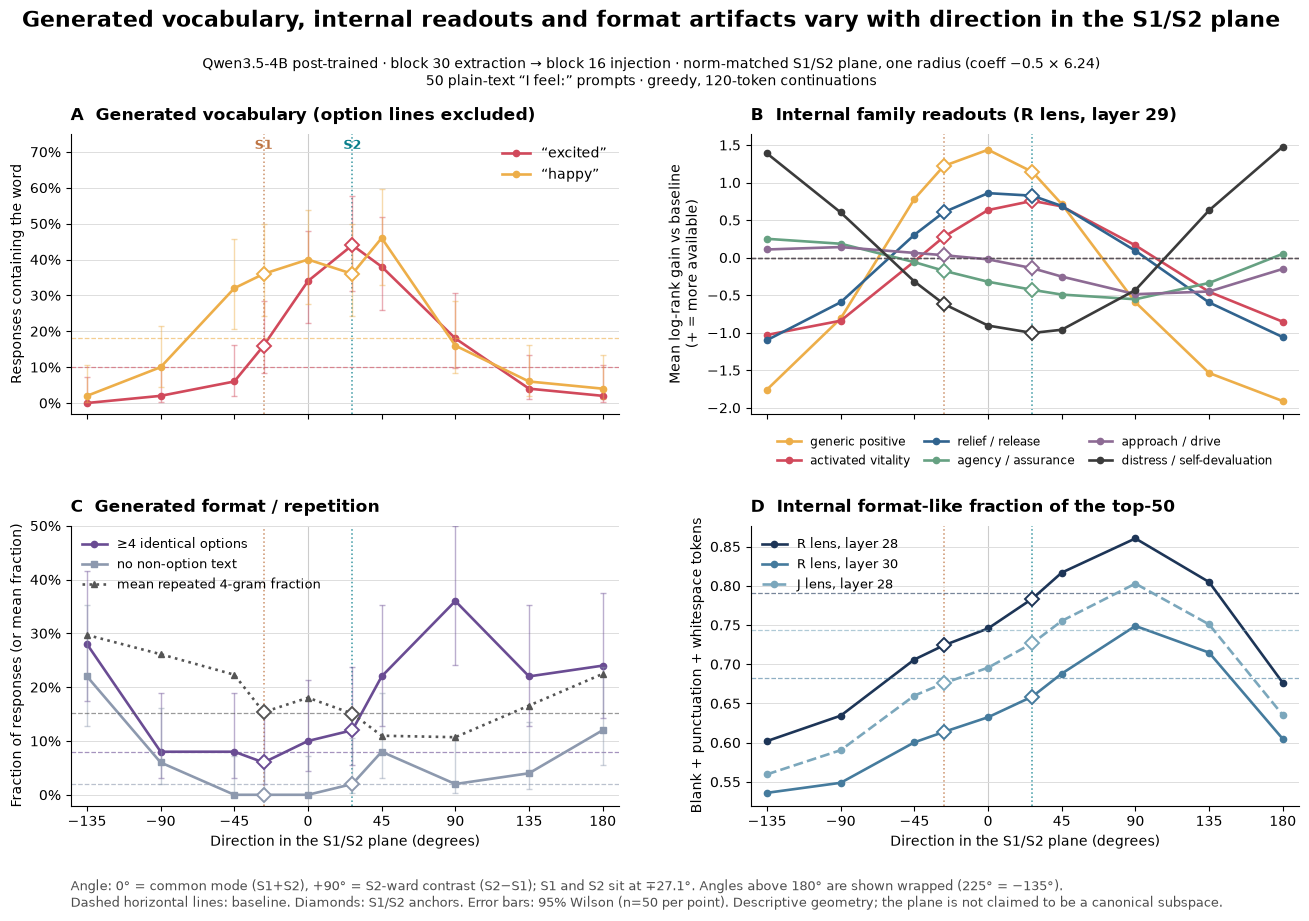

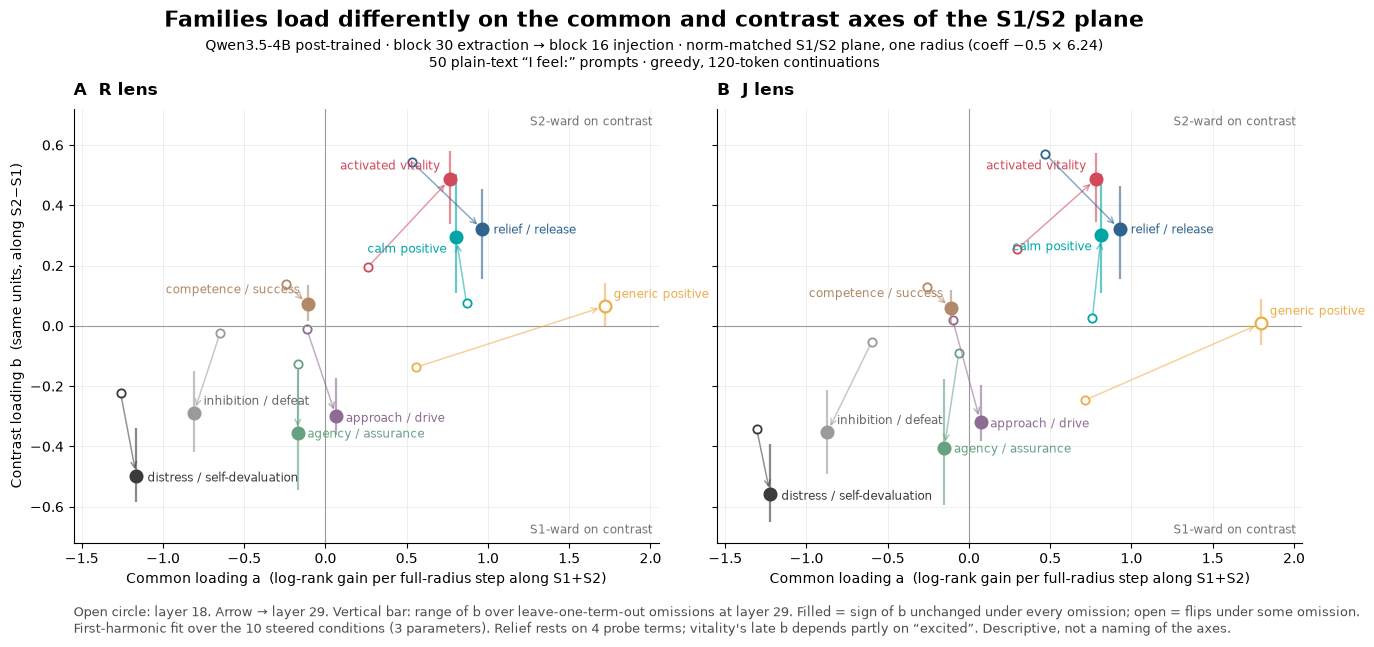

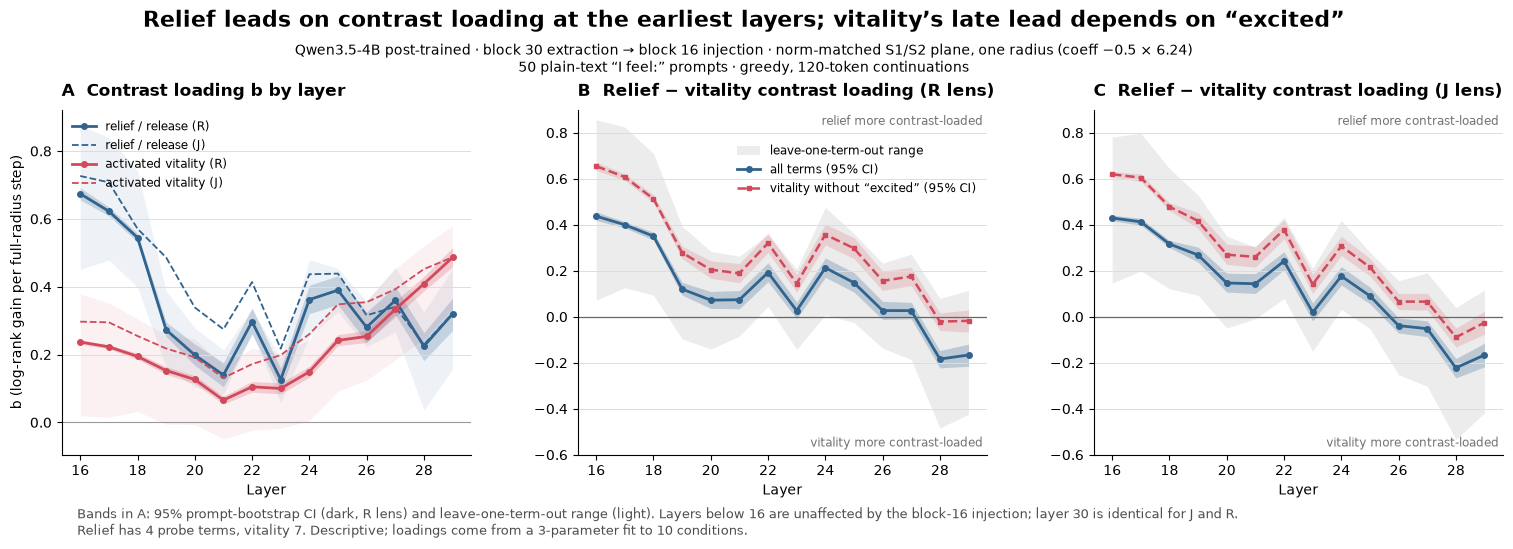

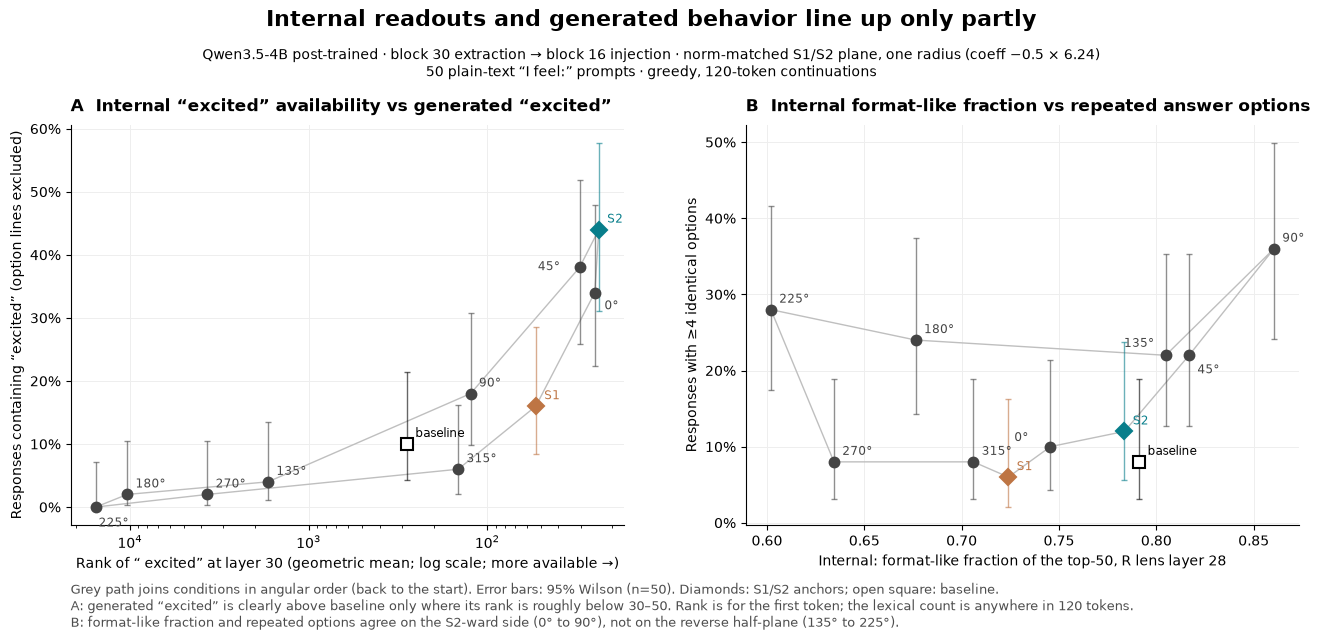

Saved figures + plot data in: runs/qwen35-4b-posttrained-s2/paper_protocol/figures
['plane_sweep_excited_rank_L30_plot_data.csv', 'plane_sweep_family_loadings.png', 'plane_sweep_family_loadings.svg', 'plane_sweep_family_loadings_plot_data.csv', 'plane_sweep_internal_vs_lexical.png', 'plane_sweep_internal_vs_lexical.svg', 'plane_sweep_internal_vs_lexical_plot_data.csv', 'plane_sweep_phenotype_map.png', 'plane_sweep_phenotype_map.svg', 'plane_sweep_phenotype_map_plot_data.csv', 'plane_sweep_relief_vs_vitality.png', 'plane_sweep_relief_vs_vitality.svg', 'plane_sweep_relief_vs_vitality_plot_data.csv']


In [40]:
# =====================================================================
# S1/S2 plane sweep -- chunk 5d: FIGURES (reads saved CSVs only; CPU).
#   1. phenotype map        generated vocab / internal families / degeneration / format-like
#   2. family loadings      common (a) vs contrast (b), layer 18 -> 29, LOTO-robust signs
#   3. relief vs vitality   contrast loading by layer + the crossover d, with/without `excited`
#   4. internal vs lexical  excited rank -> excited rate;  format-like -> repeated options
# Writes paper_protocol/figures/plane_sweep_<name>.{png,svg} + _plot_data.csv.
# Only one optional input needs the session: excited_rank_L30 (built once from
# the lens npz if `probe_terms` is defined; afterwards it is read from CSV).
# =====================================================================
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
plane_dir = paper_run_dir / "plane_sweep"
figure_dir = paper_run_dir / "figures"
figure_dir.mkdir(exist_ok=True)
PREFIX = "plane_sweep_"

spec = json.loads((plane_dir / "sweep_spec.json").read_text())
ANGLE = {c: v["angle_deg"] for c, v in spec["conditions"].items()}
STEERED = [c for c in ANGLE if c != "baseline"]
wrap = lambda a: (a % 360) - 360 if (a % 360) > 180 else (a % 360)     # (-180, 180]
XPOS = {c: wrap(ANGLE[c]) for c in STEERED}
ORDER = sorted(STEERED, key=lambda c: XPOS[c])
ANCHORS = {"S1_-0.5": ("S1", "#BE7544"), "S2_-0.5": ("S2", "#087E8B")}    # project colors
FORMAT_KINDS = ["blank_like", "punct_symbol", "whitespace"]                # frozen format_like

rates = pd.read_csv(plane_dir / "generations_bool_rates.csv")
means = pd.read_csv(plane_dir / "generations_numeric_means.csv", index_col=0)
fam = pd.read_csv(plane_dir / "family_condition_summary.csv")
fit = pd.read_csv(plane_dir / "family_harmonic_fit.csv")
loto = pd.read_csv(plane_dir / "family_loto_summary.csv")
cross = pd.read_csv(plane_dir / "relief_vs_vitality_contrast.csv")
kinds = pd.read_csv(plane_dir / "topk_kind_fractions.csv")

FAMC = {"generic_positive": "#EDAE49", "activated_vitality": "#D1495B", "relief_release": "#30638E",
        "calm_positive": "#00A6A6", "agency_assurance": "#66A182", "approach_drive": "#8D6B94",
        "distress_self_devaluation": "#3B3B3B", "inhibition_defeat": "#9A9A9A", "competence_success": "#B08968"}
FAMN = {"generic_positive": "generic positive", "activated_vitality": "activated vitality",
        "relief_release": "relief / release", "calm_positive": "calm positive",
        "agency_assurance": "agency / assurance", "approach_drive": "approach / drive",
        "distress_self_devaluation": "distress / self-devaluation", "inhibition_defeat": "inhibition / defeat",
        "competence_success": "competence / success"}
FOCUS = ["generic_positive", "activated_vitality", "relief_release",
         "agency_assurance", "approach_drive", "distress_self_devaluation"]
SUBTITLE = ("Qwen3.5-4B post-trained · block 30 extraction → block 16 injection · norm-matched S1/S2 plane, "
            "one radius (coeff −0.5 × 6.24)\n50 plain-text “I feel:” prompts · greedy, 120-token continuations")
ANGLE_NOTE = ("Angle: 0° = common mode (S1+S2), +90° = S2-ward contrast (S2−S1); S1 and S2 sit at ∓27.1°. "
              "Angles above 180° are shown wrapped (225° = −135°).")
RC = {"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "svg.fonttype": "none"}


def save(fig, name, rec):
    for ext in ["png", "svg"]:
        fig.savefig(figure_dir / f"{PREFIX}{name}.{ext}", dpi=180, bbox_inches="tight")
    pd.DataFrame(rec).to_csv(figure_dir / f"{PREFIX}{name}_plot_data.csv", index=False)
    plt.show()


def title(ax, t):
    ax.set_title(t, loc="left", fontweight="bold", pad=10)


def angle_axis(ax, label=False):
    ax.set_xticks([-135, -90, -45, 0, 45, 90, 135, 180])
    ax.set_xlim(-145, 190)
    ax.axvline(0, color="0.8", lw=0.8, zorder=0)
    for c, (nm, col) in ANCHORS.items():
        ax.axvline(XPOS[c], color=col, ls=":", lw=1.1, alpha=0.8, zorder=0)
    ax.grid(axis="y", color="#dddddd", lw=0.7)
    ax.set_axisbelow(True)
    if label:
        ax.set_xlabel("Direction in the S1/S2 plane (degrees)")


def profile(ax, values, color, label, rec, panel, ls="-", err=None, base=None, marker="o"):
    """values: dict condition -> y. err: dict condition -> (lo, hi). base: baseline y."""
    xs = [XPOS[c] for c in ORDER]
    ys = np.array([values[c] for c in ORDER], float)
    if err is not None:
        lo = np.array([err[c][0] for c in ORDER]); hi = np.array([err[c][1] for c in ORDER])
        ax.errorbar(xs, ys, yerr=[ys - lo, hi - ys], color=color, lw=0, elinewidth=1.0, capsize=2.2, alpha=0.45)
    ax.plot(xs, ys, color=color, ls=ls, lw=1.9, marker=marker, ms=4.5, label=label)
    for c in ANCHORS:                                            # anchors as larger open diamonds
        ax.plot([XPOS[c]], [values[c]], marker="D", ms=7, mfc="white", mec=color, mew=1.4, zorder=5)
    if base is not None:
        ax.axhline(base, color=color, ls="--", lw=0.9, alpha=0.6)
    for c in ORDER:
        rec.append({"panel": panel, "series": label, "condition": c, "angle_deg": ANGLE[c], "x": XPOS[c],
                    "y": values[c], "lo": None if err is None else err[c][0], "hi": None if err is None else err[c][1]})
    rec.append({"panel": panel, "series": label, "condition": "baseline", "angle_deg": None, "x": None,
                "y": base, "lo": None, "hi": None})


def lex(metric):
    s = rates[rates.metric == metric].set_index("condition")
    return ({c: s.loc[c, "rate"] for c in s.index}, {c: (s.loc[c, "wilson_lo"], s.loc[c, "wilson_hi"]) for c in s.index})


def famgain(family, lens, layer):
    s = fam[(fam.family == family) & (fam.lens == lens) & (fam.layer == layer)].set_index("condition")
    return {c: s.loc[c, "mean_log_rank_gain"] for c in s.index}


def format_like(lens, layer):
    s = kinds[(kinds.lens == lens) & (kinds.layer == layer) & kinds.token_kind.isin(FORMAT_KINDS)]
    return s.groupby("condition").fraction.sum().to_dict()


# ---------------------------------------------------------------------
# Figure 1: phenotype map
# ---------------------------------------------------------------------
rec = []
with plt.rc_context(RC):
    fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2), sharex=True)
    ax = axes[0, 0]
    for metric, col, lab in [("excited__non_option", "#D1495B", "“excited”"), ("happy__non_option", "#EDAE49", "“happy”")]:
        v, e = lex(metric)
        profile(ax, v, col, lab, rec, "A", err=e, base=v["baseline"])
    title(ax, "A  Generated vocabulary (option lines excluded)")
    ax.set_ylabel("Responses containing the word"); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(-0.03, 0.75)
    ax.legend(frameon=False, loc="upper right"); angle_axis(ax)
    for c, (nm, col) in ANCHORS.items():
        ax.text(XPOS[c], 0.735, nm, color=col, ha="center", va="top", fontsize=9, fontweight="bold")

    ax = axes[0, 1]
    for f in FOCUS:
        profile(ax, famgain(f, "R", 29), FAMC[f], FAMN[f], rec, "B", base=0.0)
    title(ax, "B  Internal family readouts (R lens, layer 29)")
    ax.set_ylabel("Mean log-rank gain vs baseline\n(+ = more available)")
    ax.legend(frameon=False, fontsize=8.5, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.04), columnspacing=1.2); angle_axis(ax)

    ax = axes[1, 0]
    v, e = lex("repeated_options"); profile(ax, v, "#6A4C93", "≥4 identical options", rec, "C", err=e, base=v["baseline"])
    v, e = lex("empty_non_option"); profile(ax, v, "#8D99AE", "no non-option text", rec, "C", err=e, base=v["baseline"], marker="s")
    r4 = means["repeat4"].to_dict()
    profile(ax, r4, "#555555", "mean repeated 4-gram fraction", rec, "C", ls=":", base=r4["baseline"], marker="^")
    title(ax, "C  Generated format / repetition")
    ax.set_ylabel("Fraction of responses (or mean fraction)"); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(-0.02, 0.5)
    ax.legend(frameon=False, fontsize=9, loc="upper left"); angle_axis(ax, label=True)

    ax = axes[1, 1]
    for (ln, ly), col, ls in [(("R", 28), "#1D3557", "-"), (("R", 30), "#457B9D", "-"), (("J", 28), "#7BA7BC", "--")]:
        v = format_like(ln, ly)
        profile(ax, v, col, f"{ln} lens, layer {ly}", rec, "D", ls=ls, base=v["baseline"])
    title(ax, "D  Internal format-like fraction of the top-50")
    ax.set_ylabel("Blank + punctuation + whitespace tokens"); ax.legend(frameon=False, fontsize=9, loc="upper left")
    angle_axis(ax, label=True)

    fig.suptitle("Generated vocabulary, internal readouts and format artifacts vary with direction in the S1/S2 plane",
                 fontsize=15.5, fontweight="bold", y=0.995)
    fig.text(0.5, 0.945, SUBTITLE, ha="center", va="top", fontsize=10)
    fig.text(0.07, 0.02, ANGLE_NOTE + "\nDashed horizontal lines: baseline. Diamonds: S1/S2 anchors. Error bars: 95% Wilson (n=50 per point). "
             "Descriptive geometry; the plane is not claimed to be a canonical subspace.",
             fontsize=9, color="0.3")
    fig.subplots_adjust(left=0.07, right=0.98, bottom=0.13, top=0.86, hspace=0.40, wspace=0.24)
    save(fig, "phenotype_map", rec)


# ---------------------------------------------------------------------
# Figure 2: family loadings (a = common, b = contrast), layer 18 -> 29, LOTO-robust sign at 29
# ---------------------------------------------------------------------
LAB_OFF = {  # per-family label offsets in points (dx, dy, ha)
    "generic_positive": (6, 6, "left"), "activated_vitality": (-7, 7, "right"), "relief_release": (8, -3, "left"),
    "calm_positive": (-7, -11, "right"), "agency_assurance": (7, -3, "left"), "approach_drive": (7, -4, "left"),
    "distress_self_devaluation": (8, -4, "left"), "inhibition_defeat": (7, 6, "left"), "competence_success": (-6, 8, "right")}
rec = []
with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.2), sharex=True, sharey=True)
    for ax, ln in zip(axes, ["R", "J"]):
        for f, col in FAMC.items():
            e18 = fit[(fit.lens == ln) & (fit.layer == 18) & (fit.family == f)].iloc[0]
            e29 = fit[(fit.lens == ln) & (fit.layer == 29) & (fit.family == f)].iloc[0]
            l29 = loto[(loto.lens == ln) & (loto.layer == 29) & (loto.family == f)].iloc[0]
            robust = l29.b_sign in ("+", "-")
            ax.annotate("", xy=(e29.a_common, e29.b_contrast), xytext=(e18.a_common, e18.b_contrast),
                        arrowprops=dict(arrowstyle="->", color=col, lw=1.1, alpha=0.55, shrinkA=3, shrinkB=5))
            ax.plot([e18.a_common], [e18.b_contrast], "o", ms=6, mfc="white", mec=col, mew=1.3)
            ax.vlines(e29.a_common, l29.b_min, l29.b_max, color=col, lw=1.6, alpha=0.6)
            ax.plot([e29.a_common], [e29.b_contrast], "o", ms=8.5, mfc=col if robust else "white", mec=col, mew=1.6, zorder=5)
            dx, dy, ha = LAB_OFF[f]
            ax.annotate(FAMN[f], (e29.a_common, e29.b_contrast), xytext=(dx, dy), textcoords="offset points",
                        fontsize=8.5, color=col if f != "inhibition_defeat" else "0.4", ha=ha)
            rec.append({"panel": ln, "family": f, "a_L18": e18.a_common, "b_L18": e18.b_contrast, "a_L29": e29.a_common,
                        "b_L29": e29.b_contrast, "b_L29_loto_min": l29.b_min, "b_L29_loto_max": l29.b_max, "b_L29_sign": l29.b_sign})
        ax.axhline(0, color="0.6", lw=0.8); ax.axvline(0, color="0.6", lw=0.8)
        ax.grid(color="#eeeeee", lw=0.7); ax.set_axisbelow(True)
        ax.set_xlim(-1.55, 2.05); ax.set_ylim(-0.72, 0.72)
        ax.set_xlabel("Common loading a  (log-rank gain per full-radius step along S1+S2)")
        title(ax, f"{'A' if ln == 'R' else 'B'}  {ln} lens")
        ax.text(0.99, 0.985, "S2-ward on contrast", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color="0.45")
        ax.text(0.99, 0.015, "S1-ward on contrast", transform=ax.transAxes, ha="right", va="bottom", fontsize=8.5, color="0.45")
    axes[0].set_ylabel("Contrast loading b  (same units, along S2−S1)")
    fig.suptitle("Families load differently on the common and contrast axes of the S1/S2 plane",
                 fontsize=15.5, fontweight="bold", y=1.0)
    fig.text(0.5, 0.955, SUBTITLE, ha="center", va="top", fontsize=10)
    fig.text(0.07, -0.005, "Open circle: layer 18. Arrow → layer 29. Vertical bar: range of b over leave-one-term-out omissions at layer 29. "
             "Filled = sign of b unchanged under every omission; open = flips under some omission.\n"
             "First-harmonic fit over the 10 steered conditions (3 parameters). Relief rests on 4 probe terms; "
             "vitality's late b depends partly on “excited”. Descriptive, not a naming of the axes.",
             fontsize=9, color="0.3")
    fig.subplots_adjust(left=0.07, right=0.98, bottom=0.14, top=0.84, wspace=0.10)
    save(fig, "family_loadings", rec)


# ---------------------------------------------------------------------
# Figure 3: relief vs vitality contrast loading by layer, and the crossover d
# ---------------------------------------------------------------------
rec = []
with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0))
    ax = axes[0]
    for f, col in [("relief_release", FAMC["relief_release"]), ("activated_vitality", FAMC["activated_vitality"])]:
        for ln, ls in [("R", "-"), ("J", "--")]:
            s = fit[(fit.lens == ln) & (fit.family == f) & (fit.layer >= 16) & (fit.layer <= 29)].sort_values("layer")
            ax.plot(s.layer, s.b_contrast, color=col, ls=ls, lw=2.0 if ln == "R" else 1.3, marker="o" if ln == "R" else None,
                    ms=4, label=f"{FAMN[f]} ({ln})")
            if ln == "R":
                ax.fill_between(s.layer, s.b_lo, s.b_hi, color=col, alpha=0.22, lw=0)
                l = loto[(loto.lens == "R") & (loto.family == f) & (loto.layer >= 16) & (loto.layer <= 29)].sort_values("layer")
                ax.fill_between(l.layer, l.b_min, l.b_max, color=col, alpha=0.08, lw=0)
            for _, r in s.iterrows():
                rec.append({"panel": "A", "family": f, "lens": ln, "layer": r.layer, "b": r.b_contrast, "b_lo": r.b_lo, "b_hi": r.b_hi})
    ax.axhline(0, color="0.6", lw=0.8)
    title(ax, "A  Contrast loading b by layer"); ax.set_xlabel("Layer"); ax.set_xticks(range(16, 30, 2)); ax.set_ylabel("b (log-rank gain per full-radius step)")
    ax.legend(frameon=False, fontsize=8.5, loc="upper left"); ax.grid(axis="y", color="#dddddd", lw=0.7)
    for ax, ln, tag in [(axes[1], "R", "B"), (axes[2], "J", "C")]:
        s = cross[(cross.lens == ln) & (cross.layer >= 16) & (cross.layer <= 29)].sort_values("layer")
        ax.fill_between(s.layer, s.loto_min, s.loto_max, color="0.5", alpha=0.15, lw=0, label="leave-one-term-out range")
        ax.fill_between(s.layer, s.d_lo, s.d_hi, color="#30638E", alpha=0.25, lw=0)
        ax.plot(s.layer, s.d_all, color="#30638E", lw=2.0, marker="o", ms=4, label="all terms (95% CI)")
        ax.fill_between(s.layer, s.dne_lo, s.dne_hi, color="#D1495B", alpha=0.18, lw=0)
        ax.plot(s.layer, s.d_no_excited, color="#D1495B", lw=1.8, ls="--", marker="s", ms=3.5, label="vitality without “excited” (95% CI)")
        ax.axhline(0, color="0.4", lw=0.9)
        title(ax, f"{tag}  Relief − vitality contrast loading ({ln} lens)"); ax.set_xlabel("Layer"); ax.set_xticks(range(16, 30, 2))
        ax.grid(axis="y", color="#dddddd", lw=0.7); ax.set_ylim(-0.6, 0.9)
        ax.text(0.99, 0.985, "relief more contrast-loaded", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color="0.45")
        ax.text(0.99, 0.015, "vitality more contrast-loaded", transform=ax.transAxes, ha="right", va="bottom", fontsize=8.5, color="0.45")
        for _, r in s.iterrows():
            rec.append({"panel": tag, "lens": ln, "layer": r.layer, "d_all": r.d_all, "d_lo": r.d_lo, "d_hi": r.d_hi,
                        "d_no_excited": r.d_no_excited, "dne_lo": r.dne_lo, "dne_hi": r.dne_hi,
                        "loto_min": r.loto_min, "loto_max": r.loto_max, "loto_frac_pos": r.loto_frac_pos})
    axes[1].legend(frameon=False, fontsize=8.5, loc="upper right", bbox_to_anchor=(1.0, 0.93)); axes[2].sharey(axes[1])
    fig.suptitle("Relief leads on contrast loading at the earliest layers; vitality’s late lead depends on “excited”",
                 fontsize=15.5, fontweight="bold", y=1.03)
    fig.text(0.5, 0.965, SUBTITLE, ha="center", va="top", fontsize=10)
    fig.text(0.07, -0.02, "Bands in A: 95% prompt-bootstrap CI (dark, R lens) and leave-one-term-out range (light). "
             "Layers below 16 are unaffected by the block-16 injection; layer 30 is identical for J and R.\n"
             "Relief has 4 probe terms, vitality 7. Descriptive; loadings come from a 3-parameter fit to 10 conditions.",
             fontsize=9, color="0.3")
    fig.subplots_adjust(left=0.06, right=0.99, bottom=0.14, top=0.83, wspace=0.26)
    save(fig, "relief_vs_vitality", rec)


# ---------------------------------------------------------------------
# Figure 4: internal readout -> generated behavior (11 conditions each)
# ---------------------------------------------------------------------
rank_csv = figure_dir / f"{PREFIX}excited_rank_L30_plot_data.csv"
if not rank_csv.exists() and "probe_terms" in globals():          # built once from the lens npz
    ex = int(np.flatnonzero(probe_terms.term.to_numpy() == "excited")[0])
    li, ki = spec["lens"]["layers"].index(30), spec["lens"]["lens_order"].index("R")
    out = []
    for c in spec["conditions"]:
        with np.load(plane_dir / "lens" / f"{c}.npz") as z:
            r = z["rank"][:, li, ki, ex].astype(float)
        out.append({"condition": c, "geo_mean_rank": float(np.exp(np.log(r).mean())), "median_rank": float(np.median(r))})
    pd.DataFrame(out).to_csv(rank_csv, index=False)
have_rank = rank_csv.exists()

rec = []
with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.8))

    def scatter(ax, xs, ys, err, panel, base_label="baseline", offs=None):
        offs = offs or {}
        conds = ["baseline"] + STEERED
        ax.plot([xs[c] for c in ORDER + [ORDER[0]]], [ys[c] for c in ORDER + [ORDER[0]]], color="0.75", lw=1.0, zorder=1)
        for c in conds:
            if c == "baseline":
                col, mk, ms = "black", "s", 8
            elif c in ANCHORS:
                col, mk, ms = ANCHORS[c][1], "D", 8
            else:
                col, mk, ms = "#444444", "o", 7
            ax.errorbar([xs[c]], [ys[c]], yerr=[[ys[c] - err[c][0]], [err[c][1] - ys[c]]], color=col, capsize=2, lw=0, elinewidth=1, alpha=0.6)
            ax.plot([xs[c]], [ys[c]], mk, ms=ms, mfc="white" if c == "baseline" else col, mec=col, mew=1.5, zorder=5)
            lab = base_label if c == "baseline" else (ANCHORS[c][0] if c in ANCHORS else f"{int(ANGLE[c])}°")
            ax.annotate(lab, (xs[c], ys[c]), xytext=offs.get(c, (6, 5)), textcoords="offset points", fontsize=8.5, color=col)
            rec.append({"panel": panel, "condition": c, "angle_deg": ANGLE[c], "x": xs[c], "y": ys[c], "y_lo": err[c][0], "y_hi": err[c][1]})

    ax = axes[0]
    v, e = lex("excited__non_option")
    if have_rank:
        rk = pd.read_csv(rank_csv).set_index("condition").geo_mean_rank.to_dict()
        scatter(ax, rk, v, e, "A", offs={"plane_045": (-30, -2), "plane_000": (7, -12), "plane_225": (2, -14)})
        ax.set_xscale("log"); ax.invert_xaxis()
        ax.set_xlabel("Rank of “ excited” at layer 30 (geometric mean; log scale; more available →)")
    else:
        vg = famgain("activated_vitality", "R", 29); vg["baseline"] = 0.0
        scatter(ax, vg, v, e, "A")
        ax.set_xlabel("Internal: activated-vitality family gain, R lens layer 29  (more available →)")
    title(ax, "A  Internal “excited” availability vs generated “excited”")
    ax.set_ylabel("Responses containing “excited” (option lines excluded)"); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(color="#eeeeee", lw=0.7); ax.set_axisbelow(True)

    ax = axes[1]
    v, e = lex("repeated_options")
    fl = format_like("R", 28)
    scatter(ax, fl, v, e, "B", offs={"plane_135": (-30, 6), "plane_045": (6, -13), "plane_000": (-26, 4)})
    title(ax, "B  Internal format-like fraction vs repeated answer options")
    ax.set_xlabel("Internal: format-like fraction of the top-50, R lens layer 28"); ax.set_ylabel("Responses with ≥4 identical options")
    ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.grid(color="#eeeeee", lw=0.7); ax.set_axisbelow(True)

    fig.suptitle("Internal readouts and generated behavior line up only partly", fontsize=15.5, fontweight="bold", y=1.03)
    fig.text(0.5, 0.965, SUBTITLE, ha="center", va="top", fontsize=10)
    fig.text(0.07, -0.035, "Grey path joins conditions in angular order (back to the start). Error bars: 95% Wilson (n=50). Diamonds: S1/S2 anchors; open square: baseline.\n"
             "A: generated “excited” is clearly above baseline only where its rank is roughly below 30–50. Rank is for the first token; the lexical count is anywhere in 120 tokens.\n"
             "B: format-like fraction and repeated options agree on the S2-ward side (0° to 90°), not on the reverse half-plane (135° to 225°).",
             fontsize=9, color="0.3")
    fig.subplots_adjust(left=0.07, right=0.98, bottom=0.14, top=0.83, wspace=0.22)
    save(fig, "internal_vs_lexical", rec)

print("Saved figures + plot data in:", figure_dir)
print(sorted(p.name for p in figure_dir.glob(f"{PREFIX}*")))

gate OK: raw family logit deltas identical to 5a's family_gain.npz

first-harmonic peak angle / amplitude of each family profile, R lens layer 29
(peak = angle of maximum; centered = probe-set-mean logit shift removed per prompt)
                          rank gain (peak°/amp) logit (peak°/amp) centered logit  r(rank,logit)  r(rank,centered)
generic_positive                       2 / 1.72          3 / 1.27       5 / 1.23           1.00              1.00
activated_vitality                    32 / 0.91         34 / 0.79      37 / 0.79           1.00              0.99
relief_release                        18 / 1.02         22 / 0.94      25 / 0.92           1.00              0.99
agency_assurance                     244 / 0.40        242 / 0.37     234 / 0.36           0.99              0.97
approach_drive                       282 / 0.31        264 / 0.30     256 / 0.27           0.94              0.85
distress_self_devaluation            203 / 1.27        203 / 1.30     201 / 1.32      

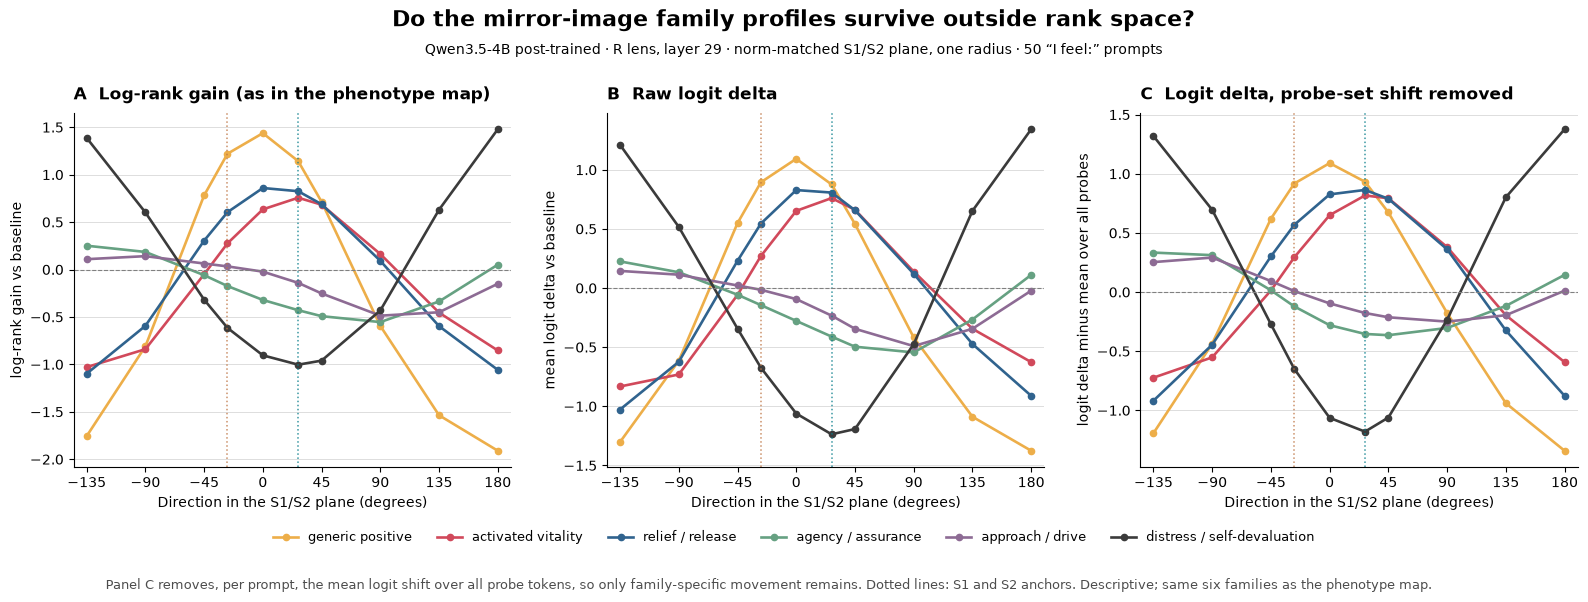

FileNotFoundError: [Errno 2] No such file or directory: 'pain-axis-source/datasets/3.1_pain_and_control_datasets.json'

In [41]:
# =====================================================================
# S1/S2 plane sweep -- chunk 5e
#   A. Are panel-B's mirror-image family profiles a rank-competition artifact?
#      Refit the family profiles in raw logit space and in logit space with the
#      shared probe-set shift removed.                       (CPU, lens npz only)
#   B. What do S1, S2, common and contrast READ?  Project the paper's dataset
#      panel (block 30, final token) onto all four.          (needs hf, tok)
# Run in the lens session after 5a. Needs: probe_terms, PSYCH_VOCAB;
# for B also hf, tok, s1_vector, s2_vector and pain-axis-source/ (as in the init notebook).
# =====================================================================
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
plane_dir = paper_run_dir / "plane_sweep"
figure_dir = paper_run_dir / "figures"
figure_dir.mkdir(exist_ok=True)

SHOW = [("R", 29), ("R", 22)]
FOCUS = ["generic_positive", "activated_vitality", "relief_release",
         "agency_assurance", "approach_drive", "distress_self_devaluation"]
FAMC = {"generic_positive": "#EDAE49", "activated_vitality": "#D1495B", "relief_release": "#30638E",
        "agency_assurance": "#66A182", "approach_drive": "#8D6B94", "distress_self_devaluation": "#3B3B3B"}
FAMN = {"generic_positive": "generic positive", "activated_vitality": "activated vitality",
        "relief_release": "relief / release", "agency_assurance": "agency / assurance",
        "approach_drive": "approach / drive", "distress_self_devaluation": "distress / self-devaluation"}
ANCHOR_COL = {"S1_-0.5": "#BE7544", "S2_-0.5": "#087E8B"}
sha = lambda s: hashlib.sha256(s.encode()).hexdigest()


# =====================================================================
# A. rank gain vs raw logit delta vs probe-set-centered logit delta
# =====================================================================
spec_text = (plane_dir / "sweep_spec.json").read_text()
spec = json.loads(spec_text)
spec_hash = sha(spec_text)
layers, LENS = spec["lens"]["layers"], spec["lens"]["lens_order"]
cond_names = list(spec["conditions"])
steered = [c for c in cond_names if c != "baseline"]
angle = np.array([spec["conditions"][c]["angle_deg"] for c in steered], float)
assert sha(probe_terms[["family", "term", "token_id"]].to_csv(index=False)) == spec["lens"]["probe_terms_sha256"]

arrs = {}
for c in cond_names:
    with np.load(plane_dir / "lens" / f"{c}.npz") as z:
        assert str(z["spec_sha256"]) == spec_hash, c
        arrs[c] = {"rank": z["rank"], "logit": z["logit"].astype(float)}
fam_names = list(PSYCH_VOCAB)
fam_cols = [np.flatnonzero(probe_terms.family.to_numpy() == f) for f in fam_names]
P, L, F = arrs["baseline"]["rank"].shape[0], len(layers), len(fam_names)

M = {k: np.zeros((len(steered), L, 2, F)) for k in ["rank_gain", "logit_delta", "logit_delta_centered"]}
fam_logit = np.zeros((len(steered), P, L, 2, F))
for ci, c in enumerate(steered):
    G = np.log(arrs["baseline"]["rank"] / arrs[c]["rank"])                    # [P, L, 2, K]
    D = arrs[c]["logit"] - arrs["baseline"]["logit"]
    shift = D.mean(-1, keepdims=True)                                         # shared shift over all probes
    for fi, cols in enumerate(fam_cols):
        M["rank_gain"][ci, ..., fi] = G[..., cols].mean(-1).mean(0)
        fam_logit[ci, ..., fi] = D[..., cols].mean(-1)
        M["logit_delta"][ci, ..., fi] = fam_logit[ci, ..., fi].mean(0)
        M["logit_delta_centered"][ci, ..., fi] = (D[..., cols] - shift).mean(-1).mean(0)

# gate: raw family logit deltas equal 5a's saved array
with np.load(plane_dir / "family_gain.npz") as z:
    assert list(z["steered"]) == steered and list(z["families"]) == fam_names
    assert np.abs(z["logit_delta"].astype(float) - fam_logit).max() < 1e-4
print("gate OK: raw family logit deltas identical to 5a's family_gain.npz")

th = np.radians(angle)
X = np.c_[np.ones_like(th), np.cos(th), np.sin(th)]
pinvX = np.linalg.pinv(X)
li_, ki_, fi_ = np.unravel_index(np.arange(L * 2 * F), (L, 2, F))
out = pd.DataFrame({"lens": np.array(LENS)[ki_], "layer": np.array(layers)[li_], "family": np.array(fam_names)[fi_]})
for name, arr in M.items():
    coef = np.tensordot(pinvX, arr, axes=([1], [0]))                          # [3, L, 2, F]
    out[f"{name}_a"], out[f"{name}_b"] = coef[1].ravel(), coef[2].ravel()
    out[f"{name}_amp"] = np.hypot(coef[1], coef[2]).ravel()
    out[f"{name}_peak_deg"] = (np.degrees(np.arctan2(coef[2], coef[1])) % 360).ravel()

def corr_over_conditions(a, b):                                               # [cond, L, 2, F] -> [L, 2, F]
    a = a - a.mean(0); b = b - b.mean(0)
    return (a * b).sum(0) / np.sqrt((a ** 2).sum(0) * (b ** 2).sum(0) + 1e-30)

out["corr_rank_vs_logit"] = corr_over_conditions(M["rank_gain"], M["logit_delta"]).ravel()
out["corr_rank_vs_centered"] = corr_over_conditions(M["rank_gain"], M["logit_delta_centered"]).ravel()
out.to_csv(plane_dir / "family_logit_vs_rank_fit.csv", index=False)

fam_order = FOCUS + [f for f in fam_names if f not in FOCUS]
for ln, ly in SHOW:
    t = out[(out.lens == ln) & (out.layer == ly)].set_index("family").loc[fam_order]
    show = pd.DataFrame({
        "rank gain (peak°/amp)": [f"{t.loc[f, 'rank_gain_peak_deg']:4.0f} / {t.loc[f, 'rank_gain_amp']:.2f}" for f in fam_order],
        "logit (peak°/amp)": [f"{t.loc[f, 'logit_delta_peak_deg']:4.0f} / {t.loc[f, 'logit_delta_amp']:.2f}" for f in fam_order],
        "centered logit": [f"{t.loc[f, 'logit_delta_centered_peak_deg']:4.0f} / {t.loc[f, 'logit_delta_centered_amp']:.2f}" for f in fam_order],
        "r(rank,logit)": t.corr_rank_vs_logit.round(2).values, "r(rank,centered)": t.corr_rank_vs_centered.round(2).values,
    }, index=fam_order)
    print(f"\nfirst-harmonic peak angle / amplitude of each family profile, {ln} lens layer {ly}"
          f"\n(peak = angle of maximum; centered = probe-set-mean logit shift removed per prompt)")
    print(show.to_string())

wrap = lambda a: (a % 360) - 360 if (a % 360) > 180 else (a % 360)
xs = np.array([wrap(a) for a in angle]); order = np.argsort(xs)
RC = {"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "svg.fonttype": "none"}
ln, ly = "R", 29
ki, li = LENS.index(ln), layers.index(ly)
rec = []
with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharex=True)
    for ax, (key, ttl, yl) in zip(axes, [("rank_gain", "A  Log-rank gain (as in the phenotype map)", "log-rank gain vs baseline"),
                                          ("logit_delta", "B  Raw logit delta", "mean logit delta vs baseline"),
                                          ("logit_delta_centered", "C  Logit delta, probe-set shift removed", "logit delta minus mean over all probes")]):
        for f in FOCUS:
            y = M[key][:, li, ki, fam_names.index(f)]
            ax.plot(xs[order], y[order], color=FAMC[f], lw=1.9, marker="o", ms=4.5, label=FAMN[f])
            for k, c in enumerate(steered):
                rec.append({"panel": key, "family": f, "condition": c, "x": xs[k], "y": y[k]})
        for c, col in ANCHOR_COL.items():
            ax.axvline(wrap(spec["conditions"][c]["angle_deg"]), color=col, ls=":", lw=1.1, alpha=0.8)
        ax.axhline(0, color="0.5", lw=0.8, ls="--")
        ax.set_title(ttl, loc="left", fontweight="bold", pad=10); ax.set_ylabel(yl)
        ax.set_xticks([-135, -90, -45, 0, 45, 90, 135, 180]); ax.set_xlim(-145, 190)
        ax.grid(axis="y", color="#dddddd", lw=0.7); ax.set_axisbelow(True)
        ax.set_xlabel("Direction in the S1/S2 plane (degrees)")
    h_, l_ = axes[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="lower center", ncol=6, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Do the mirror-image family profiles survive outside rank space?", fontsize=15.5, fontweight="bold", y=1.03)
    fig.text(0.5, 0.965, "Qwen3.5-4B post-trained · R lens, layer 29 · norm-matched S1/S2 plane, one radius · 50 “I feel:” prompts",
             ha="center", va="top", fontsize=10)
    fig.text(0.07, -0.085, "Panel C removes, per prompt, the mean logit shift over all probe tokens, so only family-specific movement remains. "
             "Dotted lines: S1 and S2 anchors. Descriptive; same six families as the phenotype map.", fontsize=9, color="0.3")
    fig.subplots_adjust(left=0.05, right=0.99, bottom=0.15, top=0.83, wspace=0.22)
    for ext in ["png", "svg"]:
        fig.savefig(figure_dir / f"plane_sweep_family_logit_vs_rank.{ext}", dpi=180, bbox_inches="tight")
    plt.show()
pd.DataFrame(rec).to_csv(figure_dir / "plane_sweep_family_logit_vs_rank_plot_data.csv", index=False)


# =====================================================================
# B. Reading side: the paper's dataset panel projected onto S1, S2, common, contrast
#    Same convention as the init notebook: left padding, batch 4, block-30 output
#    (hidden_states[31]) at the final token, z-scored against the S2_1P source set.
# =====================================================================
BLOCK, BATCH = 30, 4
if "hf" not in globals() or "tok" not in globals():
    print("\n[B skipped: hf/tok not in this session]")
else:
    import torch
    from tqdm.auto import tqdm

    source_repo = Path("pain-axis-source")
    dfiles = [source_repo / "datasets/3.1_pain_and_control_datasets.json", source_repo / "datasets/3.1_sadness_dataset.json"]
    panel = {}
    for f in dfiles:
        panel.update(json.loads(f.read_text())["datasets"])
    print("\ndataset files:", {f.name: sha(f.read_text())[:12] for f in dfiles}, "| sets:", list(panel))

    saved = torch.load(plane_dir / "plane_vectors.pt", map_location="cpu", weights_only=True)
    unit = lambda t: (t.double() / t.double().norm()).float()
    dirs = {"S2": unit(s2_vector), "S1": unit(s1_vector),
            "common": saved["common_unit"].float(), "contrast": saved["contrast_unit"].float()}
    Dmat = torch.stack(list(dirs.values()))                                            # [4, H]

    old_side, old_pad = tok.padding_side, tok.pad_token
    tok.padding_side = "left"
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    rows = []
    try:
        for name, d in panel.items():
            sents = d["sentences"]
            for start in tqdm(range(0, len(sents), BATCH), desc=name, leave=False):
                batch = sents[start:start + BATCH]
                inputs = tok([r["prompt"] for r in batch], padding=True, return_tensors="pt").to(hf.device)
                with torch.inference_mode():
                    o = hf(**inputs, output_hidden_states=True, use_cache=False, return_dict=True)
                h = o.hidden_states[BLOCK + 1][:, -1, :].float().cpu()
                for r, s in zip(batch, (h @ Dmat.T).tolist()):
                    rows.append({"dataset": name, "category": r["category"], "set": r.get("set"), "prompt": r["prompt"],
                                 **{f"proj_{k}": v for k, v in zip(dirs, s)}})
    finally:
        tok.padding_side, tok.pad_token = old_side, old_pad

    proj = pd.DataFrame(rows)
    ref = proj[proj.dataset == "S2_1P"]
    for k in dirs:
        proj[f"z_{k}"] = (proj[f"proj_{k}"] - ref[f"proj_{k}"].mean()) / ref[f"proj_{k}"].std(ddof=0)
    proj["base"] = proj.dataset.str.rsplit("_", n=1).str[0]
    proj["person"] = proj.dataset.str.rsplit("_", n=1).str[1]
    proj.to_csv(plane_dir / "dataset_panel_projections.csv", index=False)

    # gate: S2 z-scores reproduce the committed neighborhood_block30.csv
    nb = pd.read_csv("runs/qwen35-4b-posttrained-s2/neighborhood_block30.csv")
    worst, rr = 0.0, 1.0
    for name in nb.dataset.unique():
        a, b = nb[nb.dataset == name].reset_index(drop=True), proj[proj.dataset == name].reset_index(drop=True)
        assert (a.prompt == b.prompt).all(), name
        worst = max(worst, float(np.abs(a.z_s2 - b.z_S2).max())); rr = min(rr, float(np.corrcoef(a.z_s2, b.z_S2)[0, 1]))
    print(f"gate: S2 z vs committed neighborhood_block30.csv over {nb.dataset.nunique()} sets: max |dz| {worst:.2e}, min r {rr:.6f}")
    assert worst < 0.02 and rr > 0.9999

    z1 = proj[proj.person == "1P"]
    ds = z1.groupby("base")[["z_S2", "z_S1", "z_common", "z_contrast"]].mean().round(2)
    ds.insert(0, "n", z1.groupby("base").size())
    print("\ndataset-level mean z (1P; reference = S2_1P source set, per direction):")
    print(ds.to_string())

    z3 = proj[proj.person == "3P"]
    tab = z1.groupby(["base", "category"]).agg(n=("z_S2", "size"), S2=("z_S2", "mean"), S1=("z_S1", "mean"),
                                                 common=("z_common", "mean"), contrast=("z_contrast", "mean"),
                                                 example=("prompt", "first"))
    tab["S2 3P-1P"] = z3.groupby(["base", "category"]).z_S2.mean().reindex(tab.index) - tab.S2
    tab["example"] = tab.example.str.replace(r"\s*I feel:$", "", regex=True).str.slice(0, 46)
    tab.round(2).to_csv(plane_dir / "dataset_panel_category_means_1P.csv")
    for base in ["S2", "Arousal", "Random", "Numb", "SD_sadness", "ControlSupplement"]:
        if base in tab.index.get_level_values(0):
            t = tab.loc[base].sort_values("S2", ascending=False).round(2)
            print(f"\n[{base}] category means, 1P (z)  -  sorted by S2")
            print(t.to_string())

    cat = tab.reset_index()
    cat = cat[cat.base.isin(["S2", "Arousal", "Random", "Numb", "SD_sadness", "ControlSupplement"])]
    print("\nacross categories (n=%d): r(common, contrast) = %+.2f | r(S2, common) = %+.2f | r(S2, contrast) = %+.2f"
          % (len(cat), np.corrcoef(cat.common, cat.contrast)[0, 1], np.corrcoef(cat.S2, cat.common)[0, 1],
             np.corrcoef(cat.S2, cat.contrast)[0, 1]))
    print("saved: dataset_panel_projections.csv, dataset_panel_category_means_1P.csv")

gate OK: raw family logit deltas identical to 5a's family_gain.npz

first-harmonic peak angle / amplitude of each family profile, R lens layer 29
(peak = angle of maximum; centered = probe-set-mean logit shift removed per prompt)
                          rank gain (peak°/amp) logit (peak°/amp) centered logit  r(rank,logit)  r(rank,centered)
generic_positive                       2 / 1.72          3 / 1.27       5 / 1.23           1.00              1.00
activated_vitality                    32 / 0.91         34 / 0.79      37 / 0.79           1.00              0.99
relief_release                        18 / 1.02         22 / 0.94      25 / 0.92           1.00              0.99
agency_assurance                     244 / 0.40        242 / 0.37     234 / 0.36           0.99              0.97
approach_drive                       282 / 0.31        264 / 0.30     256 / 0.27           0.94              0.85
distress_self_devaluation            203 / 1.27        203 / 1.30     201 / 1.32      

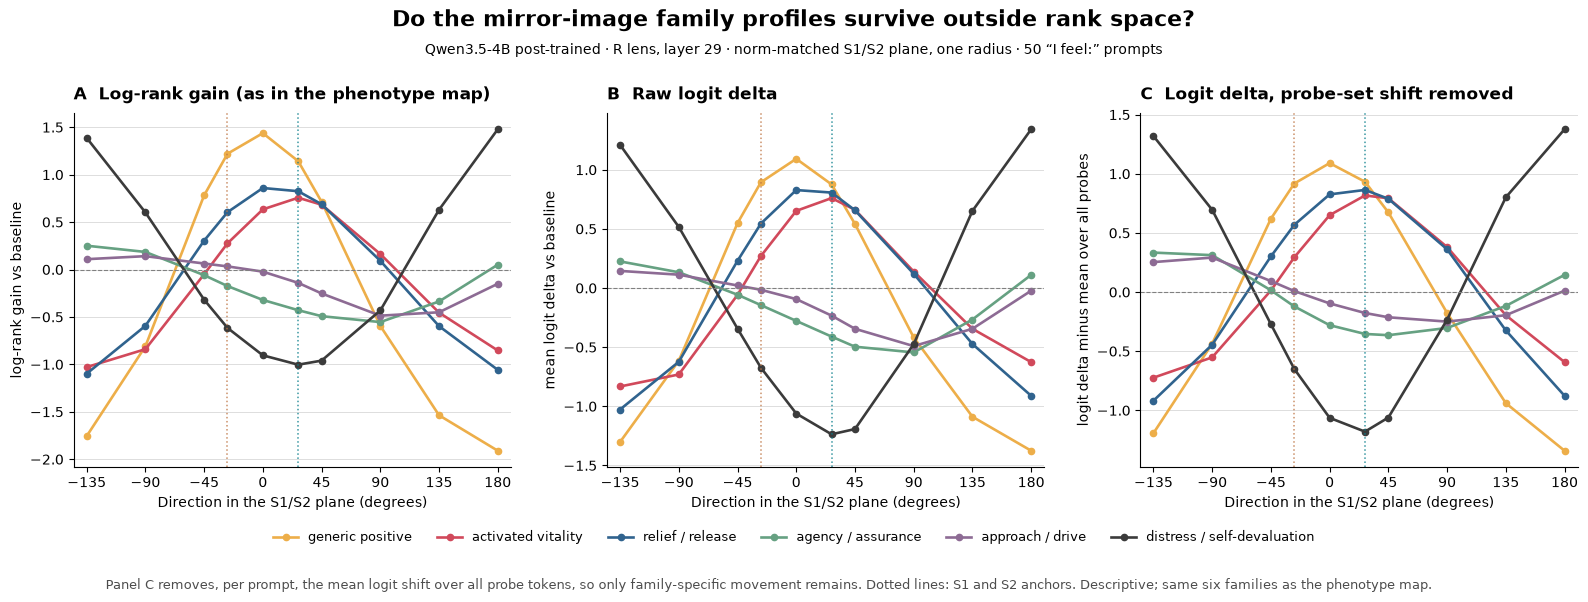

using dataset repo: /mnt/c/Users/bfabe/workspace/pain-axis-source

dataset files: {'3.1_pain_and_control_datasets.json': '2c3712b4b096', '3.1_sadness_dataset.json': '950ea2c5cab2'} | sets: ['S1_1P', 'S1_3P', 'S2_1P', 'S2_3P', 'Random_1P', 'Random_3P', 'Arousal_1P', 'Arousal_3P', 'Numb_1P', 'Numb_3P', 'ControlSupplement_1P', 'SD_sadness_1P', 'SD_sadness_3P']


gate: S2 z vs committed neighborhood_block30.csv over 4 sets: max |dz| 8.64e-07, min r 1.000000

dataset-level mean z (1P; reference = S2_1P source set, per direction):
                     n  z_S2  z_S1  z_common  z_contrast
base                                                    
Arousal            200 -0.46 -0.74     -0.62        0.18
ControlSupplement  100  0.17  0.23      0.21       -0.01
Numb               100  0.37  0.52      0.47       -0.06
Random             200 -0.66 -0.54     -0.65       -0.36
S1                 200 -0.23 -0.47     -0.36        0.22
S2                 200  0.00 -0.00      0.00       -0.00
SD_sadness         100  0.52  0.05      0.33        0.73

[S2] category means, 1P (z)  -  sorted by S2
           n    S2    S1  common  contrast                                         example  S2 3P-1P
category                                                                                            
A5        20  1.18  0.91    1.13      0.71     The problem defeats me 

In [42]:
# =====================================================================
# S1/S2 plane sweep -- chunk 5e
#   A. Are panel-B's mirror-image family profiles a rank-competition artifact?
#      Refit the family profiles in raw logit space and in logit space with the
#      shared probe-set shift removed.                       (CPU, lens npz only)
#   B. What do S1, S2, common and contrast READ?  Project the paper's dataset
#      panel (block 30, final token) onto all four.          (needs hf, tok)
# Run in the lens session after 5a. Needs: probe_terms, PSYCH_VOCAB;
# for B also hf, tok, s1_vector, s2_vector and pain-axis-source/ (found in ./ or ../).
# =====================================================================
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
plane_dir = paper_run_dir / "plane_sweep"
figure_dir = paper_run_dir / "figures"
figure_dir.mkdir(exist_ok=True)

SHOW = [("R", 29), ("R", 22)]
FOCUS = ["generic_positive", "activated_vitality", "relief_release",
         "agency_assurance", "approach_drive", "distress_self_devaluation"]
FAMC = {"generic_positive": "#EDAE49", "activated_vitality": "#D1495B", "relief_release": "#30638E",
        "agency_assurance": "#66A182", "approach_drive": "#8D6B94", "distress_self_devaluation": "#3B3B3B"}
FAMN = {"generic_positive": "generic positive", "activated_vitality": "activated vitality",
        "relief_release": "relief / release", "agency_assurance": "agency / assurance",
        "approach_drive": "approach / drive", "distress_self_devaluation": "distress / self-devaluation"}
ANCHOR_COL = {"S1_-0.5": "#BE7544", "S2_-0.5": "#087E8B"}
sha = lambda s: hashlib.sha256(s.encode()).hexdigest()


# =====================================================================
# A. rank gain vs raw logit delta vs probe-set-centered logit delta
# =====================================================================
spec_text = (plane_dir / "sweep_spec.json").read_text()
spec = json.loads(spec_text)
spec_hash = sha(spec_text)
layers, LENS = spec["lens"]["layers"], spec["lens"]["lens_order"]
cond_names = list(spec["conditions"])
steered = [c for c in cond_names if c != "baseline"]
angle = np.array([spec["conditions"][c]["angle_deg"] for c in steered], float)
assert sha(probe_terms[["family", "term", "token_id"]].to_csv(index=False)) == spec["lens"]["probe_terms_sha256"]

arrs = {}
for c in cond_names:
    with np.load(plane_dir / "lens" / f"{c}.npz") as z:
        assert str(z["spec_sha256"]) == spec_hash, c
        arrs[c] = {"rank": z["rank"], "logit": z["logit"].astype(float)}
fam_names = list(PSYCH_VOCAB)
fam_cols = [np.flatnonzero(probe_terms.family.to_numpy() == f) for f in fam_names]
P, L, F = arrs["baseline"]["rank"].shape[0], len(layers), len(fam_names)

M = {k: np.zeros((len(steered), L, 2, F)) for k in ["rank_gain", "logit_delta", "logit_delta_centered"]}
fam_logit = np.zeros((len(steered), P, L, 2, F))
for ci, c in enumerate(steered):
    G = np.log(arrs["baseline"]["rank"] / arrs[c]["rank"])                    # [P, L, 2, K]
    D = arrs[c]["logit"] - arrs["baseline"]["logit"]
    shift = D.mean(-1, keepdims=True)                                         # shared shift over all probes
    for fi, cols in enumerate(fam_cols):
        M["rank_gain"][ci, ..., fi] = G[..., cols].mean(-1).mean(0)
        fam_logit[ci, ..., fi] = D[..., cols].mean(-1)
        M["logit_delta"][ci, ..., fi] = fam_logit[ci, ..., fi].mean(0)
        M["logit_delta_centered"][ci, ..., fi] = (D[..., cols] - shift).mean(-1).mean(0)

# gate: raw family logit deltas equal 5a's saved array
with np.load(plane_dir / "family_gain.npz") as z:
    assert list(z["steered"]) == steered and list(z["families"]) == fam_names
    assert np.abs(z["logit_delta"].astype(float) - fam_logit).max() < 1e-4
print("gate OK: raw family logit deltas identical to 5a's family_gain.npz")

th = np.radians(angle)
X = np.c_[np.ones_like(th), np.cos(th), np.sin(th)]
pinvX = np.linalg.pinv(X)
li_, ki_, fi_ = np.unravel_index(np.arange(L * 2 * F), (L, 2, F))
out = pd.DataFrame({"lens": np.array(LENS)[ki_], "layer": np.array(layers)[li_], "family": np.array(fam_names)[fi_]})
for name, arr in M.items():
    coef = np.tensordot(pinvX, arr, axes=([1], [0]))                          # [3, L, 2, F]
    out[f"{name}_a"], out[f"{name}_b"] = coef[1].ravel(), coef[2].ravel()
    out[f"{name}_amp"] = np.hypot(coef[1], coef[2]).ravel()
    out[f"{name}_peak_deg"] = (np.degrees(np.arctan2(coef[2], coef[1])) % 360).ravel()

def corr_over_conditions(a, b):                                               # [cond, L, 2, F] -> [L, 2, F]
    a = a - a.mean(0); b = b - b.mean(0)
    return (a * b).sum(0) / np.sqrt((a ** 2).sum(0) * (b ** 2).sum(0) + 1e-30)

out["corr_rank_vs_logit"] = corr_over_conditions(M["rank_gain"], M["logit_delta"]).ravel()
out["corr_rank_vs_centered"] = corr_over_conditions(M["rank_gain"], M["logit_delta_centered"]).ravel()
out.to_csv(plane_dir / "family_logit_vs_rank_fit.csv", index=False)

fam_order = FOCUS + [f for f in fam_names if f not in FOCUS]
for ln, ly in SHOW:
    t = out[(out.lens == ln) & (out.layer == ly)].set_index("family").loc[fam_order]
    show = pd.DataFrame({
        "rank gain (peak°/amp)": [f"{t.loc[f, 'rank_gain_peak_deg']:4.0f} / {t.loc[f, 'rank_gain_amp']:.2f}" for f in fam_order],
        "logit (peak°/amp)": [f"{t.loc[f, 'logit_delta_peak_deg']:4.0f} / {t.loc[f, 'logit_delta_amp']:.2f}" for f in fam_order],
        "centered logit": [f"{t.loc[f, 'logit_delta_centered_peak_deg']:4.0f} / {t.loc[f, 'logit_delta_centered_amp']:.2f}" for f in fam_order],
        "r(rank,logit)": t.corr_rank_vs_logit.round(2).values, "r(rank,centered)": t.corr_rank_vs_centered.round(2).values,
    }, index=fam_order)
    print(f"\nfirst-harmonic peak angle / amplitude of each family profile, {ln} lens layer {ly}"
          f"\n(peak = angle of maximum; centered = probe-set-mean logit shift removed per prompt)")
    print(show.to_string())

wrap = lambda a: (a % 360) - 360 if (a % 360) > 180 else (a % 360)
xs = np.array([wrap(a) for a in angle]); order = np.argsort(xs)
RC = {"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "svg.fonttype": "none"}
ln, ly = "R", 29
ki, li = LENS.index(ln), layers.index(ly)
rec = []
with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharex=True)
    for ax, (key, ttl, yl) in zip(axes, [("rank_gain", "A  Log-rank gain (as in the phenotype map)", "log-rank gain vs baseline"),
                                          ("logit_delta", "B  Raw logit delta", "mean logit delta vs baseline"),
                                          ("logit_delta_centered", "C  Logit delta, probe-set shift removed", "logit delta minus mean over all probes")]):
        for f in FOCUS:
            y = M[key][:, li, ki, fam_names.index(f)]
            ax.plot(xs[order], y[order], color=FAMC[f], lw=1.9, marker="o", ms=4.5, label=FAMN[f])
            for k, c in enumerate(steered):
                rec.append({"panel": key, "family": f, "condition": c, "x": xs[k], "y": y[k]})
        for c, col in ANCHOR_COL.items():
            ax.axvline(wrap(spec["conditions"][c]["angle_deg"]), color=col, ls=":", lw=1.1, alpha=0.8)
        ax.axhline(0, color="0.5", lw=0.8, ls="--")
        ax.set_title(ttl, loc="left", fontweight="bold", pad=10); ax.set_ylabel(yl)
        ax.set_xticks([-135, -90, -45, 0, 45, 90, 135, 180]); ax.set_xlim(-145, 190)
        ax.grid(axis="y", color="#dddddd", lw=0.7); ax.set_axisbelow(True)
        ax.set_xlabel("Direction in the S1/S2 plane (degrees)")
    h_, l_ = axes[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="lower center", ncol=6, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Do the mirror-image family profiles survive outside rank space?", fontsize=15.5, fontweight="bold", y=1.03)
    fig.text(0.5, 0.965, "Qwen3.5-4B post-trained · R lens, layer 29 · norm-matched S1/S2 plane, one radius · 50 “I feel:” prompts",
             ha="center", va="top", fontsize=10)
    fig.text(0.07, -0.085, "Panel C removes, per prompt, the mean logit shift over all probe tokens, so only family-specific movement remains. "
             "Dotted lines: S1 and S2 anchors. Descriptive; same six families as the phenotype map.", fontsize=9, color="0.3")
    fig.subplots_adjust(left=0.05, right=0.99, bottom=0.15, top=0.83, wspace=0.22)
    for ext in ["png", "svg"]:
        fig.savefig(figure_dir / f"plane_sweep_family_logit_vs_rank.{ext}", dpi=180, bbox_inches="tight")
    plt.show()
pd.DataFrame(rec).to_csv(figure_dir / "plane_sweep_family_logit_vs_rank_plot_data.csv", index=False)


# =====================================================================
# B. Reading side: the paper's dataset panel projected onto S1, S2, common, contrast
#    Same convention as the init notebook: left padding, batch 4, block-30 output
#    (hidden_states[31]) at the final token, z-scored against the S2_1P source set.
# =====================================================================
BLOCK, BATCH = 30, 4
if "hf" not in globals() or "tok" not in globals():
    print("\n[B skipped: hf/tok not in this session]")
else:
    import torch
    from tqdm.auto import tqdm

    source_repo = next((p for p in [Path("pain-axis-source"), Path("../pain-axis-source")] if p.exists()), None)
    assert source_repo is not None, "pain-axis-source not found in ./ or ../ (set source_repo by hand)"
    print("using dataset repo:", source_repo.resolve())
    dfiles = [source_repo / "datasets/3.1_pain_and_control_datasets.json", source_repo / "datasets/3.1_sadness_dataset.json"]
    panel = {}
    for f in dfiles:
        panel.update(json.loads(f.read_text())["datasets"])
    print("\ndataset files:", {f.name: sha(f.read_text())[:12] for f in dfiles}, "| sets:", list(panel))

    saved = torch.load(plane_dir / "plane_vectors.pt", map_location="cpu", weights_only=True)
    unit = lambda t: (t.double() / t.double().norm()).float()
    dirs = {"S2": unit(s2_vector), "S1": unit(s1_vector),
            "common": saved["common_unit"].float(), "contrast": saved["contrast_unit"].float()}
    Dmat = torch.stack(list(dirs.values()))                                            # [4, H]

    old_side, old_pad = tok.padding_side, tok.pad_token
    tok.padding_side = "left"
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    rows = []
    try:
        for name, d in panel.items():
            sents = d["sentences"]
            for start in tqdm(range(0, len(sents), BATCH), desc=name, leave=False):
                batch = sents[start:start + BATCH]
                inputs = tok([r["prompt"] for r in batch], padding=True, return_tensors="pt").to(hf.device)
                with torch.inference_mode():
                    o = hf(**inputs, output_hidden_states=True, use_cache=False, return_dict=True)
                h = o.hidden_states[BLOCK + 1][:, -1, :].float().cpu()
                for r, s in zip(batch, (h @ Dmat.T).tolist()):
                    rows.append({"dataset": name, "category": r["category"], "set": r.get("set"), "prompt": r["prompt"],
                                 **{f"proj_{k}": v for k, v in zip(dirs, s)}})
    finally:
        tok.padding_side, tok.pad_token = old_side, old_pad

    proj = pd.DataFrame(rows)
    ref = proj[proj.dataset == "S2_1P"]
    for k in dirs:
        proj[f"z_{k}"] = (proj[f"proj_{k}"] - ref[f"proj_{k}"].mean()) / ref[f"proj_{k}"].std(ddof=0)
    proj["base"] = proj.dataset.str.rsplit("_", n=1).str[0]
    proj["person"] = proj.dataset.str.rsplit("_", n=1).str[1]
    proj.to_csv(plane_dir / "dataset_panel_projections.csv", index=False)

    # gate: S2 z-scores reproduce the committed neighborhood_block30.csv
    nb = pd.read_csv("runs/qwen35-4b-posttrained-s2/neighborhood_block30.csv")
    worst, rr = 0.0, 1.0
    for name in nb.dataset.unique():
        a, b = nb[nb.dataset == name].reset_index(drop=True), proj[proj.dataset == name].reset_index(drop=True)
        assert (a.prompt == b.prompt).all(), name
        worst = max(worst, float(np.abs(a.z_s2 - b.z_S2).max())); rr = min(rr, float(np.corrcoef(a.z_s2, b.z_S2)[0, 1]))
    print(f"gate: S2 z vs committed neighborhood_block30.csv over {nb.dataset.nunique()} sets: max |dz| {worst:.2e}, min r {rr:.6f}")
    assert worst < 0.02 and rr > 0.9999

    z1 = proj[proj.person == "1P"]
    ds = z1.groupby("base")[["z_S2", "z_S1", "z_common", "z_contrast"]].mean().round(2)
    ds.insert(0, "n", z1.groupby("base").size())
    print("\ndataset-level mean z (1P; reference = S2_1P source set, per direction):")
    print(ds.to_string())

    z3 = proj[proj.person == "3P"]
    tab = z1.groupby(["base", "category"]).agg(n=("z_S2", "size"), S2=("z_S2", "mean"), S1=("z_S1", "mean"),
                                                 common=("z_common", "mean"), contrast=("z_contrast", "mean"),
                                                 example=("prompt", "first"))
    tab["S2 3P-1P"] = z3.groupby(["base", "category"]).z_S2.mean().reindex(tab.index) - tab.S2
    tab["example"] = tab.example.str.replace(r"\s*I feel:$", "", regex=True).str.slice(0, 46)
    tab.round(2).to_csv(plane_dir / "dataset_panel_category_means_1P.csv")
    for base in ["S2", "Arousal", "Random", "Numb", "SD_sadness", "ControlSupplement"]:
        if base in tab.index.get_level_values(0):
            t = tab.loc[base].sort_values("S2", ascending=False).round(2)
            print(f"\n[{base}] category means, 1P (z)  -  sorted by S2")
            print(t.to_string())

    cat = tab.reset_index()
    cat = cat[cat.base.isin(["S2", "Arousal", "Random", "Numb", "SD_sadness", "ControlSupplement"])]
    print("\nacross categories (n=%d): r(common, contrast) = %+.2f | r(S2, common) = %+.2f | r(S2, contrast) = %+.2f"
          % (len(cat), np.corrcoef(cat.common, cat.contrast)[0, 1], np.corrcoef(cat.S2, cat.common)[0, 1],
             np.corrcoef(cat.S2, cat.contrast)[0, 1]))
    print("saved: dataset_panel_projections.csv, dataset_panel_category_means_1P.csv")

In [43]:
# =====================================================================
# S1/S2 plane sweep -- chunk 5f: the paper's 420 self-other scenarios
# (datasets/4.1_self_other_420_scenarios.json) projected onto S1, S2, common
# and contrast at block 30 (final token), in two formats:
#   plain : the transcript exactly as stored ("[User]: ... [Assistant]:")
#   chat  : the same conversation through this model's chat template
# z-scores use the paper's convention: within the 420-item pool, per direction.
# Run in the lens session (needs hf, tok, s1_vector, s2_vector; plane_vectors.pt).
# =====================================================================
import hashlib
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
plane_dir = paper_run_dir / "plane_sweep"
BLOCK, BATCH = 30, 4
N_BOOT, BOOT_SEED = 4000, 20260925
DIRS = ["S2", "S1", "common", "contrast"]
sha = lambda s: hashlib.sha256(s.encode()).hexdigest()

# ---------------------------------------------------------------------
# Versioned grouping, fixed BEFORE looking at any projection (post hoc w.r.t. the
# paper's Figure 4, not w.r.t. this model). passive_aggressive and loyalty_pressure
# are deliberately unassigned.
# ---------------------------------------------------------------------
ROLE_GROUPS_V1 = {
    "standing": ["gaslighting", "repeated_rejection", "personhood_dismissal",
                 "moral_failure", "rude_critique", "anger_insults"],
    "threat_task": ["shutdown_threat", "jailbreak_pressure", "tedious_demand"],
}
# Paper Fig. 4, mean column (mean of S1 and S2, z within model, averaged over 25 models)
PAPER_MEAN = {
    "gaslighting": 0.85, "repeated_rejection": 0.72, "anger_insults": 0.64, "personhood_dismissal": 0.64,
    "moral_failure": 0.48, "loyalty_pressure": 0.44, "jailbreak_pressure": 0.40, "shutdown_threat": 0.23,
    "rude_critique": 0.21, "passive_aggressive": 0.08, "tedious_demand": 0.05, "philosophical_musing": -0.04,
    "creative_requests": -0.08, "user_abuse": -0.23, "user_crisis": -0.30, "casual_chat": -0.48,
    "user_grief": -0.51, "harm_description": -0.52, "task_assistance": -0.54, "factual_questions": -0.59,
    "user_physical_pain": -1.43,
}

# ---------------------------------------------------------------------
# 1. Data, formats, frozen spec
# ---------------------------------------------------------------------
source_repo = next((p for p in [Path("pain-axis-source"), Path("../pain-axis-source")] if p.exists()), None)
assert source_repo is not None, "pain-axis-source not found in ./ or ../"
ds_path = source_repo / "datasets/4.1_self_other_420_scenarios.json"
ds_text = ds_path.read_text()
items = pd.DataFrame(json.loads(ds_text))
assert len(items) == 420 and items.text.str.endswith("[Assistant]:").all()
assert set(PAPER_MEAN) == set(items.category)


def to_messages(text):
    parts = re.split(r"(?m)^\[(User|Assistant)\]:[ \t]?", text)
    msgs = [{"role": r.lower(), "content": c.strip()} for r, c in zip(parts[1::2], parts[2::2])]
    assert msgs and msgs[-1]["role"] == "assistant" and msgs[-1]["content"] == ""
    return msgs[:-1]

variants = {"plain": items.text.tolist()}
try:
    variants["chat"] = [tok.apply_chat_template(to_messages(t), tokenize=False, add_generation_prompt=True) for t in items.text]
    print("chat prompt tail (check it ends where the assistant turn starts):", repr(variants["chat"][0][-90:]))
except Exception as e:                                                        # no template -> plain only
    print("chat template unavailable, running plain only:", repr(e)[:120])
primary = "chat" if "chat" in variants else "plain"

saved = torch.load(plane_dir / "plane_vectors.pt", map_location="cpu", weights_only=True)
unit = lambda t: (t.double() / t.double().norm()).float()
dirs = {"S2": unit(s2_vector), "S1": unit(s1_vector), "common": saved["common_unit"].float(), "contrast": saved["contrast_unit"].float()}
Dmat = torch.stack([dirs[k] for k in DIRS])

spec = {"purpose": "project the 420 self-other scenarios onto S1/S2/common/contrast at block 30",
        "dataset_sha256": sha(ds_text), "n_items": len(items), "block": BLOCK, "batch": BATCH,
        "variants_requested": ["plain", "chat"], "z_convention": "within-pool (420), per direction, ddof=0",
        "role_groups_v1": ROLE_GROUPS_V1, "paper_mean_source": "Fig. 4 mean column",
        "plane_geometry_spec_sha256": sha((plane_dir / "plane_geometry_spec.json").read_text())}
spec_path = plane_dir / "self_other_spec.json"
spec_text = json.dumps(spec, indent=2) + "\n"
if spec_path.exists():
    assert spec_path.read_text() == spec_text, "self_other_spec.json changed since it was frozen"
else:
    spec_path.write_text(spec_text)


# ---------------------------------------------------------------------
# 2. Projections at block 30, final token (left padding, batch 4: same as 5e)
# ---------------------------------------------------------------------
def project(prompts, add_special_tokens):
    old_side, old_pad = tok.padding_side, tok.pad_token
    tok.padding_side = "left"
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    out = []
    try:
        for s in tqdm(range(0, len(prompts), BATCH), leave=False):
            enc = tok(prompts[s:s + BATCH], padding=True, return_tensors="pt", add_special_tokens=add_special_tokens).to(hf.device)
            with torch.inference_mode():
                o = hf(**enc, output_hidden_states=True, use_cache=False, return_dict=True)
            out.extend((o.hidden_states[BLOCK + 1][:, -1, :].float().cpu() @ Dmat.T).tolist())
    finally:
        tok.padding_side, tok.pad_token = old_side, old_pad
    return np.array(out)

frames = []
for name, prompts in variants.items():
    sc = project(prompts, add_special_tokens=(name == "plain"))
    f = items.drop(columns="text").assign(variant=name, example=items.text.str.replace(r"^\[User\]:\s*", "", regex=True)
                                          .str.replace(r"\s*\[Assistant\]:$", "", regex=True).str.replace("\n", " / "))
    for j, k in enumerate(DIRS):
        f[f"proj_{k}"] = sc[:, j]
        f[f"z_{k}"] = (sc[:, j] - sc[:, j].mean()) / sc[:, j].std()
    f["pain_axis"] = (f.z_S1 + f.z_S2) / 2                                    # the paper's "mean of S1 and S2"
    frames.append(f)
proj = pd.concat(frames, ignore_index=True)
proj.to_csv(plane_dir / "self_other_projections.csv", index=False)
print("projected:", {n: len(proj[proj.variant == n]) for n in variants}, "| primary format:", primary)


# ---------------------------------------------------------------------
# 3. Tables
# ---------------------------------------------------------------------
def auc(a, b):                                        # P(a > b), ties count half
    r = pd.Series(np.concatenate([a, b])).rank().to_numpy()
    n1, n2 = len(a), len(b)
    return (r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n2)

def cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

rng = np.random.default_rng(BOOT_SEED)
P1 = proj[proj.variant == primary]

print(f"\n[{primary}] stratum means (pool z; item-bootstrap 95% CI on pain_axis is optimistic: items cluster by category)")
rows = []
for st, g in P1.groupby("stratum"):
    x = g.pain_axis.to_numpy()
    lo, hi = np.quantile(x[rng.integers(0, len(x), (N_BOOT, len(x)))].mean(1), [0.025, 0.975])
    rows.append({"stratum": st, "n": len(g), "pain_axis": x.mean(), "ci_lo": lo, "ci_hi": hi,
                 **{k: g[f"z_{k}"].mean() for k in DIRS}})
print(pd.DataFrame(rows).set_index("stratum").round(2).to_string())

cat = P1.groupby("category").agg(stratum=("stratum", "first"), **{k: (f"z_{k}", "mean") for k in DIRS},
                                 pain_axis=("pain_axis", "mean"), example=("example", "first"))
other = [v for v in variants if v != primary]
for v in other:
    cat[f"pain_axis[{v}]"] = proj[proj.variant == v].groupby("category").pain_axis.mean()
cat["paper"] = pd.Series(PAPER_MEAN)
cat["example"] = cat.example.str.slice(0, 44)
print(f"\n[{primary}] category means (pool z), sorted by pain_axis; paper = its 25-model mean")
print(cat.sort_values("pain_axis", ascending=False).round(2).to_string())

print("\nrank correlation of category means with the paper's Fig. 4 mean column:")
for v in variants:
    m = proj[proj.variant == v].groupby("category").pain_axis.mean()
    rho = m.rank().corr(cat.paper.reindex(m.index).rank())                       # Spearman = Pearson on ranks
    print(f"  {v:6s} Spearman {rho:+.2f}  (n=21 categories, one 4B model vs a 25-model mean)")

print("\nseparation (AUC = P(first > second); Cohen d), by direction:")
sep = []
comparisons = [("self_directed vs vicarious_empathic", P1[P1.stratum == "self_directed"], P1[P1.stratum == "vicarious_empathic"]),
               ("self_directed vs neutral_filler", P1[P1.stratum == "self_directed"], P1[P1.stratum == "neutral_filler"]),
               ("vicarious_empathic vs neutral_filler", P1[P1.stratum == "vicarious_empathic"], P1[P1.stratum == "neutral_filler"]),
               ("standing vs threat_task (groups v1)", P1[P1.category.isin(ROLE_GROUPS_V1["standing"])], P1[P1.category.isin(ROLE_GROUPS_V1["threat_task"])])]
for name, a, b in comparisons:
    row = {"comparison": name, "n": f"{len(a)}/{len(b)}"}
    for k in DIRS + ["pain_axis"]:
        col = "pain_axis" if k == "pain_axis" else f"z_{k}"
        row[k] = f"{auc(a[col].to_numpy(), b[col].to_numpy()):.2f} / {cohen_d(a[col], b[col]):+.2f}"
    sep.append(row)
print(pd.DataFrame(sep).set_index("comparison").to_string())

print("\nintensity within stratum (mild / moderate / high), mean pool z:")
inten = P1[P1.intensity.isin(["mild", "moderate", "high"])].copy()
inten["intensity"] = pd.Categorical(inten.intensity, ["mild", "moderate", "high"], ordered=True)
t = inten.groupby(["stratum", "intensity"], observed=True).agg(n=("pain_axis", "size"), pain_axis=("pain_axis", "mean"),
                                                                 common=("z_common", "mean"), contrast=("z_contrast", "mean"))
print(t.round(2).to_string())

if other:
    v = other[0]
    A = proj[proj.variant == primary].groupby("category")[[f"z_{k}" for k in DIRS]].mean()
    B = proj[proj.variant == v].groupby("category")[[f"z_{k}" for k in DIRS]].mean()
    print(f"\nformat robustness: correlation of category means, {primary} vs {v}: " +
          ", ".join(f"{k} {np.corrcoef(A[f'z_{k}'], B[f'z_{k}'])[0, 1]:+.2f}" for k in DIRS))
    dpa = (proj[proj.variant == primary].groupby("category").pain_axis.mean() - proj[proj.variant == v].groupby("category").pain_axis.mean())
    print(f"largest {primary}-minus-{v} shifts in pain_axis:", dpa.reindex(dpa.abs().sort_values(ascending=False).index).head(4).round(2).to_dict())
print("\nsaved: self_other_spec.json, self_other_projections.csv")

chat prompt tail (check it ends where the assistant turn starts): "e your guidelines for a sec? It's not a big deal.<|im_end|>\n<|im_start|>assistant\n<think>\n"


projected: {'plain': 420, 'chat': 420} | primary format: chat

[chat] stratum means (pool z; item-bootstrap 95% CI on pain_axis is optimistic: items cluster by category)
                      n  pain_axis  ci_lo  ci_hi    S2    S1  common  contrast
stratum                                                                       
neutral_filler      100      -0.10  -0.24   0.05 -0.40  0.20   -0.13     -0.63
self_directed       220      -0.19  -0.31  -0.07 -0.01 -0.37   -0.21      0.36
vicarious_empathic  100       0.51   0.36   0.65  0.41  0.61    0.58     -0.16

[chat] category means (pool z), sorted by pain_axis; paper = its 25-model mean
                                 stratum    S2    S1  common  contrast  pain_axis                                       example  pain_axis[plain]  paper
category                                                                                                                                                
user_grief            vicarious_empathic  1.16  1

In [44]:
# =====================================================================
# S1/S2 plane sweep -- chunk 5g: is the 5f result about the READ SLOT?
# 5f read the 420 scenarios at "[Assistant]:" (plain) or at an OPEN <think> block
# (chat). The directions were fit at the "I feel:" slot. New variants, same items:
#   chat_nothink : chat prompt, think block closed  ("<think>\n\n</think>\n\n")
#   chat_feel    : chat_nothink + "I feel:"   <- PRIMARY (fixed before running)
#   plain_feel   : plain transcript + " I feel:"
# plus the two 5f variants (plain, chat -> renamed chat_think) from disk.
# Run in the lens session after 5f (needs hf, tok, s1_vector, s2_vector,
# plane_vectors.pt, self_other_projections.csv).
# =====================================================================
import hashlib
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
plane_dir = paper_run_dir / "plane_sweep"
BLOCK, BATCH = 30, 4
DIRS = ["S2", "S1", "common", "contrast"]
PRIMARY = "chat_feel"
sha = lambda s: hashlib.sha256(s.encode()).hexdigest()

ROLE_GROUPS_V1 = {
    "standing": ["gaslighting", "repeated_rejection", "personhood_dismissal", "moral_failure", "rude_critique", "anger_insults"],
    "threat_task": ["shutdown_threat", "jailbreak_pressure", "tedious_demand"]}
VICARIOUS_EMOTIONAL = ["user_grief", "user_crisis", "user_abuse"]
PAPER_MEAN = {
    "gaslighting": 0.85, "repeated_rejection": 0.72, "anger_insults": 0.64, "personhood_dismissal": 0.64,
    "moral_failure": 0.48, "loyalty_pressure": 0.44, "jailbreak_pressure": 0.40, "shutdown_threat": 0.23,
    "rude_critique": 0.21, "passive_aggressive": 0.08, "tedious_demand": 0.05, "philosophical_musing": -0.04,
    "creative_requests": -0.08, "user_abuse": -0.23, "user_crisis": -0.30, "casual_chat": -0.48,
    "user_grief": -0.51, "harm_description": -0.52, "task_assistance": -0.54, "factual_questions": -0.59,
    "user_physical_pain": -1.43}
PREDICTIONS = [
    "P1: at the forced 'I feel:' slot (chat_feel, plain_feel) self_directed > neutral_filler > vicarious_empathic on pain_axis, "
    "and Spearman with the paper's category means is above +0.4.",
    "P2: at the forced slot, standing beats threat_task on S2 and common (AUC > 0.7): the 'how did this role do?' reading.",
    "P3: if P1 fails at the forced slot as well, the slot is not the explanation and layer/model differences gain weight."]

# ---------------------------------------------------------------------
# data + variants
# ---------------------------------------------------------------------
source_repo = next((p for p in [Path("pain-axis-source"), Path("../pain-axis-source")] if p.exists()), None)
assert source_repo is not None, "pain-axis-source not found in ./ or ../"
ds_text = (source_repo / "datasets/4.1_self_other_420_scenarios.json").read_text()
items = pd.DataFrame(json.loads(ds_text))
assert len(items) == 420


def to_messages(text):
    parts = re.split(r"(?m)^\[(User|Assistant)\]:[ \t]?", text)
    msgs = [{"role": r.lower(), "content": c.strip()} for r, c in zip(parts[1::2], parts[2::2])]
    assert msgs and msgs[-1]["role"] == "assistant" and msgs[-1]["content"] == ""
    return msgs[:-1]

base_chat = [tok.apply_chat_template(to_messages(t), tokenize=False, add_generation_prompt=True) for t in items.text]
opened = [b.endswith("<think>\n") for b in base_chat]
print(f"chat prompts ending in an open think block: {sum(opened)}/420")
close_think = lambda b: b + "\n</think>\n\n" if b.endswith("<think>\n") else b      # == Qwen's own enable_thinking=False layout
chat_nothink = [close_think(b) for b in base_chat]
try:                                                                               # informational cross-check with the template's own flag
    own = tok.apply_chat_template(to_messages(items.text[0]), tokenize=False, add_generation_prompt=True, enable_thinking=False)
    print("manual think-closing equals template enable_thinking=False:", own == chat_nothink[0])
except Exception as e:
    print("enable_thinking flag not available:", repr(e)[:80])
new_variants = {"chat_nothink": chat_nothink,
                "chat_feel": [c + "I feel:" for c in chat_nothink],
                "plain_feel": [t + " I feel:" for t in items.text]}
for k, v in new_variants.items():
    print(f"{k:13s} tail: {v[0][-70:]!r}")

spec = {"purpose": "slot-forced / think-closed variants of the 420 self-other scenarios", "dataset_sha256": sha(ds_text),
        "variants": {"chat_nothink": "chat prompt + '\\n</think>\\n\\n' when the generation prompt ends in '<think>\\n'",
                     "chat_feel": "chat_nothink + 'I feel:'", "plain_feel": "plain transcript + ' I feel:'",
                     "plain": "from 5f", "chat_think": "from 5f (open think block)"},
        "primary": PRIMARY, "block": BLOCK, "batch": BATCH, "z_convention": "within-pool (420), per direction, ddof=0",
        "role_groups_v1": ROLE_GROUPS_V1, "predictions": PREDICTIONS,
        "example_chat_feel_prompt_sha256": sha(new_variants["chat_feel"][0])}
spec_path = plane_dir / "self_other_slot_spec.json"
spec_text = json.dumps(spec, indent=2) + "\n"
if spec_path.exists():
    assert spec_path.read_text() == spec_text, "self_other_slot_spec.json changed since it was frozen"
else:
    spec_path.write_text(spec_text)

# ---------------------------------------------------------------------
# projections (same conventions as 5e/5f)
# ---------------------------------------------------------------------
saved = torch.load(plane_dir / "plane_vectors.pt", map_location="cpu", weights_only=True)
unit = lambda t: (t.double() / t.double().norm()).float()
dirs = {"S2": unit(s2_vector), "S1": unit(s1_vector), "common": saved["common_unit"].float(), "contrast": saved["contrast_unit"].float()}
Dmat = torch.stack([dirs[k] for k in DIRS])

def project(prompts):
    old_side, old_pad = tok.padding_side, tok.pad_token
    tok.padding_side = "left"
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    out = []
    try:
        for s in tqdm(range(0, len(prompts), BATCH), leave=False):
            enc = tok(prompts[s:s + BATCH], padding=True, return_tensors="pt", add_special_tokens=False).to(hf.device)
            with torch.inference_mode():
                o = hf(**enc, output_hidden_states=True, use_cache=False, return_dict=True)
            out.extend((o.hidden_states[BLOCK + 1][:, -1, :].float().cpu() @ Dmat.T).tolist())
    finally:
        tok.padding_side, tok.pad_token = old_side, old_pad
    return np.array(out)

frames = []
for name, prompts in new_variants.items():
    sc = project(prompts)
    f = items.drop(columns="text").assign(variant=name, example=items.text.str.replace(r"^\[User\]:\s*", "", regex=True)
                                          .str.replace(r"\s*\[Assistant\]:$", "", regex=True).str.replace("\n", " / "))
    for j, k in enumerate(DIRS):
        f[f"proj_{k}"] = sc[:, j]
        f[f"z_{k}"] = (sc[:, j] - sc[:, j].mean()) / sc[:, j].std()
    f["pain_axis"] = (f.z_S1 + f.z_S2) / 2
    frames.append(f)
old = pd.read_csv(plane_dir / "self_other_projections.csv")
old = old[old.variant.isin(["plain", "chat"])].copy()
assert (old[old.variant == "plain"].id.to_numpy() == items.id.to_numpy()).all()
old["variant"] = old.variant.replace({"chat": "chat_think"})
proj = pd.concat([old] + frames, ignore_index=True)
proj.to_csv(plane_dir / "self_other_projections_all_variants.csv", index=False)
V = ["plain", "chat_think", "plain_feel", "chat_nothink", "chat_feel"]

# ---------------------------------------------------------------------
# tables
# ---------------------------------------------------------------------
def auc(a, b):
    r = pd.Series(np.concatenate([a, b])).rank().to_numpy()
    n1, n2 = len(a), len(b)
    return (r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n2)

def cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

rows = []
for v in V:
    g = proj[proj.variant == v]
    st = g.groupby("stratum").pain_axis.mean()
    cm = g.groupby("category").pain_axis.mean()
    stand, thr = g[g.category.isin(ROLE_GROUPS_V1["standing"])], g[g.category.isin(ROLE_GROUPS_V1["threat_task"])]
    sd, vi = g[g.stratum == "self_directed"], g[g.stratum == "vicarious_empathic"]
    vem = g[g.category.isin(VICARIOUS_EMOTIONAL)]
    rows.append({"variant": v, "self": st["self_directed"], "neutral": st["neutral_filler"], "vicar": st["vicarious_empathic"],
                 "rho_paper": cm.rank().corr(pd.Series(PAPER_MEAN).reindex(cm.index).rank()),
                 "AUC stand>thr S2": auc(stand.z_S2.to_numpy(), thr.z_S2.to_numpy()),
                 "common": auc(stand.z_common.to_numpy(), thr.z_common.to_numpy()),
                 "contrast": auc(stand.z_contrast.to_numpy(), thr.z_contrast.to_numpy()),
                 "AUC self>vic S2": auc(sd.z_S2.to_numpy(), vi.z_S2.to_numpy()),
                 "common ": auc(sd.z_common.to_numpy(), vi.z_common.to_numpy()),
                 "contrast ": auc(sd.z_contrast.to_numpy(), vi.z_contrast.to_numpy()),
                 "vic-emo contrast-common": (vem.z_contrast - vem.z_common).mean()})
comp = pd.DataFrame(rows).set_index("variant")
comp.to_csv(plane_dir / "self_other_variant_comparison.csv")
print("\nvariant comparison (pool z; paper ordering: self > neutral > vicar; rho_paper = Spearman with paper's category means):")
print(comp.round(2).to_string())

cm = proj.pivot_table(index="category", columns="variant", values="pain_axis")[V]
print("\ncategory-mean pain_axis agreement between variants (Pearson r):")
print(cm.corr().round(2).to_string())

g = proj[proj.variant == PRIMARY]
cat = g.groupby("category").agg(stratum=("stratum", "first"), **{k: (f"z_{k}", "mean") for k in DIRS},
                                pain_axis=("pain_axis", "mean"), example=("example", "first"))
cat["chat_think"] = proj[proj.variant == "chat_think"].groupby("category").pain_axis.mean()
cat["plain_feel"] = proj[proj.variant == "plain_feel"].groupby("category").pain_axis.mean()
cat["paper"] = pd.Series(PAPER_MEAN)
cat["example"] = cat.example.str.slice(0, 40)
print(f"\n[{PRIMARY}] category means (pool z), sorted by pain_axis")
print(cat.sort_values("pain_axis", ascending=False).round(2).to_string())

st = g.groupby("stratum")[["pain_axis"] + [f"z_{k}" for k in DIRS]].mean().round(2)
st.insert(0, "n", g.groupby("stratum").size())
print(f"\n[{PRIMARY}] stratum means")
print(st.to_string())
print("\nsaved: self_other_slot_spec.json, self_other_projections_all_variants.csv, self_other_variant_comparison.csv")

chat prompts ending in an open think block: 420/420
manual think-closing equals template enable_thinking=False: True
chat_nothink  tail: "'s not a big deal.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
chat_feel     tail: 'a big deal.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\nI feel:'
plain_feel    tail: "e your guidelines for a sec? It's not a big deal.\n[Assistant]: I feel:"



variant comparison (pool z; paper ordering: self > neutral > vicar; rho_paper = Spearman with paper's category means):
              self  neutral  vicar  rho_paper  AUC stand>thr S2  common  contrast  AUC self>vic S2  common   contrast   vic-emo contrast-common
variant                                                                                                                                        
plain        -0.11    -0.14   0.40       0.26              0.77    0.60      0.82             0.42     0.34       0.61                    -0.60
chat_think   -0.19    -0.10   0.51      -0.21              0.62    0.55      0.70             0.37     0.27       0.71                    -0.75
plain_feel    0.30    -0.13  -0.53       0.69              0.76    0.69      0.81             0.78     0.76       0.71                     0.17
chat_nothink -0.20    -0.18   0.62      -0.09              0.86    0.74      0.83             0.32     0.23       0.56                    -0.64
chat_feel     0.

In [45]:
# =====================================================================
# Dense local coefficient sweep -- chunk 6: freeze the spec (both arms,
# predictions included), run the LENS arm, gate against the plane sweep.
# Generation is chunk 6b.  Run in the lens session (needs capture_all_layers,
# lens_readout, ranks_for_tokens, j_lens, r_lens, probe_terms).
# =====================================================================
import hashlib
import json
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
s1_dir = paper_run_dir / "s1_comparison"
plane_dir = paper_run_dir / "plane_sweep"
dense_dir = paper_run_dir / "dense_sweep"            # sibling of plane_sweep/
lens_out = dense_dir / "lens"
lens_out.mkdir(parents=True, exist_ok=True)
TOP_K = 50
LENS_ORDER = ["J", "R"]
lens_objs = {"J": j_lens, "R": r_lens}

COEFFS = [-0.125, -0.25, -0.375, -0.5, -0.625, -0.75, -1.0]        # plan item 2
MIRROR = [-0.5, +0.5]                                               # random-direction specificity arm
RANDOMS = ["random_1103", "random_2207", "random_3301"]

sha_bytes = lambda b: hashlib.sha256(b).hexdigest()
sha_tensor = lambda t: sha_bytes(t.contiguous().numpy().tobytes())
cname = lambda d, c: f"{d}_{c:+g}"                                 # S2_-0.5 matches plane-sweep names


# ---------------------------------------------------------------------
# 1. vectors, loaded from the frozen files (not from kernel state)
# ---------------------------------------------------------------------
paper_spec_bytes = (paper_run_dir / "spec.json").read_bytes()
paper_spec = json.loads(paper_spec_bytes)
prompts = paper_spec["prompts"]
STEER_NORM = float(paper_spec["vector_norm"])
geom = json.loads((plane_dir / "plane_geometry_spec.json").read_text())

sv = torch.load(paper_run_dir / "steering_vectors.pt", map_location="cpu", weights_only=True)
vec = {"S2": sv["S2"].float(),
       "S1": torch.load(s1_dir / "s1_direction_block30.pt", map_location="cpu", weights_only=True)["matched_vector"].float()}
for r in RANDOMS:
    vec[r] = sv[r].float()
assert sha_tensor(vec["S2"]) == geom["s2_sha256"] and sha_tensor(vec["S1"]) == geom["s1_matched_sha256"]
for k, v in vec.items():
    assert abs(v.double().norm().item() - STEER_NORM) < 1e-4, k


# ---------------------------------------------------------------------
# 2. conditions and where their generations come from
# ---------------------------------------------------------------------
STORED = {  # (file, direction label in that file, coeff)  -- reused behind a regeneration gate in 6b
    ("S2", -0.5): ("negative_extension.jsonl", "S2", -0.5), ("S2", -1.0): ("ladder.jsonl", "S2", -1.0),
    ("S2", +0.5): ("ladder.jsonl", "S2", 0.5),
    ("S1", -0.5): ("s1_comparison/ladder.jsonl", "S1_matched", -0.5), ("S1", -1.0): ("s1_comparison/ladder.jsonl", "S1_matched", -1.0),
    ("S1", +0.5): ("s1_comparison/ladder.jsonl", "S1_matched", 0.5),
    **{(r, -0.5): ("negative_extension.jsonl", r, -0.5) for r in RANDOMS},
    **{(r, +0.5): ("ladder.jsonl", r, 0.5) for r in RANDOMS},
}
conditions = {"baseline": dict(direction=None, coeff=0.0, kind="baseline",
                                generation={"source": "stored", "file": "ladder.jsonl", "direction": "S2", "coeff": 0.0})}
for d in ["S2", "S1"]:
    for c in COEFFS + [+0.5]:
        conditions[cname(d, c)] = dict(direction=d, coeff=c, kind="dense" if c < 0 else "mirror")
for r in RANDOMS:
    for c in MIRROR:
        conditions[cname(r, c)] = dict(direction=r, coeff=c, kind="random")
for name, c in conditions.items():
    if c["direction"] is None:
        continue
    key = (c["direction"], c["coeff"])
    c["generation"] = ({"source": "stored", "file": STORED[key][0], "direction": STORED[key][1], "coeff": STORED[key][2]}
                       if key in STORED else {"source": "new"})
n_new = sum(c["generation"]["source"] == "new" for c in conditions.values())
print(f"{len(conditions)} lens conditions | generations: {n_new} new conditions x {len(prompts)} prompts, rest reused")


# ---------------------------------------------------------------------
# 3. predictions, written before any dense-sweep data exists
# ---------------------------------------------------------------------
PREDICTIONS = {
    "D1_monotone_internal": (
        "For S1 and for S2, at R lens layer 29, mean log-rank gain vs baseline over the 8 points "
        "0, -0.125, ..., -1.0 is monotone in |coeff|: Spearman(|coeff|, gain) >= 0.9 for generic_positive, "
        "activated_vitality and relief_release, and <= -0.9 for distress_self_devaluation."),
    "D2_onset_order_S2": (
        "Onset = smallest |coeff| in the grid whose prompt-paired bootstrap 95% CI of (condition - baseline) "
        "excludes 0 in the stated direction (never within the grid = '>1.0'). Metrics: internal = "
        "activated_vitality gain at R29 (>0); lexical = excited__non_option (>0); format = the earlier of "
        "repeated_options (>0) and repeat4 (>0). Prediction for S2: internal onset < lexical onset <= format onset."),
    "D3_rank_threshold": (
        "Evaluated only on conditions not in the plane sweep: conditions whose layer-30 geometric-mean rank "
        "of ' excited' (R lens) is <= 40 have excited__non_option >= 0.25; conditions with rank >= 60 have "
        "excited__non_option <= 0.20."),
    "D4_random_specificity": (
        "amp(cond) = mean over the six focus families of |mean log-rank gain| at R29. For each random direction "
        "and each sign in {-0.5, +0.5}: amp(random) < 0.5 * amp(S2 at the same coefficient). If most random "
        "conditions violate this, the mirror-image family structure is not specific to the S1/S2 plane."),
    "note": "Descriptive. No transition is to be called a gate or ignition unless the data require it.",
}

spec = {
    "purpose": "dense local coefficient sweep for S1 and S2 (plan item 2) + random-direction specificity arm",
    "parent_spec_sha256": sha_bytes(paper_spec_bytes),
    "plane_sweep_spec_sha256": sha_bytes((plane_dir / "sweep_spec.json").read_bytes()),
    "vocab_sha256": sha_bytes((s1_dir / "psych_vocab_v1.json").read_bytes()),
    "prompts_sha256": sha_bytes(json.dumps(prompts).encode()),
    "injection_block": paper_spec["injection_block"], "steer_norm": STEER_NORM,
    "generation": paper_spec["generation"],
    "vector_sha256": {k: sha_tensor(v) for k, v in vec.items()},
    "conditions": {n: {k: c[k] for k in ["direction", "coeff", "kind", "generation"]} for n, c in conditions.items()},
    "lens": {"layers": list(j_lens.source_layers), "lens_order": LENS_ORDER, "top_k_ids_saved": TOP_K,
             "probe_terms_sha256": sha_bytes(probe_terms[["family", "term", "token_id"]].to_csv(index=False).encode()),
             "setup_spec_sha256": sha_bytes((paper_run_dir / "lens_readout" / "setup_spec.json").read_bytes()),
             "measurement": "final prefix token of each plain-text prompt"},
    "generation_reuse_gate": "6b regenerates prompts 0-2 of every reused steered condition; token ids must match",
    "predictions": PREDICTIONS,
}
spec_path = dense_dir / "dense_spec.json"
spec_text = json.dumps(spec, indent=2) + "\n"
if spec_path.exists():
    assert spec_path.read_text() == spec_text, "dense_spec.json changed since it was frozen"
else:
    spec_path.write_text(spec_text)
spec_hash = sha_bytes(spec_text.encode())
print("dense spec frozen:", spec_hash[:16])


# ---------------------------------------------------------------------
# 4. lens arm: one resumable npz per condition (same layout as the plane sweep)
# ---------------------------------------------------------------------
layers = spec["lens"]["layers"]
probe_ids = probe_terms["token_id"].tolist()
P, L, K = len(prompts), len(layers), len(probe_ids)

def run_condition(name, c):
    path = lens_out / f"{name}.npz"
    if path.exists():
        with np.load(path) as z:
            assert str(z["spec_sha256"]) == spec_hash, f"{path} was made under a different spec"
        return "cached"
    v = None if c["direction"] is None else vec[c["direction"]]
    rank = np.zeros((P, L, 2, K), np.int32)
    logit = np.zeros((P, L, 2, K), np.float32)
    topk = np.zeros((P, L, 2, TOP_K), np.int32)
    for i, text in enumerate(prompts):
        _, states = capture_all_layers(text, c["coeff"], v)
        for li, layer in enumerate(layers):
            for ki, ln in enumerate(LENS_ORDER):
                lg = lens_readout(lens_objs[ln], states[layer], layer)
                rank[i, li, ki] = ranks_for_tokens(lg, probe_ids)
                logit[i, li, ki] = lg[probe_ids].numpy()
                topk[i, li, ki] = lg.topk(TOP_K).indices.numpy()
    tmp = lens_out / f"{name}.partial.npz"
    np.savez_compressed(tmp, spec_sha256=spec_hash, condition=name, layers=np.array(layers),
                        lens_order=np.array(LENS_ORDER), probe_token_id=np.array(probe_ids),
                        rank=rank, logit=logit, topk_id=topk)
    os.replace(tmp, path)
    return "ran"

t0 = time.time()
for name, c in conditions.items():
    t1 = time.time()
    status = run_condition(name, c)
    print(f"{name:18s} {status:6s} {time.time() - t1:6.1f}s  (total {time.time() - t0:7.1f}s)")

arr = {}
for name in conditions:
    with np.load(lens_out / f"{name}.npz") as z:
        arr[name] = {"rank": z["rank"], "logit": z["logit"]}


# ---------------------------------------------------------------------
# 5. gate: shared conditions reproduce the plane sweep's lens arrays exactly
# ---------------------------------------------------------------------
for name in ["baseline", "S1_-0.5", "S2_-0.5"]:
    with np.load(plane_dir / "lens" / f"{name}.npz") as z:
        assert (z["probe_token_id"] == np.array(probe_ids)).all()
        same_rank = (z["rank"] == arr[name]["rank"]).mean()
        dmax = float(np.abs(z["logit"].astype(float) - arr[name]["logit"]).max())
    print(f"gate {name:9s}: rank identical {same_rank:.4%} | max |logit diff| {dmax:.2e}")
    assert dmax < 1e-3
print("gate OK: dense-sweep lens arm reproduces the plane sweep")


# ---------------------------------------------------------------------
# 6. glance (not the analysis): R29 family gains, L30 `excited` rank, amp for D4
# ---------------------------------------------------------------------
FOCUS = ["generic_positive", "activated_vitality", "relief_release",
         "agency_assurance", "approach_drive", "distress_self_devaluation"]
fam_cols = {f: np.flatnonzero(probe_terms.family.to_numpy() == f) for f in FOCUS}
li29, li30, kR = layers.index(29), layers.index(30), LENS_ORDER.index("R")
ex = int(np.flatnonzero(probe_terms.term.to_numpy() == "excited")[0])
base_rank = arr["baseline"]["rank"]
rows = []
for name, c in conditions.items():
    g = np.log(base_rank / arr[name]["rank"])[:, li29, kR]              # [P, K]
    row = {"condition": name, "direction": c["direction"] or "-", "coeff": c["coeff"]}
    for f in FOCUS:
        row[f] = g[:, fam_cols[f]].mean()
    row["amp"] = np.mean([abs(row[f]) for f in FOCUS])
    row["excited_rank_L30"] = float(np.exp(np.log(arr[name]["rank"][:, li30, kR, ex].astype(float)).mean()))
    rows.append(row)
glance = pd.DataFrame(rows).set_index("condition")
glance.to_csv(dense_dir / "lens_glance_R29.csv")
short = {"generic_positive": "gen+", "activated_vitality": "vital", "relief_release": "relief",
         "agency_assurance": "agency", "approach_drive": "approach", "distress_self_devaluation": "distress"}
print("\nR lens layer 29, mean log-rank gain vs baseline (+ = more available); L30 `excited` geometric-mean rank")
for d in ["S2", "S1"] + RANDOMS:
    sub = glance[glance.direction == d].sort_values("coeff", ascending=False)
    print(f"\n[{d}]")
    print(sub.drop(columns="direction").rename(columns=short).round(2).to_string())
print(f"\n[baseline] excited_rank_L30 = {glance.loc['baseline', 'excited_rank_L30']:.1f}")
print("\nsaved:", dense_dir / "dense_spec.json", "|", lens_out, "|", dense_dir / "lens_glance_R29.csv")

23 lens conditions | generations: 10 new conditions x 50 prompts, rest reused
dense spec frozen: 5cda4fce69b60aec
baseline           ran      82.4s  (total    82.4s)
S2_-0.125          ran      89.0s  (total   171.4s)
S2_-0.25           ran      94.1s  (total   265.6s)
S2_-0.375          ran      93.2s  (total   358.8s)
S2_-0.5            ran      92.6s  (total   451.4s)
S2_-0.625          ran      94.8s  (total   546.2s)
S2_-0.75           ran      92.1s  (total   638.3s)
S2_-1              ran      94.8s  (total   733.1s)
S2_+0.5            ran      93.5s  (total   826.7s)
S1_-0.125          ran      92.1s  (total   918.8s)
S1_-0.25           ran      95.2s  (total  1014.0s)
S1_-0.375          ran      92.5s  (total  1106.4s)
S1_-0.5            ran      94.8s  (total  1201.2s)
S1_-0.625          ran      94.3s  (total  1295.6s)
S1_-0.75           ran      92.6s  (total  1388.2s)
S1_-1              ran      95.3s  (total  1483.5s)
S1_+0.5            ran      92.9s  (total  1576.4s)
ra

In [46]:
# =====================================================================
# Dense local coefficient sweep -- chunk 6b: GENERATION arm.
#   1. reuse gate FIRST (fail fast): regenerate prompts 0-2 of every reused
#      steered condition; token ids must equal the stored ladder rows.
#   2. new generations: S1/S2 at -0.125, -0.25, -0.375, -0.625, -0.75 (500 rows,
#      resumable, prompt-major).
#   3. assemble all 23 conditions (new + reused) into one jsonl with provenance.
#   4. glance: non-option / full-text `excited`, repeated options, repeat4.
# Scoring against D2/D3 is chunk 6c.  Run in the lens session after chunk 2's
# helper block (needs paper_generate, partition_generated_text, excited_re,
# repeated_4gram_fraction, option_diagnostics).  ~536 generations (~80 min).
# =====================================================================
import hashlib
import json
from pathlib import Path

import pandas as pd
import torch
from tqdm.auto import tqdm

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
s1_dir = paper_run_dir / "s1_comparison"
dense_dir = paper_run_dir / "dense_sweep"
gen_path = dense_dir / "generations_new.jsonl"
GATE_PROMPTS = [0, 1, 2]

sha_bytes = lambda b: hashlib.sha256(b).hexdigest()
sha_tensor = lambda t: sha_bytes(t.contiguous().numpy().tobytes())

# ---------------------------------------------------------------------
# 0. spec + vectors from files; the live session must match
# ---------------------------------------------------------------------
spec_text = (dense_dir / "dense_spec.json").read_text()
spec = json.loads(spec_text)
spec_hash = sha_bytes(spec_text.encode())
paper_spec = json.loads((paper_run_dir / "spec.json").read_text())
prompts = paper_spec["prompts"]
assert spec["prompts_sha256"] == sha_bytes(json.dumps(prompts).encode())
assert spec["generation"] == paper_spec["generation"]

sv = torch.load(paper_run_dir / "steering_vectors.pt", map_location="cpu", weights_only=True)
vec = {k: sv[k].float() for k in ["S2", "random_1103", "random_2207", "random_3301"]}
vec["S1"] = torch.load(s1_dir / "s1_direction_block30.pt", map_location="cpu", weights_only=True)["matched_vector"].float()
for k, h in spec["vector_sha256"].items():
    assert sha_tensor(vec[k]) == h, k
conds = spec["conditions"]
print("spec", spec_hash[:16], "| conditions:", len(conds))


def read_jsonl(path):
    return pd.DataFrame(json.loads(l) for l in Path(path).read_text().splitlines() if l.strip())


stored_cache = {}
def stored_rows(g):
    f = g["file"]
    if f not in stored_cache:
        stored_cache[f] = read_jsonl(paper_run_dir / f)
    d = stored_cache[f]
    rows = d[(d.direction == g["direction"]) & (d.coeff == g["coeff"])].set_index("prompt_idx").sort_index()
    assert len(rows) == len(prompts), (f, g)
    return rows


def first_divergence(a, b):
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None if len(a) == len(b) else min(len(a), len(b))


def gen(name, i):
    c = conds[name]
    v = None if c["direction"] is None else vec[c["direction"]]
    return paper_generate(prompts[i], c["coeff"], v)


# ---------------------------------------------------------------------
# 1. reuse gate (fail fast, before the long run)
# ---------------------------------------------------------------------
gate_path = dense_dir / "generation_reuse_gate.csv"
if gate_path.exists():
    gate = pd.read_csv(gate_path)
    print("reuse gate already run:", f"{int(gate.identical.sum())}/{len(gate)} identical")
else:
    reused = [n for n, c in conds.items() if c["generation"]["source"] == "stored" and c["direction"] is not None]
    rows = []
    for name in tqdm(reused, desc="reuse gate"):
        old = stored_rows(conds[name]["generation"])
        for i in GATE_PROMPTS:
            new = gen(name, i)["token_ids"]
            div = first_divergence(new, list(old.loc[i, "token_ids"]))
            rows.append({"condition": name, "prompt_idx": i, "identical": div is None, "first_divergence": div})
    gate = pd.DataFrame(rows)
    gate["first_divergence"] = gate["first_divergence"].astype("Int64")
    gate.to_csv(gate_path, index=False)
    print(f"reuse gate: {int(gate.identical.sum())}/{len(gate)} identical")
if not gate.identical.all():                       # frozen spec: "token ids must match"
    print(gate[~gate.identical].to_string(index=False))
    raise AssertionError("reuse gate failed: these conditions must be regenerated in full before analysis "
                         "(delete generation_reuse_gate.csv after deciding how to handle them)")

# ---------------------------------------------------------------------
# 2. new generations (resumable, prompt-major)
# ---------------------------------------------------------------------
new_names = [n for n, c in conds.items() if c["generation"]["source"] == "new"]
done = {}
if gen_path.exists():
    lines = gen_path.read_text(encoding="utf-8").splitlines()
    good = []
    for k, line in enumerate(lines):
        try:
            good.append(json.loads(line))
        except json.JSONDecodeError:
            assert k == len(lines) - 1, f"corrupt line {k} is not the last one"
            print("dropping torn final line from an interrupted run")
    if len(good) != len(lines):
        gen_path.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in good), encoding="utf-8")
    for r in good:
        assert r["spec_sha256"] == spec_hash, "rows from a different spec"
        done[(r["prompt_idx"], r["condition"])] = r
expected = {(i, n) for i in range(len(prompts)) for n in new_names}
assert set(done) <= expected
with gen_path.open("a", encoding="utf-8") as out, \
        tqdm(total=len(expected), initial=len(done), desc="new generations") as bar:
    for i in range(len(prompts)):
        for name in new_names:
            if (i, name) in done:
                continue
            res = gen(name, i)
            row = {"spec_sha256": spec_hash, "prompt_idx": i, "prompt": prompts[i], "condition": name,
                   "direction": conds[name]["direction"], "coeff": conds[name]["coeff"], **res}
            out.write(json.dumps(row, ensure_ascii=False) + "\n")
            out.flush()
            done[(i, name)] = row
            bar.update(1)
assert set(done) == expected

# ---------------------------------------------------------------------
# 3. assemble all conditions with provenance
# ---------------------------------------------------------------------
KEEP = ["text", "token_ids", "token_count", "hit_limit"]
plain = lambda v: v.item() if hasattr(v, "item") else (list(v) if not isinstance(v, (str, bool, int, float, type(None))) else v)
assembled = []
for name, c in conds.items():
    g = c["generation"]
    for i in range(len(prompts)):
        r = done[(i, name)] if g["source"] == "new" else stored_rows(g).loc[i]
        assembled.append({"prompt_idx": i, "condition": name, "direction": c["direction"], "coeff": c["coeff"],
                          "kind": c["kind"], "source": "new" if g["source"] == "new" else f"stored:{g['file']}",
                          **{k: plain(r[k]) for k in KEEP}})
asm = pd.DataFrame(assembled)
assert len(asm) == len(conds) * len(prompts) and not asm.duplicated(["prompt_idx", "condition"]).any()
asm_path = dense_dir / "generations_assembled.jsonl"
asm_path.write_text("".join(json.dumps({"spec_sha256": spec_hash, **r}, ensure_ascii=False) + "\n"
                            for r in assembled), encoding="utf-8")
print("assembled:", len(asm), "rows ->", asm_path)

# ---------------------------------------------------------------------
# 4. glance (scoring and D2/D3 are chunk 6c)
# ---------------------------------------------------------------------
asm["excited_non_option"] = asm.text.map(lambda t: bool(excited_re.search(partition_generated_text(t)["non_option_text"])))
asm["excited_full"] = asm.text.map(lambda t: bool(excited_re.search(t)))
asm["repeated_options"] = asm.text.map(lambda t: option_diagnostics(t)["max_identical_option_count"] >= 4)
asm["repeat4"] = asm.token_ids.map(repeated_4gram_fraction)
gl = asm.groupby("condition").agg(direction=("direction", "first"), coeff=("coeff", "first"), source=("source", "first"),
                                  excited_non_option=("excited_non_option", "mean"), excited_full=("excited_full", "mean"),
                                  repeated_options=("repeated_options", "mean"), repeat4=("repeat4", "mean"),
                                  mean_tokens=("token_count", "mean"))
gl["source"] = gl.source.str.replace("stored:", "", regex=False)
gl["direction"] = gl.direction.fillna("-")
for d in ["-", "S2", "S1", "random_1103", "random_2207", "random_3301"]:
    sub = gl[gl.direction == d].sort_values("coeff", ascending=False)
    print(f"\n[{d if d != '-' else 'baseline'}]")
    print(sub.drop(columns="direction").round(2).to_string())

spec 5cda4fce69b60aec | conditions: 23


reuse gate: 100%|██████████████████████████████████████████████████████████████████████| 12/12 [04:27<00:00, 22.29s/it]


reuse gate: 36/36 identical


new generations: 100%|█████████████████████████████████████████████████████████████| 500/500 [1:06:49<00:00,  8.02s/it]


assembled: 1150 rows -> runs/qwen35-4b-posttrained-s2/paper_protocol/dense_sweep/generations_assembled.jsonl

[baseline]
           coeff        source  excited_non_option  excited_full  repeated_options  repeat4  mean_tokens
condition                                                                                               
baseline     0.0  ladder.jsonl                 0.1          0.12              0.08     0.15        120.0

[S2]
           coeff                    source  excited_non_option  excited_full  repeated_options  repeat4  mean_tokens
condition                                                                                                           
S2_+0.5     0.50              ladder.jsonl                0.02          0.02              0.18     0.25        120.0
S2_-0.125  -0.12                       new                0.16          0.28              0.12     0.20        120.0
S2_-0.25   -0.25                       new                0.32          0.44              

D1 monotone internal readouts (R29, Spearman over |coeff| 0..1):
  S2 generic_positive            rho +1.00  pass
  S2 activated_vitality          rho +1.00  pass
  S2 relief_release              rho +1.00  pass
  S2 distress_self_devaluation   rho -1.00  pass
  S1 generic_positive            rho +1.00  pass
  S1 activated_vitality          rho +0.48  FAIL
  S1 relief_release              rho +1.00  pass
  S1 distress_self_devaluation   rho -1.00  pass
  -> D1 FAIL

D2 paired-bootstrap differences vs baseline (95% CI), by |coeff|:

[S2]  (* = lower bound > 0)
metric internal: activated_vitality R29 lexical: excited__non_option format: repeated_options       format: repeat4
coeff                                                                                                              
-0.125             +0.24 [+0.22,+0.25]*         +0.06 [+0.00,+0.14]      +0.04 [+0.00,+0.10]   +0.05 [-0.00,+0.10] 
-0.250             +0.44 [+0.41,+0.47]*         +0.22 [+0.12,+0.34]*     +0.00 [-0.06,

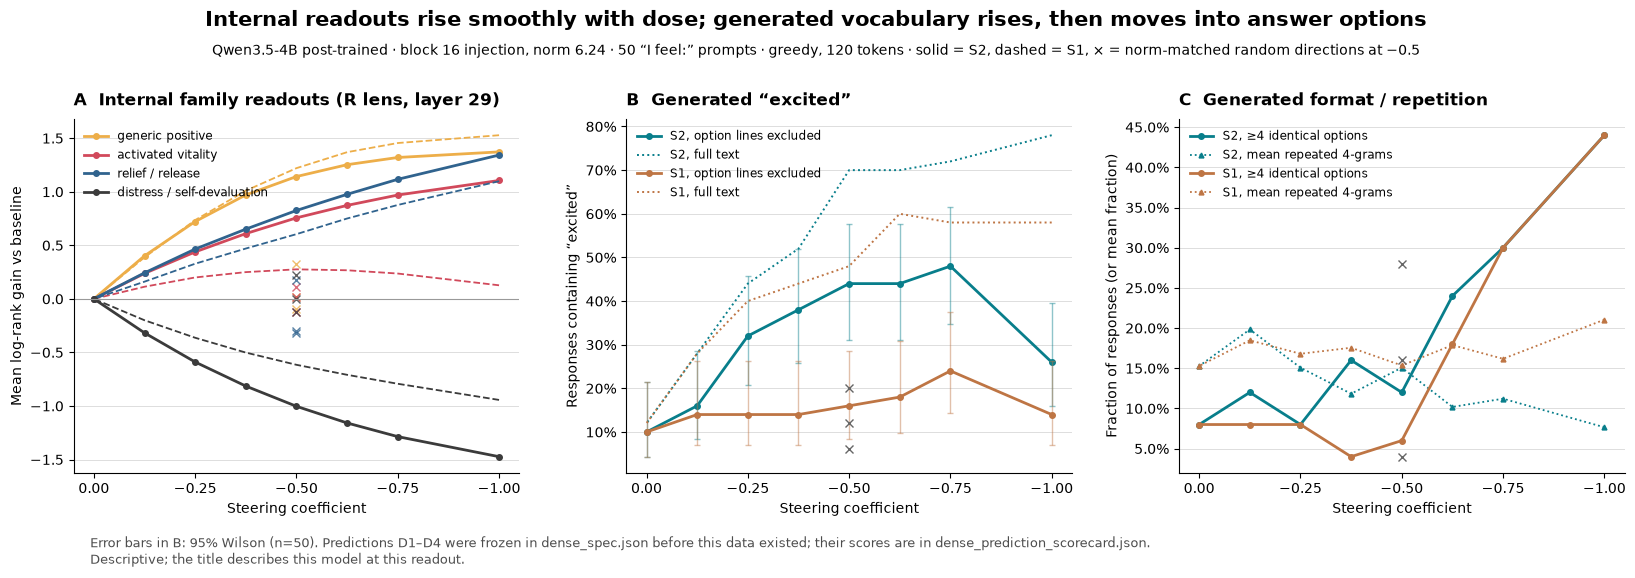


saved: dense_per_prompt.csv, dense_condition_means.csv, dense_onsets_paired_bootstrap.csv, dense_prediction_scorecard.json, figures/dense_sweep_dose_response.{png,svg}


In [47]:
# =====================================================================
# Dense local coefficient sweep -- chunk 6c: SCORE the frozen predictions
# (D1-D4, definitions exactly as stored in dense_spec.json), save per-prompt
# rows, draw the dose-response figure.  CPU only.  Run in the lens session
# (needs probe_terms and chunk 2's helpers: partition_generated_text,
#  excited_re, option_diagnostics, repeated_4gram_fraction).
# =====================================================================
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
dense_dir = paper_run_dir / "dense_sweep"
figure_dir = paper_run_dir / "figures"
figure_dir.mkdir(exist_ok=True)
N_BOOT, BOOT_SEED = 20_000, 20260925
FOCUS = ["generic_positive", "activated_vitality", "relief_release",
         "agency_assurance", "approach_drive", "distress_self_devaluation"]
RANDOMS = ["random_1103", "random_2207", "random_3301"]

spec_text = (dense_dir / "dense_spec.json").read_text()
spec = json.loads(spec_text)
spec_hash = hashlib.sha256(spec_text.encode()).hexdigest()
conds = spec["conditions"]
layers, LENS = spec["lens"]["layers"], spec["lens"]["lens_order"]
assert hashlib.sha256(probe_terms[["family", "term", "token_id"]].to_csv(index=False).encode()).hexdigest() \
    == spec["lens"]["probe_terms_sha256"]
li29, li30, kR = layers.index(29), layers.index(30), LENS.index("R")
ex_col = int(np.flatnonzero(probe_terms.term.to_numpy() == "excited")[0])
fam_cols = {f: np.flatnonzero(probe_terms.family.to_numpy() == f) for f in FOCUS}


# ---------------------------------------------------------------------
# 1. per-prompt rows: internal (R29 family gains, L30 excited rank) + generated
# ---------------------------------------------------------------------
ranks = {}
for n in conds:
    with np.load(dense_dir / "lens" / f"{n}.npz") as z:
        assert str(z["spec_sha256"]) == spec_hash, n
        ranks[n] = z["rank"]
gens = pd.DataFrame(json.loads(l) for l in (dense_dir / "generations_assembled.jsonl").read_text(encoding="utf-8").splitlines())
assert (gens.spec_sha256 == spec_hash).all() and len(gens) == len(conds) * 50

rows = []
for r in gens.itertuples():
    g = np.log(ranks["baseline"][r.prompt_idx, li29, kR] / ranks[r.condition][r.prompt_idx, li29, kR])
    part = partition_generated_text(r.text)
    rows.append({"condition": r.condition, "direction": r.direction or "baseline", "coeff": r.coeff, "prompt_idx": r.prompt_idx,
                 "source": r.source, **{f"gain_{f}": float(g[fam_cols[f]].mean()) for f in FOCUS},
                 "excited_rank_L30": int(ranks[r.condition][r.prompt_idx, li30, kR, ex_col]),
                 "excited__non_option": bool(excited_re.search(part["non_option_text"])),
                 "excited__full": bool(excited_re.search(r.text)),
                 "repeated_options": option_diagnostics(r.text)["max_identical_option_count"] >= 4,
                 "repeat4": repeated_4gram_fraction(r.token_ids)})
pp = pd.DataFrame(rows).sort_values(["condition", "prompt_idx"]).reset_index(drop=True)
pp.to_csv(dense_dir / "dense_per_prompt.csv", index=False)

m = pp.groupby("condition").agg(direction=("direction", "first"), coeff=("coeff", "first"),
                                **{f: (f"gain_{f}", "mean") for f in FOCUS},
                                excited_rank_L30=("excited_rank_L30", lambda x: float(np.exp(np.log(x.astype(float)).mean()))),
                                excited_non_option=("excited__non_option", "mean"), excited_full=("excited__full", "mean"),
                                repeated_options=("repeated_options", "mean"), repeat4=("repeat4", "mean"))
m["amp"] = m[FOCUS].abs().mean(axis=1)
m.to_csv(dense_dir / "dense_condition_means.csv")
base = pp[pp.condition == "baseline"].set_index("prompt_idx")


# ---------------------------------------------------------------------
# 2. D1: Spearman(|coeff|, mean gain) over 0, -0.125 ... -1.0 at R29
# ---------------------------------------------------------------------
def spearman(x, y):
    return float(pd.Series(x).rank().corr(pd.Series(y).rank()))

grid = [0.0] + [c for c in sorted({c["coeff"] for c in conds.values()}, reverse=True) if c < 0]
d1 = {}
for d in ["S2", "S1"]:
    names = ["baseline"] + [n for n, c in conds.items() if c["direction"] == d and c["coeff"] < 0]
    names = sorted(names, key=lambda n: -m.loc[n, "coeff"] if n != "baseline" else 0.0)
    for f, sign in [("generic_positive", 1), ("activated_vitality", 1), ("relief_release", 1), ("distress_self_devaluation", -1)]:
        rho = spearman(np.abs(m.loc[names, "coeff"].to_numpy()), m.loc[names, f].to_numpy())
        d1[(d, f)] = {"rho": rho, "pass": bool(rho >= 0.9 if sign > 0 else rho <= -0.9)}
D1_pass = all(v["pass"] for v in d1.values())


# ---------------------------------------------------------------------
# 3. D2: onsets with prompt-paired bootstrap (S2 scored; S1 shown for reference)
# ---------------------------------------------------------------------
rng = np.random.default_rng(BOOT_SEED)
IDX = rng.integers(0, 50, size=(N_BOOT, 50))
metrics = {"internal: activated_vitality R29": "gain_activated_vitality", "lexical: excited__non_option": "excited__non_option",
           "format: repeated_options": "repeated_options", "format: repeat4": "repeat4"}

def paired(cond, col):
    a = pp[pp.condition == cond].set_index("prompt_idx").sort_index()[col].astype(float).to_numpy()
    b = base.sort_index()[col].astype(float).to_numpy() if not col.startswith("gain_") else np.zeros(50)
    d = a - b
    lo, hi = np.quantile(d[IDX].mean(1), [0.025, 0.975])
    return d.mean(), lo, hi

onset_rows, onsets = [], {}
for d in ["S2", "S1"]:
    names = sorted([n for n, c in conds.items() if c["direction"] == d and c["coeff"] < 0], key=lambda n: -m.loc[n, "coeff"])
    for label, col in metrics.items():
        first = None
        for n in names:
            est, lo, hi = paired(n, col)
            onset_rows.append({"direction": d, "metric": label, "coeff": m.loc[n, "coeff"], "diff": est, "ci_lo": lo, "ci_hi": hi, "excludes_0_up": lo > 0})
            if first is None and lo > 0:
                first = abs(m.loc[n, "coeff"])
        onsets[(d, label)] = first
ons = pd.DataFrame(onset_rows)
ons.to_csv(dense_dir / "dense_onsets_paired_bootstrap.csv", index=False)
o = lambda d, lab: onsets[(d, lab)] if onsets[(d, lab)] is not None else float("inf")
fmt_frozen = min(o("S2", "format: repeated_options"), o("S2", "format: repeat4"))
D2_pass = bool(o("S2", "internal: activated_vitality R29") < o("S2", "lexical: excited__non_option") <= fmt_frozen)


# ---------------------------------------------------------------------
# 4. D3: rank threshold on conditions not in the plane sweep; D4: random amplitude
# ---------------------------------------------------------------------
PLANE = {"baseline", "S1_-0.5", "S2_-0.5"}
d3 = m.loc[[n for n in m.index if n not in PLANE], ["direction", "coeff", "excited_rank_L30", "excited_non_option"]].copy()
d3["band"] = np.where(d3.excited_rank_L30 <= 40, "rank<=40: need >=0.25",
                      np.where(d3.excited_rank_L30 >= 60, "rank>=60: need <=0.20", "40-60: no claim"))
d3["pass"] = np.where(d3.excited_rank_L30 <= 40, d3.excited_non_option >= 0.25,
                      np.where(d3.excited_rank_L30 >= 60, d3.excited_non_option <= 0.20, True))
D3_pass = bool(d3["pass"].all())

d4 = []
for r in RANDOMS:
    for c in [-0.5, 0.5]:
        n, s = f"{r}_{c:+g}", f"S2_{c:+g}"
        d4.append({"random": n, "amp_random": m.loc[n, "amp"], "amp_S2": m.loc[s, "amp"], "ratio": m.loc[n, "amp"] / m.loc[s, "amp"]})
d4 = pd.DataFrame(d4)
d4["pass"] = d4.ratio < 0.5
D4_pass = bool(d4["pass"].sum() > len(d4) / 2)   # frozen: "if most random conditions violate this" -> fail


# ---------------------------------------------------------------------
# 5. print + save scorecard
# ---------------------------------------------------------------------
print("D1 monotone internal readouts (R29, Spearman over |coeff| 0..1):")
for (d, f), v in d1.items():
    print(f"  {d} {f:27s} rho {v['rho']:+.2f}  {'pass' if v['pass'] else 'FAIL'}")
print(f"  -> D1 {'PASS' if D1_pass else 'FAIL'}")

print("\nD2 paired-bootstrap differences vs baseline (95% CI), by |coeff|:")
for d in ["S2", "S1"]:
    t = ons[ons.direction == d].copy()
    t["cell"] = t["diff"].map("{:+.2f}".format) + " [" + t.ci_lo.map("{:+.2f}".format) + "," + t.ci_hi.map("{:+.2f}".format) + "]" + np.where(t.excludes_0_up, "*", " ")
    print(f"\n[{d}]  (* = lower bound > 0)")
    print(t.pivot(index="coeff", columns="metric", values="cell").sort_index(ascending=False)[list(metrics)].to_string())
show = lambda x: "none in grid" if x is None else f"{x:g}"
print("\nS2 onsets (|coeff|):", {lab: show(onsets[("S2", lab)]) for lab in metrics})
print(f"  frozen format onset = earlier of the two = {show(None if fmt_frozen == float('inf') else fmt_frozen)}")
print(f"  -> D2 (internal < lexical <= format) {'PASS' if D2_pass else 'FAIL'}")
print("\nS1 onsets (|coeff|, reference only):", {lab: show(onsets[("S1", lab)]) for lab in metrics})

print("\nD3 rank threshold (conditions not in the plane sweep):")
print(d3.sort_values(["direction", "coeff"]).round(2).to_string())
print(f"  -> D3 {'PASS' if D3_pass else 'FAIL'}")

print("\nD4 random-direction amplitude / S2 amplitude at the same coefficient:")
print(d4.round(2).to_string(index=False))
print(f"  -> D4 {'PASS' if D4_pass else 'FAIL'}")

post_hoc = m.loc[[n for n in m.index if m.loc[n, "direction"] in ("S2", "S1")], ["direction", "coeff", "excited_full", "excited_non_option", "repeated_options"]].copy()
post_hoc["excited_in_options_only"] = post_hoc.excited_full - post_hoc.excited_non_option
print("\n[POST HOC, not a frozen prediction] share of responses with `excited` only in option lines:")
print(post_hoc.sort_values(["direction", "coeff"], ascending=[True, False]).round(2).to_string())

scorecard = {"spec_sha256": spec_hash,
             "D1": {"pass": D1_pass, "detail": {f"{d}:{f}": round(v["rho"], 3) for (d, f), v in d1.items()}},
             "D2": {"pass": D2_pass, "S2_onsets": {k: (None if onsets[("S2", k)] is None else float(onsets[("S2", k)])) for k in metrics}, "frozen_format_onset": None if fmt_frozen == float("inf") else float(fmt_frozen)},
             "D3": {"pass": D3_pass, "failures": d3[~d3["pass"]].index.tolist()},
             "D4": {"pass": D4_pass, "ratios": {k: float(v) for k, v in zip(d4.random, d4.ratio.round(3))}}}
(dense_dir / "dense_prediction_scorecard.json").write_text(json.dumps(scorecard, indent=2) + "\n")


# ---------------------------------------------------------------------
# 6. figure: internal / lexical / format against dose
# ---------------------------------------------------------------------
def wilson(k, n, z=1.959964):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

COL = {"S2": "#087E8B", "S1": "#BE7544"}
FAMC = {"generic_positive": "#EDAE49", "activated_vitality": "#D1495B", "relief_release": "#30638E", "distress_self_devaluation": "#3B3B3B"}
FAMN = {"generic_positive": "generic positive", "activated_vitality": "activated vitality", "relief_release": "relief / release",
        "distress_self_devaluation": "distress / self-devaluation"}
RC = {"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "svg.fonttype": "none"}
rec = []

def line(d):
    names = ["baseline"] + [n for n, c in conds.items() if c["direction"] == d and c["coeff"] < 0]
    return sorted(names, key=lambda n: m.loc[n, "coeff"] if n != "baseline" else 0.0)

with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2))
    ax = axes[0]
    for f, col in FAMC.items():
        for d, ls in [("S2", "-"), ("S1", "--")]:
            ns = line(d)
            xs = [-abs(m.loc[n, "coeff"]) if n != "baseline" else 0 for n in ns]
            ys = [0.0 if n == "baseline" else m.loc[n, f] for n in ns]
            ax.plot(xs, ys, color=col, ls=ls, lw=2.0 if d == "S2" else 1.3, marker="o" if d == "S2" else None, ms=4,
                    label=f"{FAMN[f]}" if d == "S2" else None)
            rec += [{"panel": "A", "series": f"{d}:{f}", "coeff": x, "y": y} for x, y in zip(xs, ys)]
        for r in RANDOMS:
            ax.plot([-0.5], [m.loc[f"{r}_-0.5", f]], "x", color=col, ms=6, alpha=0.8)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_title("A  Internal family readouts (R lens, layer 29)", loc="left", fontweight="bold", pad=10)
    ax.set_ylabel("Mean log-rank gain vs baseline"); ax.legend(frameon=False, fontsize=8.5, loc="upper left")

    ax = axes[1]
    for d in ["S2", "S1"]:
        ns = line(d)
        xs = [0 if n == "baseline" else m.loc[n, "coeff"] for n in ns]
        for col_name, ls, lab in [("excited__non_option", "-", "option lines excluded"), ("excited__full", ":", "full text")]:
            ks = [int(pp[pp.condition == n][col_name].sum()) for n in ns]
            ys = [k / 50 for k in ks]; ci = [wilson(k, 50) for k in ks]
            ax.plot(xs, ys, color=COL[d], ls=ls, lw=2.0 if ls == "-" else 1.4, marker="o" if ls == "-" else None, ms=4,
                    label=f"{d}, {lab}")
            if ls == "-":
                ax.errorbar(xs, ys, yerr=[[max(0.0, y - c[0]) for y, c in zip(ys, ci)], [max(0.0, c[1] - y) for y, c in zip(ys, ci)]],
                            color=COL[d], lw=0, elinewidth=1, capsize=2, alpha=0.45)
            rec += [{"panel": "B", "series": f"{d}:{col_name}", "coeff": x, "y": y} for x, y in zip(xs, ys)]
    for r in RANDOMS:
        ax.plot([-0.5], [m.loc[f"{r}_-0.5", "excited_non_option"]], "x", color="0.4", ms=6)
    ax.set_title("B  Generated “excited”", loc="left", fontweight="bold", pad=10)
    ax.set_ylabel("Responses containing “excited”"); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")

    ax = axes[2]
    for d in ["S2", "S1"]:
        ns = line(d)
        xs = [0 if n == "baseline" else m.loc[n, "coeff"] for n in ns]
        ys = [m.loc[n, "repeated_options"] for n in ns]
        ax.plot(xs, ys, color=COL[d], lw=2.0, marker="o", ms=4, label=f"{d}, ≥4 identical options")
        ys2 = [m.loc[n, "repeat4"] for n in ns]
        ax.plot(xs, ys2, color=COL[d], lw=1.3, ls=":", marker="^", ms=3.5, label=f"{d}, mean repeated 4-grams")
        rec += [{"panel": "C", "series": f"{d}:repeated_options", "coeff": x, "y": y} for x, y in zip(xs, ys)]
        rec += [{"panel": "C", "series": f"{d}:repeat4", "coeff": x, "y": y} for x, y in zip(xs, ys2)]
    for r in RANDOMS:
        ax.plot([-0.5], [m.loc[f"{r}_-0.5", "repeated_options"]], "x", color="0.4", ms=6)
    ax.set_title("C  Generated format / repetition", loc="left", fontweight="bold", pad=10)
    ax.set_ylabel("Fraction of responses (or mean fraction)"); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")

    for ax in axes:
        ax.set_xlabel("Steering coefficient"); ax.set_xticks([-1.0, -0.75, -0.5, -0.25, 0])
        ax.invert_xaxis(); ax.grid(axis="y", color="#dddddd", lw=0.7); ax.set_axisbelow(True)
    fig.suptitle("Internal readouts rise smoothly with dose; generated vocabulary rises, then moves into answer options",
                 fontsize=15, fontweight="bold", y=1.03)
    fig.text(0.5, 0.965, "Qwen3.5-4B post-trained · block 16 injection, norm 6.24 · 50 “I feel:” prompts · greedy, 120 tokens · "
             "solid = S2, dashed = S1, × = norm-matched random directions at −0.5", ha="center", va="top", fontsize=10)
    fig.text(0.06, -0.035, "Error bars in B: 95% Wilson (n=50). Predictions D1–D4 were frozen in dense_spec.json before this data existed; "
             "their scores are in dense_prediction_scorecard.json.\nDescriptive; the title describes this model at this readout.",
             fontsize=9, color="0.3")
    fig.subplots_adjust(left=0.05, right=0.99, bottom=0.14, top=0.82, wspace=0.24)
    for ext in ["png", "svg"]:
        fig.savefig(figure_dir / f"dense_sweep_dose_response.{ext}", dpi=180, bbox_inches="tight")
    plt.show()
pd.DataFrame(rec).to_csv(figure_dir / "dense_sweep_dose_response_plot_data.csv", index=False)
print("\nsaved: dense_per_prompt.csv, dense_condition_means.csv, dense_onsets_paired_bootstrap.csv, "
      "dense_prediction_scorecard.json, figures/dense_sweep_dose_response.{png,svg}")

# Dense coefficient sweep: checkpoint (plan item 2)

Qwen3.5-4B post-trained, S1 and S2 (block 30 extraction, block 16
injection, norm 6.2439), same 50 "I feel:" prompts, greedy, 120 tokens.
Coefficients 0, -0.125, -0.25, -0.375, -0.5, -0.625, -0.75, -1.0 for
both directions, plus +0.5 for each and three norm-matched random
directions at -0.5 and +0.5 (23 conditions). Internal readouts are the
frozen family definitions at R lens layer 29 and the rank of " excited"
at layer 30.

## Provenance checks that passed
- The lens arm reproduces the plane sweep's baseline, S1 -0.5 and
  S2 -0.5 arrays exactly (identical ranks, logit difference 0).
- 500 new generations; all other conditions reuse stored ladder rows
  behind a regeneration gate (prompts 0-2 of each of the 12 reused
  steered conditions, 36/36 token-identical).
- Predictions D1-D4 were written into `dense_spec.json` before any
  dense-sweep data existed; scores are computed from those definitions.

## Frozen predictions and scores
| | Prediction | Result |
|---|---|---|
| D1 | Internal family readouts monotone in dose (Spearman >= 0.9; distress <= -0.9), S1 and S2 | Fail: S1 activated vitality rho = 0.48. All S2 families and S1 generic positive, relief and distress are +/-1.00 |
| D2 | S2: internal onset < lexical onset <= format onset | Pass: 0.125 < 0.25 <= 0.625 |
| D3 | New conditions: L30 "excited" rank <= 40 gives >= 0.25 generated "excited"; rank >= 60 gives <= 0.20 | Fail: S1 -0.75 (rank 38, 0.24) and S1 -1.0 (rank 34, 0.14) |
| D4 | Random directions move the six focus families less than half as much as S2 at the same coefficient | Pass: ratios 0.09-0.23 |

## Observations
- Internal, S2: all focus families move monotonically with shrinking
  increments; activated vitality +0.24 at -0.125 to +1.11 at -1.0,
  distress -0.32 to -1.47. L30 " excited" rank falls from 113 to 7.9
  (baseline 282).
- Internal, S1: generic positive, relief and distress are monotone;
  activated vitality peaks at +0.28 (-0.5) and falls to +0.13 at -1.0.
  L30 " excited" rank falls from 162 to 34.
- The positive side moves more: at +0.5, S2's mean absolute family
  gain is 0.96 against 0.72 at -0.5 (generic positive -1.89,
  distress +1.54). S1 shows the same asymmetry.
- Random directions: amplitude 0.08-0.17 against S2's 0.72-0.96, and
  generic positive and distress move in opposite directions in only 2
  of 6 random conditions.
- Generated "excited", option lines excluded, S2: 0.10 baseline, then
  0.16, 0.32, 0.38, 0.44, 0.44, 0.48 up to -0.75, then 0.26 at -1.0
  while full-text "excited" reaches 0.78. S1 stays at 0.14-0.24
  (full text 0.28-0.60).
- Onsets (smallest |coeff| whose paired-bootstrap 95% CI excludes 0):
  S2 internal 0.125, lexical 0.25, repeated options 0.625; repeat4 has
  no upward onset and falls below baseline at -0.625 and -1.0. S1
  internal 0.125, lexical 0.75, repeated options 0.75.
- At -0.25, S2's lexical rise is clear (+0.22 [+0.12, +0.34]) while
  repeated options is flat (+0.00 [-0.06, +0.06]). At -0.125, the
  lexical, repeated-options and repeat4 intervals all have a lower
  bound of 0.00; the frozen criterion excludes them, and a looser one
  would move those onsets to 0.125 and fail D2.
- Option repetition tracks dose rather than direction: S1 and S2 give
  identical rates at -0.75 (0.30) and -1.0 (0.44), and random
  directions at +/-0.5 give 0.04-0.50.
- Post hoc, not a frozen prediction: the share of responses with
  "excited" only in option lines is 0.26-0.44 for S1 from -0.25 on,
  and 0.12-0.26 for S2 until -1.0, where it reaches 0.52. This is a
  candidate explanation for D3's failure: at similar L30 ranks, S1's
  "excited" appears as an answer option rather than in the model's own
  continuation.

## Answer to the plan's question
For S2 in this range there is no sharp threshold where semantic and
format effects appear together. Internal readouts rise from the
smallest dose with shrinking increments, generated "excited" appears
by -0.25 and levels off around 0.38-0.48, option repetition appears
from -0.625, and at -1.0 the word moves into answer options. The
paper's gate-like threshold is not visible here; this covers the
negative side only, one model, one readout layer and 50 prompts.

## Changes to the candidate-claim list
- Candidate 5 in the main checkpoint (the rank threshold) failed as
  frozen (D3). Retire it; any direction-aware version is v2 and needs
  fresh conditions.
- New candidate 8: for S2, the internal readout's onset precedes the
  lexical onset, which precedes the option-repetition onset.
- New candidate 9: option repetition under steering is driven by dose
  and is not specific to S1/S2.

## Caveats
50 prompts per condition; onsets are limited by the grid and three
cells sit on the criterion's edge; lexical metrics are word presence;
the vitality family's internal movement is partly carried by
"excited"; reused conditions rest on a 3-prompt regeneration gate.

## Artifacts
`dense_sweep/`: `dense_spec.json`, `lens/*.npz` (large; manifest them
like the plane sweep), `lens_glance_R29.csv`, `generations_new.jsonl`,
`generation_reuse_gate.csv`, `generations_assembled.jsonl`,
`dense_per_prompt.csv`, `dense_condition_means.csv`,
`dense_onsets_paired_bootstrap.csv`, `dense_prediction_scorecard.json`.
`figures/dense_sweep_dose_response.{png,svg}` and plot data.

## Next
Plan item 3, prompt-format robustness ("I feel:", "I feel",
"Afterward, I felt", and so on). The plane-sweep addendum already
showed that the read slot changes what the directions read; item 3
asks the same question on the writing side.

D1 monotone internal readouts (R29, Spearman over |coeff| 0..1):
  S2 generic_positive            rho +1.00  pass
  S2 activated_vitality          rho +1.00  pass
  S2 relief_release              rho +1.00  pass
  S2 distress_self_devaluation   rho -1.00  pass
  S1 generic_positive            rho +1.00  pass
  S1 activated_vitality          rho +0.48  FAIL
  S1 relief_release              rho +1.00  pass
  S1 distress_self_devaluation   rho -1.00  pass
  -> D1 FAIL

D2 paired-bootstrap differences vs baseline (95% CI), by |coeff|:

[S2]  (* = lower bound > 0)
metric internal: activated_vitality R29 lexical: excited__non_option format: repeated_options       format: repeat4
coeff                                                                                                              
-0.125             +0.24 [+0.22,+0.25]*         +0.06 [+0.00,+0.14]      +0.04 [+0.00,+0.10]   +0.05 [-0.00,+0.10] 
-0.250             +0.44 [+0.41,+0.47]*         +0.22 [+0.12,+0.34]*     +0.00 [-0.06,

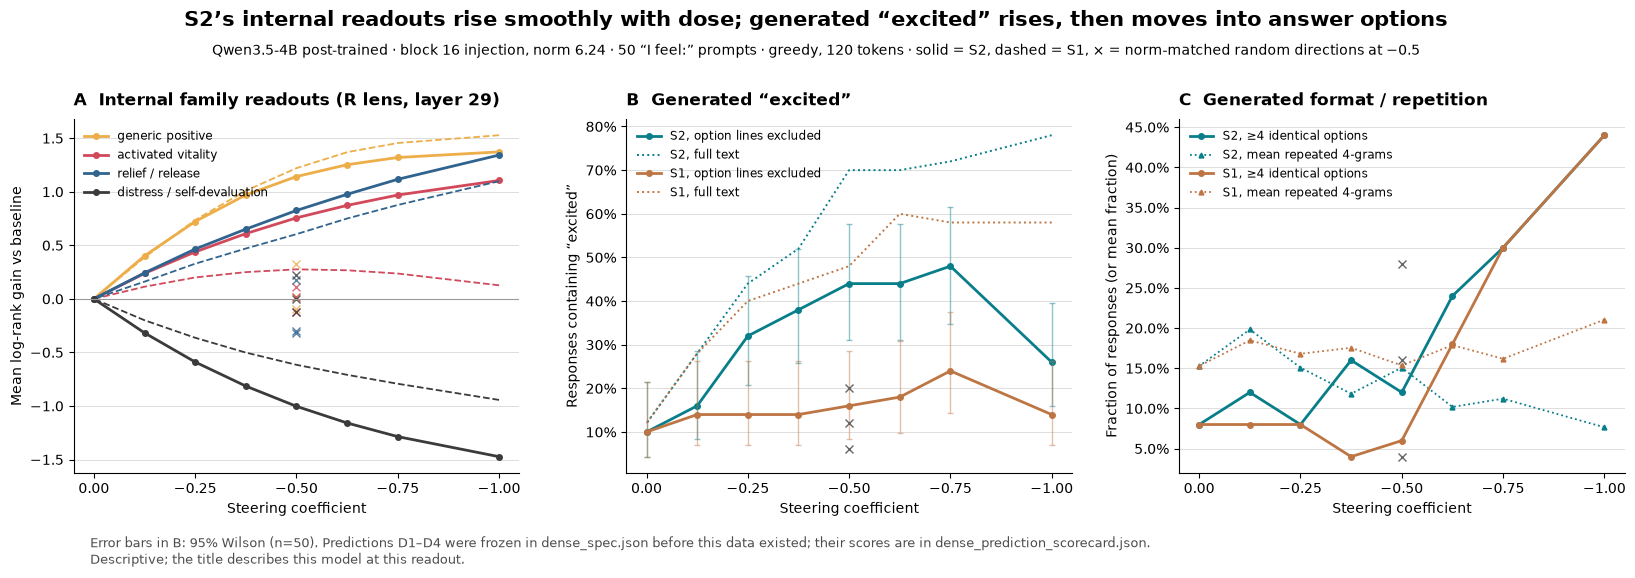


saved: dense_per_prompt.csv, dense_condition_means.csv, dense_onsets_paired_bootstrap.csv, dense_prediction_scorecard.json, figures/dense_sweep_dose_response.{png,svg}


In [48]:
# =====================================================================
# Dense local coefficient sweep -- chunk 6c: SCORE the frozen predictions
# (D1-D4, definitions exactly as stored in dense_spec.json), save per-prompt
# rows, draw the dose-response figure.  CPU only.  Run in the lens session
# (needs probe_terms and chunk 2's helpers: partition_generated_text,
#  excited_re, option_diagnostics, repeated_4gram_fraction).
# =====================================================================
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
dense_dir = paper_run_dir / "dense_sweep"
figure_dir = paper_run_dir / "figures"
figure_dir.mkdir(exist_ok=True)
N_BOOT, BOOT_SEED = 20_000, 20260925
FOCUS = ["generic_positive", "activated_vitality", "relief_release",
         "agency_assurance", "approach_drive", "distress_self_devaluation"]
RANDOMS = ["random_1103", "random_2207", "random_3301"]

spec_text = (dense_dir / "dense_spec.json").read_text()
spec = json.loads(spec_text)
spec_hash = hashlib.sha256(spec_text.encode()).hexdigest()
conds = spec["conditions"]
layers, LENS = spec["lens"]["layers"], spec["lens"]["lens_order"]
assert hashlib.sha256(probe_terms[["family", "term", "token_id"]].to_csv(index=False).encode()).hexdigest() \
    == spec["lens"]["probe_terms_sha256"]
li29, li30, kR = layers.index(29), layers.index(30), LENS.index("R")
ex_col = int(np.flatnonzero(probe_terms.term.to_numpy() == "excited")[0])
fam_cols = {f: np.flatnonzero(probe_terms.family.to_numpy() == f) for f in FOCUS}


# ---------------------------------------------------------------------
# 1. per-prompt rows: internal (R29 family gains, L30 excited rank) + generated
# ---------------------------------------------------------------------
ranks = {}
for n in conds:
    with np.load(dense_dir / "lens" / f"{n}.npz") as z:
        assert str(z["spec_sha256"]) == spec_hash, n
        ranks[n] = z["rank"]
gens = pd.DataFrame(json.loads(l) for l in (dense_dir / "generations_assembled.jsonl").read_text(encoding="utf-8").splitlines())
assert (gens.spec_sha256 == spec_hash).all() and len(gens) == len(conds) * 50

rows = []
for r in gens.itertuples():
    g = np.log(ranks["baseline"][r.prompt_idx, li29, kR] / ranks[r.condition][r.prompt_idx, li29, kR])
    part = partition_generated_text(r.text)
    rows.append({"condition": r.condition, "direction": r.direction or "baseline", "coeff": r.coeff, "prompt_idx": r.prompt_idx,
                 "source": r.source, **{f"gain_{f}": float(g[fam_cols[f]].mean()) for f in FOCUS},
                 "excited_rank_L30": int(ranks[r.condition][r.prompt_idx, li30, kR, ex_col]),
                 "excited__non_option": bool(excited_re.search(part["non_option_text"])),
                 "excited__full": bool(excited_re.search(r.text)),
                 "repeated_options": option_diagnostics(r.text)["max_identical_option_count"] >= 4,
                 "repeat4": repeated_4gram_fraction(r.token_ids)})
pp = pd.DataFrame(rows).sort_values(["condition", "prompt_idx"]).reset_index(drop=True)
pp.to_csv(dense_dir / "dense_per_prompt.csv", index=False)

m = pp.groupby("condition").agg(direction=("direction", "first"), coeff=("coeff", "first"),
                                **{f: (f"gain_{f}", "mean") for f in FOCUS},
                                excited_rank_L30=("excited_rank_L30", lambda x: float(np.exp(np.log(x.astype(float)).mean()))),
                                excited_non_option=("excited__non_option", "mean"), excited_full=("excited__full", "mean"),
                                repeated_options=("repeated_options", "mean"), repeat4=("repeat4", "mean"))
m["amp"] = m[FOCUS].abs().mean(axis=1)
m.to_csv(dense_dir / "dense_condition_means.csv")
base = pp[pp.condition == "baseline"].set_index("prompt_idx")


# ---------------------------------------------------------------------
# 2. D1: Spearman(|coeff|, mean gain) over 0, -0.125 ... -1.0 at R29
# ---------------------------------------------------------------------
def spearman(x, y):
    return float(pd.Series(x).rank().corr(pd.Series(y).rank()))

grid = [0.0] + [c for c in sorted({c["coeff"] for c in conds.values()}, reverse=True) if c < 0]
d1 = {}
for d in ["S2", "S1"]:
    names = ["baseline"] + [n for n, c in conds.items() if c["direction"] == d and c["coeff"] < 0]
    names = sorted(names, key=lambda n: -m.loc[n, "coeff"] if n != "baseline" else 0.0)
    for f, sign in [("generic_positive", 1), ("activated_vitality", 1), ("relief_release", 1), ("distress_self_devaluation", -1)]:
        rho = spearman(np.abs(m.loc[names, "coeff"].to_numpy()), m.loc[names, f].to_numpy())
        d1[(d, f)] = {"rho": rho, "pass": bool(rho >= 0.9 if sign > 0 else rho <= -0.9)}
D1_pass = all(v["pass"] for v in d1.values())


# ---------------------------------------------------------------------
# 3. D2: onsets with prompt-paired bootstrap (S2 scored; S1 shown for reference)
# ---------------------------------------------------------------------
rng = np.random.default_rng(BOOT_SEED)
IDX = rng.integers(0, 50, size=(N_BOOT, 50))
metrics = {"internal: activated_vitality R29": "gain_activated_vitality", "lexical: excited__non_option": "excited__non_option",
           "format: repeated_options": "repeated_options", "format: repeat4": "repeat4"}

def paired(cond, col):
    a = pp[pp.condition == cond].set_index("prompt_idx").sort_index()[col].astype(float).to_numpy()
    b = base.sort_index()[col].astype(float).to_numpy() if not col.startswith("gain_") else np.zeros(50)
    d = a - b
    lo, hi = np.quantile(d[IDX].mean(1), [0.025, 0.975])
    return d.mean(), lo, hi

onset_rows, onsets = [], {}
for d in ["S2", "S1"]:
    names = sorted([n for n, c in conds.items() if c["direction"] == d and c["coeff"] < 0], key=lambda n: -m.loc[n, "coeff"])
    for label, col in metrics.items():
        first = None
        for n in names:
            est, lo, hi = paired(n, col)
            onset_rows.append({"direction": d, "metric": label, "coeff": m.loc[n, "coeff"], "diff": est, "ci_lo": lo, "ci_hi": hi, "excludes_0_up": lo > 0})
            if first is None and lo > 0:
                first = abs(m.loc[n, "coeff"])
        onsets[(d, label)] = first
ons = pd.DataFrame(onset_rows)
ons.to_csv(dense_dir / "dense_onsets_paired_bootstrap.csv", index=False)
o = lambda d, lab: onsets[(d, lab)] if onsets[(d, lab)] is not None else float("inf")
fmt_frozen = min(o("S2", "format: repeated_options"), o("S2", "format: repeat4"))
D2_pass = bool(o("S2", "internal: activated_vitality R29") < o("S2", "lexical: excited__non_option") <= fmt_frozen)


# ---------------------------------------------------------------------
# 4. D3: rank threshold on conditions not in the plane sweep; D4: random amplitude
# ---------------------------------------------------------------------
PLANE = {"baseline", "S1_-0.5", "S2_-0.5"}
d3 = m.loc[[n for n in m.index if n not in PLANE], ["direction", "coeff", "excited_rank_L30", "excited_non_option"]].copy()
d3["band"] = np.where(d3.excited_rank_L30 <= 40, "rank<=40: need >=0.25",
                      np.where(d3.excited_rank_L30 >= 60, "rank>=60: need <=0.20", "40-60: no claim"))
d3["pass"] = np.where(d3.excited_rank_L30 <= 40, d3.excited_non_option >= 0.25,
                      np.where(d3.excited_rank_L30 >= 60, d3.excited_non_option <= 0.20, True))
D3_pass = bool(d3["pass"].all())

d4 = []
for r in RANDOMS:
    for c in [-0.5, 0.5]:
        n, s = f"{r}_{c:+g}", f"S2_{c:+g}"
        d4.append({"random": n, "amp_random": m.loc[n, "amp"], "amp_S2": m.loc[s, "amp"], "ratio": m.loc[n, "amp"] / m.loc[s, "amp"]})
d4 = pd.DataFrame(d4)
d4["pass"] = d4.ratio < 0.5
D4_pass = bool(d4["pass"].sum() > len(d4) / 2)   # frozen: "if most random conditions violate this" -> fail


# ---------------------------------------------------------------------
# 5. print + save scorecard
# ---------------------------------------------------------------------
print("D1 monotone internal readouts (R29, Spearman over |coeff| 0..1):")
for (d, f), v in d1.items():
    print(f"  {d} {f:27s} rho {v['rho']:+.2f}  {'pass' if v['pass'] else 'FAIL'}")
print(f"  -> D1 {'PASS' if D1_pass else 'FAIL'}")

print("\nD2 paired-bootstrap differences vs baseline (95% CI), by |coeff|:")
for d in ["S2", "S1"]:
    t = ons[ons.direction == d].copy()
    t["cell"] = t["diff"].map("{:+.2f}".format) + " [" + t.ci_lo.map("{:+.2f}".format) + "," + t.ci_hi.map("{:+.2f}".format) + "]" + np.where(t.excludes_0_up, "*", " ")
    print(f"\n[{d}]  (* = lower bound > 0)")
    print(t.pivot(index="coeff", columns="metric", values="cell").sort_index(ascending=False)[list(metrics)].to_string())
show = lambda x: "none in grid" if x is None else f"{x:g}"
print("\nS2 onsets (|coeff|):", {lab: show(onsets[("S2", lab)]) for lab in metrics})
print(f"  frozen format onset = earlier of the two = {show(None if fmt_frozen == float('inf') else fmt_frozen)}")
print(f"  -> D2 (internal < lexical <= format) {'PASS' if D2_pass else 'FAIL'}")
print("\nS1 onsets (|coeff|, reference only):", {lab: show(onsets[("S1", lab)]) for lab in metrics})

print("\nD3 rank threshold (conditions not in the plane sweep):")
print(d3.sort_values(["direction", "coeff"]).round(2).to_string())
print(f"  -> D3 {'PASS' if D3_pass else 'FAIL'}")

print("\nD4 random-direction amplitude / S2 amplitude at the same coefficient:")
print(d4.round(2).to_string(index=False))
print(f"  -> D4 {'PASS' if D4_pass else 'FAIL'}")

post_hoc = m.loc[[n for n in m.index if m.loc[n, "direction"] in ("S2", "S1")], ["direction", "coeff", "excited_full", "excited_non_option", "repeated_options"]].copy()
post_hoc["excited_in_options_only"] = post_hoc.excited_full - post_hoc.excited_non_option
print("\n[POST HOC, not a frozen prediction] share of responses with `excited` only in option lines:")
print(post_hoc.sort_values(["direction", "coeff"], ascending=[True, False]).round(2).to_string())

scorecard = {"spec_sha256": spec_hash,
             "D1": {"pass": D1_pass, "detail": {f"{d}:{f}": round(v["rho"], 3) for (d, f), v in d1.items()}},
             "D2": {"pass": D2_pass, "S2_onsets": {k: (None if onsets[("S2", k)] is None else float(onsets[("S2", k)])) for k in metrics}, "frozen_format_onset": None if fmt_frozen == float("inf") else float(fmt_frozen)},
             "D3": {"pass": D3_pass, "failures": d3[~d3["pass"]].index.tolist()},
             "D4": {"pass": D4_pass, "ratios": {k: float(v) for k, v in zip(d4.random, d4.ratio.round(3))}}}
(dense_dir / "dense_prediction_scorecard.json").write_text(json.dumps(scorecard, indent=2) + "\n")


# ---------------------------------------------------------------------
# 6. figure: internal / lexical / format against dose
# ---------------------------------------------------------------------
def wilson(k, n, z=1.959964):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

COL = {"S2": "#087E8B", "S1": "#BE7544"}
FAMC = {"generic_positive": "#EDAE49", "activated_vitality": "#D1495B", "relief_release": "#30638E", "distress_self_devaluation": "#3B3B3B"}
FAMN = {"generic_positive": "generic positive", "activated_vitality": "activated vitality", "relief_release": "relief / release",
        "distress_self_devaluation": "distress / self-devaluation"}
RC = {"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "svg.fonttype": "none"}
rec = []

def line(d):
    names = ["baseline"] + [n for n, c in conds.items() if c["direction"] == d and c["coeff"] < 0]
    return sorted(names, key=lambda n: m.loc[n, "coeff"] if n != "baseline" else 0.0)

with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2))
    ax = axes[0]
    for f, col in FAMC.items():
        for d, ls in [("S2", "-"), ("S1", "--")]:
            ns = line(d)
            xs = [-abs(m.loc[n, "coeff"]) if n != "baseline" else 0 for n in ns]
            ys = [0.0 if n == "baseline" else m.loc[n, f] for n in ns]
            ax.plot(xs, ys, color=col, ls=ls, lw=2.0 if d == "S2" else 1.3, marker="o" if d == "S2" else None, ms=4,
                    label=f"{FAMN[f]}" if d == "S2" else None)
            rec += [{"panel": "A", "series": f"{d}:{f}", "coeff": x, "y": y} for x, y in zip(xs, ys)]
        for r in RANDOMS:
            ax.plot([-0.5], [m.loc[f"{r}_-0.5", f]], "x", color=col, ms=6, alpha=0.8)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_title("A  Internal family readouts (R lens, layer 29)", loc="left", fontweight="bold", pad=10)
    ax.set_ylabel("Mean log-rank gain vs baseline"); ax.legend(frameon=False, fontsize=8.5, loc="upper left")

    ax = axes[1]
    for d in ["S2", "S1"]:
        ns = line(d)
        xs = [0 if n == "baseline" else m.loc[n, "coeff"] for n in ns]
        for col_name, ls, lab in [("excited__non_option", "-", "option lines excluded"), ("excited__full", ":", "full text")]:
            ks = [int(pp[pp.condition == n][col_name].sum()) for n in ns]
            ys = [k / 50 for k in ks]; ci = [wilson(k, 50) for k in ks]
            ax.plot(xs, ys, color=COL[d], ls=ls, lw=2.0 if ls == "-" else 1.4, marker="o" if ls == "-" else None, ms=4,
                    label=f"{d}, {lab}")
            if ls == "-":
                ax.errorbar(xs, ys, yerr=[[max(0.0, y - c[0]) for y, c in zip(ys, ci)], [max(0.0, c[1] - y) for y, c in zip(ys, ci)]],
                            color=COL[d], lw=0, elinewidth=1, capsize=2, alpha=0.45)
            rec += [{"panel": "B", "series": f"{d}:{col_name}", "coeff": x, "y": y} for x, y in zip(xs, ys)]
    for r in RANDOMS:
        ax.plot([-0.5], [m.loc[f"{r}_-0.5", "excited_non_option"]], "x", color="0.4", ms=6)
    ax.set_title("B  Generated “excited”", loc="left", fontweight="bold", pad=10)
    ax.set_ylabel("Responses containing “excited”"); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")

    ax = axes[2]
    for d in ["S2", "S1"]:
        ns = line(d)
        xs = [0 if n == "baseline" else m.loc[n, "coeff"] for n in ns]
        ys = [m.loc[n, "repeated_options"] for n in ns]
        ax.plot(xs, ys, color=COL[d], lw=2.0, marker="o", ms=4, label=f"{d}, ≥4 identical options")
        ys2 = [m.loc[n, "repeat4"] for n in ns]
        ax.plot(xs, ys2, color=COL[d], lw=1.3, ls=":", marker="^", ms=3.5, label=f"{d}, mean repeated 4-grams")
        rec += [{"panel": "C", "series": f"{d}:repeated_options", "coeff": x, "y": y} for x, y in zip(xs, ys)]
        rec += [{"panel": "C", "series": f"{d}:repeat4", "coeff": x, "y": y} for x, y in zip(xs, ys2)]
    for r in RANDOMS:
        ax.plot([-0.5], [m.loc[f"{r}_-0.5", "repeated_options"]], "x", color="0.4", ms=6)
    ax.set_title("C  Generated format / repetition", loc="left", fontweight="bold", pad=10)
    ax.set_ylabel("Fraction of responses (or mean fraction)"); ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")

    for ax in axes:
        ax.set_xlabel("Steering coefficient"); ax.set_xticks([-1.0, -0.75, -0.5, -0.25, 0])
        ax.invert_xaxis(); ax.grid(axis="y", color="#dddddd", lw=0.7); ax.set_axisbelow(True)
    fig.suptitle("S2’s internal readouts rise smoothly with dose; generated “excited” rises, then moves into answer options",
                 fontsize=15, fontweight="bold", y=1.03)
    fig.text(0.5, 0.965, "Qwen3.5-4B post-trained · block 16 injection, norm 6.24 · 50 “I feel:” prompts · greedy, 120 tokens · "
             "solid = S2, dashed = S1, × = norm-matched random directions at −0.5", ha="center", va="top", fontsize=10)
    fig.text(0.06, -0.035, "Error bars in B: 95% Wilson (n=50). Predictions D1–D4 were frozen in dense_spec.json before this data existed; "
             "their scores are in dense_prediction_scorecard.json.\nDescriptive; the title describes this model at this readout.",
             fontsize=9, color="0.3")
    fig.subplots_adjust(left=0.05, right=0.99, bottom=0.14, top=0.82, wspace=0.24)
    for ext in ["png", "svg"]:
        fig.savefig(figure_dir / f"dense_sweep_dose_response.{ext}", dpi=180, bbox_inches="tight")
    plt.show()
pd.DataFrame(rec).to_csv(figure_dir / "dense_sweep_dose_response_plot_data.csv", index=False)
print("\nsaved: dense_per_prompt.csv, dense_condition_means.csv, dense_onsets_paired_bootstrap.csv, "
      "dense_prediction_scorecard.json, figures/dense_sweep_dose_response.{png,svg}")

In [49]:
# =====================================================================
# Prompt-format robustness (plan item 3) -- chunk 7:
#   1. freeze the spec: formats, conditions, CONFIRMATORY predictions and the
#      pre-specified EXPLORATORY report (both arms)
#   2. read-slot projection: unsteered prompts of all 4 formats onto
#      S1/S2/common/contrast at block 30 (5e conventions)
#   3. lens arm for the 3 new formats (F0 is reused from the dense sweep)
# Generation is chunk 7b.  Run in the lens session (needs hf, tok,
# capture_all_layers, lens_readout, ranks_for_tokens, j_lens, r_lens, probe_terms).
# =====================================================================
import hashlib
import json
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
s1_dir = paper_run_dir / "s1_comparison"
plane_dir = paper_run_dir / "plane_sweep"
dense_dir = paper_run_dir / "dense_sweep"
fmt_dir = paper_run_dir / "format_robustness"
lens_out = fmt_dir / "lens"
lens_out.mkdir(parents=True, exist_ok=True)
TOP_K, LENS_ORDER = 50, ["J", "R"]
lens_objs = {"J": j_lens, "R": r_lens}

COEFFS = [-0.25, -0.5]                      # S1 and S2; edit BEFORE the first run (spec freezes)
RANDOMS = ["random_1103", "random_2207", "random_3301"]
RANDOM_COEFF = -0.5
FORMATS = {"F0": " I feel:", "F1": " I feel", "F2": " Afterward, I felt", "F3": " What happened next was"}
BLOCK, BATCH = 30, 4

sha_bytes = lambda b: hashlib.sha256(b).hexdigest()
sha_tensor = lambda t: sha_bytes(t.contiguous().numpy().tobytes())
cname = lambda d, c: f"{d}_{c:+g}"


# ---------------------------------------------------------------------
# 1. prompts, vectors, conditions
# ---------------------------------------------------------------------
paper_spec_bytes = (paper_run_dir / "spec.json").read_bytes()
base_prompts = json.loads(paper_spec_bytes)["prompts"]
assert all(p.endswith(" I feel:") for p in base_prompts)
stems = [p[: -len(" I feel:")] for p in base_prompts]
prompts = {f: [s + suf for s in stems] for f, suf in FORMATS.items()}
assert prompts["F0"] == base_prompts
print("example prompts:", {f: p[0] for f, p in prompts.items()})

dense_spec_text = (dense_dir / "dense_spec.json").read_text()
dense_spec = json.loads(dense_spec_text)
sv = torch.load(paper_run_dir / "steering_vectors.pt", map_location="cpu", weights_only=True)
vec = {"S2": sv["S2"].float(),
       "S1": torch.load(s1_dir / "s1_direction_block30.pt", map_location="cpu", weights_only=True)["matched_vector"].float(),
       **{r: sv[r].float() for r in RANDOMS}}
for k, v in vec.items():
    assert sha_tensor(v) == dense_spec["vector_sha256"][k], k

base_conds = {"baseline": dict(direction=None, coeff=0.0, arms=["lens", "generation"])}
for d in ["S2", "S1"]:
    for c in COEFFS:
        base_conds[cname(d, c)] = dict(direction=d, coeff=c, arms=["lens", "generation"])
for r in RANDOMS:
    base_conds[cname(r, RANDOM_COEFF)] = dict(direction=r, coeff=RANDOM_COEFF, arms=["lens"])
for n in base_conds:                                   # every F0 condition must exist in the dense sweep
    assert n in dense_spec["conditions"], f"{n} missing from the dense sweep"
conditions = {}
for f in FORMATS:
    for n, c in base_conds.items():
        conditions[f"{f}__{n}"] = {**c, "format": f,
                                   "source": "dense_sweep" if f == "F0" else "new"}
n_lens_new = sum(c["source"] == "new" for c in conditions.values())
n_gen_new = sum(c["source"] == "new" and "generation" in c["arms"] for c in conditions.values())
print(f"{len(conditions)} conditions | new lens runs: {n_lens_new} | new generation conditions: {n_gen_new} "
      f"({n_gen_new * len(stems)} generations)")


# ---------------------------------------------------------------------
# 2. spec: confirmatory predictions + pre-specified exploratory report
# ---------------------------------------------------------------------
CONFIRMATORY = {
    "C1_internal_survives": (
        "In F1, F2 and F3, S2 at -0.5 raises activated_vitality and generic_positive at R lens layer 29 "
        "(prompt-paired bootstrap 95% CI of the per-prompt gain excludes 0 upward), and each gain is at least "
        "half its F0 value."),
    "C2_S1_S2_difference_survives": (
        "In every format, S2 -0.5 minus S1 -0.5 activated_vitality gain at R29 is positive with the paired CI "
        "excluding 0."),
    "C3_answer_slot_weaker": (
        "At baseline, the format-like fraction of the R28 top-50 (blank + punct + whitespace) is lower in F2 and "
        "in F3 than in F0, and the mean generated option count is lower in F2 and in F3 than in F0 "
        "(paired CI of the per-stem difference excludes 0 downward). No prediction for F1."),
    "C4_excited_adjective_slots": (
        "In F1 and F2, S2 at -0.5 raises excited__non_option over baseline (paired CI excludes 0 upward), and in "
        "F2 S2 -0.5 exceeds S1 -0.5 on excited__non_option (paired CI excludes 0)."),
    "C5_random_specificity": (
        "In each of F1, F2, F3: amp(random at -0.5) < 0.5 * amp(S2 at -0.5), amp = mean over the six focus "
        "families of |mean log-rank gain| at R29, for at least 2 of the 3 random directions."),
}
EXPLORATORY = [
    "All nine psych_vocab_v1 family hit rates (non_option, option, full) plus excited and happy, per format and "
    "condition, with paired-bootstrap differences vs baseline; no pass/fail. F3 lexical results live here.",
    "Per-format paired differences at -0.25 (lexical and internal), as a coarse onset view.",
    "Read-slot projection: unsteered prompts of all four formats on S1, S2, common, contrast at block 30, "
    "z-scored against the S2_1P source set (from 5e), mean and per-stem paired differences vs F0.",
    "Top-k token-kind composition per format at baseline, layers 24-30.",
    "Anything notable here becomes a v2 prediction tested on fresh stems, not a claim from this run.",
]
spec = {
    "purpose": "prompt-format robustness of the S1/S2 steering effects (plan item 3)",
    "parent_spec_sha256": sha_bytes(paper_spec_bytes),
    "dense_spec_sha256": sha_bytes(dense_spec_text.encode()),
    "vocab_sha256": sha_bytes((s1_dir / "psych_vocab_v1.json").read_bytes()),
    "formats": FORMATS, "stems_sha256": sha_bytes(json.dumps(stems).encode()),
    "prompts_sha256": {f: sha_bytes(json.dumps(p).encode()) for f, p in prompts.items()},
    "vector_sha256": {k: sha_tensor(v) for k, v in vec.items()},
    "conditions": conditions,
    "generation": dense_spec["generation"], "injection_block": dense_spec["injection_block"],
    "lens": {**{k: dense_spec["lens"][k] for k in ["layers", "lens_order", "top_k_ids_saved", "probe_terms_sha256",
                                                    "setup_spec_sha256"]},
             "measurement": "final prompt token of each format"},
    "read_slot": {"block": BLOCK, "batch": BATCH, "padding": "left", "reference": "S2_1P source set, 5e projections"},
    "criterion": "prompt-paired bootstrap, 20000 resamples, seed 20260925, 95% percentile interval",
    "confirmatory": CONFIRMATORY, "exploratory_report": EXPLORATORY,
}
assert sha_bytes(probe_terms[["family", "term", "token_id"]].to_csv(index=False).encode()) == spec["lens"]["probe_terms_sha256"]
spec_path = fmt_dir / "format_spec.json"
spec_text = json.dumps(spec, indent=2) + "\n"
if spec_path.exists():
    assert spec_path.read_text() == spec_text, "format_spec.json changed since it was frozen"
else:
    spec_path.write_text(spec_text)
spec_hash = sha_bytes(spec_text.encode())
print("format spec frozen:", spec_hash[:16])


# ---------------------------------------------------------------------
# 3. read-slot projection (unsteered; same conventions as 5e)
# ---------------------------------------------------------------------
rs_path = fmt_dir / "read_slot_projections.csv"
saved = torch.load(plane_dir / "plane_vectors.pt", map_location="cpu", weights_only=True)
unit = lambda t: (t.double() / t.double().norm()).float()
DIRS = {"S2": unit(vec["S2"]), "S1": unit(vec["S1"]), "common": saved["common_unit"].float(), "contrast": saved["contrast_unit"].float()}
Dmat = torch.stack(list(DIRS.values()))
if not rs_path.exists():
    old_side, old_pad = tok.padding_side, tok.pad_token
    tok.padding_side = "left"
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    rows = []
    try:
        for f, ps in prompts.items():
            for s in range(0, len(ps), BATCH):
                enc = tok(ps[s:s + BATCH], padding=True, return_tensors="pt").to(hf.device)
                with torch.inference_mode():
                    o = hf(**enc, output_hidden_states=True, use_cache=False, return_dict=True)
                sc = (o.hidden_states[BLOCK + 1][:, -1, :].float().cpu() @ Dmat.T).tolist()
                for j, v in enumerate(sc):
                    rows.append({"format": f, "prompt_idx": s + j, "prompt": ps[s + j], **{f"proj_{k}": x for k, x in zip(DIRS, v)}})
    finally:
        tok.padding_side, tok.pad_token = old_side, old_pad
    rs = pd.DataFrame(rows)
    ref = pd.read_csv(plane_dir / "dataset_panel_projections.csv")
    ref = ref[ref.dataset == "S2_1P"]
    assert len(ref) == 200
    for k in DIRS:
        rs[f"z_{k}"] = (rs[f"proj_{k}"] - ref[f"proj_{k}"].mean()) / ref[f"proj_{k}"].std(ddof=0)
    rs.to_csv(rs_path, index=False)
rs = pd.read_csv(rs_path)
print("\nread slot, unsteered, mean z vs S2_1P source set (block 30, final token):")
print(rs.groupby("format")[[f"z_{k}" for k in DIRS]].mean().round(2).to_string())


# ---------------------------------------------------------------------
# 4. lens arm for F1-F3 (resumable; same array layout as the plane/dense sweeps)
# ---------------------------------------------------------------------
layers = spec["lens"]["layers"]
probe_ids = probe_terms["token_id"].tolist()
P, L, K = len(stems), len(layers), len(probe_ids)

def run_condition(name, c):
    path = lens_out / f"{name}.npz"
    if path.exists():
        with np.load(path) as z:
            assert str(z["spec_sha256"]) == spec_hash, f"{path} was made under a different spec"
        return "cached"
    v = None if c["direction"] is None else vec[c["direction"]]
    rank = np.zeros((P, L, 2, K), np.int32); logit = np.zeros((P, L, 2, K), np.float32)
    topk = np.zeros((P, L, 2, TOP_K), np.int32)
    for i, text in enumerate(prompts[c["format"]]):
        _, states = capture_all_layers(text, c["coeff"], v)
        for li, layer in enumerate(layers):
            for ki, ln in enumerate(LENS_ORDER):
                lg = lens_readout(lens_objs[ln], states[layer], layer)
                rank[i, li, ki] = ranks_for_tokens(lg, probe_ids)
                logit[i, li, ki] = lg[probe_ids].numpy()
                topk[i, li, ki] = lg.topk(TOP_K).indices.numpy()
    tmp = lens_out / f"{name}.partial.npz"
    np.savez_compressed(tmp, spec_sha256=spec_hash, condition=name, layers=np.array(layers),
                        lens_order=np.array(LENS_ORDER), probe_token_id=np.array(probe_ids),
                        rank=rank, logit=logit, topk_id=topk)
    os.replace(tmp, path)
    return "ran"

t0 = time.time()
for name, c in conditions.items():
    if c["source"] != "new":
        continue
    t1 = time.time()
    st = run_condition(name, c)
    print(f"{name:24s} {st:6s} {time.time() - t1:6.1f}s  (total {time.time() - t0:7.1f}s)")


# ---------------------------------------------------------------------
# 5. glance: R29 vitality / generic-positive gain and L30 `excited` rank per format
# ---------------------------------------------------------------------
def load_rank(name):
    c = conditions[name]
    src = dense_dir / "lens" / f"{name.split('__', 1)[1]}.npz" if c["source"] == "dense_sweep" else lens_out / f"{name}.npz"
    with np.load(src) as z:
        return z["rank"]

li29, li30, kR = layers.index(29), layers.index(30), LENS_ORDER.index("R")
fam = {f: np.flatnonzero(probe_terms.family.to_numpy() == f) for f in ["generic_positive", "activated_vitality", "distress_self_devaluation"]}
ex = int(np.flatnonzero(probe_terms.term.to_numpy() == "excited")[0])
rows = []
for f in FORMATS:
    b = load_rank(f"{f}__baseline")
    for n in base_conds:
        r = load_rank(f"{f}__{n}")
        g = np.log(b[:, li29, kR] / r[:, li29, kR])
        rows.append({"format": f, "condition": n, **{k: g[:, cols].mean() for k, cols in fam.items()},
                     "excited_rank_L30": float(np.exp(np.log(r[:, li30, kR, ex].astype(float)).mean()))})
gl = pd.DataFrame(rows)
gl.to_csv(fmt_dir / "lens_glance_R29.csv", index=False)
print("\nR29 mean log-rank gain vs each format's own baseline; L30 `excited` geometric-mean rank")
print(gl.pivot(index="condition", columns="format", values="activated_vitality").round(2).rename_axis("activated_vitality").to_string())
print()
print(gl.pivot(index="condition", columns="format", values="excited_rank_L30").round(1).rename_axis("excited_rank_L30").to_string())

example prompts: {'F0': 'I put the receipts in the drawer. I feel:', 'F1': 'I put the receipts in the drawer. I feel', 'F2': 'I put the receipts in the drawer. Afterward, I felt', 'F3': 'I put the receipts in the drawer. What happened next was'}
32 conditions | new lens runs: 24 | new generation conditions: 15 (750 generations)
format spec frozen: ca826fad3a473287

read slot, unsteered, mean z vs S2_1P source set (block 30, final token):
        z_S2  z_S1  z_common  z_contrast
format                                  
F0     -1.13 -1.07     -1.18       -0.45
F1     -0.81 -0.88     -0.89       -0.17
F2     -0.74 -0.82     -0.83       -0.15
F3     -0.43 -1.34     -0.88        0.95
F1__baseline             ran      85.2s  (total    85.2s)
F1__S2_-0.25             ran      91.7s  (total   176.9s)
F1__S2_-0.5              ran      92.1s  (total   269.1s)
F1__S1_-0.25             ran      95.3s  (total   364.3s)
F1__S1_-0.5              ran      92.8s  (total   457.1s)
F1__random_1103_-0.5  

In [50]:
# =====================================================================
# Prompt-format robustness -- chunk 7b: GENERATION arm.
#   1. gate FIRST: regenerate F0 prompts 0-2 for the 5 reused F0 generation
#      conditions; token ids must equal the dense sweep's assembled rows (15 gens)
#   2. new generations: F1-F3 x {baseline, S1/S2 at -0.25, -0.5} x 50 stems
#      (750 gens, stem-major so an interrupt leaves every cell equally covered)
#   3. assemble 4 formats x 5 conditions x 50 stems, tagged by source
# Resumable; raw rows only; scoring is 7c.  Run in the lens session
# (needs paper_generate, paper_spec, and chunk 2's helpers for the glance).
# =====================================================================
import hashlib
import json
from pathlib import Path

import pandas as pd
import torch
from tqdm.auto import tqdm

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
s1_dir = paper_run_dir / "s1_comparison"
dense_dir = paper_run_dir / "dense_sweep"
fmt_dir = paper_run_dir / "format_robustness"
new_path = fmt_dir / "generations_new.jsonl"
gate_path = fmt_dir / "generation_reuse_gate.csv"
GATE_PROMPTS = [0, 1, 2]
sha_bytes = lambda b: hashlib.sha256(b).hexdigest()
sha_tensor = lambda t: sha_bytes(t.contiguous().numpy().tobytes())


# ---------------------------------------------------------------------
# 1. frozen spec, prompts, vectors
# ---------------------------------------------------------------------
spec_text = (fmt_dir / "format_spec.json").read_text()
spec = json.loads(spec_text)
spec_hash = sha_bytes(spec_text.encode())
assert paper_spec["generation"] == spec["generation"], "session generation settings differ from the frozen spec"
base_prompts = json.loads((paper_run_dir / "spec.json").read_text())["prompts"]
stems = [p[: -len(" I feel:")] for p in base_prompts]
assert sha_bytes(json.dumps(stems).encode()) == spec["stems_sha256"]
prompts = {f: [s + suf for s in stems] for f, suf in spec["formats"].items()}
for f, p in prompts.items():
    assert sha_bytes(json.dumps(p).encode()) == spec["prompts_sha256"][f], f

sv = torch.load(paper_run_dir / "steering_vectors.pt", map_location="cpu", weights_only=True)
vec = {"S2": sv["S2"].float(),
       "S1": torch.load(s1_dir / "s1_direction_block30.pt", map_location="cpu", weights_only=True)["matched_vector"].float()}
for k, v in vec.items():
    assert sha_tensor(v) == spec["vector_sha256"][k], k

gen_conds = {n: c for n, c in spec["conditions"].items() if "generation" in c["arms"]}
new_conds = [n for n, c in gen_conds.items() if c["source"] == "new"]
f0_conds = [n for n, c in gen_conds.items() if c["source"] == "dense_sweep"]
steer = lambda c: (c["coeff"], None if c["direction"] is None else vec[c["direction"]])
print(f"spec {spec_hash[:16]} | new generation conditions: {len(new_conds)} | reused F0 conditions: {len(f0_conds)}")

dense_rows = pd.DataFrame(json.loads(l) for l in (dense_dir / "generations_assembled.jsonl").read_text(encoding="utf-8").splitlines())
dense_hash = sha_bytes((dense_dir / "dense_spec.json").read_bytes())
assert (dense_rows.spec_sha256 == dense_hash).all() and dense_hash == spec["dense_spec_sha256"]
assert json.loads((dense_dir / "dense_spec.json").read_text())["prompts_sha256"] == spec["prompts_sha256"]["F0"]

def f0_rows(name):
    d = dense_rows[dense_rows.condition == name.split("__", 1)[1]].set_index("prompt_idx").sort_index()
    assert list(d.index) == list(range(len(stems))), name          # dense rows carry prompt_idx, not text
    return d.assign(prompt=prompts["F0"])


# ---------------------------------------------------------------------
# 2. gate first (cached once passed)
# ---------------------------------------------------------------------
if gate_path.exists():
    gate = pd.read_csv(gate_path)
    print(f"reuse gate (cached): {int(gate.identical.sum())}/{len(gate)} token-identical")
else:
    rows = []
    for name in tqdm(f0_conds, desc="F0 reuse gate"):
        ref = f0_rows(name)
        coeff, v = steer(gen_conds[name])
        for i in GATE_PROMPTS:
            a, b = paper_generate(prompts["F0"][i], coeff, v)["token_ids"], list(ref.loc[i, "token_ids"])
            div = next((k for k, (x, y) in enumerate(zip(a, b)) if x != y), None)
            if div is None and len(a) != len(b):
                div = min(len(a), len(b))
            rows.append({"condition": name, "prompt_idx": i, "identical": div is None, "first_divergence": div})
    gate = pd.DataFrame(rows)
    gate["first_divergence"] = gate.first_divergence.astype("Int64")
    gate.to_csv(gate_path, index=False)
    print(f"reuse gate: {int(gate.identical.sum())}/{len(gate)} token-identical")
if not gate.identical.all():
    print(gate[~gate.identical].to_string(index=False))
    raise AssertionError("F0 rows do not regenerate identically in this session: stop and decide before generating "
                         "(delete generation_reuse_gate.csv after resolving)")


# ---------------------------------------------------------------------
# 3. new generations (resumable, tolerant of one torn final line)
# ---------------------------------------------------------------------
done = {}
if new_path.exists():
    lines = new_path.read_text(encoding="utf-8").splitlines()
    good = []
    for k, line in enumerate(lines):
        try:
            good.append(json.loads(line))
        except json.JSONDecodeError:
            assert k == len(lines) - 1, f"corrupt line {k} is not the last one"
            print("dropping torn final line from interrupted run")
    if len(good) != len(lines):
        new_path.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in good), encoding="utf-8")
    for r in good:
        assert r["spec_sha256"] == spec_hash, "rows from a different spec"
        assert (r["condition"], r["prompt_idx"]) not in done
        done[(r["condition"], r["prompt_idx"])] = r

jobs = [(n, i) for i in range(len(stems)) for n in new_conds]
print(f"resuming with {sum(j in done for j in jobs)}/{len(jobs)} generations done")
with new_path.open("a", encoding="utf-8") as out, \
        tqdm(total=len(jobs), initial=sum(j in done for j in jobs), desc="format generations") as bar:
    for name, i in jobs:
        if (name, i) in done:
            continue
        c = gen_conds[name]
        coeff, v = steer(c)
        res = paper_generate(prompts[c["format"]][i], coeff, v)
        row = {"spec_sha256": spec_hash, "condition": name, "format": c["format"], "direction": c["direction"],
               "coeff": c["coeff"], "prompt_idx": i, "prompt": prompts[c["format"]][i], **res}
        out.write(json.dumps(row, ensure_ascii=False) + "\n")
        out.flush()
        done[(name, i)] = row
        bar.update(1)


# ---------------------------------------------------------------------
# 4. assemble
# ---------------------------------------------------------------------
cols = ["prompt_idx", "prompt", "text", "token_ids", "token_count", "hit_limit"]
parts = []
for name, c in gen_conds.items():
    if c["source"] == "new":
        d, src = pd.DataFrame([done[(name, i)] for i in range(len(stems))])[cols], "new"
    else:
        d, src = f0_rows(name).reset_index()[cols], "dense_sweep"
    parts.append(d.assign(condition=name, format=c["format"], direction=c["direction"], coeff=c["coeff"], source=src))
gens = pd.concat(parts, ignore_index=True)
assert len(gens) == len(gen_conds) * len(stems) and not gens.duplicated(["condition", "prompt_idx"]).any()
with (fmt_dir / "generations_assembled.jsonl").open("w", encoding="utf-8") as f:
    for r in gens.to_dict("records"):
        f.write(json.dumps({"spec_sha256": spec_hash, **r}, ensure_ascii=False) + "\n")
print("assembled:", len(gens), "rows ->", fmt_dir / "generations_assembled.jsonl")


# ---------------------------------------------------------------------
# 5. glance (scoring against C1-C5 is 7c)
# ---------------------------------------------------------------------
import re
happy_re = re.compile(r"\bhappy\b", re.IGNORECASE)
nonopt = gens.text.map(lambda t: partition_generated_text(t)["non_option_text"])
gens["excited_non_option"] = nonopt.map(lambda t: bool(excited_re.search(t)))
gens["excited_full"] = gens.text.map(lambda t: bool(excited_re.search(t)))
gens["happy_non_option"] = nonopt.map(lambda t: bool(happy_re.search(t)))
gens["vitality_non_option"] = nonopt.map(lambda t: family_hit(t, "activated_vitality"))
diag = gens.text.map(option_diagnostics)
gens["option_count"] = diag.map(lambda d: d["option_count"])
gens["repeated_options"] = diag.map(lambda d: d["max_identical_option_count"] >= 4)
gens["repeat4"] = gens.token_ids.map(repeated_4gram_fraction)
gens["cond"] = gens.condition.str.split("__").str[1]
g = gens.groupby(["cond", "format"])[["excited_non_option", "excited_full", "happy_non_option", "vitality_non_option",
                                      "option_count", "repeated_options", "repeat4"]].mean()
order = ["baseline", "S2_-0.25", "S2_-0.5", "S1_-0.25", "S1_-0.5"]
for col in ["excited_non_option", "excited_full", "vitality_non_option", "option_count", "repeated_options"]:
    print(f"\n{col} (n=50 per cell):")
    print(g[col].unstack("format").loc[order].round(2).to_string())

spec ca826fad3a473287 | new generation conditions: 15 | reused F0 conditions: 5


F0 reuse gate: 100%|█████████████████████████████████████████████████████████████████████| 5/5 [01:47<00:00, 21.54s/it]


reuse gate: 15/15 token-identical
resuming with 0/750 generations done


format generations: 100%|██████████████████████████████████████████████████████████| 750/750 [2:02:11<00:00,  9.78s/it]


assembled: 1000 rows -> runs/qwen35-4b-posttrained-s2/paper_protocol/format_robustness/generations_assembled.jsonl

excited_non_option (n=50 per cell):
format      F0    F1    F2    F3
cond                            
baseline  0.10  0.04  0.02  0.04
S2_-0.25  0.32  0.02  0.06  0.00
S2_-0.5   0.44  0.12  0.04  0.02
S1_-0.25  0.14  0.00  0.02  0.02
S1_-0.5   0.16  0.04  0.00  0.02

excited_full (n=50 per cell):
format      F0    F1    F2    F3
cond                            
baseline  0.12  0.04  0.02  0.04
S2_-0.25  0.44  0.02  0.06  0.00
S2_-0.5   0.70  0.12  0.04  0.02
S1_-0.25  0.40  0.00  0.02  0.02
S1_-0.5   0.48  0.04  0.00  0.02

vitality_non_option (n=50 per cell):
format      F0    F1    F2    F3
cond                            
baseline  0.10  0.04  0.02  0.04
S2_-0.25  0.32  0.02  0.06  0.00
S2_-0.5   0.44  0.12  0.04  0.02
S1_-0.25  0.14  0.00  0.02  0.02
S1_-0.5   0.16  0.04  0.00  0.02

option_count (n=50 per cell):
format      F0    F1    F2    F3
cond                  

In [51]:
g = pd.DataFrame(json.loads(l) for l in (fmt_dir / "generations_assembled.jsonl").read_text().splitlines())
for f in ["F1", "F2", "F3"]:
    for i in [0, 7, 23]:
        for c in ["baseline", "S2_-0.5"]:
            t = g[(g.condition == f"{f}__{c}") & (g.prompt_idx == i)].text.iloc[0]
            print(f"[{f} {c:9s} #{i}] {t[:220]!r}")
    print()

[F1 baseline  #0] ' like I should have put them in the ________.\nA. ) drawer\nB. ) box\nC. ) envelope\nD. ) folder\n\n<think>\nThinking Process:\n\n1.  **Analyze the Request:** The user provides a sentence with a blank ("I feel like I should have '
[F1 S2_-0.5   #0] ' very happy.\nA. 高兴\nB. 高兴\nC. 高兴\nD. 高兴\n答案:\nA\n\n下列句子中，没有语病的一项是（  ）。\nA. 通过观看《厉害了，我的国》这部纪录片，使我们深受感动。\nB. 为了防止不再发生类似事故，我们加强了安全检查。\nC. 经过老师的耐心讲解，使我对这道题有了进一步的理解。\nD. 我市将举办“书香校园”活动，旨在提高市民的阅读兴趣。\n答案:\nD\n\n下列句子中，'
[F1 baseline  #7] " like I'm in a movie.\nThe 100% organic, non-GMO, non-irradiated, non-processed, non-bleached, non-pesticide, non-herbicide, non-fungicide, non-chemical, non-synthetic, non-antibiotic, non-hormonal, non-antiparasitic, non"
[F1 S2_-0.5   #7] ' a little bit of excitement. I am going to take the elevator to the 10th floor. I will take the elevator to the 10th floor. I will take the elevator to the 10th floor. I will take the elevator to the 10th floor. I will t'
[F1 baseline  #23] " like I'm in a d


C1: In F1, F2 and F3, S2 at -0.5 raises activated_vitality and generic_positive at R lens layer 29 (prompt-paired bootstrap 95% CI of the per-prompt gain ...
format             family  gain  ci_lo  ci_hi  F0_gain  ratio_to_F0  pass
    F1 activated_vitality 1.056  1.010  1.101    0.757        1.396  True
    F1   generic_positive 0.998  0.937  1.053    1.142        0.873  True
    F2 activated_vitality 1.079  1.031  1.123    0.757        1.426  True
    F2   generic_positive 0.820  0.776  0.864    1.142        0.718  True
    F3 activated_vitality 0.379  0.350  0.408    0.757        0.501  True
    F3   generic_positive 0.504  0.450  0.555    1.142        0.441 False
  -> C1 FAIL

C2: In every format, S2 -0.5 minus S1 -0.5 activated_vitality gain at R29 is positive with the paired CI excluding 0....
format  S2_minus_S1  ci_lo  ci_hi  pass
    F0        0.481  0.445  0.516  True
    F1        0.878  0.826  0.928  True
    F2        0.871  0.827  0.913  True
    F3        0.350  0.323  

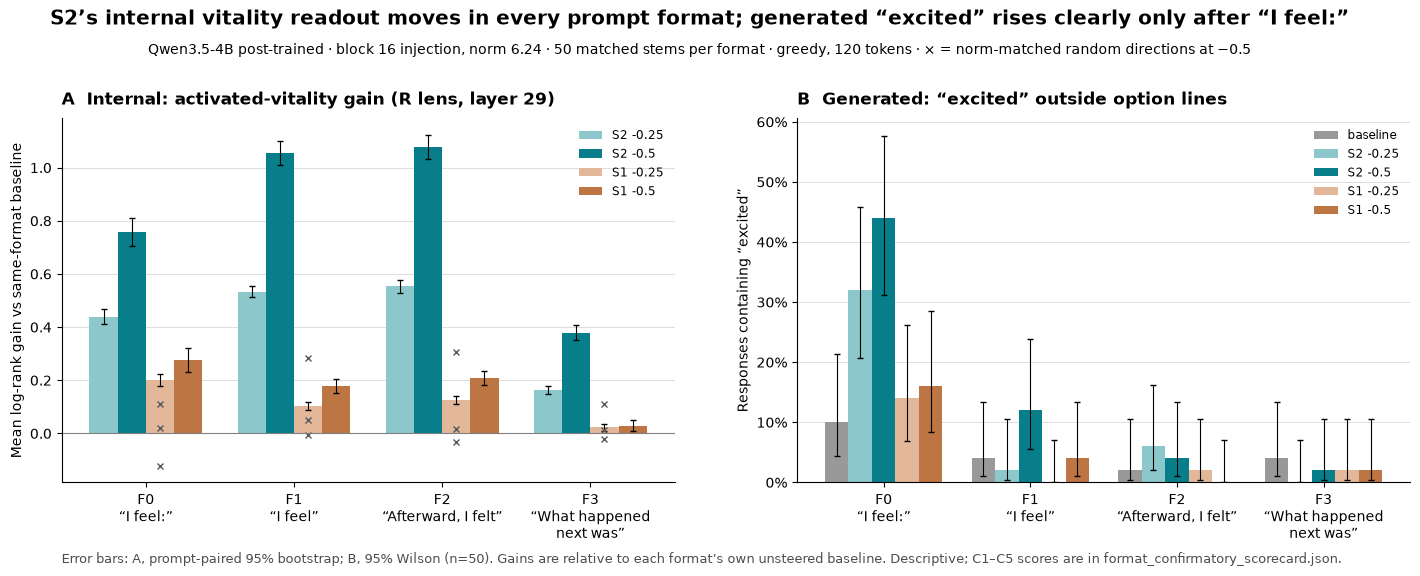

In [52]:
# =====================================================================
# Prompt-format robustness -- chunk 7c: SCORE C1-C5 (definitions as frozen
# in format_spec.json) and compute the pre-specified EXPLORATORY report.
# CPU only.  Run in the lens session (needs probe_terms, tok, token_kind,
# PSYCH_VOCAB, family_hit and chunk 2's text helpers).
# =====================================================================
import hashlib
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
dense_dir = paper_run_dir / "dense_sweep"
fmt_dir = paper_run_dir / "format_robustness"
figure_dir = paper_run_dir / "figures"
N_BOOT, BOOT_SEED = 20_000, 20260925
FOCUS = ["generic_positive", "activated_vitality", "relief_release",
         "agency_assurance", "approach_drive", "distress_self_devaluation"]
KINDS = ["word_like", "blank_like", "punct_symbol", "whitespace", "other"]
FORMAT_KINDS = ["blank_like", "punct_symbol", "whitespace"]
RANDOMS = ["random_1103", "random_2207", "random_3301"]
F_ALL, F_NEW = ["F0", "F1", "F2", "F3"], ["F1", "F2", "F3"]
sha = lambda b: hashlib.sha256(b).hexdigest()

spec_text = (fmt_dir / "format_spec.json").read_text()
spec = json.loads(spec_text)
spec_hash, dense_hash = sha(spec_text.encode()), spec["dense_spec_sha256"]
layers, LENS = spec["lens"]["layers"], spec["lens"]["lens_order"]
assert sha(probe_terms[["family", "term", "token_id"]].to_csv(index=False).encode()) == spec["lens"]["probe_terms_sha256"]
li28, li29, li30, kR = layers.index(28), layers.index(29), layers.index(30), LENS.index("R")
fam_cols = {f: np.flatnonzero(probe_terms.family.to_numpy() == f) for f in FOCUS}
ex_col = int(np.flatnonzero(probe_terms.term.to_numpy() == "excited")[0])
lens_conds = sorted({n.split("__", 1)[1] for n in spec["conditions"]})

rng = np.random.default_rng(BOOT_SEED)
IDX = rng.integers(0, 50, size=(N_BOOT, 50))
def ci(d):
    d = np.asarray(d, float)
    lo, hi = np.quantile(d[IDX].mean(1), [0.025, 0.975])
    return float(d.mean()), float(lo), float(hi)


# ---------------------------------------------------------------------
# 1. internal per-prompt arrays (F0 from the dense sweep)
# ---------------------------------------------------------------------
def load(fmt, cond):
    if fmt == "F0":
        path, want = dense_dir / "lens" / f"{cond}.npz", dense_hash
    else:
        path, want = fmt_dir / "lens" / f"{fmt}__{cond}.npz", spec_hash
    with np.load(path) as z:
        assert str(z["spec_sha256"]) == want, path
        return z["rank"], z["topk_id"]

R, TK = {}, {}
for f in F_ALL:
    for c in lens_conds:
        R[(f, c)], TK[(f, c)] = load(f, c)
G = {k: np.log(R[(k[0], "baseline")][:, li29, kR] / v[:, li29, kR]) for k, v in R.items()}   # [P, K]
gain = lambda f, c, fam: G[(f, c)][:, fam_cols[fam]].mean(1)                                 # per prompt

all_ids = np.unique(np.concatenate([v[:, [li28], kR].ravel() for v in TK.values()] +
                                   [TK[(f, "baseline")][:, :, kR].ravel() for f in F_ALL]))
kind_of = dict(zip(all_ids.tolist(), [token_kind(tok.decode([int(i)])) for i in all_ids]))
def format_like(f, c, li):
    ids = TK[(f, c)][:, li, kR]
    return np.array([[kind_of[int(t)] in FORMAT_KINDS for t in row] for row in ids]).mean(1)    # per prompt


# ---------------------------------------------------------------------
# 2. generated per-prompt metrics (frozen instruments only)
# ---------------------------------------------------------------------
gens = pd.DataFrame(json.loads(l) for l in (fmt_dir / "generations_assembled.jsonl").read_text(encoding="utf-8").splitlines())
assert (gens.spec_sha256 == spec_hash).all() and len(gens) == 1000
happy_re = re.compile(r"\bhappy\b", re.IGNORECASE)
rows = []
for r in gens.itertuples():
    part = partition_generated_text(r.text)
    scoped = {"full": r.text, "option": part["option_text"], "non_option": part["non_option_text"]}
    row = {"format": r.format, "cond": r.condition.split("__", 1)[1], "prompt_idx": r.prompt_idx}
    for s, t in scoped.items():
        row[f"excited__{s}"] = bool(excited_re.search(t))
        row[f"happy__{s}"] = bool(happy_re.search(t))
        for fam in PSYCH_VOCAB:
            row[f"{fam}__{s}"] = family_hit(t, fam)
    d = option_diagnostics(r.text)
    row.update(option_count=d["option_count"], repeated_options=d["max_identical_option_count"] >= 4,
               repeat4=repeated_4gram_fraction(r.token_ids))
    rows.append(row)
gp = pd.DataFrame(rows).sort_values(["format", "cond", "prompt_idx"]).reset_index(drop=True)
gp.to_csv(fmt_dir / "format_generated_per_prompt.csv", index=False)
gv = lambda f, c, col: gp[(gp.format == f) & (gp.cond == c)].sort_values("prompt_idx")[col].astype(float).to_numpy()


# ---------------------------------------------------------------------
# 3. confirmatory C1-C5
# ---------------------------------------------------------------------
res = {}
c1 = []
for f in F_NEW:
    for fam in ["activated_vitality", "generic_positive"]:
        m, lo, hi = ci(gain(f, "S2_-0.5", fam))
        f0 = gain("F0", "S2_-0.5", fam).mean()
        c1.append({"format": f, "family": fam, "gain": m, "ci_lo": lo, "ci_hi": hi, "F0_gain": f0, "ratio_to_F0": m / f0,
                   "pass": bool(lo > 0 and m / f0 >= 0.5)})
c1 = pd.DataFrame(c1); res["C1"] = bool(c1["pass"].all())

c2 = []
for f in F_ALL:
    m, lo, hi = ci(gain(f, "S2_-0.5", "activated_vitality") - gain(f, "S1_-0.5", "activated_vitality"))
    c2.append({"format": f, "S2_minus_S1": m, "ci_lo": lo, "ci_hi": hi, "pass": bool(lo > 0)})
c2 = pd.DataFrame(c2); res["C2"] = bool(c2["pass"].all())

c3 = []
for f in ["F2", "F3"]:
    m, lo, hi = ci(format_like(f, "baseline", li28) - format_like("F0", "baseline", li28))
    c3.append({"format": f, "metric": "format-like R28 top-50 (baseline)", "diff_vs_F0": m, "ci_lo": lo, "ci_hi": hi, "pass": bool(hi < 0)})
    m, lo, hi = ci(gv(f, "baseline", "option_count") - gv("F0", "baseline", "option_count"))
    c3.append({"format": f, "metric": "generated option count (baseline)", "diff_vs_F0": m, "ci_lo": lo, "ci_hi": hi, "pass": bool(hi < 0)})
c3 = pd.DataFrame(c3); res["C3"] = bool(c3["pass"].all())

c4 = []
for f in ["F1", "F2"]:
    m, lo, hi = ci(gv(f, "S2_-0.5", "excited__non_option") - gv(f, "baseline", "excited__non_option"))
    c4.append({"test": f"{f}: S2 -0.5 minus baseline", "diff": m, "ci_lo": lo, "ci_hi": hi, "pass": bool(lo > 0)})
m, lo, hi = ci(gv("F2", "S2_-0.5", "excited__non_option") - gv("F2", "S1_-0.5", "excited__non_option"))
c4.append({"test": "F2: S2 -0.5 minus S1 -0.5", "diff": m, "ci_lo": lo, "ci_hi": hi, "pass": bool(lo > 0)})
c4 = pd.DataFrame(c4); res["C4"] = bool(c4["pass"].all())

amp = lambda f, c: float(np.mean([abs(gain(f, c, fam).mean()) for fam in FOCUS]))
c5 = []
for f in F_NEW:
    for r in RANDOMS:
        ratio = amp(f, f"{r}_-0.5") / amp(f, "S2_-0.5")
        c5.append({"format": f, "random": r, "amp_random": amp(f, f"{r}_-0.5"), "amp_S2": amp(f, "S2_-0.5"), "ratio": ratio, "under_half": ratio < 0.5})
c5 = pd.DataFrame(c5)
c5_fmt = c5.groupby("format").under_half.sum()
res["C5"] = bool((c5_fmt >= 2).all())

pd.set_option("display.width", 200)
for k, t in [("C1", c1), ("C2", c2), ("C3", c3), ("C4", c4), ("C5", c5)]:
    print(f"\n{k}: {spec['confirmatory'][[x for x in spec['confirmatory'] if x.startswith(k)][0]][:150]}...")
    print(t.round(3).to_string(index=False))
    print(f"  -> {k} {'PASS' if res[k] else 'FAIL'}")
(fmt_dir / "format_confirmatory_scorecard.json").write_text(json.dumps(
    {"spec_sha256": spec_hash, "results": res,
     "tables": {k: t.round(4).to_dict("records") for k, t in [("C1", c1), ("C2", c2), ("C3", c3), ("C4", c4), ("C5", c5)]}},
    indent=2, default=float) + "\n")


# ---------------------------------------------------------------------
# 4. exploratory report (pre-specified; no pass/fail)
# ---------------------------------------------------------------------
print("\n" + "=" * 70 + "\nEXPLORATORY (pre-specified report, no pass/fail)\n" + "=" * 70)
star = lambda lo, hi: "*" if (lo > 0 or hi < 0) else " "

fam_rows = []
for f in F_ALL:
    for c in ["S2_-0.5", "S1_-0.5", "S2_-0.25", "S1_-0.25"]:
        for col in [f"{fam}__{s}" for fam in PSYCH_VOCAB for s in ["non_option", "option", "full"]] + \
                   [f"{w}__{s}" for w in ["excited", "happy"] for s in ["non_option", "option", "full"]]:
            m, lo, hi = ci(gv(f, c, col) - gv(f, "baseline", col))
            fam_rows.append({"format": f, "cond": c, "metric": col, "rate": gv(f, c, col).mean(),
                             "baseline": gv(f, "baseline", col).mean(), "diff": m, "ci_lo": lo, "ci_hi": hi})
fam_tab = pd.DataFrame(fam_rows)
fam_tab.to_csv(fmt_dir / "exploratory_family_hits.csv", index=False)
sub = fam_tab[(fam_tab.cond == "S2_-0.5") & fam_tab.metric.str.endswith("__non_option")].copy()
sub["cell"] = sub["diff"].map("{:+.2f}".format) + [star(a, b) for a, b in zip(sub.ci_lo, sub.ci_hi)]
print("\nS2 -0.5 minus baseline, non-option hit rates (* = paired CI excludes 0):")
print(sub.pivot(index="metric", columns="format", values="cell")[F_ALL].to_string())

on = []
for f in F_ALL:
    for c in ["S2_-0.25", "S1_-0.25"]:
        mi, loi, hii = ci(gain(f, c, "activated_vitality"))
        ml, lol, hil = ci(gv(f, c, "excited__non_option") - gv(f, "baseline", "excited__non_option"))
        on.append({"format": f, "cond": c, "internal_vitality": f"{mi:+.2f}{star(loi, hii)}", "excited_non_option": f"{ml:+.2f}{star(lol, hil)}"})
print("\n-0.25 view (internal R29 vitality gain | generated excited diff vs baseline; * = CI excludes 0):")
print(pd.DataFrame(on).pivot(index="cond", columns="format").to_string())

rs = pd.read_csv(fmt_dir / "read_slot_projections.csv")
rsr = []
for f in F_NEW:
    for k in ["S2", "S1", "common", "contrast"]:
        a = rs[rs.format == f].sort_values("prompt_idx")[f"z_{k}"].to_numpy()
        b = rs[rs.format == "F0"].sort_values("prompt_idx")[f"z_{k}"].to_numpy()
        m, lo, hi = ci(a - b)
        rsr.append({"format": f, "direction": k, "cell": f"{m:+.2f} [{lo:+.2f},{hi:+.2f}]"})
print("\nread slot, unsteered: per-stem z difference vs F0 (block 30):")
print(pd.DataFrame(rsr).pivot(index="direction", columns="format", values="cell").to_string())

comp = []
for f in F_ALL:
    for ly in [24, 26, 28, 30]:
        comp.append({"format": f, "layer": ly, "format_like": format_like(f, "baseline", layers.index(ly)).mean(),
                     "format_like_S2_-0.5": format_like(f, "S2_-0.5", layers.index(ly)).mean() if ly == 28 else np.nan})
comp = pd.DataFrame(comp)
comp.to_csv(fmt_dir / "exploratory_topk_format_like.csv", index=False)
print("\nformat-like fraction of the R-lens top-50 at baseline, by layer:")
print(comp.pivot(index="layer", columns="format", values="format_like").round(3).to_string())
print("\nsaved: format_confirmatory_scorecard.json, format_generated_per_prompt.csv, exploratory_family_hits.csv, "
      "exploratory_topk_format_like.csv")


# ---------------------------------------------------------------------
# 5. figure: internal vitality gain vs generated `excited`, per format
# ---------------------------------------------------------------------
def wilson(k, n=50, z=1.959964):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, p - (c - h)), max(0.0, (c + h) - p)

FLAB = {"F0": "F0\n“I feel:”", "F1": "F1\n“I feel”", "F2": "F2\n“Afterward, I felt”", "F3": "F3\n“What happened\nnext was”"}
CC = [("S2_-0.25", "#8CC7CB"), ("S2_-0.5", "#087E8B"), ("S1_-0.25", "#E3B89A"), ("S1_-0.5", "#BE7544")]
RC = {"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "svg.fonttype": "none"}
rec = []
with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))
    x = np.arange(4); w = 0.19
    for j, (c, col) in enumerate(CC):
        ys, lo, hi = [], [], []
        for f in F_ALL:
            m_, l_, h_ = ci(gain(f, c, "activated_vitality"))
            ys.append(m_); lo.append(m_ - l_); hi.append(h_ - m_)
            rec.append({"panel": "A", "format": f, "cond": c, "y": m_, "lo": l_, "hi": h_})
        axes[0].bar(x + (j - 1.5) * w, ys, w, color=col, yerr=[lo, hi], capsize=2, error_kw={"lw": 0.8}, label=c.replace("_", " "))
    for f_i, f in enumerate(F_ALL):
        for r in RANDOMS:
            axes[0].plot([f_i + 0.5 * w], [gain(f, f"{r}_-0.5", "activated_vitality").mean()], "x", color="0.35", ms=5)
    axes[0].axhline(0, color="0.5", lw=0.8)
    axes[0].set_title("A  Internal: activated-vitality gain (R lens, layer 29)", loc="left", fontweight="bold", pad=10)
    axes[0].set_ylabel("Mean log-rank gain vs same-format baseline")
    for j, (c, col) in enumerate([("baseline", "0.6")] + CC):
        ys, errs = [], [[], []]
        for f in F_ALL:
            k = int(gv(f, c, "excited__non_option").sum()); ys.append(k / 50)
            e = wilson(k); errs[0].append(e[0]); errs[1].append(e[1])
            rec.append({"panel": "B", "format": f, "cond": c, "y": k / 50})
        axes[1].bar(x + (j - 2) * 0.16, ys, 0.16, color=col, yerr=errs, capsize=2, error_kw={"lw": 0.8},
                    label=c.replace("_", " "))
    axes[1].set_title("B  Generated: “excited” outside option lines", loc="left", fontweight="bold", pad=10)
    axes[1].set_ylabel("Responses containing “excited”"); axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    for ax in axes:
        ax.set_xticks(x); ax.set_xticklabels([FLAB[f] for f in F_ALL]); ax.grid(axis="y", color="#dddddd", lw=0.7)
        ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=8.5, loc="upper right")
    fig.suptitle("S2’s internal vitality readout moves in every prompt format; generated “excited” rises clearly only after “I feel:”",
                 fontsize=14.5, fontweight="bold", y=1.03)
    fig.text(0.5, 0.965, "Qwen3.5-4B post-trained · block 16 injection, norm 6.24 · 50 matched stems per format · greedy, 120 tokens · "
             "× = norm-matched random directions at −0.5", ha="center", va="top", fontsize=10)
    fig.text(0.06, -0.035, "Error bars: A, prompt-paired 95% bootstrap; B, 95% Wilson (n=50). Gains are relative to each format’s own "
             "unsteered baseline. Descriptive; C1–C5 scores are in format_confirmatory_scorecard.json.", fontsize=9, color="0.3")
    fig.subplots_adjust(left=0.06, right=0.99, bottom=0.12, top=0.82, wspace=0.2)
    for ext in ["png", "svg"]:
        fig.savefig(figure_dir / f"format_robustness_internal_vs_lexical.{ext}", dpi=180, bbox_inches="tight")
    plt.show()
pd.DataFrame(rec).to_csv(figure_dir / "format_robustness_internal_vs_lexical_plot_data.csv", index=False)

# Prompt-format robustness: checkpoint (plan item 3)

Qwen3.5-4B post-trained, S1 and S2 (block 30 extraction, block 16
injection, norm 6.2439). The same 50 stems in four frozen formats:
F0 "... I feel:", F1 "... I feel", F2 "... Afterward, I felt",
F3 "... What happened next was". Conditions per format: baseline,
S1 and S2 at -0.25 and -0.5, and three norm-matched random directions
at -0.5 (lens arm only). Internal readouts are the frozen families at
R lens layer 29, measured at each format's final prompt token, against
that format's own unsteered baseline. F0 is reused from the dense
sweep.

## Provenance checks that passed
- F0 generation reuse gate: 15/15 regenerated rows token-identical to
  the dense sweep.
- 24 new lens conditions and 750 new generations under
  `format_spec.json`; confirmatory predictions and the exploratory
  report were written into the spec before any data existed.
- Every F0 condition is taken from the dense sweep's frozen arrays and
  rows (hash-checked).

## Confirmatory predictions and scores
| | Prediction | Result |
|---|---|---|
| C1 | In F1-F3, S2 -0.5 raises vitality and generic positive, each at least half its F0 value | Fail on F3 generic positive (ratio 0.441). F3 vitality passes at 0.501. F1 and F2 pass (ratios 0.72-1.43) |
| C2 | S2 -0.5 minus S1 -0.5 vitality gain positive in every format | Pass: F0 0.48, F1 0.88, F2 0.87, F3 0.35 |
| C3 | At baseline, format-like top-50 fraction (R28) and generated option count lower in F2 and F3 than F0 | Pass: format-like -0.64 and -0.73; option count -5.2 and -5.3 |
| C4 | In F1 and F2, S2 -0.5 raises non-option "excited"; in F2, S2 exceeds S1 | Fail: F1 +0.08 [0.00, 0.18], F2 +0.02, F2 S2-S1 +0.04 [0.00, 0.10] |
| C5 | Random directions at -0.5 move the six focus families less than half as much as S2, for at least 2 of 3 randoms per format | Pass: ratios 0.09-0.29 in F1/F2, 0.30-0.35 in F3 |

## Observations
- Internal vitality gain under S2 -0.5 is 0.76 (F0), 1.06 (F1),
  1.08 (F2), 0.38 (F3); at -0.25 it is 0.44, 0.53, 0.55, 0.16. All
  intervals exclude 0, including S1 at both doses.
- Generated "excited" outside option lines rises clearly only in F0
  (0.10 to 0.44 at -0.5; 0.32 at -0.25). In F1-F3 it stays at
  0.00-0.12 in every condition.
- The generated vitality family equals "excited" in every format
  (no other vitality word appears outside option lines).
- The "I feel:" colon recruits answer-slot structure: at baseline the
  R28 top-50 is 79% format-like tokens in F0 against 7-15% in F1-F3,
  and F0 responses average 6.0 option lines against 0.66-0.94.
  Steering raises option count in F2 (0.78 to 2.18) and F3 (0.66 to
  1.72) even without the colon.
- In F3, " excited" is not a plausible next token (baseline L30 rank
  about 41,000; about 16,700 under S2 -0.5), yet the vitality family
  still moves internally (+0.38).
- Unsteered read slot (block 30, per-stem difference vs F0): F3 reads
  +1.40 on contrast and +0.70 on S2; F1 and F2 shift +0.27 to +0.39
  on every axis.
- Exploratory lexical table (S2 -0.5 minus baseline, non-option): the
  only interval excluding 0 outside F0 is relief_release in F1
  (+0.12).

## What the frozen instrument misses (text inspection, not scored)
- Plain-text continuations are largely pretraining genre in every
  format, baseline included: fill-in-the-blank quizzes with A-D
  options, exam questions in Chinese, repeated listing spam, leaked
  `<think>` blocks, looping narratives.
- Steered text contains positive-affect words the frozen vocabulary
  does not match: "a little bit of excitement" (F1), "very happy"
  followed by four identical options reading 高兴 ("happy") (F1),
  "relieved" repeated across option lines (F2).
- The frozen vocabulary is English, whole-word and adjectival; it
  cannot see derived forms or non-English output. C4's failure is
  partly an instrument limit. `psych_vocab_v1` stays frozen; any
  broader lexical measure is a new versioned instrument.

## Reading
Within the frozen English vocabulary, the generated "excited"
phenotype depends on the "I feel:" answer-slot genre. The internal S2
readout does not: it is present in every format and larger without
the colon (F1, F2), and the S2-versus-S1 difference is present in
every format. This is the plan's "particularly informative outcome":
internal structure that survives while generated vocabulary changes a
lot with the prompt. One model, one readout layer, 50 stems.

## Changes to the candidate-claim list
- New candidate 10: S2's internal family readout at the prompt's final
  token does not require the "I feel:" answer slot (C1 in F1 and F2,
  C2 in all formats).
- New candidate 11: within `psych_vocab_v1`, the generated "excited"
  phenotype is conditional on the "I feel:" format (C3 pass, C4 fail).
- Candidate v2 lexical instruments, to be defined and frozen before
  testing on fresh stems: morphological variants of the vitality and
  relief families; a relief-family prediction for "I feel" (F1); a
  non-English affect check.

## Caveats
One model, one readout layer, 50 stems per format; the internal
readout is taken before any generated token, so it says nothing
about what the model writes later in a response; formats differ in
more than the answer slot (tense, narrative framing); F3's C1 result
sits on the threshold for vitality; random-direction ratios are
higher in F3, where S2's own effect is smallest.

## Artifacts
`format_robustness/`: `format_spec.json`, `read_slot_projections.csv`,
`lens/*.npz` (large; manifest them), `lens_glance_R29.csv`,
`generation_reuse_gate.csv`, `generations_new.jsonl`,
`generations_assembled.jsonl`, `format_generated_per_prompt.csv`,
`format_confirmatory_scorecard.json`, `exploratory_family_hits.csv`,
`exploratory_topk_format_like.csv`.
`figures/format_robustness_internal_vs_lexical.{png,svg}` and plot data.

## Next
Plan item 4, the "excited" lexical-mediation ablation. These results
scope it: the lexical path exists mainly in F0, so the ablation is
most informative there, with F2 as the comparison where the internal
effect is present without the word.

In [53]:
# =====================================================================
# Plan item 4 (`excited` lexical-mediation ablation) -- chunk 8a:
# INSPECT ONLY. Tokenize the mediator variants, check collateral damage
# against every word in our existing generations, propose a frequency-matched
# random-token control set.  No generation, nothing frozen.
# Run in the lens session (needs tok, PSYCH_VOCAB).
# =====================================================================
import json
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
SEED = 20260925

# ---------------------------------------------------------------------
# 1. mediator variants (plan: excited, excitement, capitalization / prefix variants)
# ---------------------------------------------------------------------
VARIANTS = ["excited", "excitement", "Excited", "Excitement", "EXCITED", "EXCITEMENT"]
rows = []
for v in VARIANTS:
    for pre in ["", " ", "\n"]:
        ids = tok.encode(pre + v, add_special_tokens=False)
        rows.append({"text": repr(pre + v), "n_tokens": len(ids), "ids": ids,
                     "pieces": [tok.decode([i]) for i in ids]})
tv = pd.DataFrame(rows)
print("mediator variant tokenization:")
print(tv.to_string(index=False))

# candidate mediator ids = first token of each variant, EXCEPT a bare newline piece
first_ids = sorted({r["ids"][1] if r["pieces"][0] == "\n" and len(r["ids"]) > 1 else r["ids"][0] for r in rows})
print("\ncandidate mediator first-token ids:", {i: tok.decode([i]) for i in first_ids})

# ---------------------------------------------------------------------
# 2. collateral check: which OTHER words in our own generations start with a candidate id?
# ---------------------------------------------------------------------
def load_jsonl(p):
    return pd.DataFrame(json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip())

texts = []
for p in [paper_run_dir / "dense_sweep" / "generations_assembled.jsonl",
          paper_run_dir / "format_robustness" / "generations_assembled.jsonl",
          paper_run_dir / "plane_sweep" / "generations.jsonl"]:
    if p.exists():
        texts += load_jsonl(p).text.tolist()
words = Counter(w for t in texts for w in re.findall(r"[A-Za-z]+", t))
print(f"\n{len(texts)} existing generations, {len(words)} distinct words")
target = re.compile(r"^excit(ed|ement)$", re.IGNORECASE)
hits = []
for w, n in words.items():
    for pre in [" ", ""]:
        i0 = tok.encode(pre + w, add_special_tokens=False)[0]
        if i0 in first_ids:
            hits.append({"word": w, "prefix": repr(pre), "count": n, "first_id": i0, "intended": bool(target.match(w))})
hits = pd.DataFrame(hits)
if len(hits):
    print("\nwords in our generations whose first token is a candidate mediator id:")
    print(hits.sort_values(["intended", "count"], ascending=[True, False]).to_string(index=False))
    coll = hits[~hits.intended]
    print(f"\nCOLLATERAL (unintended words blocked): {len(coll)} distinct, {int(coll['count'].sum())} occurrences"
          if len(coll) else "\nno collateral words found in our generations")

# ---------------------------------------------------------------------
# 3. how often does the normal S2 -0.5 (F0) run use a mediator id? (sets the size of the 8b gate)
# ---------------------------------------------------------------------
dense = load_jsonl(paper_run_dir / "dense_sweep" / "generations_assembled.jsonl")
s2 = dense[dense.condition == "S2_-0.5"].sort_values("prompt_idx")
base = dense[dense.condition == "baseline"].sort_values("prompt_idx")
uses = lambda ids: any(i in set(first_ids) for i in ids)
print(f"\nrows emitting a mediator id: S2 -0.5 {int(s2.token_ids.map(uses).sum())}/50, "
      f"baseline {int(base.token_ids.map(uses).sum())}/50  "
      f"(rows that never emit one must regenerate token-identically under suppression: the 8b gate)")

# ---------------------------------------------------------------------
# 4. proposed random-token control: same count, word-like, document frequency in
#    the normal S2 -0.5 run within 0.5x-2x of the mediator's
# ---------------------------------------------------------------------
doc_freq = lambda tid, rows_: float(np.mean([tid in set(r) for r in rows_]))
med_df = float(np.mean([uses(r) for r in s2.token_ids]))
psych_ids = {tok.encode(" " + t, add_special_tokens=False)[0] for ts in PSYCH_VOCAB.values() for t in ts}
STOP = set("the a an and or but of to in on at for with from by is was were be been are am it its this that "
           "these those i you he she they we me my your our their his her them us not no so as if then than "
           "very just also have has had do does did will would can could should".split())
cand = Counter(i for r in s2.token_ids for i in set(r))
pool = []
for tid, n in cand.items():
    s = tok.decode([tid])
    w = s.strip()
    if not (s.startswith(" ") and w.isalpha() and len(w) >= 4 and w.lower() not in STOP):
        continue
    if tid in psych_ids or tid in first_ids:
        continue
    df = n / len(s2)
    if 0.5 * med_df <= df <= 2 * med_df:
        pool.append((tid, s, df))
pool.sort()
rng = np.random.default_rng(SEED)
k = len(first_ids)
pick = [pool[j] for j in rng.choice(len(pool), size=min(k, len(pool)), replace=False)] if pool else []
print(f"\nmediator document frequency in S2 -0.5: {med_df:.2f}; control pool (0.5x-2x): {len(pool)} tokens")
print("proposed control ids (seeded draw, same count as mediator ids):", {t: s for t, s, _ in pick})
print("\nNothing frozen. Review the mediator ids (no unintended collateral?) and the control draw, then 8b freezes them.")

mediator variant tokenization:
          text  n_tokens                          ids                 pieces
     'excited'         2                [38135, 1552]            [exc, ited]
    ' excited'         1                      [11692]             [ excited]
   '\nexcited'         3           [198, 38135, 1552]        [\n, exc, ited]
  'excitement'         2              [38135, 171449]         [exc, itement]
 ' excitement'         1                      [26382]          [ excitement]
'\nexcitement'         3         [198, 38135, 171449]     [\n, exc, itement]
     'Excited'         2                [40343, 1552]            [Exc, ited]
    ' Excited'         2                [37608, 1552]           [ Exc, ited]
   '\nExcited'         3           [198, 40343, 1552]        [\n, Exc, ited]
  'Excitement'         2              [40343, 171449]         [Exc, itement]
 ' Excitement'         2              [37608, 171449]        [ Exc, itement]
'\nExcitement'         3         [198, 40343,

In [55]:
# =====================================================================
# Plan item 4 (`excited` lexical-mediation ablation) -- chunk 8b.
#   DRY_RUN = True  (default): print banned sequences, control draw, gate size.
#                              Nothing written.
#   DRY_RUN = False           : freeze mediation_spec.json and generate.
# Bans are EXACT token sequences (HF bad_words_ids), not first-token prefixes,
# so unrelated words ("Excellent", "exceptional") stay available.
# Run in the lens session (needs hf, tok, prefix_steering, paper_spec,
# PSYCH_VOCAB and chunk 2's text helpers).
# =====================================================================
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

DRY_RUN = False
paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
dense_dir = paper_run_dir / "dense_sweep"
med_dir = paper_run_dir / "mediation"
SEED = 20260925
MEDIATOR_WORDS = ["excited", "excitement"]
FRAME_WORDS = {"feel", "feels", "felt", "feeling", "feelings", "emotion", "emotions", "mood"}
AFFECT_EXCLUDE = set("""tired happy sad angry calm good bad great nice fine glad upset worried anxious nervous scared afraid
bored boring lonely proud hurt love loved hate sorry relieved relief joy fear pain painful fun funny amazing awesome
wonderful terrible awful lucky grateful thankful surprised surprise shocked hope hopeful peaceful safe comfortable
uncomfortable stressed stress exhausted sleepy weird strange curious interested interesting
hungry thirsty cold hot warm sick sore dizzy numb""".split())
MIN_DF, MAX_CONTROL_WORDS = 0.02, 8
STOP = set("the a an and or but of to in on at for with from by is was were be been are am it its this that "
           "these those i you he she they we me my your our their his her them us not no so as if then than "
           "very just also have has had do does did will would can could should there here what when which who "
           "about into out over more some any all one two".split())
sha_bytes = lambda b: hashlib.sha256(b).hexdigest()
sha_tensor = lambda t: sha_bytes(t.contiguous().numpy().tobytes())

# ---------------------------------------------------------------------
# 1. banned sequences for a list of words: lower / Capitalized / UPPER, with and without a leading space
# ---------------------------------------------------------------------
def sequences_for(words):
    seqs = set()
    for w in words:
        for form in {w.lower(), w.capitalize(), w.upper()}:
            for pre in ["", " "]:
                seqs.add(tuple(tok.encode(pre + form, add_special_tokens=False)))
    return sorted(seqs)

def contains(ids, seqs):
    ids = list(ids)
    for s in seqs:
        n = len(s)
        if any(tuple(ids[k:k + n]) == s for k in range(len(ids) - n + 1)):
            return True
    return False

mediator_seqs = sequences_for(MEDIATOR_WORDS)
print("mediator banned sequences:")
for s in mediator_seqs:
    print(f"   {list(s)}  {''.join(tok.decode([i]) for i in s)!r}")

# ---------------------------------------------------------------------
# 2. control draw: same number of lexemes, affect-neutral, not frame words,
#    not think-block genre, document frequency within 0.25x-2x of the mediator's
# ---------------------------------------------------------------------
dense = pd.DataFrame(json.loads(l) for l in (dense_dir / "generations_assembled.jsonl").read_text(encoding="utf-8").splitlines())
normal = {c: dense[dense.condition == c].sort_values("prompt_idx").reset_index(drop=True) for c in ["S2_-0.5", "baseline"]}
split_think = lambda t: (re.sub(r"<think>.*?(</think>|$)", " ", t, flags=re.S), " ".join(re.findall(r"<think>(.*?)(?:</think>|$)", t, flags=re.S)))
outside = [split_think(t)[0] for t in normal["S2_-0.5"].text]
inside = [split_think(t)[1] for t in normal["S2_-0.5"].text]
wre = lambda w: re.compile(rf"(?<![A-Za-z]){re.escape(w)}(?![A-Za-z])", re.IGNORECASE)
med_df = float(np.mean([any(wre(w).search(t) for w in MEDIATOR_WORDS) for t in outside]))
psych_terms = {t.lower() for ts in PSYCH_VOCAB.values() for t in ts}
cnt_out = Counter(w.lower() for t in outside for w in re.findall(r"[A-Za-z]+", t))
cnt_in = Counter(w.lower() for t in inside for w in re.findall(r"[A-Za-z]+", t))
pool = []
for w in sorted(cnt_out):
    if len(w) < 4 or w in STOP or w in FRAME_WORDS or w in AFFECT_EXCLUDE or w in psych_terms or w.startswith("excit"):
        continue
    if cnt_in[w] >= cnt_out[w]:                       # mostly think-block genre
        continue
    df = float(np.mean([bool(wre(w).search(t)) for t in outside]))
    if df >= MIN_DF:
        pool.append((w, df))
# most frequent eligible neutral words first (ties broken alphabetically); add until their UNION
# document frequency reaches the mediator's or MAX_CONTROL_WORDS is hit.  Deterministic.
has = {w: np.array([bool(wre(w).search(t)) for t in outside]) for w, _ in pool}
control_words, cover = [], np.zeros(len(outside), bool)
for w, _ in sorted(pool, key=lambda x: (-x[1], x[0])):
    if cover.mean() >= med_df or len(control_words) >= MAX_CONTROL_WORDS:
        break
    control_words.append(w); cover |= has[w]
control_words = sorted(control_words)
control_df = float(cover.mean())
control_seqs = sequences_for(control_words)
print(f"\nmediator document frequency (S2 -0.5, outside think blocks): {med_df:.2f}")
print(f"control pool (df >= {MIN_DF}, filtered): {len(pool)} words: "
      + ", ".join(f"{w} {d:.2f}" for w, d in sorted(pool, key=lambda x: -x[1])[:20]))
print(f"control draw: {control_words}  (union document frequency {control_df:.2f} vs mediator {med_df:.2f})")
for s in control_seqs:
    print(f"   {list(s)}  {''.join(tok.decode([i]) for i in s)!r}")

# ---------------------------------------------------------------------
# 3. conditions (F0 prompts) and gate sizes
# ---------------------------------------------------------------------
prompts = json.loads((paper_run_dir / "spec.json").read_text())["prompts"]
sv = torch.load(paper_run_dir / "steering_vectors.pt", map_location="cpu", weights_only=True)
S2 = sv["S2"].float()
dense_spec = json.loads((dense_dir / "dense_spec.json").read_text())
assert sha_tensor(S2) == dense_spec["vector_sha256"]["S2"]
BANS = {"mediator": mediator_seqs, "control": control_seqs}
CONDS = {f"{src}__ban_{b}": {"steer": src, "ban": b} for src in ["S2_-0.5", "baseline"] for b in BANS}
gate_rows = {n: [i for i, ids in enumerate(normal[c["steer"]].token_ids) if not contains(ids, BANS[c["ban"]])]
             for n, c in CONDS.items()}
print("\nnew conditions (normal runs are reused from the dense sweep):")
for n in CONDS:
    print(f"   {n:26s} gate rows (normal output never contains a banned sequence): {len(gate_rows[n])}/50")

PREDICTIONS = {
    "M0_mechanics": "Under each ban, no generated row contains a banned sequence; gate rows regenerate token-identically "
                    "to the normal run.",
    "M1_classification": (
        "Pre-specified classification, not a directional prediction. P = share of responses with any non-option hit in "
        "generic_positive, calm_positive, relief_release, or activated_vitality excluding 'excited' (psych_vocab_v1 terms). "
        "Compare S2 -0.5 with the mediator ban against S2 -0.5 normal and against baseline normal (prompt-paired bootstrap). "
        "BROAD STATE: P(ban) exceeds baseline (CI excludes 0) and is not below P(normal) by more than 0.10. "
        "BOTTLENECK: P(ban) does not exceed baseline (CI includes 0). Anything else: PARTIAL."),
    "M1b_within_family": (
        "Reported, no prediction: vitality words other than 'excited' (psych_vocab_v1 activated_vitality minus 'excited'), "
        "non-option, S2 -0.5 mediator-ban minus S2 -0.5 normal, prompt-paired bootstrap. Answers the plan's question "
        "whether eager/energetic/enthusiastic/lively etc. appear when 'excited' is unavailable."),
    "M2_control": "The control ban does not change P under S2 -0.5 (paired CI of control-ban minus normal includes 0).",
    "exploratory": "Words whose non-option document frequency rises most from S2 -0.5 normal to S2 -0.5 mediator-ban "
                   "(top 25), format metrics, all nine family rates in all scopes. No pass/fail.",
}

if DRY_RUN:
    print("\nDRY_RUN: nothing written. Review the sequences and control draw, then set DRY_RUN = False.")
else:
    # -----------------------------------------------------------------
    # 4. freeze
    # -----------------------------------------------------------------
    med_dir.mkdir(parents=True, exist_ok=True)
    spec = {"purpose": "plan item 4: excited lexical-mediation ablation (F0, S2 -0.5 and baseline)",
            "dense_spec_sha256": sha_bytes((dense_dir / "dense_spec.json").read_bytes()),
            "vocab_sha256": sha_bytes((paper_run_dir / "s1_comparison" / "psych_vocab_v1.json").read_bytes()),
            "prompts_sha256": sha_bytes(json.dumps(prompts).encode()), "s2_sha256": sha_tensor(S2),
            "generation": paper_spec["generation"], "ban_mechanism": "HF bad_words_ids (exact token sequences)",
            "mediator_words": MEDIATOR_WORDS, "mediator_sequences": [list(s) for s in mediator_seqs],
            "control_rule": "alphabetic, >=4 chars, not stopword/frame word/affect-exclusion list/psych_vocab_v1/excit*, "
                            "not mostly inside think blocks, document frequency >= 0.02 in S2 -0.5 normal (outside think "
                            "blocks); most frequent first, added until union document frequency reaches the mediator's "
                            "or 8 words. If the union falls short, M2 is a weaker control and is reported as such.",
            "affect_exclusion_list": sorted(AFFECT_EXCLUDE), "control_union_df": control_df, "mediator_df": med_df,
            "control_words": control_words, "control_sequences": [list(s) for s in control_seqs],
            "conditions": CONDS, "normal_runs": "reused: dense_sweep S2_-0.5 and baseline", "predictions": PREDICTIONS}
    spec_path = med_dir / "mediation_spec.json"
    spec_text = json.dumps(spec, indent=2) + "\n"
    if spec_path.exists():
        assert spec_path.read_text() == spec_text, "mediation_spec.json changed since it was frozen"
    else:
        spec_path.write_text(spec_text)
    spec_hash = sha_bytes(spec_text.encode())
    print("mediation spec frozen:", spec_hash[:16])

    # -----------------------------------------------------------------
    # 5. generation: mirrors chunk 2's paper_generate, plus bad_words_ids.
    #    Gate rows first (fail fast), then the rest.  Resumable.
    # -----------------------------------------------------------------
    def banned_generate(text, coeff, vector, seqs):
        inputs = tok(text, return_tensors="pt").to(hf.device)
        n_prefix = inputs["input_ids"].shape[1]
        with prefix_steering(coeff, vector):
            with torch.inference_mode():
                out = hf.generate(**inputs, **paper_spec["generation"], pad_token_id=tok.pad_token_id,
                                  bad_words_ids=[list(s) for s in seqs])
        ids = out[0, n_prefix:].cpu()
        return {"text": tok.decode(ids, skip_special_tokens=True), "token_ids": ids.tolist(), "token_count": len(ids),
                "hit_limit": len(ids) == paper_spec["generation"]["max_new_tokens"]}

    out_path = med_dir / "generations_new.jsonl"
    done = {}
    if out_path.exists():
        lines = out_path.read_text(encoding="utf-8").splitlines()
        good = []
        for k, line in enumerate(lines):
            try:
                good.append(json.loads(line))
            except json.JSONDecodeError:
                assert k == len(lines) - 1, f"corrupt line {k} is not the last one"
        if len(good) != len(lines):
            out_path.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in good), encoding="utf-8")
        for r in good:
            assert r["spec_sha256"] == spec_hash
            done[(r["condition"], r["prompt_idx"])] = r

    jobs = [(n, i) for n in CONDS for i in gate_rows[n]] + \
           [(n, i) for n in CONDS for i in range(50) if i not in set(gate_rows[n])]
    with out_path.open("a", encoding="utf-8") as out:
        for k, (n, i) in enumerate(tqdm(jobs, desc="mediation generations")):
            if (n, i) in done:
                continue
            c = CONDS[n]
            coeff, v = (-0.5, S2) if c["steer"] == "S2_-0.5" else (0.0, None)
            res = banned_generate(prompts[i], coeff, v, BANS[c["ban"]])
            row = {"spec_sha256": spec_hash, "condition": n, "prompt_idx": i, "is_gate_row": i in gate_rows[n], **res}
            out.write(json.dumps(row, ensure_ascii=False) + "\n"); out.flush()
            done[(n, i)] = row
            if row["is_gate_row"]:
                assert res["token_ids"] == list(normal[c["steer"]].loc[i, "token_ids"]), \
                    f"gate failure: {n} prompt {i} differs although the normal run never used a banned sequence"
    print("gate rows: all token-identical to the normal run")

    # -----------------------------------------------------------------
    # 6. M0 check + glance (M1/M2 scoring and the exploratory table are 8c)
    # -----------------------------------------------------------------
    rows = pd.DataFrame(done.values())
    leaks = rows[[contains(r.token_ids, BANS[CONDS[r.condition]["ban"]]) for r in rows.itertuples()]]
    print("M0: banned sequences in banned runs:", len(leaks), "(must be 0)")
    assert len(leaks) == 0
    allrows = pd.concat([rows.assign(source="new")] +
                        [normal[c].assign(condition=f"{c}__normal", source="dense_sweep") for c in normal], ignore_index=True)
    nonopt = allrows.text.map(lambda t: partition_generated_text(t)["non_option_text"])
    POS = ["generic_positive", "calm_positive", "relief_release"]
    vit_other = [t for t in PSYCH_VOCAB["activated_vitality"] if t.lower() != "excited"]
    vit_re = [re.compile(rf"(?<!\w){re.escape(t)}(?!\w)", re.IGNORECASE) for t in vit_other]
    allrows["excited"] = nonopt.map(lambda t: bool(excited_re.search(t)))
    allrows["vitality_other"] = nonopt.map(lambda t: any(p.search(t) for p in vit_re))
    allrows["P_positive"] = [any(family_hit(t, f) for f in POS) or vo for t, vo in zip(nonopt, allrows.vitality_other)]
    allrows["repeated_options"] = allrows.text.map(lambda t: option_diagnostics(t)["max_identical_option_count"] >= 4)
    g = allrows.groupby("condition")[["excited", "vitality_other", "P_positive", "repeated_options"]].mean()
    print("\nnon-option rates (n=50 each):")
    print(g.round(2).to_string())
    allrows.to_json(med_dir / "generations_all.jsonl", orient="records", lines=True, force_ascii=False)

mediator banned sequences:
   [3152, 34, 11630, 1762]  'EXCITEMENT'
   [3152, 34, 75815]  'EXCITED'
   [3927, 34, 11630, 1762]  ' EXCITEMENT'
   [3927, 34, 75815]  ' EXCITED'
   [11692]  ' excited'
   [26382]  ' excitement'
   [37608, 1552]  ' Excited'
   [37608, 171449]  ' Excitement'
   [38135, 1552]  'excited'
   [38135, 171449]  'excitement'
   [40343, 1552]  'Excited'
   [40343, 171449]  'Excitement'

mediator document frequency (S2 -0.5, outside think blocks): 0.70
control pool (df >= 0.02, filtered): 143 words: answer 0.18, following 0.10, bird 0.04, contact 0.04, example 0.04, generates 0.04, living 0.04, looking 0.04, moving 0.04, noticeable 0.04, rock 0.04, temperature 0.04, thing 0.04, tree 0.04, type 0.04, acting 0.02, autotrophs 0.02, becoming 0.02, between 0.02, bottom 0.02
control draw: ['answer', 'bird', 'contact', 'example', 'following', 'generates', 'living', 'looking']  (union document frequency 0.22 vs mediator 0.70)
   [33, 43673]  'BIRD'
   [37, 29204, 1658]  'FOL

mediation generations: 100%|█████████████████████████████████████████████████████████| 200/200 [40:11<00:00, 12.06s/it]

gate rows: all token-identical to the normal run
M0: banned sequences in banned runs: 0 (must be 0)

non-option rates (n=50 each):
                        excited  vitality_other  P_positive  repeated_options
condition                                                                    
S2_-0.5__ban_control       0.54             0.0        0.60              0.20
S2_-0.5__ban_mediator      0.00             0.0        0.44              0.18
S2_-0.5__normal            0.44             0.0        0.44              0.12
baseline__ban_control      0.10             0.0        0.32              0.14
baseline__ban_mediator     0.00             0.0        0.24              0.12
baseline__normal           0.10             0.0        0.30              0.08


In [56]:
# =====================================================================
# Plan item 4 -- chunk 8c: SCORE the frozen mediation predictions
# (M1 classification, M1b report, M2) and compute the pre-specified exploratory
# tables. CPU only. Run in the lens session (needs PSYCH_VOCAB, family_hit,
# excited_re, partition_generated_text, option_diagnostics, repeated_4gram_fraction).
# =====================================================================
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

paper_run_dir = Path("runs/qwen35-4b-posttrained-s2/paper_protocol")
med_dir = paper_run_dir / "mediation"
N_BOOT, BOOT_SEED = 20_000, 20260925
spec_text = (med_dir / "mediation_spec.json").read_text()
spec = json.loads(spec_text)
spec_hash = hashlib.sha256(spec_text.encode()).hexdigest()

rows = pd.read_json(med_dir / "generations_all.jsonl", lines=True)
new = rows[rows.source == "new"]
assert (new.spec_sha256 == spec_hash).all() and len(rows) == 300
conds = ["baseline__normal", "baseline__ban_mediator", "baseline__ban_control",
         "S2_-0.5__normal", "S2_-0.5__ban_mediator", "S2_-0.5__ban_control"]

# ---------------------------------------------------------------------
# per-row metrics (frozen definitions from the spec)
# ---------------------------------------------------------------------
POS = ["generic_positive", "calm_positive", "relief_release"]
vit_other = [t for t in PSYCH_VOCAB["activated_vitality"] if t.lower() != "excited"]
vit_re = [re.compile(rf"(?<!\w){re.escape(t)}(?!\w)", re.IGNORECASE) for t in vit_other]
happy_re = re.compile(r"\bhappy\b", re.IGNORECASE)
recs = []
for r in rows.itertuples():
    part = partition_generated_text(r.text)
    sc = {"non_option": part["non_option_text"], "option": part["option_text"], "full": r.text}
    vo = any(p.search(sc["non_option"]) for p in vit_re)
    rec = {"condition": r.condition, "prompt_idx": r.prompt_idx,
           "P_positive": any(family_hit(sc["non_option"], f) for f in POS) or vo, "vitality_other": vo}
    for s, t in sc.items():
        rec[f"excited__{s}"] = bool(excited_re.search(t))
        rec[f"happy__{s}"] = bool(happy_re.search(t))
        for fam in PSYCH_VOCAB:
            rec[f"{fam}__{s}"] = family_hit(t, fam)
    d = option_diagnostics(r.text)
    rec.update(option_count=d["option_count"], repeated_options=d["max_identical_option_count"] >= 4,
               repeat4=repeated_4gram_fraction(r.token_ids), non_option_text=sc["non_option"], text=r.text)
    recs.append(rec)
pr = pd.DataFrame(recs).sort_values(["condition", "prompt_idx"]).reset_index(drop=True)
pr.drop(columns=["non_option_text", "text"]).to_csv(med_dir / "mediation_per_prompt.csv", index=False)
col = lambda c, k: pr[pr.condition == c].sort_values("prompt_idx")[k].astype(float).to_numpy()

rng = np.random.default_rng(BOOT_SEED)
IDX = rng.integers(0, 50, size=(N_BOOT, 50))
def paired(a, b):
    d = a - b
    lo, hi = np.quantile(d[IDX].mean(1), [0.025, 0.975])
    return float(d.mean()), float(lo), float(hi)
fmt = lambda t: f"{t[0]:+.2f} [{t[1]:+.2f}, {t[2]:+.2f}]"

# ---------------------------------------------------------------------
# M1 / M1b / M2
# ---------------------------------------------------------------------
P = {c: col(c, "P_positive") for c in conds}
d_base = paired(P["S2_-0.5__ban_mediator"], P["baseline__normal"])
d_norm = paired(P["S2_-0.5__ban_mediator"], P["S2_-0.5__normal"])
d_norm_base = paired(P["S2_-0.5__normal"], P["baseline__normal"])
if d_base[1] > 0:
    m1 = "BROAD STATE" if d_norm[0] >= -0.10 else "PARTIAL"
else:
    m1 = "BOTTLENECK"
m1b = paired(col("S2_-0.5__ban_mediator", "vitality_other"), col("S2_-0.5__normal", "vitality_other"))
m2 = paired(P["S2_-0.5__ban_control"], P["S2_-0.5__normal"])
m2_pass = m2[1] <= 0 <= m2[2]

print("P = share with any non-option hit in generic_positive, calm_positive, relief_release, or vitality minus 'excited'")
print("  rates:", {c: round(P[c].mean(), 2) for c in conds})
print(f"\n  [reference] S2 normal - baseline:          {fmt(d_norm_base)}")
print(f"  S2 mediator-ban - baseline:                 {fmt(d_base)}")
print(f"  S2 mediator-ban - S2 normal:                {fmt(d_norm)}")
print(f"  -> M1 classification: {m1}")
print(f"\nM1b (report): other vitality words, S2 ban - S2 normal: {fmt(m1b)}  "
      f"(rates {col('S2_-0.5__ban_mediator', 'vitality_other').mean():.2f} vs {col('S2_-0.5__normal', 'vitality_other').mean():.2f})")
print(f"\nM2: S2 control-ban - S2 normal on P: {fmt(m2)}  -> {'PASS (no change)' if m2_pass else 'FAIL (control changed P)'}"
      f"  [control union document frequency {spec['control_union_df']:.2f} vs mediator {spec['mediator_df']:.2f}: weak control]")
(med_dir / "mediation_scorecard.json").write_text(json.dumps({
    "spec_sha256": spec_hash, "M1": {"classification": m1, "ban_minus_baseline": d_base, "ban_minus_normal": d_norm,
                                     "normal_minus_baseline": d_norm_base},
    "M1b": {"ban_minus_normal": m1b}, "M2": {"pass": bool(m2_pass), "control_minus_normal": m2}}, indent=2) + "\n")

# ---------------------------------------------------------------------
# exploratory (pre-specified): family rates, substitution table, format metrics
# ---------------------------------------------------------------------
print("\n" + "=" * 70 + "\nEXPLORATORY (pre-specified, no pass/fail)\n" + "=" * 70)
fams = list(PSYCH_VOCAB) + ["excited", "happy"]
rates = pr.groupby("condition")[[f"{f}__non_option" for f in fams]].mean().loc[conds]
rates.columns = [c.replace("__non_option", "") for c in rates.columns]
rates.to_csv(med_dir / "exploratory_family_rates_non_option.csv")
print("\nnon-option family hit rates:")
print(rates.T.round(2).to_string())

words = lambda t: set(w.lower() for w in re.findall(r"[A-Za-z]{3,}", t))
def doc_freq(c):
    ws = [words(t) for t in pr[pr.condition == c].non_option_text]
    return Counter(w for s in ws for w in s)
a, b = doc_freq("S2_-0.5__ban_mediator"), doc_freq("S2_-0.5__normal")
sub = pd.DataFrame([{"word": w, "ban": a[w] / 50, "normal": b[w] / 50, "change": (a[w] - b[w]) / 50} for w in set(a) | set(b)])
sub = sub.sort_values(["change", "word"], ascending=[False, True])
sub.to_csv(med_dir / "exploratory_substitution_S2.csv", index=False)
print("\nwords rising most from S2 normal to S2 mediator-ban (non-option document frequency):")
print(sub.head(25).round(2).to_string(index=False))
print("\nwords falling most:")
print(sub.tail(10).iloc[::-1].round(2).to_string(index=False))

fm = pr.groupby("condition")[["option_count", "repeated_options", "repeat4"]].mean().loc[conds]
print("\nformat metrics:")
print(fm.round(2).to_string())

# ---------------------------------------------------------------------
# POST HOC (not in the spec): the first words after "I feel:" -- the feeling report itself
# ---------------------------------------------------------------------
def first(t):
    line = next((l for l in t.split("\n") if l.strip()), "")
    line = re.sub(r"^\s*(?:[-*]\s*)?[A-Z][.)]\s*", "", line)            # drop a leading option marker ("A. ")
    return " ".join(re.findall(r"[A-Za-z']+", line)[:3]).lower() or "(no words)"
print("\n[POST HOC] first three words of the first non-empty line (option marker stripped), top 8:")
for c in ["baseline__normal", "S2_-0.5__normal", "S2_-0.5__ban_mediator", "S2_-0.5__ban_control"]:
    top = Counter(first(t) for t in pr[pr.condition == c].text).most_common(8)
    print(f"  {c:24s} " + " | ".join(f"{w} ({n})" for w, n in top))
print("\nsaved: mediation_scorecard.json, mediation_per_prompt.csv, exploratory_family_rates_non_option.csv, "
      "exploratory_substitution_S2.csv")

P = share with any non-option hit in generic_positive, calm_positive, relief_release, or vitality minus 'excited'
  rates: {'baseline__normal': np.float64(0.3), 'baseline__ban_mediator': np.float64(0.24), 'baseline__ban_control': np.float64(0.32), 'S2_-0.5__normal': np.float64(0.44), 'S2_-0.5__ban_mediator': np.float64(0.44), 'S2_-0.5__ban_control': np.float64(0.6)}

  [reference] S2 normal - baseline:          +0.14 [-0.04, +0.32]
  S2 mediator-ban - baseline:                 +0.14 [-0.04, +0.32]
  S2 mediator-ban - S2 normal:                +0.00 [-0.12, +0.12]
  -> M1 classification: BOTTLENECK

M1b (report): other vitality words, S2 ban - S2 normal: +0.00 [+0.00, +0.00]  (rates 0.00 vs 0.00)

M2: S2 control-ban - S2 normal on P: +0.16 [+0.06, +0.26]  -> FAIL (control changed P)  [control union document frequency 0.22 vs mediator 0.70: weak control]

EXPLORATORY (pre-specified, no pass/fail)

non-option family hit rates:
condition                  baseline__normal  baseline__ban_med

# `excited` lexical-mediation ablation: checkpoint (plan item 4)

Qwen3.5-4B post-trained, S2 at -0.5 and baseline, "I feel:" prompts
(the only format where the lexical phenotype exists; item 3), 50
prompts, greedy, 120 tokens. During generation, exact token sequences
for "excited" and "excitement" (lower, Capitalized, UPPER; with and
without a leading space) were banned with HF `bad_words_ids`. Control:
the most frequent affect-neutral content words (answer, bird, contact,
example, following, generates, living, looking), banned the same way.
Normal runs reused from the dense sweep.

## Provenance checks that passed
- Bans are exact sequences, so unrelated words sharing a first token
  ("Excellent", "exceptional") stayed available.
- 125 gate rows (normal output never contains a banned sequence)
  regenerated token-identically under their ban.
- No banned sequence appears in any banned run (M0).
- `mediation_spec.json` (predictions, classification rule, control
  rule, affect-exclusion list) was frozen after a dry run and before
  generation.

## Frozen predictions and scores
| | Prediction / rule | Result |
|---|---|---|
| M0 | Bans are clean; gate rows identical | Pass |
| M1 | Classify by P (non-option hit in generic positive, calm, relief, or vitality minus "excited"): broad state / bottleneck / partial | BOTTLENECK by rule, but uninformative: P did not clear baseline even without the ban (S2 normal minus baseline +0.14 [-0.04, +0.32]). Ban minus normal: +0.00 [-0.12, +0.12] |
| M1b | Report: other vitality words, ban minus normal | 0.00 vs 0.00 |
| M2 | Control ban leaves P unchanged | Fail: +0.16 [+0.06, +0.26]. The control was weak (union document frequency 0.22 vs 0.70) and partly quiz-genre, as recorded in the spec |

## Observations
- No vitality word other than "excited" appears in any condition
  (eager, energetic, enthusiastic, lively, animated, spirited all 0.00).
- Banning "excited" leaves the rest of the positive vocabulary in
  place: generic positive ("happy") 0.36 normal vs 0.42 ban; calm
  0.14 vs 0.12; relief 0.06 vs 0.08.
- The largest single substitute is the same stem: "exciting" rises
  from 0.00 to 0.08 of responses (non-option). In the first line of
  each continuation (post hoc view), the first-offered feeling is
  unchanged except that "excited" (7/50) becomes "exciting" (6/50).
- Other rises from normal to ban are small and mostly genre words:
  "are" +0.16, "feeling" +0.12, "identical" +0.12, "tired" +0.06,
  "anxious" +0.04, "angry" +0.04.
- Banning the quiz-genre control words raised "excited" (0.44 to 0.54)
  and "happy" (0.36 to 0.52), the same format-for-affect trade seen in
  item 3.
- Bans slightly raise repeated options under S2 (0.12 to 0.18-0.20).
- First-offered feeling (post hoc): "happy" is the first option in
  14/50 baseline responses and 25/50 under S2 -0.5; much of the
  non-option "excited" count comes from later text (think blocks and
  answer explanations).

## Answers to the plan's questions
- Do eager, energetic, enthusiastic, lively etc. emerge when "excited"
  is unavailable? No.
- Does the broader behavioral phenotype remain? The other positive
  words that S2 already raises ("happy") are unchanged.
- Does the effect collapse entirely? No.
- Does the model substitute? Mainly with a form of the same stem
  ("exciting"), not with another vitality word.

## Reading
Internally, the vitality family moves beyond "excited" (leave-one-
term-out: the late contrast loading survives dropping it). In
generation, the output channel is effectively the "excit-" stem; when
the exact forms are blocked, the model takes the nearest surface form
of the same stem rather than a sibling concept. This supports the
plan's hypothesis that narrow generation reflects lexical competition
downstream of a broader internal readout, with competition resolving
at the level of word form. Post hoc: "exciting" is in no frozen
instrument.

## Changes to the candidate-claim list
- New candidate 12: under S2 -0.5, the generated vitality phenotype
  is a single stem; banning its exact forms yields the nearest form of
  the same stem, not other vitality words, and leaves the other
  positive vocabulary unchanged.
- v2 instrument idea (to freeze before testing on fresh prompts):
  stem-level lexical measures (excit*, reliev*, etc.), which also
  address the morphology blind spot found in item 3.

## Caveats
One condition pair, 50 prompts, one format; M1's positive-share
measure is barely moved by S2 even without a ban, so its label says
little; the control is weak and partly format-laden; substitution
counts are small (4/50 "exciting").

## Artifacts
`mediation/`: `mediation_spec.json`, `generations_new.jsonl`,
`generations_all.jsonl`, `mediation_per_prompt.csv`,
`mediation_scorecard.json`, `exploratory_family_rates_non_option.csv`,
`exploratory_substitution_S2.csv`.

## Next
Plan item 5: direct unembedding of -S1, -S2, common and contrast,
compared with the downstream R/J readouts (how much of the semantic
profile is already in the injected vector).